***Rest Task Meg Analysis***

sub-1

In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-1'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-001_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-001_coordsystem.json', 'sub-001_task-go_run-1_proc-tsss+mc_events.json', 'sub-001_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-001_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-001_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-001_task-noise_proc-tsss_channels.tsv', 'sub-001_task-go_run-1_proc-tsss+mc_meg.json', 'sub-001_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-001_task-noise_proc-tsss_meg.json', 'sub-001_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-001_task-passive_run-1_proc-tsss+mc_events.json', 'sub-001_task-noise_proc-tsss_meg.fif', 'sub-001_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-001_task-rest_run-1_proc-tsss+mc_events.json', 'sub-001_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-001_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-001_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-001_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-001_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-001_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-001_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-001_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-001_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 95.9 MB/s eta 0:00:00

Found .fif file: /content/drive/MyDrive/sub-1/meg/sub-001_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-1/meg/sub-001_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 194999 =      7.000 ...   194.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


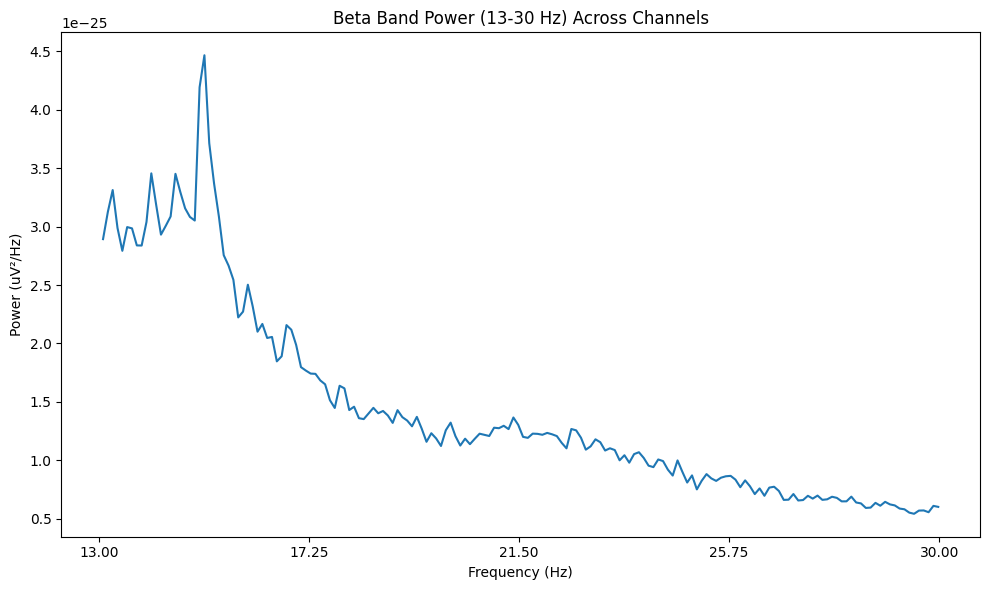

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d1 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d1.head())
print(d1.shape)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 108.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 83.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 12.4 MB/s eta 0:00:00
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d1_clean = d1.replace([np.inf, -np.inf], np.nan)
d1_clean = d1_clean.fillna(d1_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d1_scaled = pd.DataFrame(
    scaler.fit_transform(d1_clean),
    columns=d1_clean.columns,
    index=d1_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d1_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d1_scaled.index,
    columns=d1_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d1_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df1 = d1_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df1["Pd_indicator_meg"] = 0

print("\nShape of df5:", df1.shape)
print(df1.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Store only 58x7 features for ALL subjects
all_subjects_df1 = []

# Store 58x7 matrix safely
all_subjects_df1.append(df1.copy())

print("Stored df1 for this subject. Shape:", df1.shape)


Stored df1 for this subject. Shape: (58, 22)


In [ ]:
# ===== MEMORY CLEANUP BEFORE NEXT SUBJECT =====
import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

del raw
del ica
del psd_obj
del psds
del beta_band_psd


gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleared successfully (df1 preserved)")


RAM Used After Cleanup: 0.50 GB
Memory cleared successfully (df1 preserved)


sub-2

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-2'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-002_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-002_coordsystem.json', 'sub-002_task-go_run-1_proc-tsss+mc_events.json', 'sub-002_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-002_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-002_task-noise_proc-tsss_channels.tsv', 'sub-002_task-go_run-1_proc-tsss+mc_meg.json', 'sub-002_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-002_task-noise_proc-tsss_meg.json', 'sub-002_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-002_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-002_task-passive_run-1_proc-tsss+mc_events.json', 'sub-002_task-noise_proc-tsss_meg.fif', 'sub-002_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-002_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-002_task-rest_run-1_proc-tsss+mc_events.json', 'sub-002_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-002_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-002_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-002_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-002_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-002_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-002_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-002_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-2/meg/sub-002_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-2/meg/sub-002_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 196999 =      8.000 ...   196.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


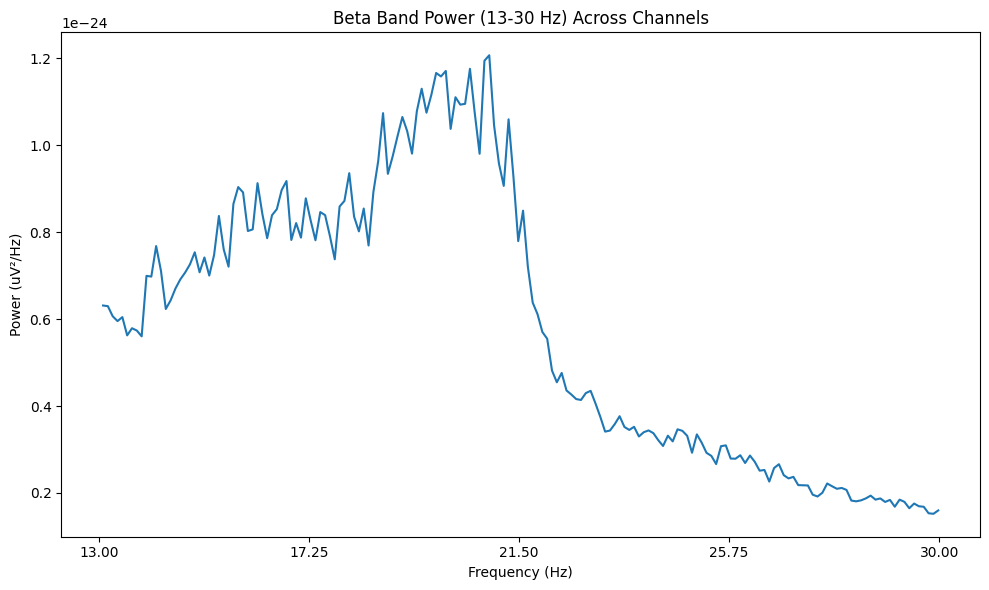

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d2 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d2.head())
print(d2.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d2_clean = d2.replace([np.inf, -np.inf], np.nan)
d2_clean = d2_clean.fillna(d2_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d2_scaled = pd.DataFrame(
    scaler.fit_transform(d2_clean),
    columns=d2_clean.columns,
    index=d2_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d2_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d2_scaled.index,
    columns=d2_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d2_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df2 = d2_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df2["Pd_indicator_meg"] = 0

print("\nShape of df5:", df2.shape)
print(df2.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

Concatenation

In [ ]:
# Combine df_4 and df_8 vertically
df12 = pd.concat([df1, df2], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12 = df12.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12):")
print(df12)

# Print the shape
print("Shape of df12:", df12.shape) #(116,7)


Combined top channels (df12):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
111    3.825397             0.065353          7.600119e-12  0.920856   
112    3.788360             0.065992          4.490631e-13  0.871004   
113    3.783069             0.066084          9.230448e-12  1.146145   
114    3.640212             0.068677          7.354694e-12  0.912590   
115    3.851852             0.064904          4.422337e-13  0.826934   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000       15.136719 

In [ ]:
df12.to_csv('/content/drive/MyDrive/combined_features_upto_sub002_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12 preserved.")


RAM Used After Cleanup: 0.53 GB
Memory cleaned. df12 preserved.


sub-3

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-3'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-003_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-003_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-003_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-003_coordsystem.json', 'sub-003_task-go_run-1_proc-tsss+mc_events.json', 'sub-003_task-go_run-1_proc-tsss+mc_meg.json', 'sub-003_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-003_task-noise_proc-tsss_channels.tsv', 'sub-003_task-noise_proc-tsss_meg.fif', 'sub-003_task-passive_run-1_proc-tsss+mc_events.json', 'sub-003_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-003_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-003_task-noise_proc-tsss_meg.json', 'sub-003_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-003_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-003_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-003_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-003_task-rest_run-1_proc-tsss+mc_events.json', 'sub-003_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-003_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-003_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-003_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-003_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-003_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-3/meg/sub-003_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-3/meg/sub-003_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 29000 ... 225999 =     29.000 ...   225.999 secs
Ready.
Reading 0 ... 196999  =      0.000 ...   196.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


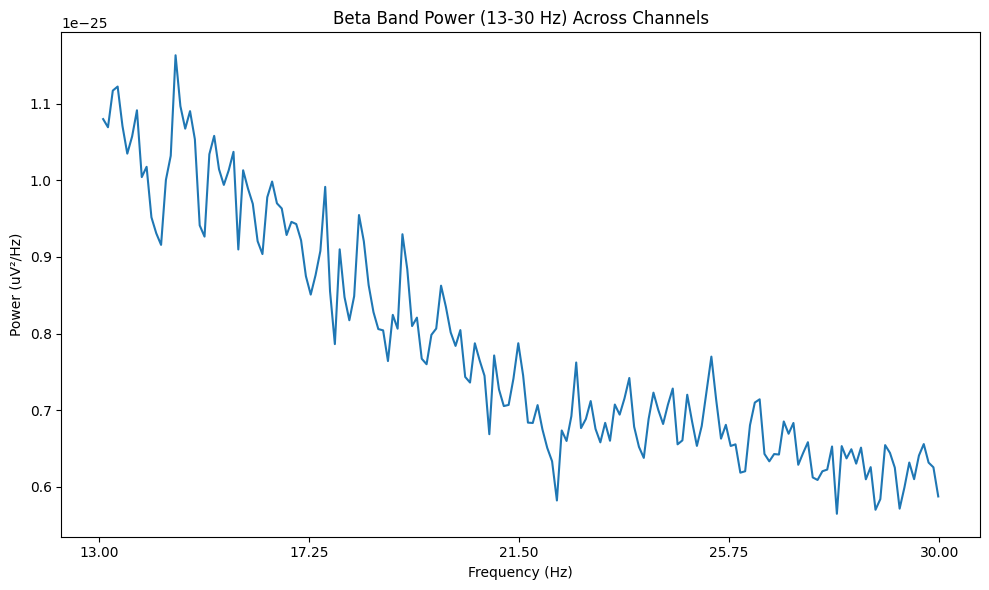

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d3 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d3.head())
print(d3.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d3_clean = d3.replace([np.inf, -np.inf], np.nan)
d3_clean = d3_clean.fillna(d3_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d3_scaled = pd.DataFrame(
    scaler.fit_transform(d3_clean),
    columns=d3_clean.columns,
    index=d3_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d3_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d3_scaled.index,
    columns=d3_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d3_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df3 = d3_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df3["Pd_indicator_meg"] = 0

print("\nShape of df5:", df3.shape)
print(df3.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

Concatenation

In [ ]:
# Combine df_4 and df_8 vertically
df123 = pd.concat([df12, df3], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123 = df123.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123):")
print(df123)

# Print the shape
print("Shape of df123:", df123.shape) #(116,7)


Combined top channels (df123):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
169    4.746193             0.052674          2.471301e-12  0.711111   
170    4.624365             0.054061          1.427179e-13  0.715849   
171    4.746193             0.052674          2.844988e-12  0.724153   
172    4.736041             0.052787          2.485778e-12  0.709727   
173    4.614213             0.054180          1.514594e-13  0.772072   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000       15.136719

In [ ]:
df123.to_csv('/content/drive/MyDrive/combined_features_upto_sub003_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123 preserved.")


RAM Used After Cleanup: 0.55 GB
Memory cleaned. df123 preserved.


sub-4

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-4'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-004_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-004_task-go_run-1_proc-tsss+mc_events.json', 'sub-004_coordsystem.json', 'sub-004_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-004_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-004_task-noise_proc-tsss_channels.tsv', 'sub-004_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-004_task-go_run-1_proc-tsss+mc_meg.json', 'sub-004_task-noise_proc-tsss_meg.json', 'sub-004_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-004_task-noise_proc-tsss_meg.fif', 'sub-004_task-passive_run-1_proc-tsss+mc_events.json', 'sub-004_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-004_task-rest_run-1_proc-tsss+mc_events.json', 'sub-004_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-004_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-004_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-004_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-004_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-004_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-004_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-004_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-004_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-004_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-4/meg/sub-004_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocesing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-4/meg/sub-004_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 58000 ... 243999 =     58.000 ...   243.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


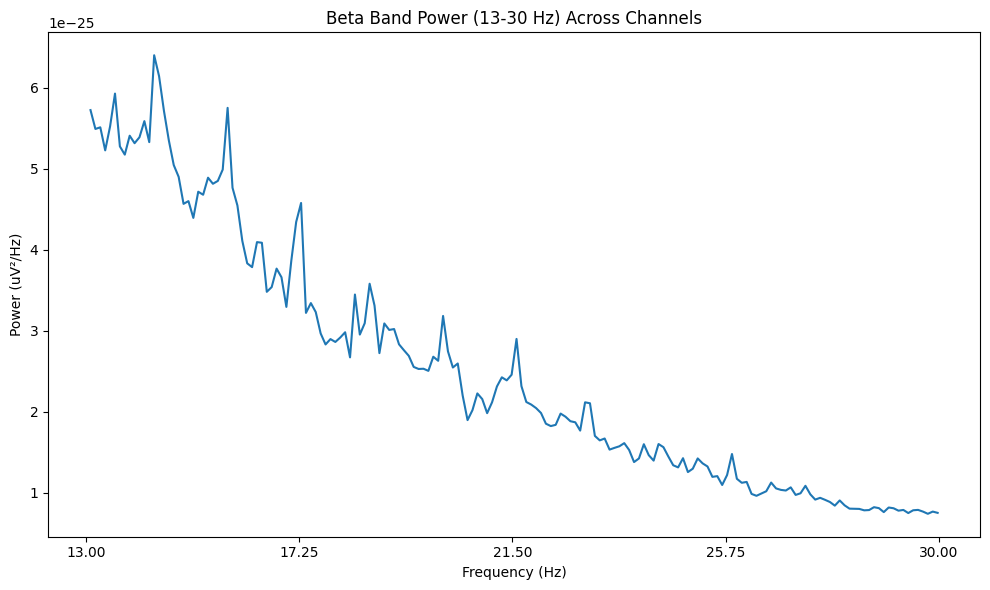

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d4 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d4.head())
print(d4.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d4_clean = d4.replace([np.inf, -np.inf], np.nan)
d4_clean = d4_clean.fillna(d4_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d4_scaled = pd.DataFrame(
    scaler.fit_transform(d4_clean),
    columns=d4_clean.columns,
    index=d4_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d4_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d4_scaled.index,
    columns=d4_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d4_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df4 = d4_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df4["Pd_indicator_meg"] = 1

print("\nShape of df5:", df4.shape)
print(df4.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234 = pd.concat([df123, df4], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234 = df1234.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234):")
print(df1234)

# Print the shape
print("Shape of df1234:", df1234.shape) #(116,7)


Combined top channels (df1234):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
227    4.134409             0.060468          3.722962e-12  0.748117   
228    3.833333             0.065217          2.633057e-13  0.742559   
229    4.284946             0.058344          4.243144e-12  0.807726   
230    4.166667             0.060000          3.824395e-12  0.770973   
231    3.865591             0.064673          2.804060e-13  0.760198   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000       15.13671

In [ ]:
df1234.to_csv('/content/drive/MyDrive/combined_features_upto_sub004_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234 preserved.")


RAM Used After Cleanup: 0.52 GB
Memory cleaned. df1234 preserved.


sub-5

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-5'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-005_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-005_coordsystem.json', 'sub-005_task-go_run-1_proc-tsss+mc_events.json', 'sub-005_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-005_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-005_task-go_run-1_proc-tsss+mc_meg.json', 'sub-005_task-noise_proc-tsss_channels.tsv', 'sub-005_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-005_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-005_task-noise_proc-tsss_meg.fif', 'sub-005_task-noise_proc-tsss_meg.json', 'sub-005_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-005_task-passive_run-1_proc-tsss+mc_events.json', 'sub-005_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-005_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-005_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-005_task-rest_run-1_proc-tsss+mc_events.json', 'sub-005_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-005_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-005_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-005_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-005_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-005_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-005_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-5/meg/sub-005_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-5/meg/sub-005_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 43000 ... 235999 =     43.000 ...   235.999 secs
Ready.
Reading 0 ... 192999  =      0.000 ...   192.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


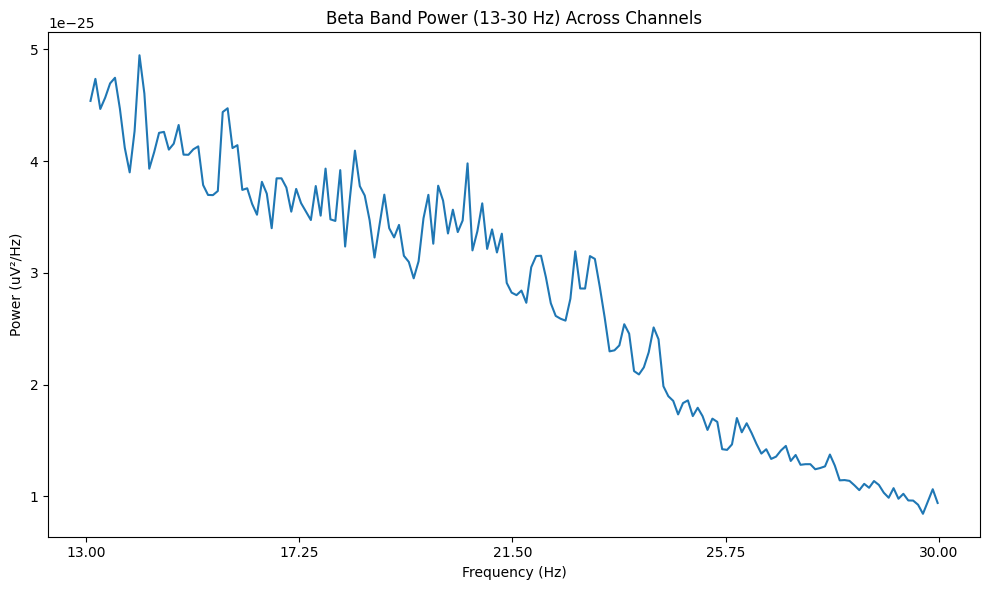

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d5 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d5.head())
print(d5.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d5_clean = d5.replace([np.inf, -np.inf], np.nan)
d5_clean = d5_clean.fillna(d5_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d5_scaled = pd.DataFrame(
    scaler.fit_transform(d5_clean),
    columns=d5_clean.columns,
    index=d5_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d5_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d5_scaled.index,
    columns=d5_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d5_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df5 = d5_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df5["Pd_indicator_meg"] = 1

print("\nShape of df5:", df5.shape)
print(df5.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345 = pd.concat([df1234, df5], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345 = df12345.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345):")
print(df12345)

# Print the shape
print("Shape of df12345:", df12345.shape) #(116,7)


Combined top channels (df12345):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
285    3.943005             0.063403          3.699702e-12  0.916789   
286    3.611399             0.069225          2.618673e-13  1.003467   
287    3.922280             0.063738          3.744635e-12  0.850786   
288    3.590674             0.069625          4.398897e-12  1.221578   
289    3.611399             0.069225          2.764802e-13  1.097544   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000       15.1367

In [ ]:
df12345.to_csv('/content/drive/MyDrive/combined_features_upto_sub005_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345 preserved.")


RAM Used After Cleanup: 0.53 GB
Memory cleaned. df12345 preserved.


sub-6

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-6'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-006_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-006_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-006_task-go_run-1_proc-tsss+mc_events.json', 'sub-006_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-006_coordsystem.json', 'sub-006_task-go_run-1_proc-tsss+mc_meg.json', 'sub-006_task-noise_proc-tsss_channels.tsv', 'sub-006_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-006_task-passive_run-1_proc-tsss+mc_events.json', 'sub-006_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-006_task-noise_proc-tsss_meg.fif', 'sub-006_task-noise_proc-tsss_meg.json', 'sub-006_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-006_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-006_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-006_task-rest_run-1_proc-tsss+mc_events.json', 'sub-006_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-006_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-006_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-006_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-006_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-006_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-006_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-006_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-6/meg/sub-006_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-6/meg/sub-006_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 194999 =      7.000 ...   194.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


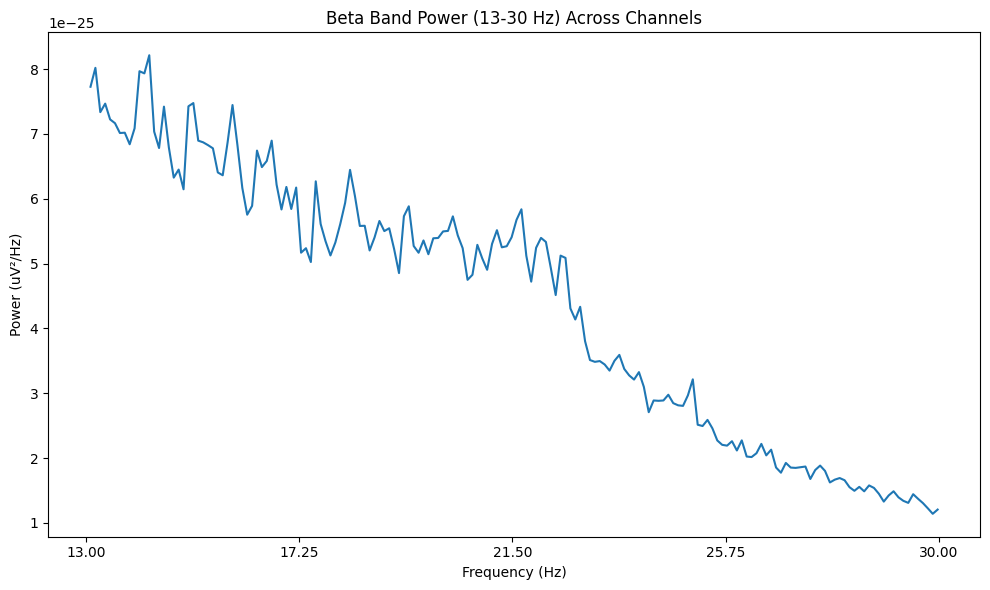

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d6 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d6.head())
print(d6.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d6_clean = d6.replace([np.inf, -np.inf], np.nan)
d6_clean = d6_clean.fillna(d6_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d6_scaled = pd.DataFrame(
    scaler.fit_transform(d6_clean),
    columns=d6_clean.columns,
    index=d6_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d6_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d6_scaled.index,
    columns=d6_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d6_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df6 = d6_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df6["Pd_indicator_meg"] = 0

print("\nShape of df5:", df6.shape)
print(df6.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456 = pd.concat([df12345, df6], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456 = df123456.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456):")
print(df123456)

# Print the shape
print("Shape of df123456:", df123456.shape) #(116,7)


Combined top channels (df123456):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
343    3.361702             0.074367          8.357022e-12  1.302129   
344    3.356383             0.074485          5.002794e-13  1.184636   
345    3.367021             0.074250          9.034432e-12  1.263278   
346    3.132979             0.079796          1.012026e-11  1.306955   
347    3.340426             0.074841          4.909303e-13  1.117717   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000       15.136

In [ ]:
df123456.to_csv('/content/drive/MyDrive/combined_features_upto_sub006_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456 preserved.")


RAM Used After Cleanup: 0.52 GB
Memory cleaned. df123456 preserved.


sub-7

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-7'  # Replace with your folder path

In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-007_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-007_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-007_coordsystem.json', 'sub-007_task-go_run-1_proc-tsss+mc_events.json', 'sub-007_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-007_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-007_task-noise_proc-tsss_channels.tsv', 'sub-007_task-go_run-1_proc-tsss+mc_meg.json', 'sub-007_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-007_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-007_task-passive_run-1_proc-tsss+mc_events.json', 'sub-007_task-noise_proc-tsss_meg.json', 'sub-007_task-noise_proc-tsss_meg.fif', 'sub-007_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-007_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-007_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-007_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-007_task-rest_run-1_proc-tsss+mc_events.json', 'sub-007_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-007_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-007_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-007_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-007_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-007_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-7/meg/sub-007_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import os
import mne
import numpy as np
from mne.preprocessing import ICA
import gc

task_name = "rest"

if task_name in fif_files_by_task:

    print(f"\n========== Processing Task: {task_name.lower()} ==========")

    for fif_file in fif_files_by_task[task_name]:

        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"Loading file: {fif_file_path}")

        # Load raw
        raw = mne.io.read_raw_fif(
            fif_file_path,
            preload=True,
            verbose=False
        )

        # Pick only MEG
        raw.pick("meg")   # modern version (no warning)

        # Downsample
        raw.resample(200, npad="auto")

        # Filter
        raw.filter(
            l_freq=1.0,
            h_freq=40.0,
            fir_design="firwin",
            n_jobs=1
        )

        # Fix NaN/Inf
        raw._data[~np.isfinite(raw._data)] = 0.0

        print("NaN count:", np.isnan(raw._data).sum())
        print("Inf count:", np.isinf(raw._data).sum())

        # ICA
        ica = ICA(
            n_components=20,
            method="fastica",
            random_state=42,
            max_iter=300
        )

        ica.fit(raw, reject_by_annotation=True, verbose=False)

        print("ICA completed for REST task")


        del ica
        gc.collect()

else:
    print("Rest task not found in dictionary.")



========== Processing Task: rest ==========
Loading file: /content/drive/MyDrive/sub-7/meg/sub-007_task-rest_run-1_proc-tsss+mc_meg.fif


/usr/local/lib/python3.12/dist-packages/mne/_fiff/utils.py:76: RuntimeWarning: invalid value encountered in cast
  one = np.asarray(one, dtype=data_view.dtype)


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

NaN count: 0
Inf count: 0
ICA completed for REST task


Computing Power Spectral Density

Effective window size : 10.240 (s)


/tmp/ipykernel_3125/2166243642.py:5: UserWarning: Zero value in spectrum for channels MEG0112, MEG0121, MEG0122, MEG0123, MEG0131, MEG0132, MEG0133, MEG0142, MEG0143, MEG0212, MEG0213, MEG0221, MEG0222, MEG0223, MEG0233, MEG0312, MEG0313, MEG0321, MEG0323, MEG0331, MEG0332, MEG0333, MEG0342, MEG0343, MEG0411, MEG0412, MEG0421, MEG0422, MEG0423, MEG0431, MEG0432, MEG0433, MEG0441, MEG0442, MEG0443, MEG0511, MEG0512, MEG0513, MEG0521, MEG0523, MEG0531, MEG0532, MEG0533, MEG0541, MEG0542, MEG0543, MEG0611, MEG0612, MEG0613, MEG0621, MEG0623, MEG0631, MEG0632, MEG0633, MEG0641, MEG0642, MEG0643, MEG0711, MEG0713, MEG0721, MEG0722, MEG0731, MEG0732, MEG0733, MEG0741, MEG0742, MEG0743, MEG0822, MEG0911, MEG0912, MEG0921, MEG0922, MEG0923, MEG0933, MEG0941, MEG0942, MEG0943, MEG1011, MEG1012, MEG1013, MEG1021, MEG1022, MEG1023, MEG1031, MEG1032, MEG1041, MEG1043, MEG1111, MEG1113, MEG1121, MEG1123, MEG1131, MEG1132, MEG1133, MEG1143, MEG1211, MEG1212, MEG1213, MEG1221, MEG1223, MEG1231, MEG12

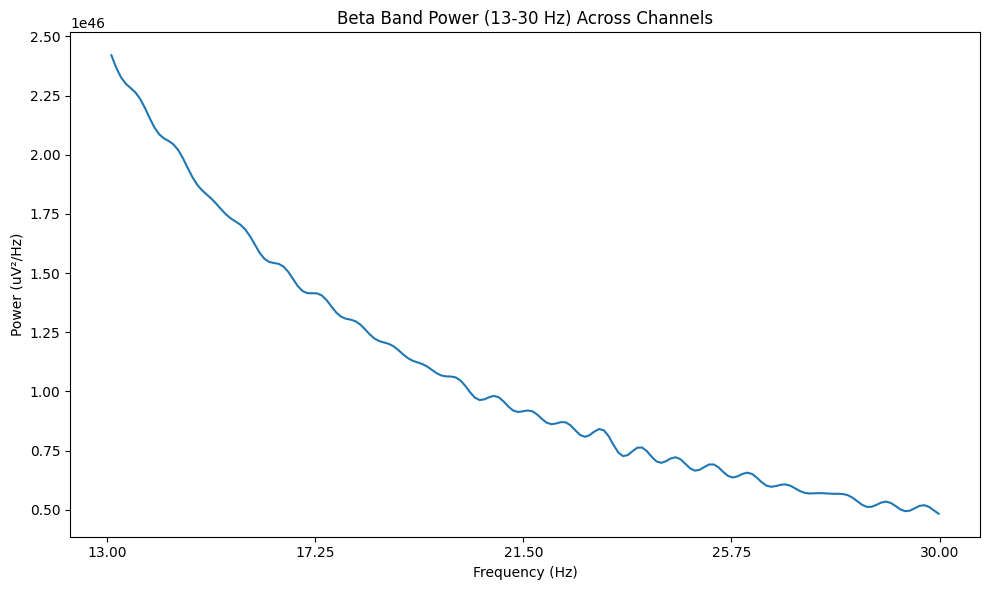

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d7 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d7.head())
print(d7.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

/tmp/ipykernel_3125/4125905238.py:129: RuntimeWarning: invalid value encountered in divide
  beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
/tmp/ipykernel_3125/4125905238.py:137: RuntimeWarning: invalid value encountered in scalar divide
  spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d7_clean = d7.replace([np.inf, -np.inf], np.nan)
d7_clean = d7_clean.fillna(d7_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d7_scaled = pd.DataFrame(
    scaler.fit_transform(d7_clean),
    columns=d7_clean.columns,
    index=d7_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d7_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d7_scaled.index,
    columns=d7_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d7_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df7 = d7_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df7["Pd_indicator_meg"] = 0

print("\nShape of df5:", df7.shape)
print(df7.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567 = pd.concat([df123456, df7], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567 = df1234567.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567):")
print(df1234567)

# Print the shape
print("Shape of df1234567:", df1234567.shape) #(116,7)


Combined top channels (df1234567):
     burst_rate  mean_burst_duration  mean_burst_amplitude     ibi_cv  \
0      4.164894             0.060026          3.769601e-12   0.781471   
1      4.063830             0.061518          2.130644e-13   0.733652   
2      4.324468             0.057811          3.549580e-12   0.779541   
3      4.382979             0.056990          4.324233e-12   0.727869   
4      4.361702             0.057317          1.885143e-13   0.732904   
..          ...                  ...                   ...        ...   
401    3.559140             0.005000          1.735792e+24  17.299912   
402    0.000000             0.000000          0.000000e+00   0.000000   
403    0.000000             0.000000          0.000000e+00   0.000000   
404    0.000000             0.000000          0.000000e+00   0.000000   
405    0.000000             0.000000          0.000000e+00   0.000000   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000

In [ ]:
df1234567.to_csv('/content/drive/MyDrive/combined_features_upto_sub007_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects (safe version, same style)

try:
    del raw
except NameError:
    pass

try:
    del ica
except NameError:
    pass

try:
    del psd_obj
except NameError:
    pass

try:
    del psds
except NameError:
    pass

try:
    del beta_band_psd
except NameError:
    pass

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567 preserved.")


RAM Used After Cleanup: 0.54 GB
Memory cleaned. df1234567 preserved.


sub-8

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-8'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-008_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-008_task-go_run-1_proc-tsss+mc_events.json', 'sub-008_coordsystem.json', 'sub-008_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-008_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-008_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-008_task-go_run-1_proc-tsss+mc_meg.json', 'sub-008_task-noise_proc-tsss_channels.tsv', 'sub-008_task-noise_proc-tsss_meg.fif', 'sub-008_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-008_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-008_task-passive_run-1_proc-tsss+mc_events.json', 'sub-008_task-noise_proc-tsss_meg.json', 'sub-008_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-008_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-008_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-008_task-rest_run-1_proc-tsss+mc_events.json', 'sub-008_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-008_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-008_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-008_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-008_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-008_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-008_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-8/meg/sub-008_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-8/meg/sub-008_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 147000 ... 341999 =    147.000 ...   341.999 secs
Ready.
Reading 0 ... 194999  =      0.000 ...   194.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


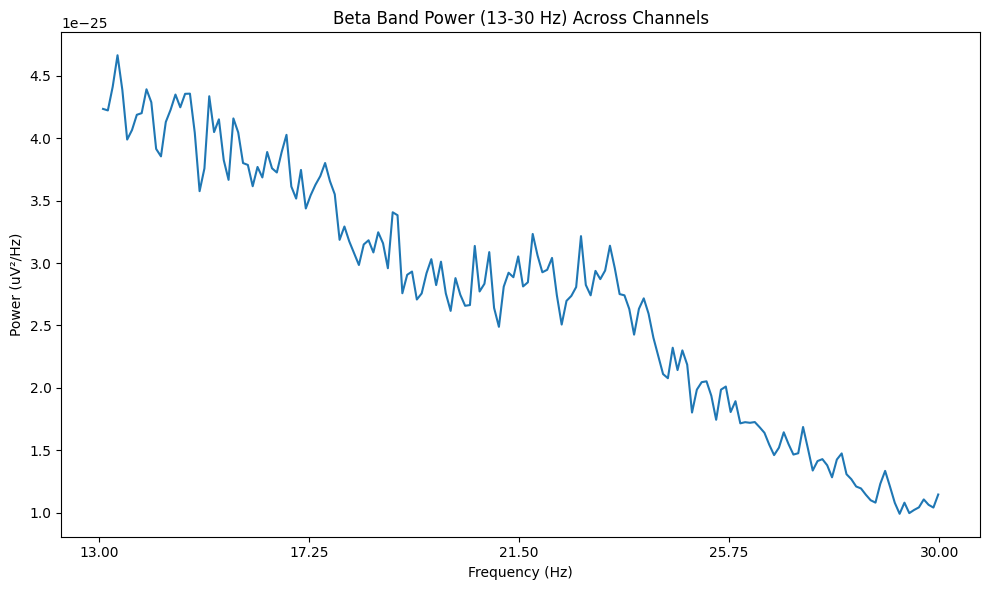

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d8 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d8.head())
print(d8.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channles

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d8_clean = d8.replace([np.inf, -np.inf], np.nan)
d8_clean = d8_clean.fillna(d8_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d8_scaled = pd.DataFrame(
    scaler.fit_transform(d8_clean),
    columns=d8_clean.columns,
    index=d8_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d8_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d8_scaled.index,
    columns=d8_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d8_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df8 = d8_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df8["Pd_indicator_meg"] = 1

print("\nShape of df5:", df8.shape)
print(df8.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678 = pd.concat([df1234567, df8], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678 = df12345678.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678):")
print(df12345678)

# Print the shape
print("Shape of df12345678:", df12345678.shape) #(116,7)


Combined top channels (df12345678):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
459    3.917949             0.063809          5.780203e-12  0.782981   
460    3.779487             0.066147          3.482671e-13  1.010619   
461    4.015385             0.062261          6.204046e-12  0.778911   
462    3.928205             0.063642          6.366823e-12  0.888805   
463    3.702564             0.067521          3.675058e-13  0.927802   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000       15.1

In [ ]:
df12345678.to_csv('/content/drive/MyDrive/combined_features_upto_sub008_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678 preserved.")


RAM Used After Cleanup: 0.53 GB
Memory cleaned. df12345678 preserved.


sub-10

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-10'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-010_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-010_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-010_coordsystem.json', 'sub-010_task-go_run-1_proc-tsss+mc_events.json', 'sub-010_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-010_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-010_task-noise_proc-tsss_channels.tsv', 'sub-010_task-go_run-1_proc-tsss+mc_meg.json', 'sub-010_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-010_task-noise_proc-tsss_meg.fif', 'sub-010_task-passive_run-1_proc-tsss+mc_events.json', 'sub-010_task-noise_proc-tsss_meg.json', 'sub-010_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-010_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-010_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-010_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-010_task-rest_run-1_proc-tsss+mc_events.json', 'sub-010_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-010_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-010_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-010_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-010_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-010_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-010_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-10/meg/sub-010_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-10/meg/sub-010_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 23000 ... 211999 =     23.000 ...   211.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


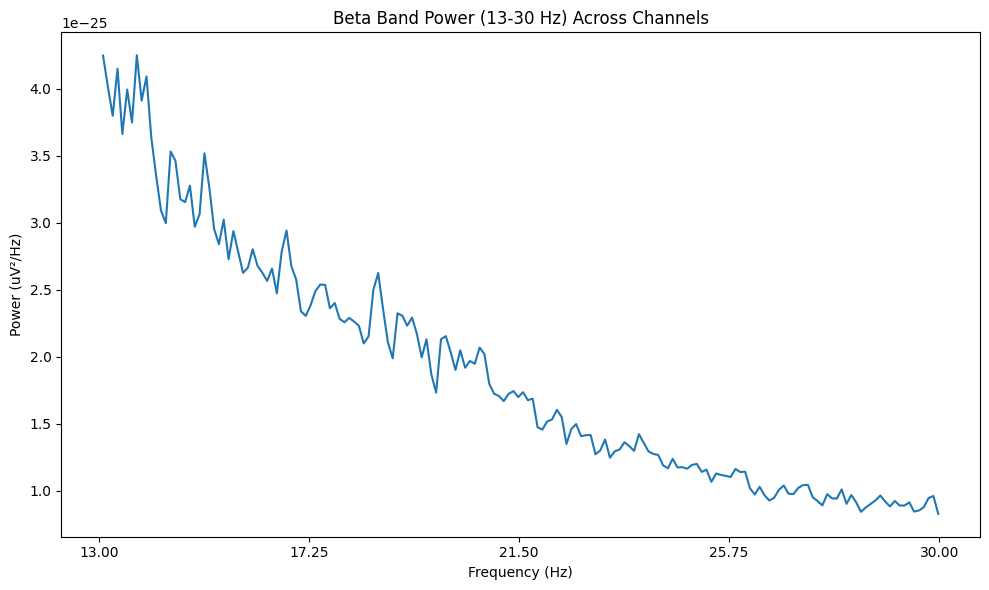

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d10 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d10.head())
print(d10.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d10_clean = d10.replace([np.inf, -np.inf], np.nan)
d10_clean = d10_clean.fillna(d10_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d10_scaled = pd.DataFrame(
    scaler.fit_transform(d10_clean),
    columns=d10_clean.columns,
    index=d10_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d10_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d10_scaled.index,
    columns=d10_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d10_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df10 = d10_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df10["Pd_indicator_meg"] = 1

print("\nShape of df5:", df10.shape)
print(df10.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810 = pd.concat([df12345678, df10], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810 = df1234567810.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810):")
print(df1234567810)

# Print the shape
print("Shape of df1234567810:", df1234567810.shape) #(116,7)


Combined top channels (df1234567810):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
517    3.698413             0.067597          5.953714e-12  0.968160   
518    4.031746             0.062008          2.615631e-13  0.912181   
519    4.005291             0.062417          6.026919e-12  0.862358   
520    4.190476             0.059659          5.243003e-12  0.857788   
521    3.968254             0.063000          2.623367e-13  0.891471   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000       15

In [ ]:
df1234567810.to_csv('/content/drive/MyDrive/combined_features_upto_sub0010_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810 preserved.")


RAM Used After Cleanup: 0.53 GB
Memory cleaned. df1234567810 preserved.


sub-11

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-11'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-011_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-011_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-011_task-go_run-1_proc-tsss+mc_events.json', 'sub-011_coordsystem.json', 'sub-011_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-011_task-go_run-1_proc-tsss+mc_meg.json', 'sub-011_task-noise_proc-tsss_channels.tsv', 'sub-011_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-011_task-noise_proc-tsss_meg.json', 'sub-011_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-011_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-011_task-passive_run-1_proc-tsss+mc_events.json', 'sub-011_task-noise_proc-tsss_meg.fif', 'sub-011_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-011_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-011_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-011_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-011_task-rest_run-1_proc-tsss+mc_events.json', 'sub-011_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-011_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-011_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-011_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-011_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-011_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-11/meg/sub-011_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-11/meg/sub-011_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 25000 ... 212999 =     25.000 ...   212.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


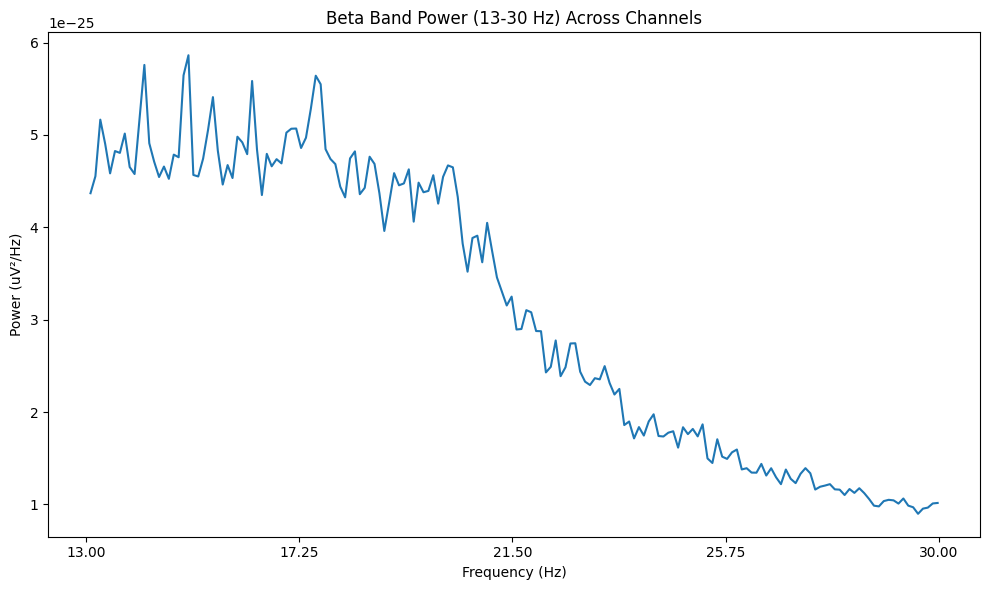

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d11 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d11.head())
print(d11.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d11_clean = d11.replace([np.inf, -np.inf], np.nan)
d11_clean = d11_clean.fillna(d11_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d11_scaled = pd.DataFrame(
    scaler.fit_transform(d11_clean),
    columns=d11_clean.columns,
    index=d11_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d11_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d11_scaled.index,
    columns=d11_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d11_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df11 = d11_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df11["Pd_indicator_meg"] = 0

print("\nShape of df5:", df11.shape)
print(df11.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011 = pd.concat([df1234567810, df11], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011 = df123456781011.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011):")
print(df123456781011)

# Print the shape
print("Shape of df123456781011:", df123456781011.shape) #(116,7)


Combined top channels (df123456781011):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
575    3.345745             0.074722          6.031723e-12  0.884117   
576    3.074468             0.081315          4.138279e-13  1.075649   
577    3.446809             0.072531          6.327873e-12  0.817735   
578    3.579787             0.069837          6.050872e-12  0.984238   
579    3.186170             0.078464          3.907790e-13  0.924301   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000       

In [ ]:
df123456781011.to_csv('/content/drive/MyDrive/combined_features_upto_sub0011_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df123456781011 preserved.


sub-12

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-12'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-012_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-012_task-go_run-1_proc-tsss+mc_events.json', 'sub-012_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-012_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-012_coordsystem.json', 'sub-012_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-012_task-go_run-1_proc-tsss+mc_meg.json', 'sub-012_task-noise_proc-tsss_channels.tsv', 'sub-012_task-noise_proc-tsss_meg.json', 'sub-012_task-noise_proc-tsss_meg.fif', 'sub-012_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-012_task-passive_run-1_proc-tsss+mc_events.json', 'sub-012_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-012_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-012_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-012_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-012_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-012_task-rest_run-1_proc-tsss+mc_events.json', 'sub-012_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-012_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-012_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-012_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-012_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-012_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-12/meg/sub-012_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-12/meg/sub-012_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 9000 ... 201999 =      9.000 ...   201.999 secs
Ready.
Reading 0 ... 192999  =      0.000 ...   192.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


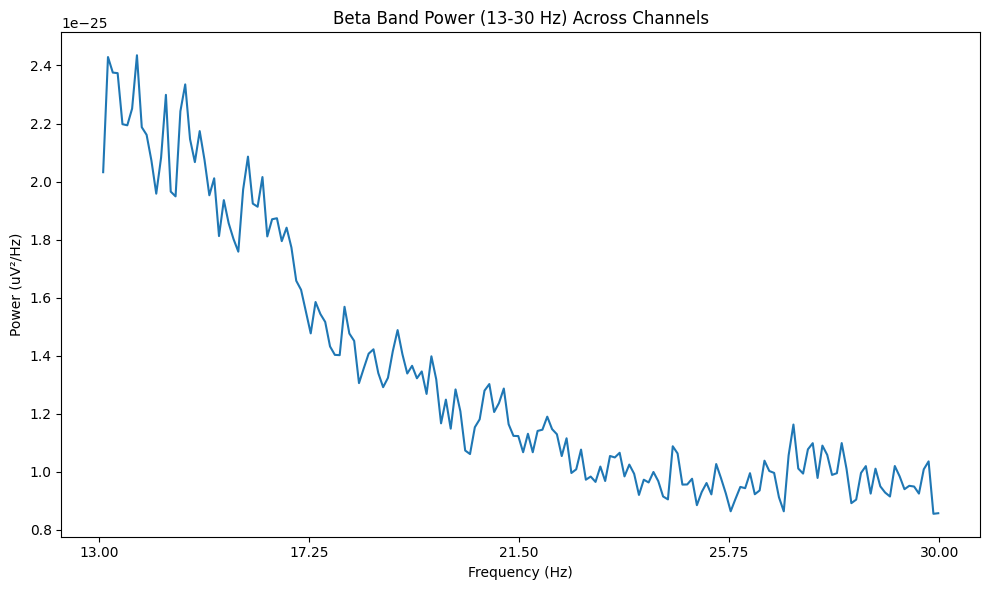

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d12 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d12.head())
print(d12.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d12_clean = d12.replace([np.inf, -np.inf], np.nan)
d12_clean = d12_clean.fillna(d12_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d12_scaled = pd.DataFrame(
    scaler.fit_transform(d12_clean),
    columns=d12_clean.columns,
    index=d12_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d12_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d12_scaled.index,
    columns=d12_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d12_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df12 = d12_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df12["Pd_indicator_meg"] = 1

print("\nShape of df5:", df12.shape)
print(df12.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112 = pd.concat([df123456781011, df12], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112 = df12345678101112.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112):")
print(df12345678101112)

# Print the shape
print("Shape of df12345678101112:", df12345678101112.shape) #(116,7)


Combined top channels (df12345678101112):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
633    4.730570             0.052848          3.007837e-12  0.753236   
634    4.647668             0.053790          1.719021e-13  0.737158   
635    4.580311             0.054531          3.057414e-12  0.762227   
636    4.642487             0.053850          3.271022e-12  0.796460   
637    4.606218             0.054274          1.705055e-13  0.724928   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000     

In [ ]:
df12345678101112.to_csv('/content/drive/MyDrive/combined_features_upto_sub0012_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112 preserved.")


RAM Used After Cleanup: 0.54 GB
Memory cleaned. df12345678101112 preserved.


sub-13

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-13'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-013_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-013_task-go_run-1_proc-tsss+mc_events.json', 'sub-013_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-013_coordsystem.json', 'sub-013_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-013_task-noise_proc-tsss_channels.tsv', 'sub-013_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-013_task-go_run-1_proc-tsss+mc_meg.json', 'sub-013_task-noise_proc-tsss_meg.json', 'sub-013_task-passive_run-1_proc-tsss+mc_events.json', 'sub-013_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-013_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-013_task-noise_proc-tsss_meg.fif', 'sub-013_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-013_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-013_task-rest_run-1_proc-tsss+mc_events.json', 'sub-013_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-013_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-013_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-013_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-013_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-013_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-013_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-013_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-13/meg/sub-013_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-13/meg/sub-013_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 50000 ... 286999 =     50.000 ...   286.999 secs
Ready.
Reading 0 ... 236999  =      0.000 ...   236.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


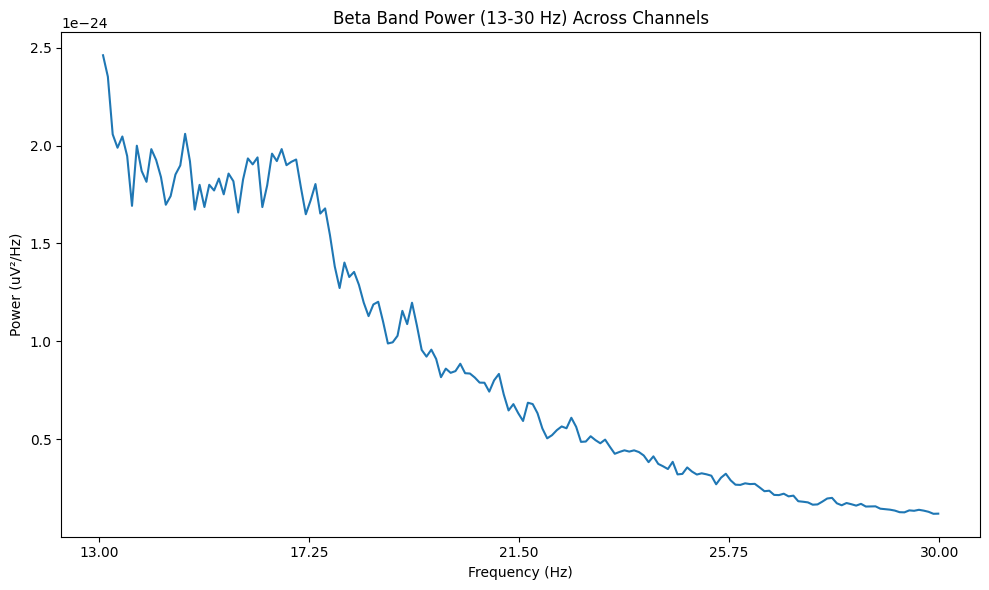

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d13 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d13.head())
print(d13.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d13_clean = d13.replace([np.inf, -np.inf], np.nan)
d13_clean = d13_clean.fillna(d13_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d13_scaled = pd.DataFrame(
    scaler.fit_transform(d13_clean),
    columns=d13_clean.columns,
    index=d13_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d13_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d13_scaled.index,
    columns=d13_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d13_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df13 = d13_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df13["Pd_indicator_meg"] = 1

print("\nShape of df5:", df13.shape)
print(df13.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213 = pd.concat([df12345678101112, df13], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213 = df1234567810111213.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213):")
print(df1234567810111213)

# Print the shape
print("Shape of df1234567810111213:", df1234567810111213.shape) #(116,7)


Combined top channels (df1234567810111213):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
691    3.708861             0.067406          8.191978e-12  0.821870   
692    3.721519             0.067177          5.271461e-13  0.785312   
693    3.767932             0.066349          9.725508e-12  0.786765   
694    3.708861             0.067406          9.551041e-12  0.772543   
695    3.687764             0.067792          5.321785e-13  0.760515   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000   

In [ ]:
df1234567810111213.to_csv('/content/drive/MyDrive/combined_features_upto_sub0013_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df1234567810111213 preserved.


sub-14

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-14'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-014_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-014_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-014_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-014_task-go_run-1_proc-tsss+mc_events.json', 'sub-014_coordsystem.json', 'sub-014_task-go_run-1_proc-tsss+mc_meg.json', 'sub-014_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-014_task-noise_proc-tsss_channels.tsv', 'sub-014_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-014_task-noise_proc-tsss_meg.fif', 'sub-014_task-passive_run-1_proc-tsss+mc_events.json', 'sub-014_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-014_task-noise_proc-tsss_meg.json', 'sub-014_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-014_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-014_task-rest_run-1_proc-tsss+mc_events.json', 'sub-014_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-014_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-014_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-014_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-014_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-014_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-014_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-014_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-14/meg/sub-014_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-14/meg/sub-014_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 14000 ... 214999 =     14.000 ...   214.999 secs
Ready.
Reading 0 ... 200999  =      0.000 ...   200.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


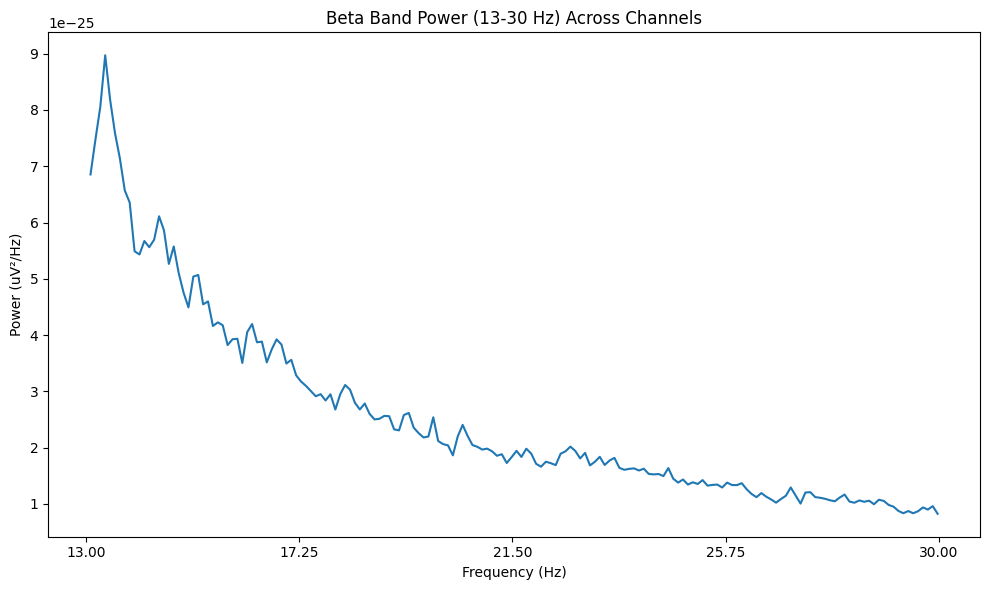

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d14 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d14.head())
print(d14.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extracion of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d14_clean = d14.replace([np.inf, -np.inf], np.nan)
d14_clean = d14_clean.fillna(d14_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d14_scaled = pd.DataFrame(
    scaler.fit_transform(d14_clean),
    columns=d14_clean.columns,
    index=d14_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d14_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d14_scaled.index,
    columns=d14_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d14_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df14 = d14_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df14["Pd_indicator_meg"] = 0

print("\nShape of df5:", df14.shape)
print(df14.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314 = pd.concat([df1234567810111213, df14], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314 = df123456781011121314.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314):")
print(df123456781011121314)

# Print the shape
print("Shape of df123456781011121314:", df123456781011121314.shape) #(116,7)


Combined top channels (df123456781011121314):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
749    4.199005             0.059538          4.822667e-12  0.883646   
750    3.582090             0.069792          3.118788e-13  1.184216   
751    4.179104             0.059821          5.670875e-12  0.847976   
752    4.253731             0.058772          5.609082e-12  0.837934   
753    3.751244             0.066645          3.159384e-13  1.074997   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250000 

In [ ]:
df123456781011121314.to_csv('/content/drive/MyDrive/combined_features_upto_sub0014_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314 preserved.


sub-15

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-15'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-015_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-015_task-go_run-1_proc-tsss+mc_events.json', 'sub-015_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-015_coordsystem.json', 'sub-015_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-015_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-015_task-noise_proc-tsss_channels.tsv', 'sub-015_task-go_run-1_proc-tsss+mc_meg.json', 'sub-015_task-noise_proc-tsss_meg.fif', 'sub-015_task-noise_proc-tsss_meg.json', 'sub-015_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-015_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-015_task-passive_run-1_proc-tsss+mc_events.json', 'sub-015_task-rest_run-1_proc-tsss+mc_events.json', 'sub-015_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-015_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-015_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-015_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-015_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-015_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-015_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-015_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-015_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-015_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-15/meg/sub-015_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-15/meg/sub-015_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 324999 =      7.000 ...   324.999 secs
Ready.
Reading 0 ... 317999  =      0.000 ...   317.999 secs...
Finding events on: STI101
1 event found on stim channel STI101
Event IDs: [1]
Finding events on: STI101
1 event found on stim channel STI101
Event IDs: [1]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitting ICA 

Computing Power Spectral Density

Effective window size : 10.240 (s)


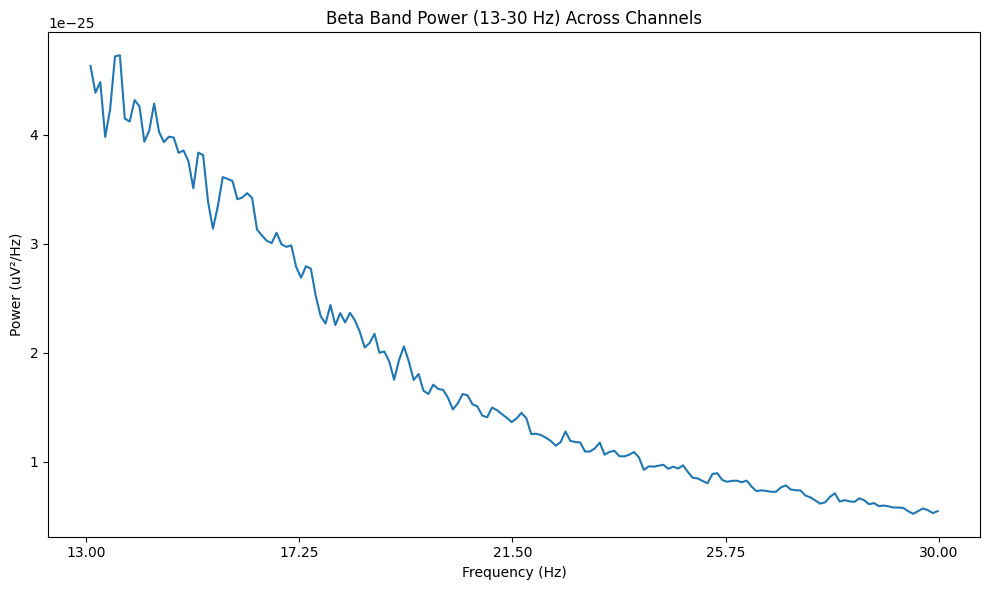

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d15 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d15.head())
print(d15.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d15_clean = d15.replace([np.inf, -np.inf], np.nan)
d15_clean = d15_clean.fillna(d15_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d15_scaled = pd.DataFrame(
    scaler.fit_transform(d15_clean),
    columns=d15_clean.columns,
    index=d15_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d15_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d15_scaled.index,
    columns=d15_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d15_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df15 = d15_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df15["Pd_indicator_meg"] = 1

print("\nShape of df5:", df15.shape)
print(df15.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415 = pd.concat([df123456781011121314, df15], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415 = df12345678101112131415.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415):")
print(df12345678101112131415)

# Print the shape
print("Shape of df12345678101112131415:", df12345678101112131415.shape) #(116,7)


Combined top channels (df12345678101112131415):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
807    4.339623             0.057609          3.025997e-12  0.784785   
808    4.229560             0.059108          2.025085e-13  0.772963   
809    4.333333             0.057692          3.369057e-12  0.756723   
810    4.125786             0.060595          3.472762e-12  0.817225   
811    4.204403             0.059461          2.034637e-13  0.787020   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.25000

In [ ]:
df12345678101112131415.to_csv('/content/drive/MyDrive/combined_features_upto_sub0015_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df12345678101112131415 preserved.


sub-16

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-16'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-016_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-016_task-go_run-1_proc-tsss+mc_events.json', 'sub-016_coordsystem.json', 'sub-016_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-016_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-016_task-noise_proc-tsss_channels.tsv', 'sub-016_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-016_task-go_run-1_proc-tsss+mc_meg.json', 'sub-016_task-noise_proc-tsss_meg.fif', 'sub-016_task-noise_proc-tsss_meg.json', 'sub-016_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-016_task-passive_run-1_proc-tsss+mc_events.json', 'sub-016_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-016_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-016_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-016_task-rest_run-1_proc-tsss+mc_events.json', 'sub-016_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-016_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-016_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-016_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-016_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-016_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-016_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-016_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-16/meg/sub-016_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-16/meg/sub-016_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 36000 ... 230999 =     36.000 ...   230.999 secs
Ready.
Reading 0 ... 194999  =      0.000 ...   194.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spetral Density

Effective window size : 10.240 (s)


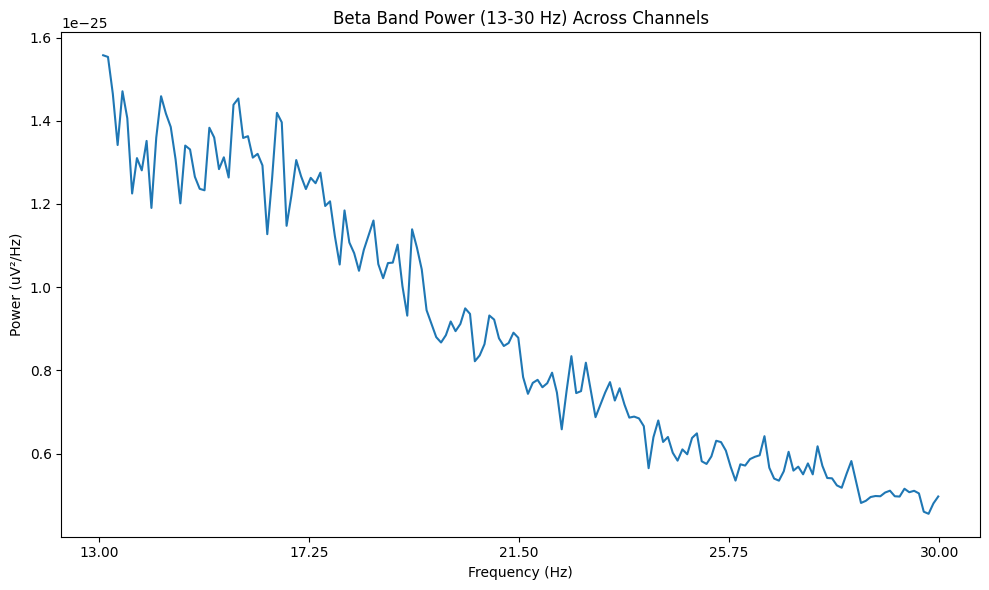

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d16 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d16.head())
print(d16.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d16_clean = d16.replace([np.inf, -np.inf], np.nan)
d16_clean = d16_clean.fillna(d16_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d16_scaled = pd.DataFrame(
    scaler.fit_transform(d16_clean),
    columns=d16_clean.columns,
    index=d16_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d16_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d16_scaled.index,
    columns=d16_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d16_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df16 = d16_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df16["Pd_indicator_meg"] = 0

print("\nShape of df5:", df16.shape)
print(df16.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516 = pd.concat([df12345678101112131415, df16], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516 = df1234567810111213141516.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516):")
print(df1234567810111213141516)

# Print the shape
print("Shape of df1234567810111213141516:", df1234567810111213141516.shape) #(116,7)


Combined top channels (df1234567810111213141516):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
865    4.056410             0.061631          2.768411e-12  0.734236   
866    3.482051             0.071797          1.806882e-13  0.861516   
867    4.051282             0.061709          3.119488e-12  0.757260   
868    4.087179             0.061167          2.552932e-12  0.789964   
869    3.543590             0.070550          1.753794e-13  0.819953   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.250

In [ ]:
df1234567810111213141516.to_csv('/content/drive/MyDrive/combined_features_upto_sub0016_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df1234567810111213141516 preserved.


sub-17

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-17'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-017_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-017_coordsystem.json', 'sub-017_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-017_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-017_task-go_run-1_proc-tsss+mc_events.json', 'sub-017_task-noise_proc-tsss_channels.tsv', 'sub-017_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-017_task-go_run-1_proc-tsss+mc_meg.json', 'sub-017_task-noise_proc-tsss_meg.json', 'sub-017_task-passive_run-1_proc-tsss+mc_events.json', 'sub-017_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-017_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-017_task-noise_proc-tsss_meg.fif', 'sub-017_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-017_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-017_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-017_task-rest_run-1_proc-tsss+mc_events.json', 'sub-017_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-017_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-017_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-017_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-017_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-017_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-017_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
import os
import mne
import numpy as np

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nLoading .fif file: {fif_file_path}")

        # THIS is the important step
        raw = mne.io.read_raw_fif(fif_file_path, preload=True)

else:
    print(f"No .fif files found for task '{task_to_load}'.")



Loading .fif file: /content/drive/MyDrive/sub-17/meg/sub-017_task-rest_run-1_proc-tsss+mc_meg.fif
Opening raw data file /content/drive/MyDrive/sub-17/meg/sub-017_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 19000 ... 204999 =     19.000 ...   204.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-17/meg/sub-017_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 19000 ... 204999 =     19.000 ...   204.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


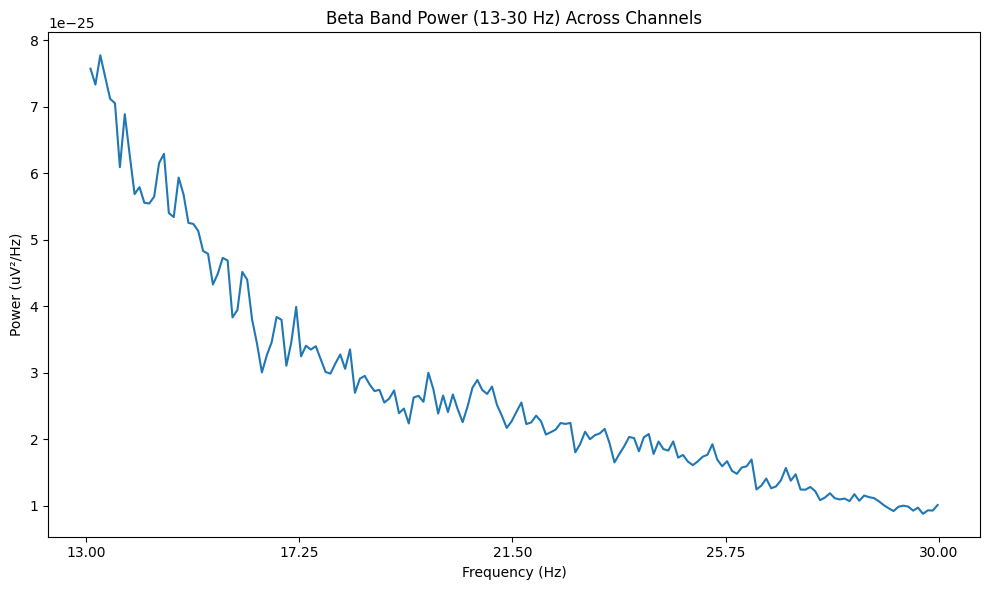

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d17 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d17.head())
print(d17.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d17_clean = d17.replace([np.inf, -np.inf], np.nan)
d17_clean = d17_clean.fillna(d17_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d17_scaled = pd.DataFrame(
    scaler.fit_transform(d17_clean),
    columns=d17_clean.columns,
    index=d17_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d17_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d17_scaled.index,
    columns=d17_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d17_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df17 = d17_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df17["Pd_indicator_meg"] = 0

print("\nShape of df5:", df17.shape)
print(df17.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617 = pd.concat([df1234567810111213141516, df17], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617 = df123456781011121314151617.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617):")
print(df123456781011121314151617)

# Print the shape
print("Shape of df123456781011121314151617:", df123456781011121314151617.shape) #(116,7)


Combined top channels (df123456781011121314151617):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
923    3.698925             0.067587          7.729444e-12  1.225045   
924    3.833333             0.065217          4.060445e-13  1.220517   
925    3.736559             0.066906          8.942023e-12  1.160626   
926    3.870968             0.064583          8.638659e-12  1.288926   
927    3.768817             0.066334          4.257176e-13  1.315979   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.2

In [ ]:
df123456781011121314151617.to_csv('/content/drive/MyDrive/combined_features_upto_sub0017_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617 preserved.


sub-18

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-18'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-018_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-018_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-018_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-018_task-go_run-1_proc-tsss+mc_events.json', 'sub-018_coordsystem.json', 'sub-018_task-noise_proc-tsss_channels.tsv', 'sub-018_task-go_run-1_proc-tsss+mc_meg.json', 'sub-018_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-018_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-018_task-noise_proc-tsss_meg.fif', 'sub-018_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-018_task-noise_proc-tsss_meg.json', 'sub-018_task-passive_run-1_proc-tsss+mc_events.json', 'sub-018_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-018_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-018_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-018_task-rest_run-1_proc-tsss+mc_events.json', 'sub-018_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-018_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-018_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-018_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-018_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-018_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-018_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-18/meg/sub-018_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 196999 =      8.000 ...   196.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


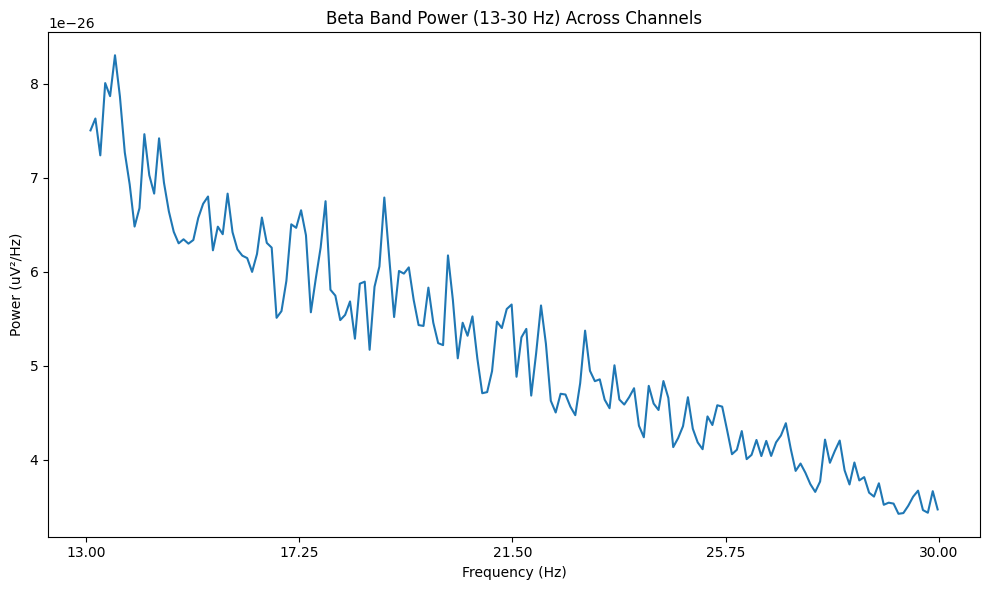

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d18 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d18.head())
print(d18.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d18_clean = d18.replace([np.inf, -np.inf], np.nan)
d18_clean = d18_clean.fillna(d18_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d18_scaled = pd.DataFrame(
    scaler.fit_transform(d18_clean),
    columns=d18_clean.columns,
    index=d18_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d18_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d18_scaled.index,
    columns=d18_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d18_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df18 = d18_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df18["Pd_indicator_meg"] = 0

print("\nShape of df5:", df18.shape)
print(df18.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718 = pd.concat([df123456781011121314151617, df18], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718 = df12345678101112131415161718.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718):")
print(df12345678101112131415161718)

# Print the shape
print("Shape of df12345678101112131415161718:", df12345678101112131415161718.shape) #(116,7)


Combined top channels (df12345678101112131415161718):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.164894             0.060026          3.769601e-12  0.781471   
1      4.063830             0.061518          2.130644e-13  0.733652   
2      4.324468             0.057811          3.549580e-12  0.779541   
3      4.382979             0.056990          4.324233e-12  0.727869   
4      4.361702             0.057317          1.885143e-13  0.732904   
..          ...                  ...                   ...       ...   
981    4.603175             0.054310          2.533180e-12  0.687139   
982    4.248677             0.058587          1.489944e-13  0.828645   
983    4.608466             0.054248          2.716868e-12  0.745392   
984    4.460317             0.056050          2.496036e-12  0.745756   
985    4.354497             0.057187          1.408659e-13  0.769032   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0

In [ ]:
df12345678101112131415161718.to_csv('/content/drive/MyDrive/combined_features_upto_sub0018_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df12345678101112131415161718 preserved.


sub-19

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-19'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-019_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-019_task-go_run-1_proc-tsss+mc_events.json', 'sub-019_coordsystem.json', 'sub-019_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-go_run-1_proc-tsss+mc_meg.json', 'sub-019_task-noise_proc-tsss_channels.tsv', 'sub-019_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-noise_proc-tsss_meg.json', 'sub-019_task-passive_run-1_proc-tsss+mc_events.json', 'sub-019_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-rest_run-1_proc-tsss+mc_events.json', 'sub-019_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-019_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
print("MEG folder path:", meg_folder_path)
print("Folder exists:", os.path.exists(meg_folder_path))
print("Files inside folder:", os.listdir(meg_folder_path))


MEG folder path: /content/drive/MyDrive/sub-19/meg
Folder exists: True
Files inside folder: ['sub-019_task-go_run-1_proc-tsss+mc_events.json', 'sub-019_coordsystem.json', 'sub-019_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-go_run-1_proc-tsss+mc_meg.json', 'sub-019_task-noise_proc-tsss_channels.tsv', 'sub-019_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-noise_proc-tsss_meg.json', 'sub-019_task-passive_run-1_proc-tsss+mc_events.json', 'sub-019_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-rest_run-1_proc-tsss+mc_events.json', 'sub-019_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-019_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'rest'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 196999 =      8.000 ...   196.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


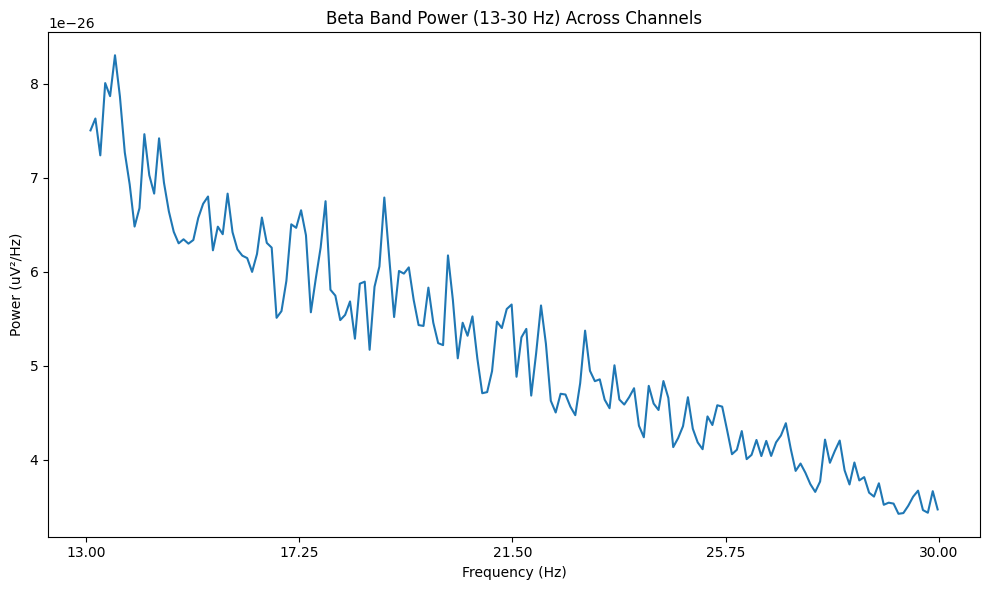

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d19 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d19.head())
print(d19.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d19_clean = d19.replace([np.inf, -np.inf], np.nan)
d19_clean = d19_clean.fillna(d19_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d19_scaled = pd.DataFrame(
    scaler.fit_transform(d19_clean),
    columns=d19_clean.columns,
    index=d19_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d19_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d19_scaled.index,
    columns=d19_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d19_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df19 = d19_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df19["Pd_indicator_meg"] = 0

print("\nShape of df5:", df19.shape)
print(df19.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819 = pd.concat([df12345678101112131415161718, df19], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819 = df1234567810111213141516171819.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819):")
print(df1234567810111213141516171819)

# Print the shape
print("Shape of df1234567810111213141516171819:", df1234567810111213141516171819.shape) #(116,7)


Combined top channels (df1234567810111213141516171819):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1039    4.603175             0.054310          2.533180e-12  0.687139   
1040    4.248677             0.058587          1.489944e-13  0.828645   
1041    4.608466             0.054248          2.716868e-12  0.745392   
1042    4.460317             0.056050          2.496036e-12  0.745756   
1043    4.354497             0.057187          1.408659e-13  0.769032   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_

In [ ]:
df1234567810111213141516171819.to_csv('/content/drive/MyDrive/combined_features_upto_sub0019_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df1234567810111213141516171819 preserved.


sub-21

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-21'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-021_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-021_coordsystem.json', 'sub-021_task-go_run-1_proc-tsss+mc_events.json', 'sub-021_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-021_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-021_task-noise_proc-tsss_channels.tsv', 'sub-021_task-go_run-1_proc-tsss+mc_meg.json', 'sub-021_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-021_task-passive_run-1_proc-tsss+mc_events.json', 'sub-021_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-021_task-noise_proc-tsss_meg.json', 'sub-021_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-021_task-rest_run-1_proc-tsss+mc_events.json', 'sub-021_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-021_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-021_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'rest'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 196999 =      8.000 ...   196.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


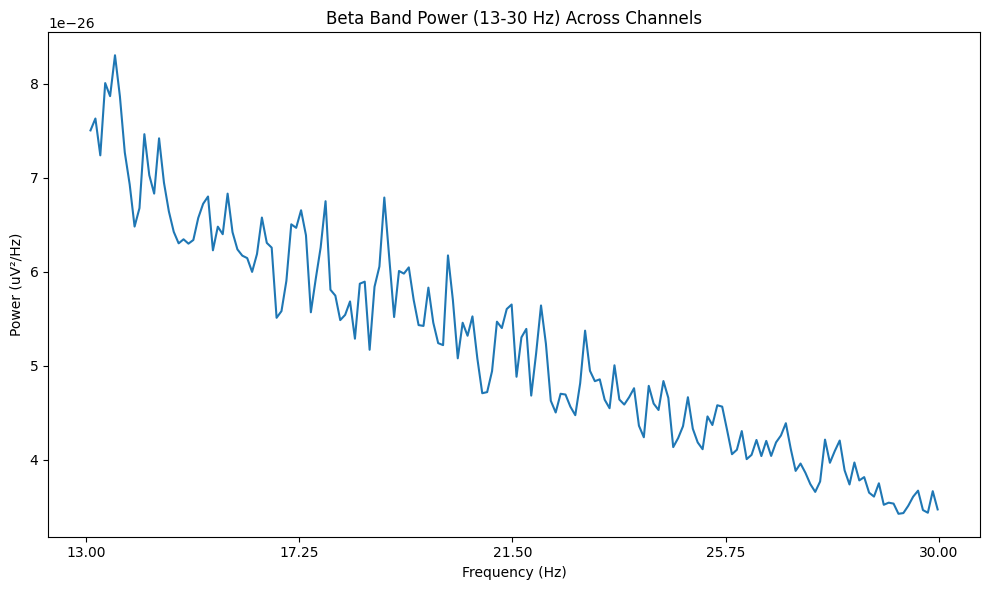

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d21 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d21.head())
print(d21.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d21_clean = d21.replace([np.inf, -np.inf], np.nan)
d21_clean = d21_clean.fillna(d21_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d21_scaled = pd.DataFrame(
    scaler.fit_transform(d21_clean),
    columns=d21_clean.columns,
    index=d21_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d21_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d21_scaled.index,
    columns=d21_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d21_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df21 = d21_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df21["Pd_indicator_meg"] = 0

print("\nShape of df5:", df21.shape)
print(df21.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921 = pd.concat([df1234567810111213141516171819, df21], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921 = df123456781011121314151617181921.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921):")
print(df123456781011121314151617181921)

# Print the shape
print("Shape of df123456781011121314151617181921:", df123456781011121314151617181921.shape) #(116,7)


Combined top channels (df123456781011121314151617181921):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1097    4.603175             0.054310          2.533180e-12  0.687139   
1098    4.248677             0.058587          1.489944e-13  0.828645   
1099    4.608466             0.054248          2.716868e-12  0.745392   
1100    4.460317             0.056050          2.496036e-12  0.745756   
1101    4.354497             0.057187          1.408659e-13  0.769032   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mea

In [ ]:
df123456781011121314151617181921.to_csv('/content/drive/MyDrive/combined_features_upto_sub0021_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921 preserved.


sub-22

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-22'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-022_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-022_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-022_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-022_coordsystem.json', 'sub-022_task-go_run-1_proc-tsss+mc_events.json', 'sub-022_task-go_run-1_proc-tsss+mc_meg.json', 'sub-022_task-noise_proc-tsss_channels.tsv', 'sub-022_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-022_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-022_task-passive_run-1_proc-tsss+mc_events.json', 'sub-022_task-noise_proc-tsss_meg.json', 'sub-022_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-022_task-rest_run-1_proc-tsss+mc_events.json', 'sub-022_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-022_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-022_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'rest'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 196999 =      8.000 ...   196.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


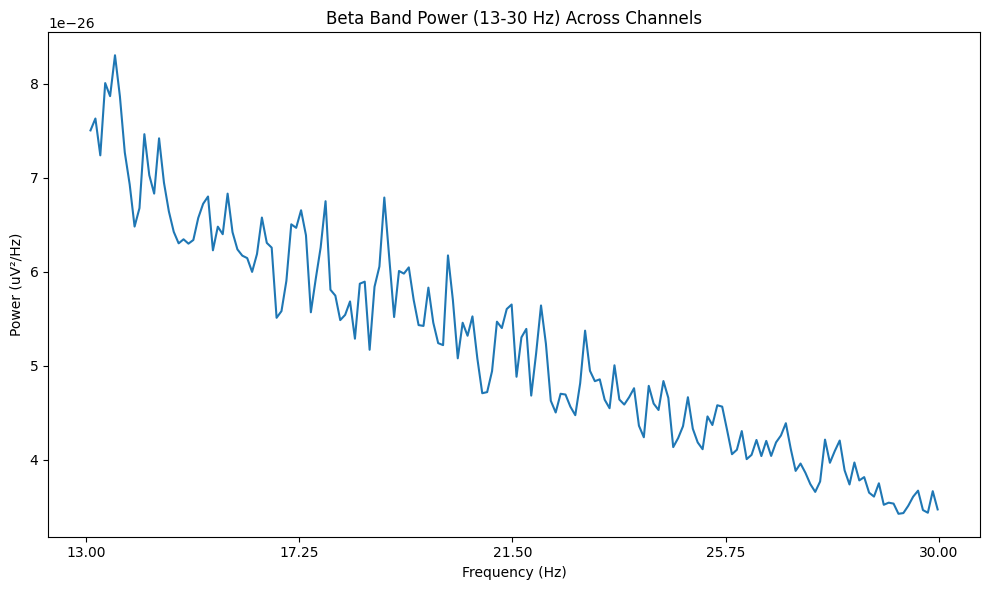

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d22 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d22.head())
print(d22.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d22_clean = d22.replace([np.inf, -np.inf], np.nan)
d22_clean = d22_clean.fillna(d22_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d22_scaled = pd.DataFrame(
    scaler.fit_transform(d22_clean),
    columns=d22_clean.columns,
    index=d22_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d22_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d22_scaled.index,
    columns=d22_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d22_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df22 = d22_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df22["Pd_indicator_meg"] = 1

print("\nShape of df5:", df22.shape)
print(df22.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122 = pd.concat([df123456781011121314151617181921, df22], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122 = df12345678101112131415161718192122.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122):")
print(df12345678101112131415161718192122)

# Print the shape
print("Shape of df12345678101112131415161718192122:", df12345678101112131415161718192122.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1155    4.603175             0.054310          2.533180e-12  0.687139   
1156    4.248677             0.058587          1.489944e-13  0.828645   
1157    4.608466             0.054248          2.716868e-12  0.745392   
1158    4.460317             0.056050          2.496036e-12  0.745756   
1159    4.354497             0.057187          1.408659e-13  0.769032   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  m

In [ ]:
df12345678101112131415161718192122.to_csv('/content/drive/MyDrive/combined_features_upto_sub0022_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df12345678101112131415161718192122 preserved.


sub-23

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-23'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-023_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-023_task-go_run-1_proc-tsss+mc_events.json', 'sub-023_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-023_coordsystem.json', 'sub-023_task-noise_proc-tsss_channels.tsv', 'sub-023_task-go_run-1_proc-tsss+mc_meg.json', 'sub-023_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-023_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-023_task-noise_proc-tsss_meg.json', 'sub-023_task-passive_run-1_proc-tsss+mc_events.json', 'sub-023_task-rest_run-1_proc-tsss+mc_events.json', 'sub-023_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-023_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-023_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-023_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'rest'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 196999 =      8.000 ...   196.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


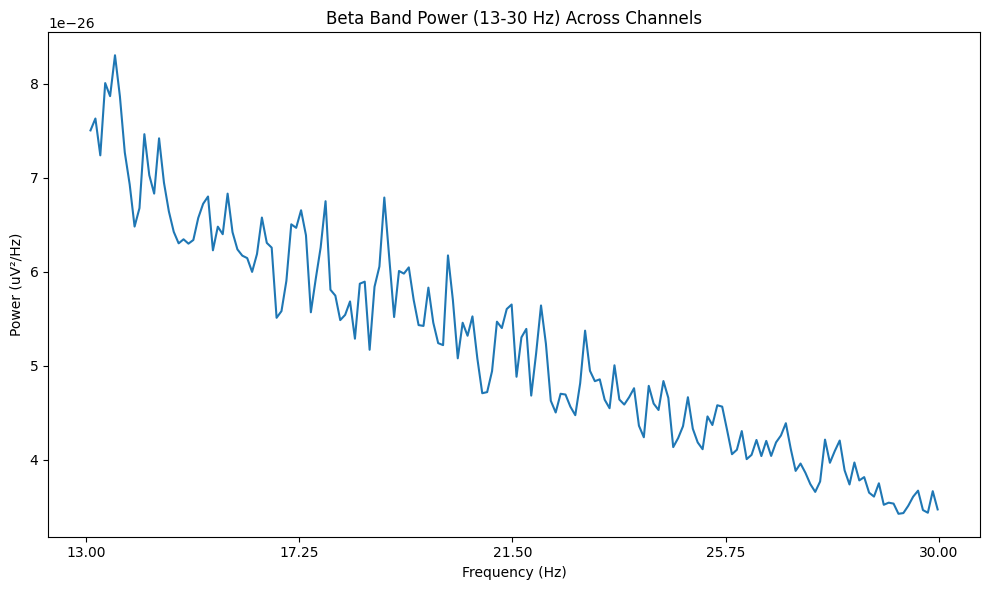

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d23 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d23.head())
print(d23.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d23_clean = d23.replace([np.inf, -np.inf], np.nan)
d23_clean = d23_clean.fillna(d23_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d23_scaled = pd.DataFrame(
    scaler.fit_transform(d23_clean),
    columns=d23_clean.columns,
    index=d23_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d23_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d23_scaled.index,
    columns=d23_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d23_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df23 = d23_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df23["Pd_indicator_meg"] = 0

print("\nShape of df5:", df23.shape)
print(df23.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223 = pd.concat([df12345678101112131415161718192122, df23], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223 = df1234567810111213141516171819212223.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223):")
print(df1234567810111213141516171819212223)

# Print the shape
print("Shape of df1234567810111213141516171819212223:", df1234567810111213141516171819212223.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1213    4.603175             0.054310          2.533180e-12  0.687139   
1214    4.248677             0.058587          1.489944e-13  0.828645   
1215    4.608466             0.054248          2.716868e-12  0.745392   
1216    4.460317             0.056050          2.496036e-12  0.745756   
1217    4.354497             0.057187          1.408659e-13  0.769032   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv 

In [ ]:
df1234567810111213141516171819212223.to_csv('/content/drive/MyDrive/combined_features_upto_sub0023_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df1234567810111213141516171819212223 preserved.


sub-24

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-24'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-024_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-024_task-go_run-1_proc-tsss+mc_events.json', 'sub-024_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-024_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-024_coordsystem.json', 'sub-024_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-024_task-noise_proc-tsss_meg.fif', 'sub-024_task-noise_proc-tsss_channels.tsv', 'sub-024_task-go_run-1_proc-tsss+mc_meg.json', 'sub-024_task-noise_proc-tsss_meg.json', 'sub-024_task-passive_run-1_proc-tsss+mc_events.json', 'sub-024_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-024_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-024_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-024_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-024_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-024_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-024_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-024_task-rest_run-1_proc-tsss+mc_events.json', 'sub-024_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-024_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-024_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-024_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-024_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-24/meg/sub-024_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-24/meg/sub-024_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 14000 ... 203999 =     14.000 ...   203.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


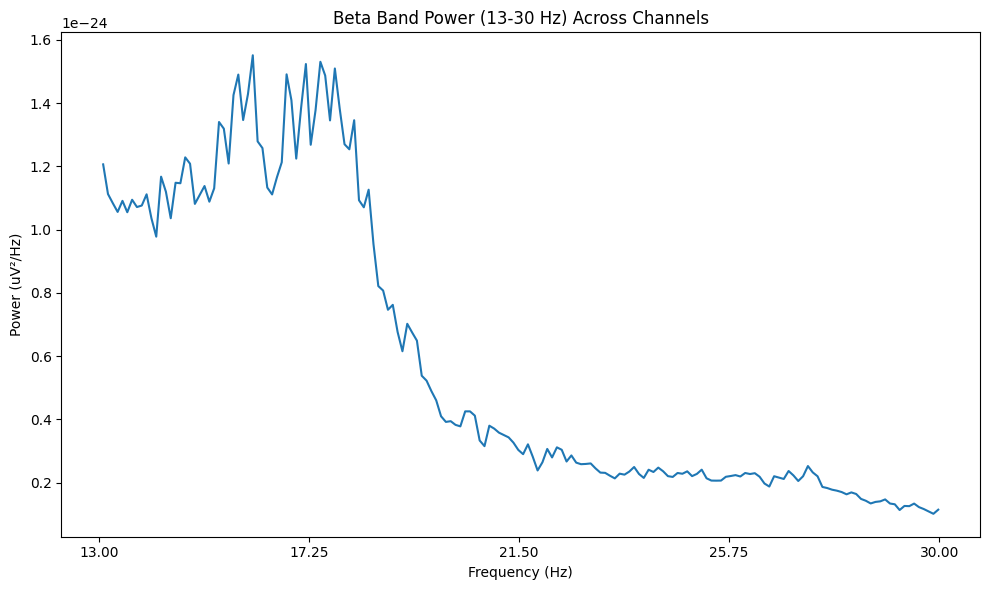

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d24 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d24.head())
print(d24.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d24_clean = d24.replace([np.inf, -np.inf], np.nan)
d24_clean = d24_clean.fillna(d24_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d24_scaled = pd.DataFrame(
    scaler.fit_transform(d24_clean),
    columns=d24_clean.columns,
    index=d24_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d24_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d24_scaled.index,
    columns=d24_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d24_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df24 = d24_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df24["Pd_indicator_meg"] = 0

print("\nShape of df5:", df24.shape)
print(df24.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324 = pd.concat([df1234567810111213141516171819212223, df24], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324 = df123456781011121314151617181921222324.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324):")
print(df123456781011121314151617181921222324)

# Print the shape
print("Shape of df123456781011121314151617181921222324:", df123456781011121314151617181921222324.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1271    3.757895             0.066527          6.744550e-12  0.985073   
1272    3.536842             0.070685          4.309765e-13  0.849364   
1273    3.573684             0.069956          9.204345e-12  1.126746   
1274    3.973684             0.062914          6.335439e-12  0.781188   
1275    3.557895             0.070266          4.672556e-13  0.896632   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_c

In [ ]:
df123456781011121314151617181921222324.to_csv('/content/drive/MyDrive/combined_features_upto_sub0024_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921222324 preserved.


sub-25

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-25'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-025_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-025_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-025_coordsystem.json', 'sub-025_task-go_run-1_proc-tsss+mc_events.json', 'sub-025_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-025_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-025_task-noise_proc-tsss_meg.fif', 'sub-025_task-go_run-1_proc-tsss+mc_meg.json', 'sub-025_task-noise_proc-tsss_channels.tsv', 'sub-025_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-025_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-025_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-025_task-noise_proc-tsss_meg.json', 'sub-025_task-passive_run-1_proc-tsss+mc_events.json', 'sub-025_task-rest_run-1_proc-tsss_channels.tsv', 'sub-025_task-rest_run-1_proc-tsss_events.json', 'sub-025_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-025_task-rest_run-1_proc-tsss_events.tsv', 'sub-025_task-rest_run-1_proc-tsss_meg.fif', 'sub-025_task-rest_run-1_proc-tsss_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-025_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-025_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-025_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-025_task-rest_run-1_proc-tsss_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-25/meg/sub-025_task-rest_run-1_proc-tsss_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-25/meg/sub-025_task-rest_run-1_proc-tsss_meg.fif...
    Range : 7000 ... 203999 =      7.000 ...   203.999 secs
Ready.
Reading 0 ... 196999  =      0.000 ...   196.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


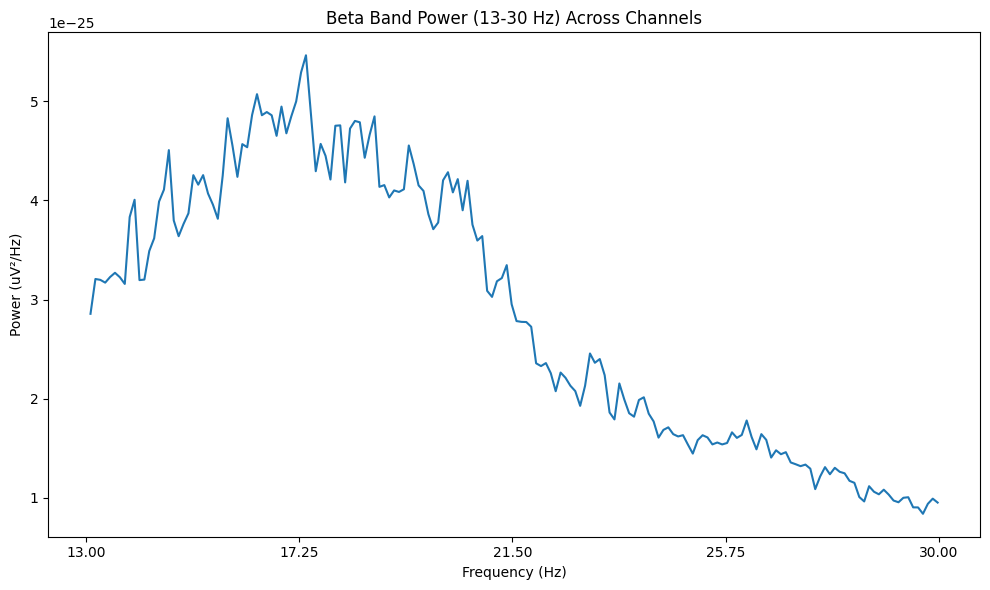

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Exraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d25 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d25.head())
print(d25.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 25 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d25_clean = d25.replace([np.inf, -np.inf], np.nan)
d25_clean = d25_clean.fillna(d25_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d25_scaled = pd.DataFrame(
    scaler.fit_transform(d25_clean),
    columns=d25_clean.columns,
    index=d25_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d25_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d25_scaled.index,
    columns=d25_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d25_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df25 = d25_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df25["Pd_indicator_meg"] = 0

print("\nShape of df5:", df25.shape)
print(df25.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425 = pd.concat([df123456781011121314151617181921222324, df25], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425 = df12345678101112131415161718192122232425.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425):")
print(df12345678101112131415161718192122232425)

# Print the shape
print("Shape of df12345678101112131415161718192122232425:", df12345678101112131415161718192122232425.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1329    3.746193             0.066734          5.550429e-12  0.906851   
1330    3.670051             0.068119          3.450958e-13  1.014622   
1331    3.543147             0.070559          7.017945e-12  1.069360   
1332    3.619289             0.068913          6.680165e-12  1.100829   
1333    3.822335             0.065405          3.206574e-13  1.073603   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp

In [ ]:
df12345678101112131415161718192122232425.to_csv('/content/drive/MyDrive/combined_features_upto_sub0025_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df12345678101112131415161718192122232425 preserved.


sub-26

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-26'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-026_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-026_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-026_coordsystem.json', 'sub-026_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-026_task-go_run-1_proc-tsss+mc_events.json', 'sub-026_task-go_run-1_proc-tsss+mc_meg.json', 'sub-026_task-noise_proc-tsss_channels.tsv', 'sub-026_task-noise_proc-tsss_meg.json', 'sub-026_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-026_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-026_task-passive_run-1_proc-tsss+mc_events.json', 'sub-026_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-026_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-026_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-026_task-rest_run-1_proc-tsss+mc_events.json', 'sub-026_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'rest'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-25/meg/sub-025_task-rest_run-1_proc-tsss_meg.fif...
    Range : 7000 ... 203999 =      7.000 ...   203.999 secs
Ready.
Reading 0 ... 196999  =      0.000 ...   196.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


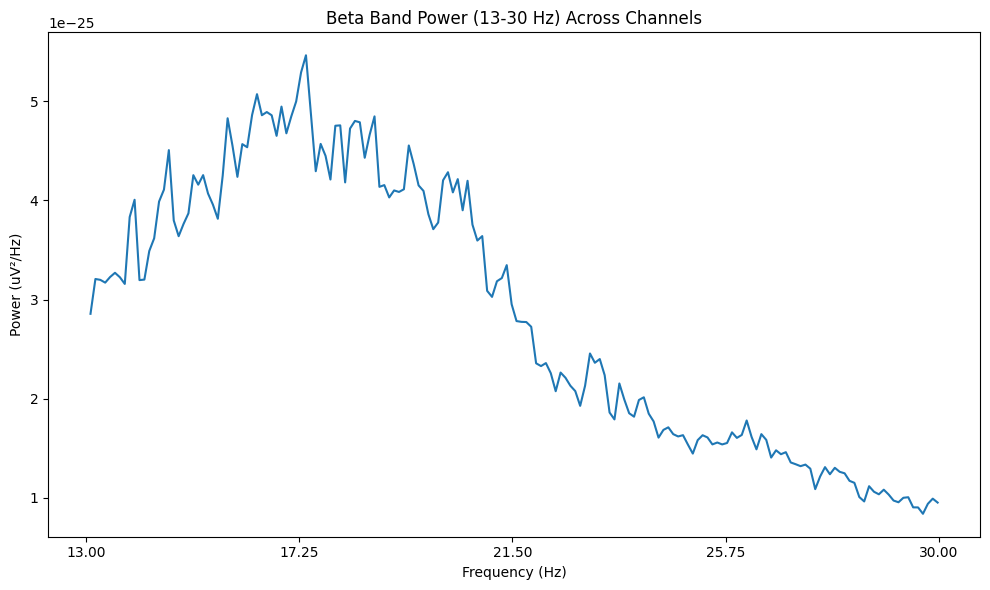

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d26 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d26.head())
print(d26.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d26_clean = d26.replace([np.inf, -np.inf], np.nan)
d26_clean = d26_clean.fillna(d26_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d26_scaled = pd.DataFrame(
    scaler.fit_transform(d26_clean),
    columns=d26_clean.columns,
    index=d26_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d26_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d26_scaled.index,
    columns=d26_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d26_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df26 = d26_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df26["Pd_indicator_meg"] = 0

print("\nShape of df5:", df26.shape)
print(df26.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526 = pd.concat([df12345678101112131415161718192122232425, df26], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526 = df1234567810111213141516171819212223242526.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526):")
print(df1234567810111213141516171819212223242526)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526:", df1234567810111213141516171819212223242526.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1387    3.746193             0.066734          5.550429e-12  0.906851   
1388    3.670051             0.068119          3.450958e-13  1.014622   
1389    3.543147             0.070559          7.017945e-12  1.069360   
1390    3.619289             0.068913          6.680165e-12  1.100829   
1391    3.822335             0.065405          3.206574e-13  1.073603   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_a

In [ ]:
df1234567810111213141516171819212223242526.to_csv('/content/drive/MyDrive/combined_features_upto_sub0026_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df1234567810111213141516171819212223242526 preserved.


sub-27

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-27'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-027_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-027_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-027_task-go_run-1_proc-tsss+mc_events.json', 'sub-027_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-027_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-027_coordsystem.json', 'sub-027_task-noise_proc-tsss_channels.tsv', 'sub-027_task-go_run-1_proc-tsss+mc_meg.json', 'sub-027_task-noise_proc-tsss_meg.fif', 'sub-027_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-027_task-passive_run-1_proc-tsss+mc_events.json', 'sub-027_task-noise_proc-tsss_meg.json', 'sub-027_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-027_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-027_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-027_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-027_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-027_task-rest_run-1_proc-tsss+mc_events.json', 'sub-027_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-027_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-027_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-027_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-027_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-027_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-27/meg/sub-027_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-27/meg/sub-027_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 206999 =     18.000 ...   206.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


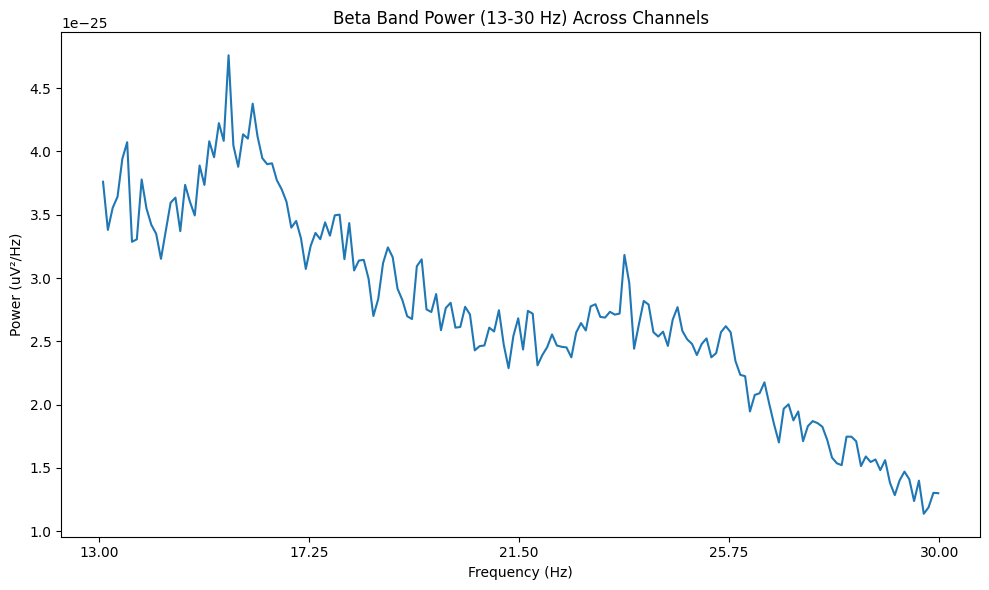

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d27 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d27.head())
print(d27.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d27_clean = d27.replace([np.inf, -np.inf], np.nan)
d27_clean = d27_clean.fillna(d27_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d27_scaled = pd.DataFrame(
    scaler.fit_transform(d27_clean),
    columns=d27_clean.columns,
    index=d27_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d27_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d27_scaled.index,
    columns=d27_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d27_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df27 = d27_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df27["Pd_indicator_meg"] = 0

print("\nShape of df5:", df27.shape)
print(df27.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627 = pd.concat([df1234567810111213141516171819212223242526, df27], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627 = df123456781011121314151617181921222324252627.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627):")
print(df123456781011121314151617181921222324252627)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627:", df123456781011121314151617181921222324252627.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1445    4.089947             0.061125          7.030149e-12  0.920413   
1446    4.111111             0.060811          3.750394e-13  0.864532   
1447    4.058201             0.061604          7.263897e-12  0.844261   
1448    4.089947             0.061125          6.434080e-12  0.921222   
1449    4.164021             0.060038          3.517723e-13  0.822261   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst

In [ ]:
df123456781011121314151617181921222324252627.to_csv('/content/drive/MyDrive/combined_features_upto_sub0027_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921222324252627 preserved.


sub-28

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-28'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-028_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-028_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-028_task-go_run-1_proc-tsss+mc_events.json', 'sub-028_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-028_coordsystem.json', 'sub-028_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-028_task-go_run-1_proc-tsss+mc_meg.json', 'sub-028_task-noise_proc-tsss_channels.tsv', 'sub-028_task-noise_proc-tsss_meg.fif', 'sub-028_task-noise_proc-tsss_meg.json', 'sub-028_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-028_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-028_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-028_task-passive_run-1_proc-tsss+mc_events.json', 'sub-028_task-rest_run-1_proc-tsss+mc_events.json', 'sub-028_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-028_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-028_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-028_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-028_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-028_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-028_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-028_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-028_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-28/meg/sub-028_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-28/meg/sub-028_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 10000 ... 201999 =     10.000 ...   201.999 secs
Ready.
Reading 0 ... 191999  =      0.000 ...   191.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


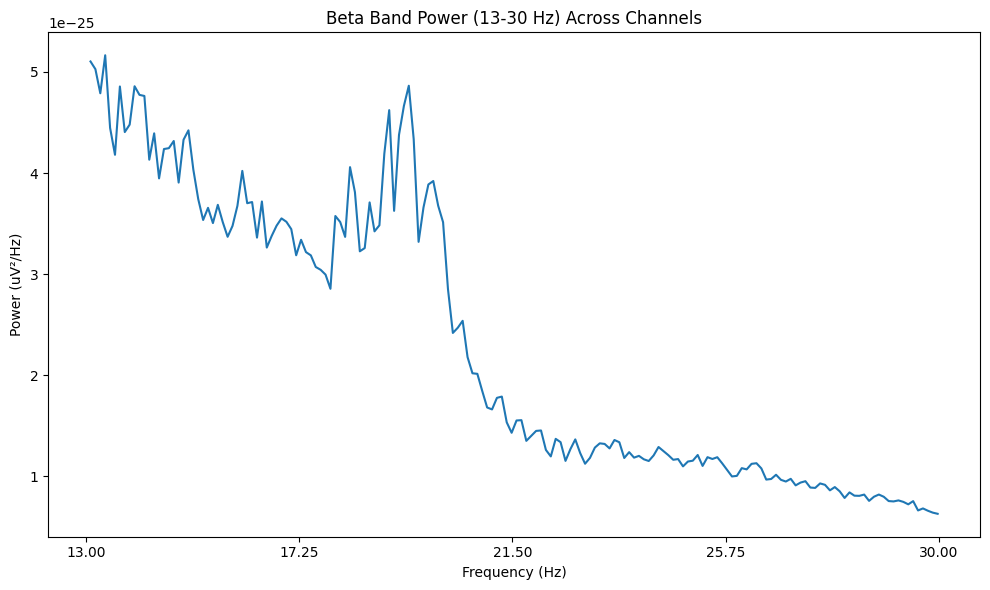

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d28 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d28.head())
print(d28.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d28_clean = d28.replace([np.inf, -np.inf], np.nan)
d28_clean = d28_clean.fillna(d28_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d28_scaled = pd.DataFrame(
    scaler.fit_transform(d28_clean),
    columns=d28_clean.columns,
    index=d28_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d28_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d28_scaled.index,
    columns=d28_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d28_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df28 = d28_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df28["Pd_indicator_meg"] = 0

print("\nShape of df5:", df28.shape)
print(df28.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728 = pd.concat([df123456781011121314151617181921222324252627, df28], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728 = df12345678101112131415161718192122232425262728.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728):")
print(df12345678101112131415161718192122232425262728)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728:", df12345678101112131415161718192122232425262728.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1503    4.062500             0.061538          3.592806e-12  0.754337   
1504    4.375000             0.057143          1.947075e-13  0.813746   
1505    4.015625             0.062257          4.101206e-12  0.773345   
1506    4.088542             0.061146          3.409914e-12  0.821184   
1507    4.177083             0.059850          1.910339e-13  0.765384   

      duty_cycle  peak_beta_freq  burst_dur_cv  bur

In [ ]:
df12345678101112131415161718192122232425262728.to_csv('/content/drive/MyDrive/combined_features_upto_sub0028_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df12345678101112131415161718192122232425262728 preserved.


sub-29

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-29'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-029_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-029_coordsystem.json', 'sub-029_task-go_run-1_proc-tsss+mc_events.json', 'sub-029_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-029_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-029_task-go_run-1_proc-tsss+mc_meg.json', 'sub-029_task-noise_proc-tsss_channels.tsv', 'sub-029_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-029_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-029_task-noise_proc-tsss_meg.json', 'sub-029_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-029_task-passive_run-1_proc-tsss+mc_events.json', 'sub-029_task-noise_proc-tsss_meg.fif', 'sub-029_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-029_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-029_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-029_task-rest_run-1_proc-tsss+mc_events.json', 'sub-029_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-029_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-029_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-029_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-029_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-029_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-029_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-29/meg/sub-029_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-29/meg/sub-029_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 47000 ... 254999 =     47.000 ...   254.999 secs
Ready.
Reading 0 ... 207999  =      0.000 ...   207.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


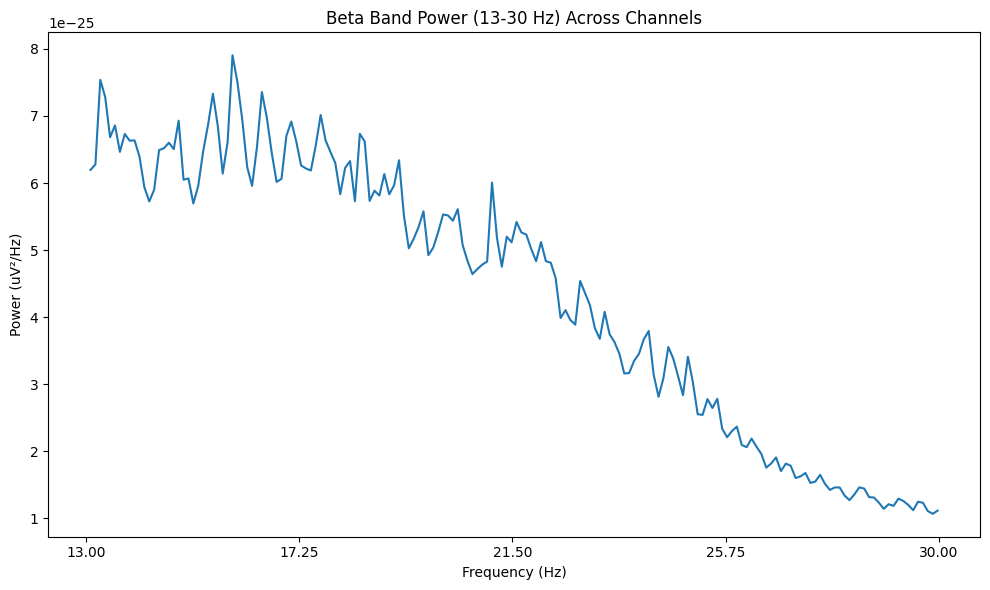

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Featre Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d29 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d29.head())
print(d29.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d29_clean = d29.replace([np.inf, -np.inf], np.nan)
d29_clean = d29_clean.fillna(d29_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d29_scaled = pd.DataFrame(
    scaler.fit_transform(d29_clean),
    columns=d29_clean.columns,
    index=d29_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d29_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d29_scaled.index,
    columns=d29_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d29_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df29 = d29_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df29["Pd_indicator_meg"] = 1

print("\nShape of df5:", df29.shape)
print(df29.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829 = pd.concat([df12345678101112131415161718192122232425262728, df29], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829 = df1234567810111213141516171819212223242526272829.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829):")
print(df1234567810111213141516171819212223242526272829)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829:", df1234567810111213141516171819212223242526272829.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1561    3.822115             0.065409          5.780764e-12  0.761423   
1562    3.663462             0.068241          3.912020e-13  0.764773   
1563    3.826923             0.065327          6.240898e-12  0.816912   
1564    3.807692             0.065657          5.723578e-12  0.827069   
1565    3.735577             0.066924          3.894936e-13  0.739785   

      duty_cycle  peak_beta_freq  burst_dur_cv  b

In [ ]:
df1234567810111213141516171819212223242526272829.to_csv('/content/drive/MyDrive/combined_features_upto_sub0029_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df1234567810111213141516171819212223242526272829 preserved.


sub-30

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-30'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-030_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-030_coordsystem.json', 'sub-030_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-030_task-go_run-1_proc-tsss+mc_events.json', 'sub-030_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-030_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-030_task-go_run-1_proc-tsss+mc_meg.json', 'sub-030_task-noise_proc-tsss_channels.tsv', 'sub-030_task-noise_proc-tsss_meg.fif', 'sub-030_task-noise_proc-tsss_meg.json', 'sub-030_task-passive_run-1_proc-tsss+mc_events.json', 'sub-030_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-030_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-030_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-030_task-rest_run-1_proc-tsss+mc_events.json', 'sub-030_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-030_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-030_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-030_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-030_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-030_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-030_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-030_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-030_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-30/meg/sub-030_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-30/meg/sub-030_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 15000 ... 207999 =     15.000 ...   207.999 secs
Ready.
Reading 0 ... 192999  =      0.000 ...   192.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


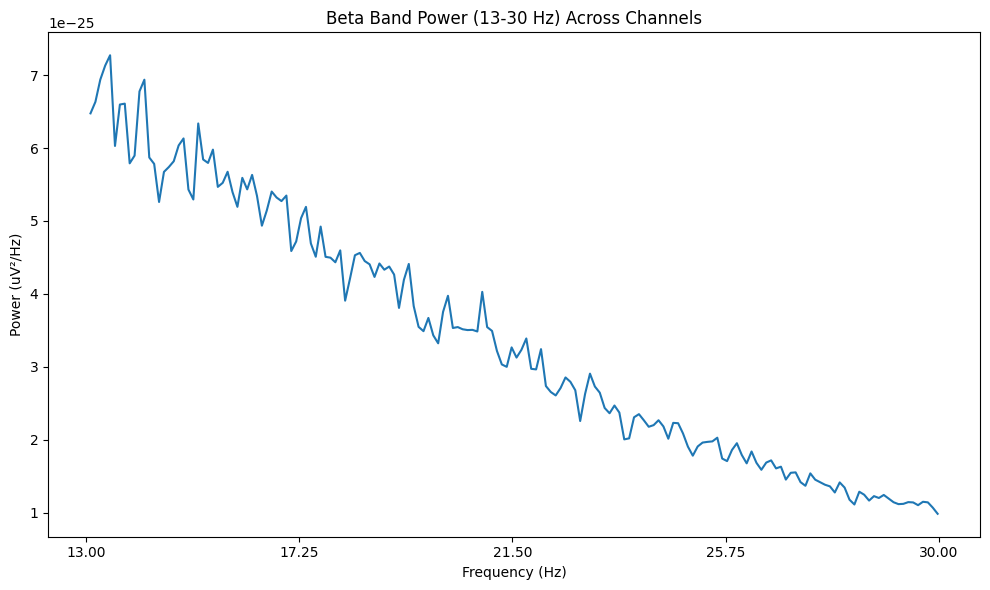

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d30 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d30.head())
print(d30.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d30_clean = d30.replace([np.inf, -np.inf], np.nan)
d30_clean = d30_clean.fillna(d30_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d30_scaled = pd.DataFrame(
    scaler.fit_transform(d30_clean),
    columns=d30_clean.columns,
    index=d30_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d30_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d30_scaled.index,
    columns=d30_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d30_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df30 = d30_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df30["Pd_indicator_meg"] = 0

print("\nShape of df5:", df30.shape)
print(df30.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930 = pd.concat([df1234567810111213141516171819212223242526272829, df30], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930 = df123456781011121314151617181921222324252627282930.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930):")
print(df123456781011121314151617181921222324252627282930)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930:", df123456781011121314151617181921222324252627282930.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1619    4.093264             0.061076          4.864649e-12  0.760633   
1620    3.860104             0.064765          3.076135e-13  0.852056   
1621    4.170984             0.059938          5.514433e-12  0.807485   
1622    3.943005             0.063403          5.082264e-12  0.824066   
1623    3.911917             0.063907          3.245868e-13  0.796837   

      duty_cycle  peak_beta_freq  burst_dur_cv 

In [ ]:
df123456781011121314151617181921222324252627282930.to_csv('/content/drive/MyDrive/combined_features_upto_sub0030_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921222324252627282930 preserved.


sub-31

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-31'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-031_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-031_coordsystem.json', 'sub-031_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-031_task-go_run-1_proc-tsss+mc_events.json', 'sub-031_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-031_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-031_task-go_run-1_proc-tsss+mc_meg.json', 'sub-031_task-noise_proc-tsss_meg.fif', 'sub-031_task-noise_proc-tsss_channels.tsv', 'sub-031_task-noise_proc-tsss_meg.json', 'sub-031_task-passive_run-1_proc-tsss+mc_events.json', 'sub-031_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-031_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-031_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-031_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-031_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-031_task-rest_run-1_proc-tsss+mc_events.json', 'sub-031_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-031_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-031_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-031_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-031_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-031_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-031_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-31/meg/sub-031_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-31/meg/sub-031_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 211999 =     18.000 ...   211.999 secs
Ready.
Reading 0 ... 193999  =      0.000 ...   193.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


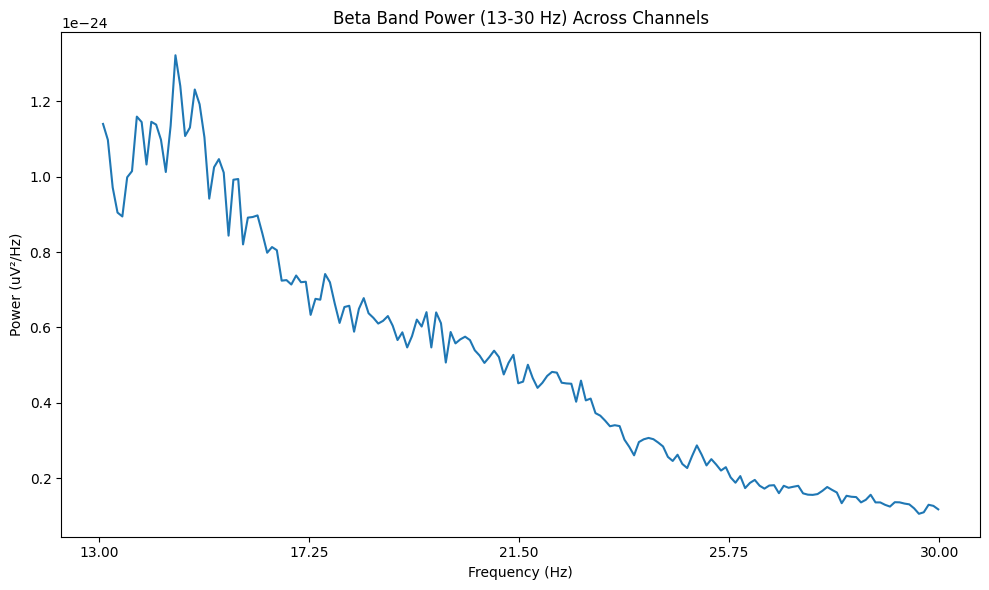

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d31 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d31.head())
print(d31.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d31_clean = d31.replace([np.inf, -np.inf], np.nan)
d31_clean = d31_clean.fillna(d31_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d31_scaled = pd.DataFrame(
    scaler.fit_transform(d31_clean),
    columns=d31_clean.columns,
    index=d31_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d31_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d31_scaled.index,
    columns=d31_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d31_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df31 = d31_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df31["Pd_indicator_meg"] = 1

print("\nShape of df5:", df31.shape)
print(df31.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031 = pd.concat([df123456781011121314151617181921222324252627282930, df31], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031 = df12345678101112131415161718192122232425262728293031.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031):")
print(df12345678101112131415161718192122232425262728293031)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031:", df12345678101112131415161718192122232425262728293031.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1677    4.030928             0.062020          1.223001e-11  0.780048   
1678    3.958763             0.063151          5.737324e-13  0.730481   
1679    4.092784             0.061083          1.283647e-11  0.746488   
1680    4.010309             0.062339          1.086256e-11  0.700002   
1681    3.881443             0.064409          5.882475e-13  0.732909   

      duty_cycle  peak_beta_freq  burst_dur_c

In [ ]:
df12345678101112131415161718192122232425262728293031.to_csv('/content/drive/MyDrive/combined_features_upto_sub0031_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031 preserved.")


RAM Used After Cleanup: 0.56 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031 preserved.


sub-32

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-32'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-032_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-032_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-032_task-go_run-1_proc-tsss+mc_events.json', 'sub-032_coordsystem.json', 'sub-032_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-032_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-032_task-noise_proc-tsss_meg.fif', 'sub-032_task-noise_proc-tsss_channels.tsv', 'sub-032_task-go_run-1_proc-tsss+mc_meg.json', 'sub-032_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-032_task-passive_run-1_proc-tsss+mc_events.json', 'sub-032_task-noise_proc-tsss_meg.json', 'sub-032_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-032_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-032_task-rest_run-1_proc-tsss+mc_events.json', 'sub-032_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-032_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-032_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-032_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-032_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-032_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-032_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-032_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-032_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-32/meg/sub-032_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-32/meg/sub-032_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 21000 ... 237999 =     21.000 ...   237.999 secs
Ready.
Reading 0 ... 216999  =      0.000 ...   216.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


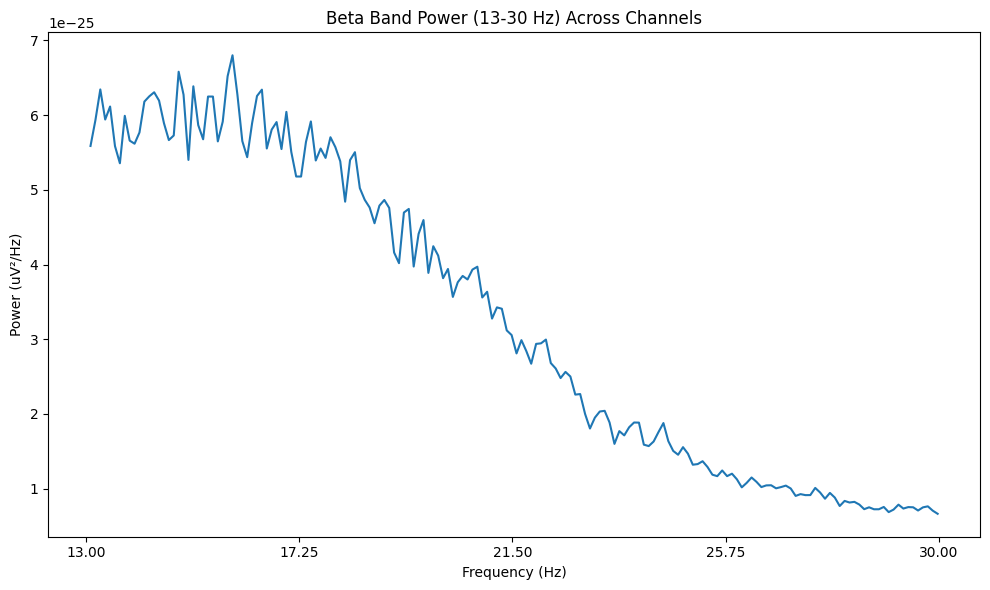

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d32 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d32.head())
print(d32.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d32_clean = d32.replace([np.inf, -np.inf], np.nan)
d32_clean = d32_clean.fillna(d32_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d32_scaled = pd.DataFrame(
    scaler.fit_transform(d32_clean),
    columns=d32_clean.columns,
    index=d32_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d32_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d32_scaled.index,
    columns=d32_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d32_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df32 = d32_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df32["Pd_indicator_meg"] = 0

print("\nShape of df5:", df32.shape)
print(df32.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132 = pd.concat([df12345678101112131415161718192122232425262728293031, df32], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132 = df1234567810111213141516171819212223242526272829303132.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132):")
print(df1234567810111213141516171819212223242526272829303132)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132:", df1234567810111213141516171819212223242526272829303132.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1735    3.658986             0.068325          6.563097e-12  0.805747   
1736    3.548387             0.070455          4.339263e-13  0.711558   
1737    3.668203             0.068153          7.331785e-12  0.808055   
1738    3.640553             0.068671          6.976317e-12  0.790615   
1739    3.534562             0.070730          4.651094e-13  0.720264   

      duty_cycle  peak_beta_freq  burst_dur

In [ ]:
df1234567810111213141516171819212223242526272829303132.to_csv('/content/drive/MyDrive/combined_features_upto_sub0032_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132 preserved.


sub-33

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-33'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-033_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-033_coordsystem.json', 'sub-033_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-033_task-go_run-1_proc-tsss+mc_events.json', 'sub-033_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-033_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-033_task-go_run-1_proc-tsss+mc_meg.json', 'sub-033_task-noise_proc-tsss_channels.tsv', 'sub-033_task-noise_proc-tsss_meg.fif', 'sub-033_task-passive_run-1_proc-tsss+mc_events.json', 'sub-033_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-033_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-033_task-noise_proc-tsss_meg.json', 'sub-033_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-033_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-033_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-033_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-033_task-rest_run-1_proc-tsss+mc_events.json', 'sub-033_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-033_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-033_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-033_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-033_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-033_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-33/meg/sub-033_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-33/meg/sub-033_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 26000 ... 210999 =     26.000 ...   210.999 secs
Ready.
Reading 0 ... 184999  =      0.000 ...   184.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


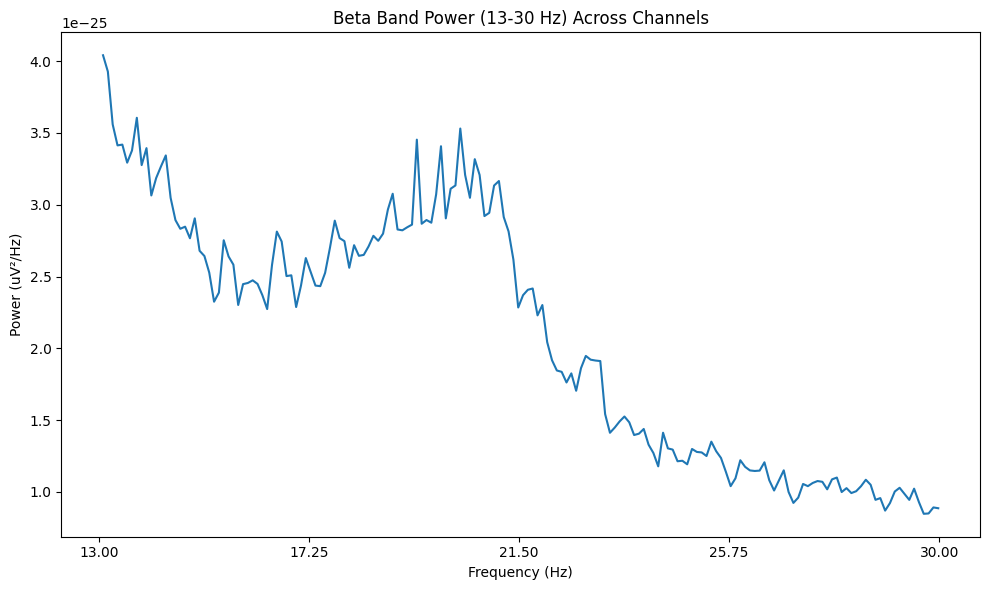

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d33 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d33.head())
print(d33.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d33_clean = d33.replace([np.inf, -np.inf], np.nan)
d33_clean = d33_clean.fillna(d33_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d33_scaled = pd.DataFrame(
    scaler.fit_transform(d33_clean),
    columns=d33_clean.columns,
    index=d33_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d33_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d33_scaled.index,
    columns=d33_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d33_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df33 = d33_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df33["Pd_indicator_meg"] = 1

print("\nShape of df5:", df33.shape)
print(df33.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233 = pd.concat([df1234567810111213141516171819212223242526272829303132, df33], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233 = df123456781011121314151617181921222324252627282930313233.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233):")
print(df123456781011121314151617181921222324252627282930313233)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233:", df123456781011121314151617181921222324252627282930313233.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1793    3.983784             0.062754          4.966565e-12  0.774216   
1794    4.232432             0.059068          2.512865e-13  0.775815   
1795    3.816216             0.065510          5.909120e-12  0.796265   
1796    3.821622             0.065417          4.933323e-12  0.902929   
1797    3.940541             0.063443          2.610445e-13  0.786154   

      duty_cycle  peak_beta_freq  burst_d

In [ ]:
df123456781011121314151617181921222324252627282930313233.to_csv('/content/drive/MyDrive/combined_features_upto_sub0033_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233 preserved.")


RAM Used After Cleanup: 0.56 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233 preserved.


sub-35

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-35'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-035_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-035_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-035_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-035_coordsystem.json', 'sub-035_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-035_task-go_run-1_proc-tsss+mc_events.json', 'sub-035_task-noise_proc-tsss_meg.fif', 'sub-035_task-noise_proc-tsss_channels.tsv', 'sub-035_task-go_run-1_proc-tsss+mc_meg.json', 'sub-035_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-035_task-noise_proc-tsss_meg.json', 'sub-035_task-passive_run-1_proc-tsss+mc_events.json', 'sub-035_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-035_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-035_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-035_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-035_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-035_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-035_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-035_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-035_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-035_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-35/meg/sub-035_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-35/meg/sub-035_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 29000 ... 249999 =     29.000 ...   249.999 secs
Ready.
Reading 0 ... 220999  =      0.000 ...   220.999 secs...
Finding events on: STI101
Finding events on: STI101
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitting ICA to data using 306 channels (please be patient, this may take a while)
Selecting by number: 10 component

Computing Power Spectral Density

Effective window size : 10.240 (s)


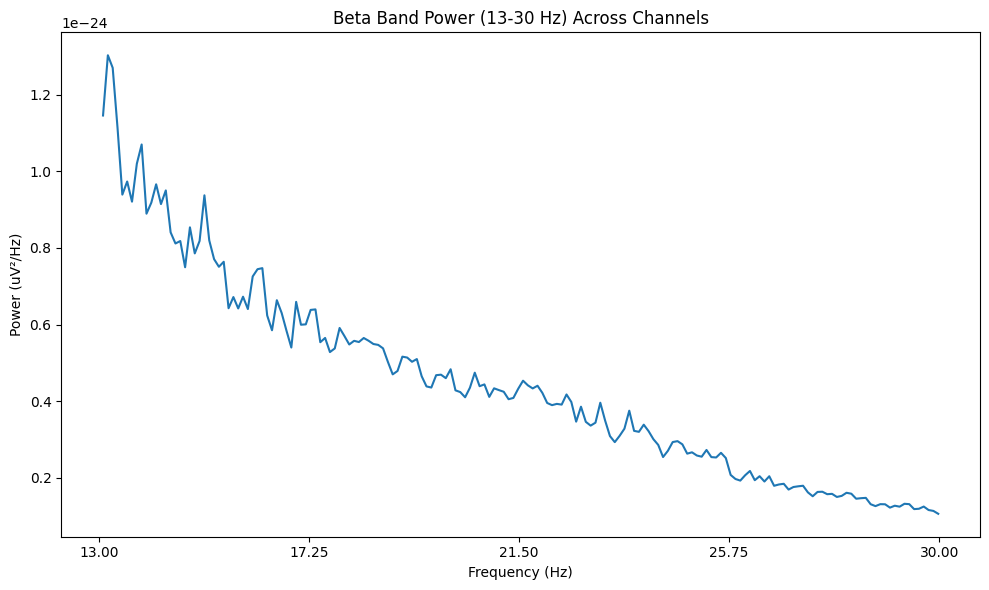

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d35 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d35.head())
print(d35.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d35_clean = d35.replace([np.inf, -np.inf], np.nan)
d35_clean = d35_clean.fillna(d35_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d35_scaled = pd.DataFrame(
    scaler.fit_transform(d35_clean),
    columns=d35_clean.columns,
    index=d35_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d35_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d35_scaled.index,
    columns=d35_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d35_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df35 = d35_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df35["Pd_indicator_meg"] = 1

print("\nShape of df5:", df35.shape)
print(df35.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335 = pd.concat([df123456781011121314151617181921222324252627282930313233, df35], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335 = df12345678101112131415161718192122232425262728293031323335.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335):")
print(df12345678101112131415161718192122232425262728293031323335)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335:", df12345678101112131415161718192122232425262728293031323335.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1851    3.262443             0.076630          8.412020e-12  1.208659   
1852    3.647059             0.068548          3.871067e-13  1.011225   
1853    3.461538             0.072222          7.344784e-12  1.067007   
1854    3.529412             0.070833          6.113301e-12  1.073680   
1855    3.692308             0.067708          4.191261e-13  1.047893   

      duty_cycle  peak_beta_freq  burst

In [ ]:
df12345678101112131415161718192122232425262728293031323335.to_csv('/content/drive/MyDrive/combined_features_upto_sub0035_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335 preserved.")


RAM Used After Cleanup: 0.61 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335 preserved.


sub-36

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-36'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-036_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-036_coordsystem.json', 'sub-036_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-036_task-go_run-1_proc-tsss+mc_events.json', 'sub-036_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-036_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-036_task-noise_proc-tsss_channels.tsv', 'sub-036_task-go_run-1_proc-tsss+mc_meg.json', 'sub-036_task-noise_proc-tsss_meg.fif', 'sub-036_task-noise_proc-tsss_meg.json', 'sub-036_task-passive_run-1_proc-tsss+mc_events.json', 'sub-036_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-036_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-036_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-036_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-036_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-036_task-rest_run-1_proc-tsss+mc_events.json', 'sub-036_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-036_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-036_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-036_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-036_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-036_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-036_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-36/meg/sub-036_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-36/meg/sub-036_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 27000 ... 252999 =     27.000 ...   252.999 secs
Ready.
Reading 0 ... 225999  =      0.000 ...   225.999 secs...
Finding events on: STI101
1 event found on stim channel STI101
Event IDs: [1]
Finding events on: STI101
1 event found on stim channel STI101
Event IDs: [1]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitting ICA

Computing Power Spectral Density

Effective window size : 10.240 (s)


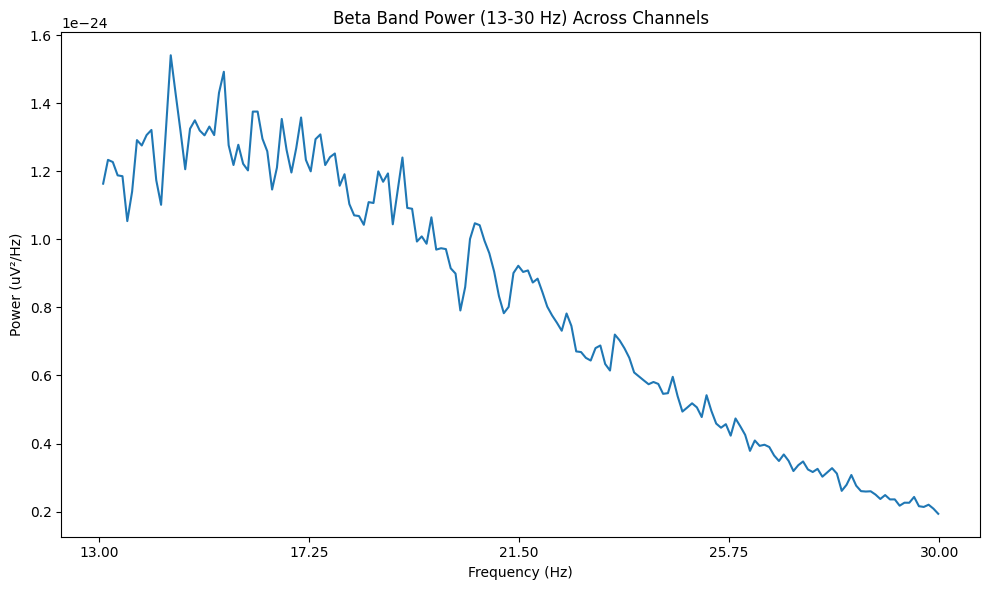

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d36 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d36.head())
print(d36.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d36_clean = d36.replace([np.inf, -np.inf], np.nan)
d36_clean = d36_clean.fillna(d36_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d36_scaled = pd.DataFrame(
    scaler.fit_transform(d36_clean),
    columns=d36_clean.columns,
    index=d36_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d36_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d36_scaled.index,
    columns=d36_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d36_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df36 = d36_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df36["Pd_indicator_meg"] = 0

print("\nShape of df5:", df36.shape)
print(df36.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536 = pd.concat([df12345678101112131415161718192122232425262728293031323335, df36], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536 = df1234567810111213141516171819212223242526272829303132333536.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536):")
print(df1234567810111213141516171819212223242526272829303132333536)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536:", df1234567810111213141516171819212223242526272829303132333536.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1909    3.584071             0.069753          1.037135e-11  1.027286   
1910    3.690265             0.067746          5.898673e-13  0.933492   
1911    3.681416             0.067909          1.048005e-11  0.990068   
1912    3.805310             0.065698          9.195013e-12  1.054022   
1913    3.610619             0.069240          6.135024e-13  1.014668   

      duty_cycle  peak_beta_freq  bur

In [ ]:
df1234567810111213141516171819212223242526272829303132333536.to_csv('/content/drive/MyDrive/combined_features_upto_sub0036_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536 preserved.")


RAM Used After Cleanup: 0.61 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536 preserved.


sub-37

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-37'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-037_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-037_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-037_task-go_run-1_proc-tsss+mc_events.json', 'sub-037_coordsystem.json', 'sub-037_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-037_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-037_task-go_run-1_proc-tsss+mc_meg.json', 'sub-037_task-noise_proc-tsss_channels.tsv', 'sub-037_task-noise_proc-tsss_meg.fif', 'sub-037_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-037_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-037_task-passive_run-1_proc-tsss+mc_events.json', 'sub-037_task-noise_proc-tsss_meg.json', 'sub-037_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-037_task-rest_run-1_proc-tsss+mc_events.json', 'sub-037_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-037_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-037_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-037_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-037_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-037_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-037_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-037_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-037_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-37/meg/sub-037_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-37/meg/sub-037_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 29000 ... 232999 =     29.000 ...   232.999 secs
Ready.
Reading 0 ... 203999  =      0.000 ...   203.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


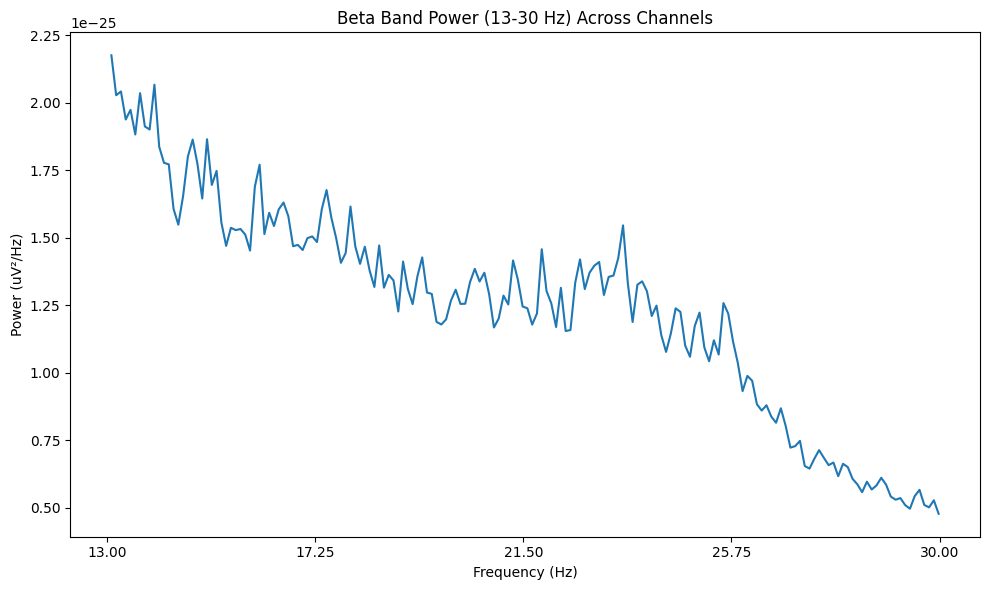

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d37 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d37.head())
print(d37.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d37_clean = d37.replace([np.inf, -np.inf], np.nan)
d37_clean = d37_clean.fillna(d37_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d37_scaled = pd.DataFrame(
    scaler.fit_transform(d37_clean),
    columns=d37_clean.columns,
    index=d37_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d37_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d37_scaled.index,
    columns=d37_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d37_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df37 = d37_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df37["Pd_indicator_meg"] = 1

print("\nShape of df5:", df37.shape)
print(df37.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637 = pd.concat([df1234567810111213141516171819212223242526272829303132333536, df37], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637 = df123456781011121314151617181921222324252627282930313233353637.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637):")
print(df123456781011121314151617181921222324252627282930313233353637)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637:", df123456781011121314151617181921222324252627282930313233353637.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
1967    3.843137             0.065051          4.207510e-12  0.914144   
1968    3.676471             0.068000          2.422211e-13  0.885176   
1969    4.102941             0.060932          4.112543e-12  0.887099   
1970    4.299020             0.058153          3.522269e-12  0.846789   
1971    3.651961             0.068456          2.436459e-13  1.034321   

      duty_cycle  peak_beta_freq  b

In [ ]:
df123456781011121314151617181921222324252627282930313233353637.to_csv('/content/drive/MyDrive/combined_features_upto_sub0037_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637 preserved.")


RAM Used After Cleanup: 0.60 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637 preserved.


sub-38

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-38'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-038_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-038_coordsystem.json', 'sub-038_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-038_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-038_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-038_task-go_run-1_proc-tsss+mc_events.json', 'sub-038_task-go_run-1_proc-tsss+mc_meg.json', 'sub-038_task-noise_proc-tsss_meg.fif', 'sub-038_task-noise_proc-tsss_channels.tsv', 'sub-038_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-038_task-noise_proc-tsss_meg.json', 'sub-038_task-passive_run-1_proc-tsss+mc_events.json', 'sub-038_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-038_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-038_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-038_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-038_task-rest_run-1_proc-tsss+mc_events.json', 'sub-038_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-038_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-038_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-038_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-038_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-038_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-038_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-38/meg/sub-038_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-38/meg/sub-038_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 12000 ... 203999 =     12.000 ...   203.999 secs
Ready.
Reading 0 ... 191999  =      0.000 ...   191.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


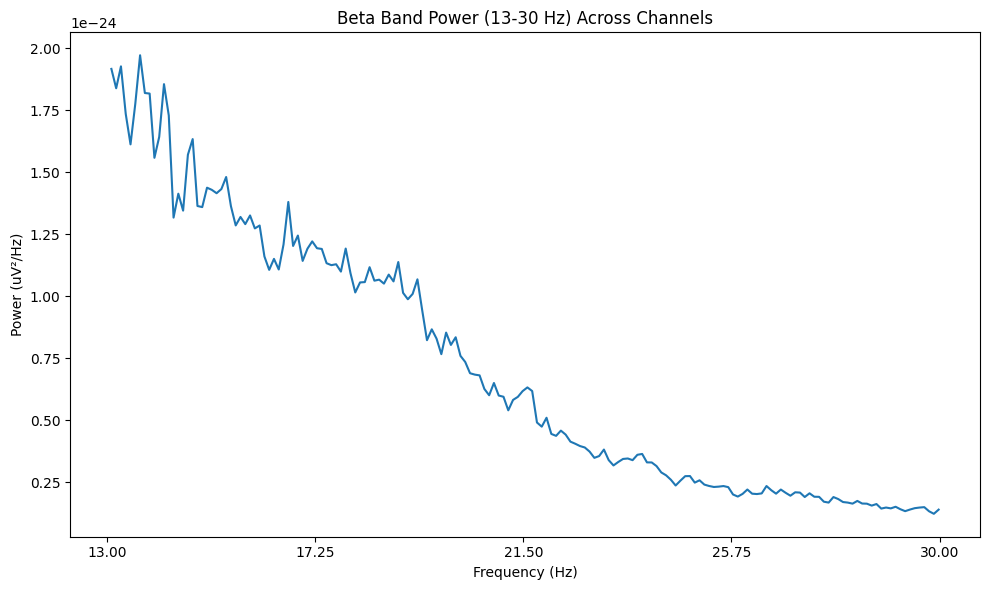

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d38 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d38.head())
print(d38.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d38_clean = d38.replace([np.inf, -np.inf], np.nan)
d38_clean = d38_clean.fillna(d38_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d38_scaled = pd.DataFrame(
    scaler.fit_transform(d38_clean),
    columns=d38_clean.columns,
    index=d38_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d38_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d38_scaled.index,
    columns=d38_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d38_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df38 = d38_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df38["Pd_indicator_meg"] = 0

print("\nShape of df5:", df38.shape)
print(df38.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738 = pd.concat([df123456781011121314151617181921222324252627282930313233353637, df38], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738 = df12345678101112131415161718192122232425262728293031323335363738.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738):")
print(df12345678101112131415161718192122232425262728293031323335363738)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738:", df12345678101112131415161718192122232425262728293031323335363738.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2025    3.687500             0.067797          1.011858e-11  0.910658   
2026    3.682292             0.067893          6.154078e-13  0.825649   
2027    3.656250             0.068376          1.043709e-11  0.869709   
2028    3.494792             0.071535          9.787364e-12  0.843571   
2029    3.572917             0.069971          6.366867e-13  0.870526   

      duty_cycle  peak_beta_freq 

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738.to_csv('/content/drive/MyDrive/combined_features_upto_sub0038_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738 preserved.")


RAM Used After Cleanup: 0.56 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738 preserved.


sub-39

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-39'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-039_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-039_coordsystem.json', 'sub-039_task-go_run-1_proc-tsss+mc_events.json', 'sub-039_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-039_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-039_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-039_task-go_run-1_proc-tsss+mc_meg.json', 'sub-039_task-noise_proc-tsss_channels.tsv', 'sub-039_task-noise_proc-tsss_meg.fif', 'sub-039_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-039_task-noise_proc-tsss_meg.json', 'sub-039_task-passive_run-1_proc-tsss+mc_events.json', 'sub-039_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-039_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-039_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-039_task-rest_run-1_proc-tsss+mc_events.json', 'sub-039_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-039_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-039_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-039_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-039_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-039_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-039_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-039_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-39/meg/sub-039_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-39/meg/sub-039_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 29000 ... 220999 =     29.000 ...   220.999 secs
Ready.
Reading 0 ... 191999  =      0.000 ...   191.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


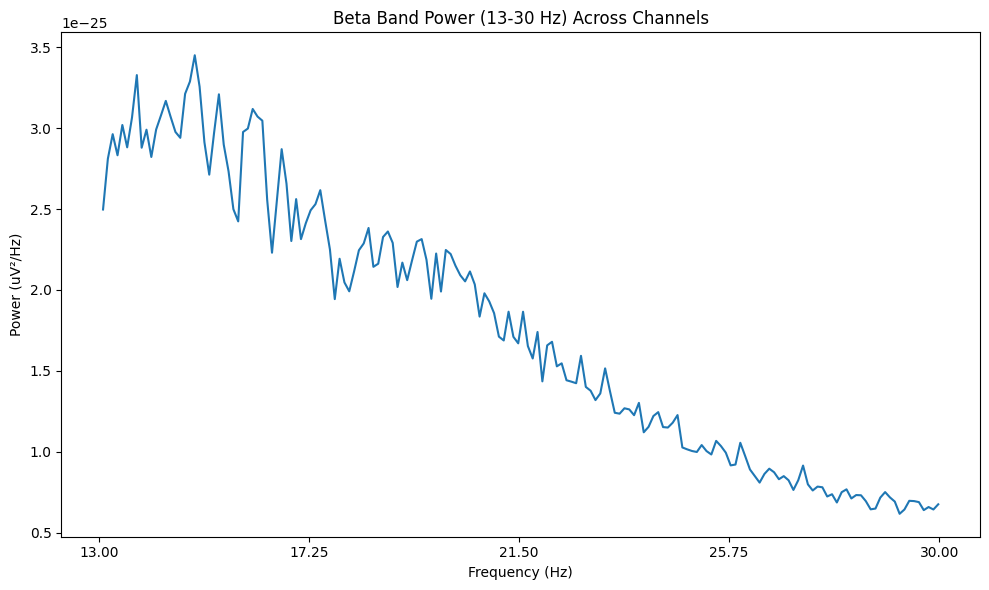

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d39 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d39.head())
print(d39.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d39_clean = d39.replace([np.inf, -np.inf], np.nan)
d39_clean = d39_clean.fillna(d39_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d39_scaled = pd.DataFrame(
    scaler.fit_transform(d39_clean),
    columns=d39_clean.columns,
    index=d39_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d39_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d39_scaled.index,
    columns=d39_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d39_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df39 = d39_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df39["Pd_indicator_meg"] = 0

print("\nShape of df5:", df39.shape)
print(df39.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738, df39], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839 = df1234567810111213141516171819212223242526272829303132333536373839.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839):")
print(df1234567810111213141516171819212223242526272829303132333536373839)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839:", df1234567810111213141516171819212223242526272829303132333536373839.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2083    3.942708             0.063408          4.515241e-12  0.914976   
2084    3.854167             0.064865          2.431432e-13  0.994680   
2085    3.703125             0.067511          5.109158e-12  1.024185   
2086    3.864583             0.064690          4.857106e-12  1.087079   
2087    3.729167             0.067039          2.526049e-13  0.937921   

      duty_cycle  peak_beta_fre

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839.to_csv('/content/drive/MyDrive/combined_features_upto_sub0039_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839 preserved.


sub-40

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-40'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-040_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-040_coordsystem.json', 'sub-040_task-go_run-1_proc-tsss+mc_events.json', 'sub-040_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-040_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-040_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-040_task-go_run-1_proc-tsss+mc_meg.json', 'sub-040_task-noise_proc-tsss_meg.fif', 'sub-040_task-noise_proc-tsss_channels.tsv', 'sub-040_task-passive_run-1_proc-tsss+mc_events.json', 'sub-040_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-040_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-040_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-040_task-noise_proc-tsss_meg.json', 'sub-040_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-040_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-040_task-rest_run-1_proc-tsss+mc_events.json', 'sub-040_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-040_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-040_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-040_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-040_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-040_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-040_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-40/meg/sub-040_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-40/meg/sub-040_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 11000 ... 201999 =     11.000 ...   201.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


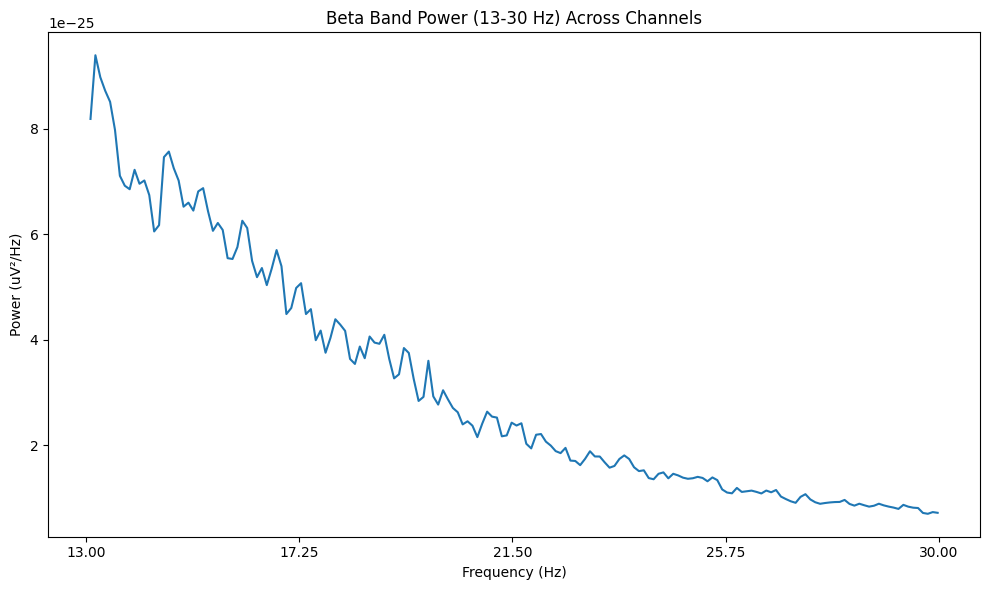

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d40 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d40.head())
print(d40.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d40_clean = d40.replace([np.inf, -np.inf], np.nan)
d40_clean = d40_clean.fillna(d40_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d40_scaled = pd.DataFrame(
    scaler.fit_transform(d40_clean),
    columns=d40_clean.columns,
    index=d40_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d40_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d40_scaled.index,
    columns=d40_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d40_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df40 = d40_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df40["Pd_indicator_meg"] = 1

print("\nShape of df5:", df40.shape)
print(df40.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839, df40], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940 = df123456781011121314151617181921222324252627282930313233353637383940.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940):")
print(df123456781011121314151617181921222324252627282930313233353637383940)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940:", df123456781011121314151617181921222324252627282930313233353637383940.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2141    4.062827             0.061443          3.743106e-12  0.852491   
2142    3.764398             0.066412          2.677651e-13  1.006627   
2143    3.963351             0.062985          4.215954e-12  0.850622   
2144    4.157068             0.060139          3.647762e-12  0.759239   
2145    3.790576             0.065898          2.726297e-13  1.032055   

      duty_cycle  peak_beta_f

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940.to_csv('/content/drive/MyDrive/combined_features_upto_sub0040_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940 preserved.


sub-41

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-41'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-041_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-041_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-041_coordsystem.json', 'sub-041_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-041_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-041_task-go_run-1_proc-tsss+mc_events.json', 'sub-041_task-noise_proc-tsss_meg.fif', 'sub-041_task-go_run-1_proc-tsss+mc_meg.json', 'sub-041_task-noise_proc-tsss_channels.tsv', 'sub-041_task-noise_proc-tsss_meg.json', 'sub-041_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-041_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-041_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-041_task-passive_run-1_proc-tsss+mc_events.json', 'sub-041_task-rest_run-1_proc-tsss+mc_events.json', 'sub-041_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-041_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-041_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-041_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-041_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-041_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-041_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-041_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-041_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-41/meg/sub-041_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-41/meg/sub-041_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 215999 =      7.000 ...   215.999 secs
Ready.
Reading 0 ... 208999  =      0.000 ...   208.999 secs...
Finding events on: STI101
3 events found on stim channel STI101
Event IDs: [1]
Finding events on: STI101
3 events found on stim channel STI101
Event IDs: [1]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitting IC

Computing Power Spectral Density

Effective window size : 10.240 (s)


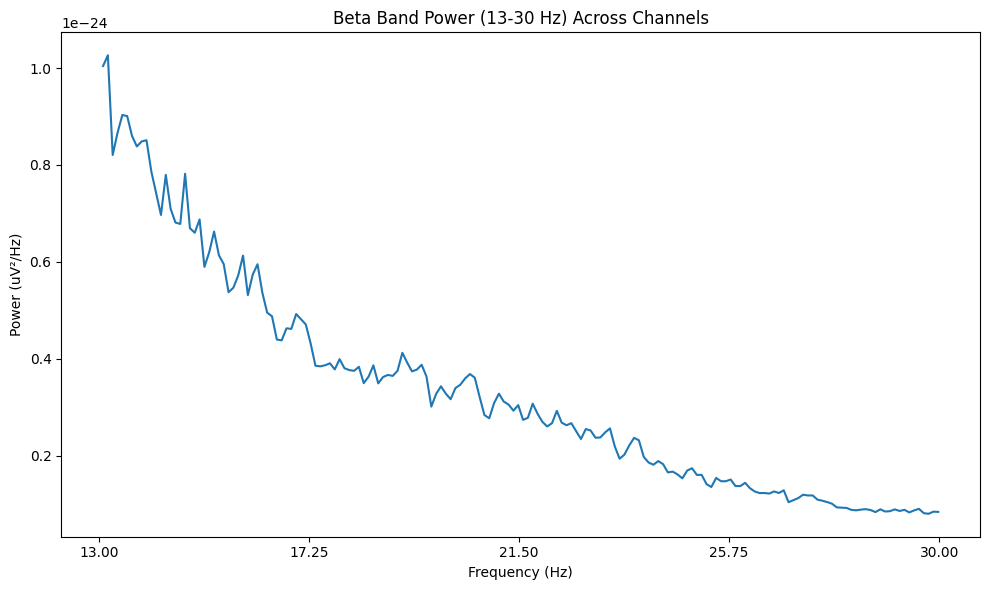

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d41 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d41.head())
print(d41.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d41_clean = d41.replace([np.inf, -np.inf], np.nan)
d41_clean = d41_clean.fillna(d41_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d41_scaled = pd.DataFrame(
    scaler.fit_transform(d41_clean),
    columns=d41_clean.columns,
    index=d41_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d41_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d41_scaled.index,
    columns=d41_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d41_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df41 = d41_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df41["Pd_indicator_meg"] = 1

print("\nShape of df5:", df41.shape)
print(df41.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940, df41], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041 = df12345678101112131415161718192122232425262728293031323335363738394041.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041):")
print(df12345678101112131415161718192122232425262728293031323335363738394041)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041:", df12345678101112131415161718192122232425262728293031323335363738394041.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2199    3.851675             0.064907          5.382681e-12  0.867991   
2200    3.698565             0.067594          3.191168e-13  1.024621   
2201    4.000000             0.062500          5.158289e-12  0.848600   
2202    4.086124             0.061183          4.833964e-12  0.941167   
2203    3.712919             0.067332          3.424587e-13  0.959387   

      duty_cycle  peak_beta

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041.to_csv(
    '/content/drive/MyDrive/combined_features_upto_sub0041_21.csv',
    index=False
)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041 preserved.


sub-42

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-42'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-042_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-042_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-042_coordsystem.json', 'sub-042_task-go_run-1_proc-tsss+mc_events.json', 'sub-042_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-042_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-042_task-go_run-1_proc-tsss+mc_meg.json', 'sub-042_task-noise_proc-tsss_channels.tsv', 'sub-042_task-noise_proc-tsss_meg.fif', 'sub-042_task-noise_proc-tsss_meg.json', 'sub-042_task-passive_run-1_proc-tsss+mc_events.json', 'sub-042_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-042_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-042_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-042_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-042_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-042_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-042_task-rest_run-1_proc-tsss+mc_events.json', 'sub-042_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-042_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-042_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-042_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-042_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-042_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-42/meg/sub-042_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-42/meg/sub-042_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 193999 =      7.000 ...   193.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


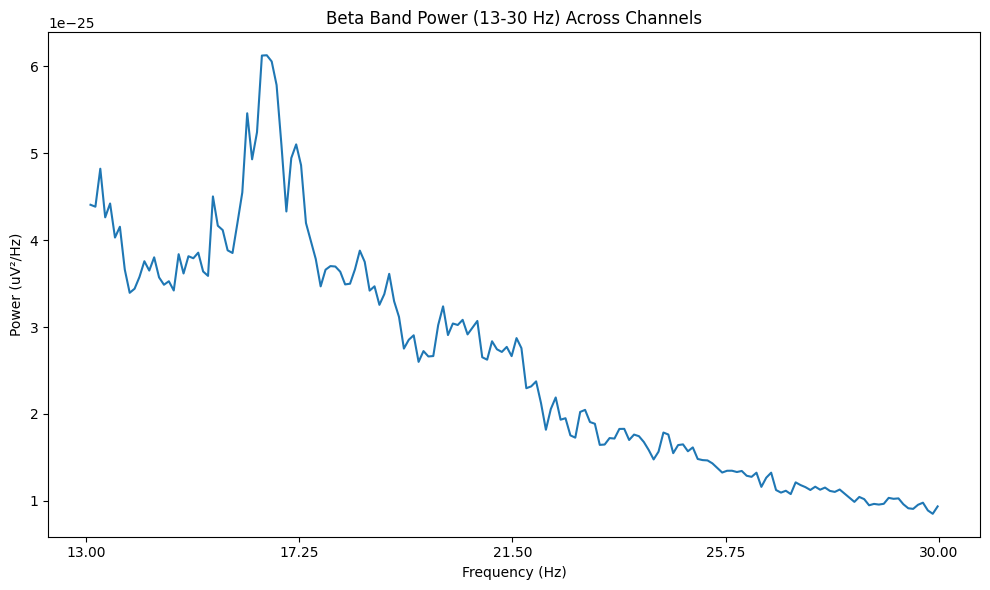

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d42 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d42.head())
print(d42.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d42_clean = d42.replace([np.inf, -np.inf], np.nan)
d42_clean = d42_clean.fillna(d42_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d42_scaled = pd.DataFrame(
    scaler.fit_transform(d42_clean),
    columns=d42_clean.columns,
    index=d42_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d42_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d42_scaled.index,
    columns=d42_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d42_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df42 = d42_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df42["Pd_indicator_meg"] = 1

print("\nShape of df5:", df42.shape)
print(df42.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041, df42], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142 = df1234567810111213141516171819212223242526272829303132333536373839404142.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142:", df1234567810111213141516171819212223242526272829303132333536373839404142.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2257    4.149733             0.060245          5.487242e-12  0.732756   
2258    3.914439             0.063866          3.271075e-13  0.920896   
2259    4.037433             0.061921          6.753114e-12  0.866450   
2260    4.112299             0.060793          6.381919e-12  0.892973   
2261    3.855615             0.064840          3.379922e-13  0.972326   

      duty_cycle  peak_be

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142.to_csv('/content/drive/MyDrive/combined_features_upto_sub0042_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142 preserved.


sub-43

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-43'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-043_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-043_task-go_run-1_proc-tsss+mc_events.json', 'sub-043_coordsystem.json', 'sub-043_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-043_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-043_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-043_task-noise_proc-tsss_channels.tsv', 'sub-043_task-noise_proc-tsss_meg.fif', 'sub-043_task-go_run-1_proc-tsss+mc_meg.json', 'sub-043_task-passive_run-1_proc-tsss+mc_events.json', 'sub-043_task-noise_proc-tsss_meg.json', 'sub-043_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-043_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-043_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-043_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-043_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-043_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-043_task-rest_run-1_proc-tsss+mc_events.json', 'sub-043_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-043_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-043_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-043_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-043_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-043_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-43/meg/sub-043_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-43/meg/sub-043_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 204999 =     18.000 ...   204.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


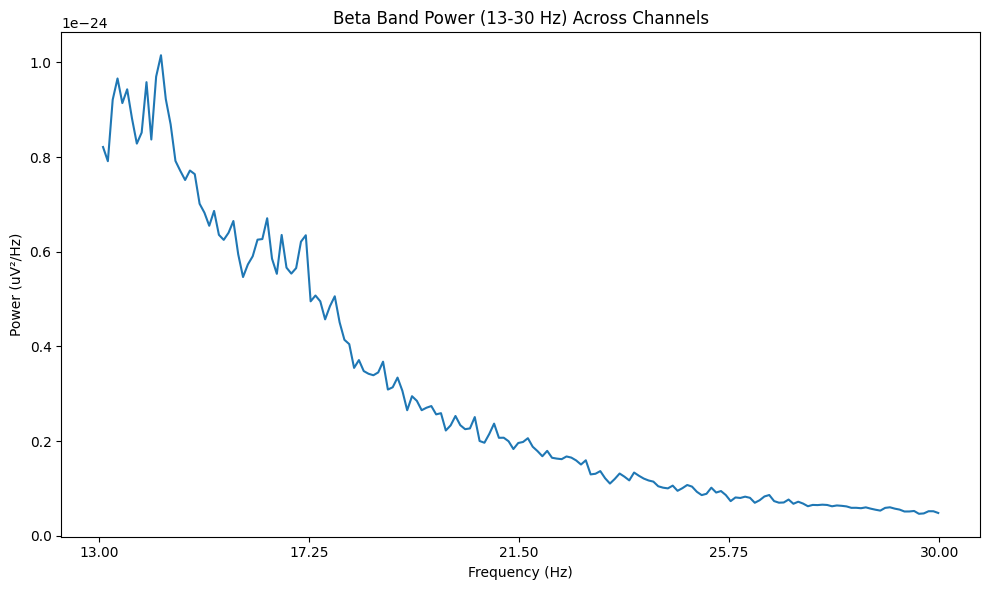

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d43 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d43.head())
print(d43.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d43_clean = d43.replace([np.inf, -np.inf], np.nan)
d43_clean = d43_clean.fillna(d43_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d43_scaled = pd.DataFrame(
    scaler.fit_transform(d43_clean),
    columns=d43_clean.columns,
    index=d43_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d43_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d43_scaled.index,
    columns=d43_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d43_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df43 = d43_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df43["Pd_indicator_meg"] = 1

print("\nShape of df5:", df43.shape)
print(df43.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142, df43], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243 = df123456781011121314151617181921222324252627282930313233353637383940414243.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243:", df123456781011121314151617181921222324252627282930313233353637383940414243.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2315    4.016043             0.062250          2.971805e-12  0.835307   
2316    3.609626             0.069259          2.268963e-13  0.897440   
2317    4.117647             0.060714          3.239176e-12  0.922214   
2318    4.080214             0.061271          2.573886e-12  0.784591   
2319    3.561497             0.070195          2.201856e-13  0.841825   

      duty_cycle  peak_

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243.to_csv('/content/drive/MyDrive/combined_features_upto_sub0043_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243 preserved.


sub-44

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-44'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-044_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-044_coordsystem.json', 'sub-044_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-044_task-go_run-1_proc-tsss+mc_events.json', 'sub-044_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-044_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-044_task-noise_proc-tsss_channels.tsv', 'sub-044_task-noise_proc-tsss_meg.fif', 'sub-044_task-go_run-1_proc-tsss+mc_meg.json', 'sub-044_task-noise_proc-tsss_meg.json', 'sub-044_task-passive_run-1_proc-tsss+mc_events.json', 'sub-044_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-044_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-044_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-044_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-044_task-rest_run-1_proc-tsss+mc_events.json', 'sub-044_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-044_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-044_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-044_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-044_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-044_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-044_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-044_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-44/meg/sub-044_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-44/meg/sub-044_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 30000 ... 216999 =     30.000 ...   216.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


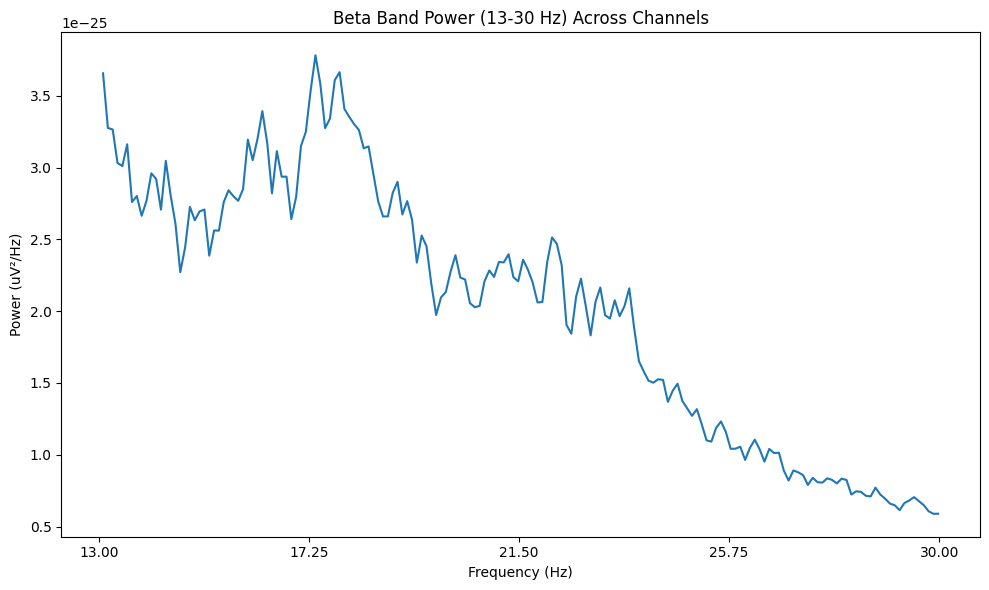

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d44 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d44.head())
print(d44.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d44_clean = d44.replace([np.inf, -np.inf], np.nan)
d44_clean = d44_clean.fillna(d44_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d44_scaled = pd.DataFrame(
    scaler.fit_transform(d44_clean),
    columns=d44_clean.columns,
    index=d44_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d44_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d44_scaled.index,
    columns=d44_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d44_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df44 = d44_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df44["Pd_indicator_meg"] = 0

print("\nShape of df5:", df44.shape)
print(df44.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243, df44], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344 = df12345678101112131415161718192122232425262728293031323335363738394041424344.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344:", df12345678101112131415161718192122232425262728293031323335363738394041424344.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2373    3.737968             0.066881          3.945043e-12  0.743395   
2374    3.588235             0.069672          2.358072e-13  0.787922   
2375    3.807487             0.065660          3.925403e-12  0.749891   
2376    3.508021             0.071265          4.604077e-12  0.802692   
2377    3.336898             0.074920          2.568560e-13  0.869434   

      duty_cycle  pea

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344.to_csv('/content/drive/MyDrive/combined_features_upto_sub0044_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344 preserved.


sub-45

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-45'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-045_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-045_coordsystem.json', 'sub-045_task-go_run-1_proc-tsss+mc_events.json', 'sub-045_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-045_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-045_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-045_task-go_run-1_proc-tsss+mc_meg.json', 'sub-045_task-noise_proc-tsss_channels.tsv', 'sub-045_task-noise_proc-tsss_meg.fif', 'sub-045_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-045_task-noise_proc-tsss_meg.json', 'sub-045_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-045_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-045_task-passive_run-1_proc-tsss+mc_events.json', 'sub-045_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-045_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-045_task-rest_run-1_proc-tsss+mc_events.json', 'sub-045_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-045_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-045_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-045_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-045_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-045_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-045_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-45/meg/sub-045_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-45/meg/sub-045_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 14000 ... 204999 =     14.000 ...   204.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


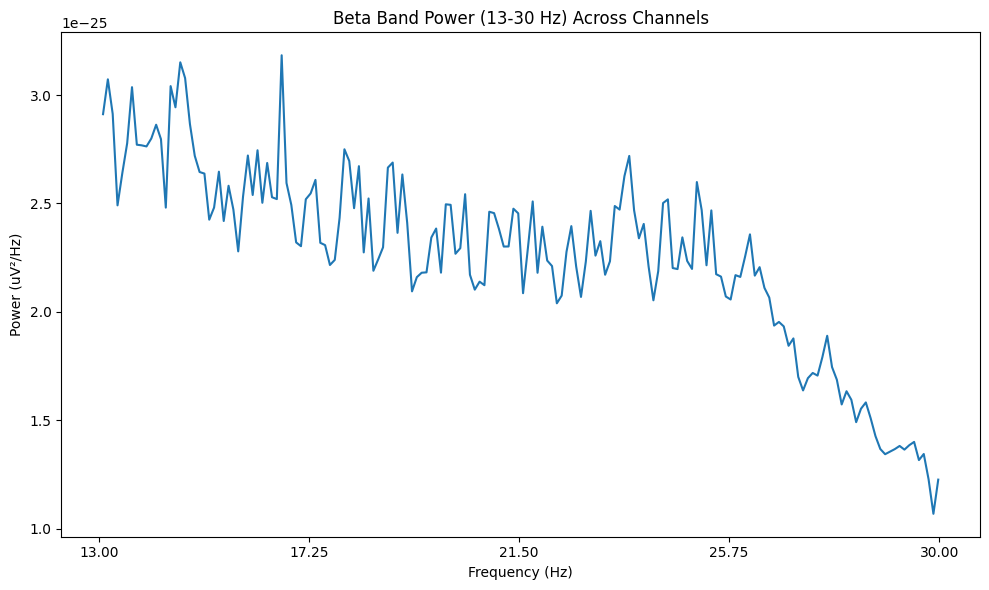

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d45 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d45.head())
print(d45.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d45_clean = d45.replace([np.inf, -np.inf], np.nan)
d45_clean = d45_clean.fillna(d45_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d45_scaled = pd.DataFrame(
    scaler.fit_transform(d45_clean),
    columns=d45_clean.columns,
    index=d45_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d45_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d45_scaled.index,
    columns=d45_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d45_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df45 = d45_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df45["Pd_indicator_meg"] = 1

print("\nShape of df5:", df45.shape)
print(df45.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344, df45], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445 = df1234567810111213141516171819212223242526272829303132333536373839404142434445.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445:", df1234567810111213141516171819212223242526272829303132333536373839404142434445.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2431    3.795812             0.065862          4.459660e-12  1.038405   
2432    3.413613             0.073236          2.899376e-13  1.182479   
2433    3.722513             0.067159          5.066049e-12  1.062542   
2434    3.628272             0.068903          4.811361e-12  1.076435   
2435    3.361257             0.074377          3.041023e-13  1.266351   

      duty_cycle  p

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445.to_csv('/content/drive/MyDrive/combined_features_upto_sub0045_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445 preserved.


sub-46

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-46'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-046_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-046_coordsystem.json', 'sub-046_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-046_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-046_task-go_run-1_proc-tsss+mc_events.json', 'sub-046_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-046_task-noise_proc-tsss_meg.fif', 'sub-046_task-go_run-1_proc-tsss+mc_meg.json', 'sub-046_task-noise_proc-tsss_channels.tsv', 'sub-046_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-046_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-046_task-passive_run-1_proc-tsss+mc_events.json', 'sub-046_task-noise_proc-tsss_meg.json', 'sub-046_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-046_task-rest_run-1_proc-tsss+mc_events.json', 'sub-046_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-046_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-046_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-046_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-046_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-046_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-046_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-046_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-046_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-46/meg/sub-046_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-46/meg/sub-046_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 197999 =      7.000 ...   197.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


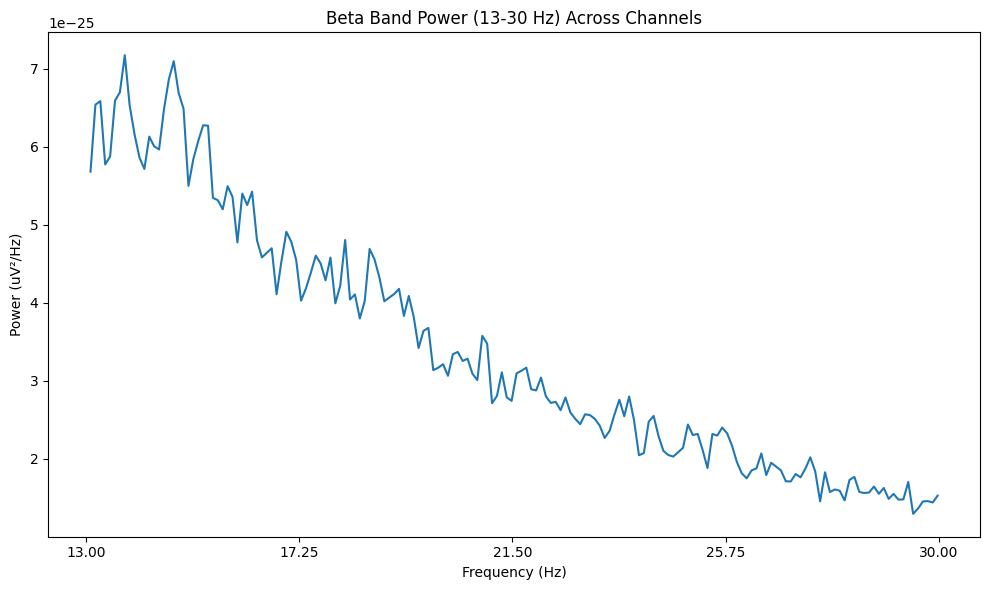

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d46 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d46.head())
print(d46.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d46_clean = d46.replace([np.inf, -np.inf], np.nan)
d46_clean = d46_clean.fillna(d46_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d46_scaled = pd.DataFrame(
    scaler.fit_transform(d46_clean),
    columns=d46_clean.columns,
    index=d46_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d46_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d46_scaled.index,
    columns=d46_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d46_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df46 = d46_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df46["Pd_indicator_meg"] = 1

print("\nShape of df5:", df46.shape)
print(df46.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445, df46], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546 = df123456781011121314151617181921222324252627282930313233353637383940414243444546.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546:", df123456781011121314151617181921222324252627282930313233353637383940414243444546.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2489    3.764398             0.066412          5.740229e-12  0.865731   
2490    3.706806             0.067444          3.223234e-13  1.025770   
2491    3.926702             0.063667          5.620064e-12  0.914298   
2492    3.801047             0.065771          5.110295e-12  0.853151   
2493    3.560209             0.070221          3.231779e-13  0.949012   

      duty_cycle 

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546.to_csv('/content/drive/MyDrive/combined_features_upto_sub0046_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546 preserved.


sub-47

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-47'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-047_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-047_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-047_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-047_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-047_task-go_run-1_proc-tsss+mc_events.json', 'sub-047_coordsystem.json', 'sub-047_task-go_run-1_proc-tsss+mc_meg.json', 'sub-047_task-noise_proc-tsss_meg.fif', 'sub-047_task-noise_proc-tsss_channels.tsv', 'sub-047_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-047_task-passive_run-1_proc-tsss+mc_events.json', 'sub-047_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-047_task-noise_proc-tsss_meg.json', 'sub-047_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-047_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-047_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-047_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-047_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-047_task-rest_run-1_proc-tsss+mc_events.json', 'sub-047_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-047_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-047_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-047_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-047_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-47/meg/sub-047_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-47/meg/sub-047_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 67000 ... 260999 =     67.000 ...   260.999 secs
Ready.
Reading 0 ... 193999  =      0.000 ...   193.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


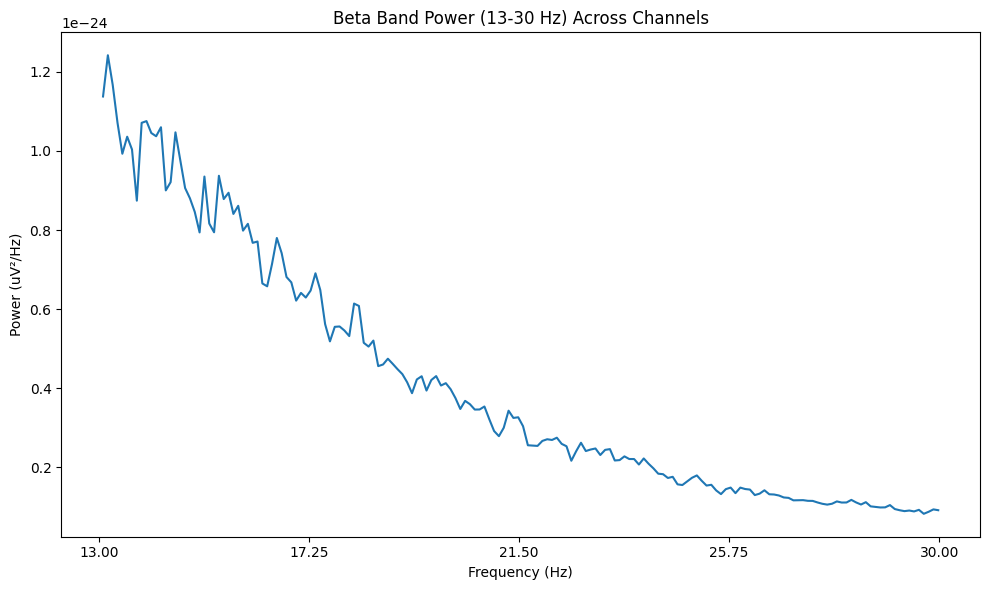

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d47 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d47.head())
print(d47.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d47_clean = d47.replace([np.inf, -np.inf], np.nan)
d47_clean = d47_clean.fillna(d47_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d47_scaled = pd.DataFrame(
    scaler.fit_transform(d47_clean),
    columns=d47_clean.columns,
    index=d47_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d47_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d47_scaled.index,
    columns=d47_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d47_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df47 = d47_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df47["Pd_indicator_meg"] = 0

print("\nShape of df5:", df47.shape)
print(df47.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546, df47], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2547    3.597938             0.069484          6.449750e-12  1.188283   
2548    3.288660             0.076019          4.186151e-13  1.478852   
2549    3.371134             0.074090          8.288171e-12  1.540655   
2550    3.180412             0.078606          8.302765e-12  1.620200   
2551    3.128866             0.079901          4.488546e-13  1.591505   

      duty_cycl

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647.to_csv('/content/drive/MyDrive/combined_features_upto_sub0047_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647 preserved.")


RAM Used After Cleanup: 0.58 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647 preserved.


sub-48

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-48'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-048_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-048_coordsystem.json', 'sub-048_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-048_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-048_task-go_run-1_proc-tsss+mc_events.json', 'sub-048_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-048_task-go_run-1_proc-tsss+mc_meg.json', 'sub-048_task-noise_proc-tsss_meg.fif', 'sub-048_task-noise_proc-tsss_channels.tsv', 'sub-048_task-noise_proc-tsss_meg.json', 'sub-048_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-048_task-passive_run-1_proc-tsss+mc_events.json', 'sub-048_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-048_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-048_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-048_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-048_task-rest_run-1_proc-tsss+mc_events.json', 'sub-048_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-048_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-048_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-048_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-048_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-048_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-048_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-48/meg/sub-048_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-48/meg/sub-048_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 55000 ... 240999 =     55.000 ...   240.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


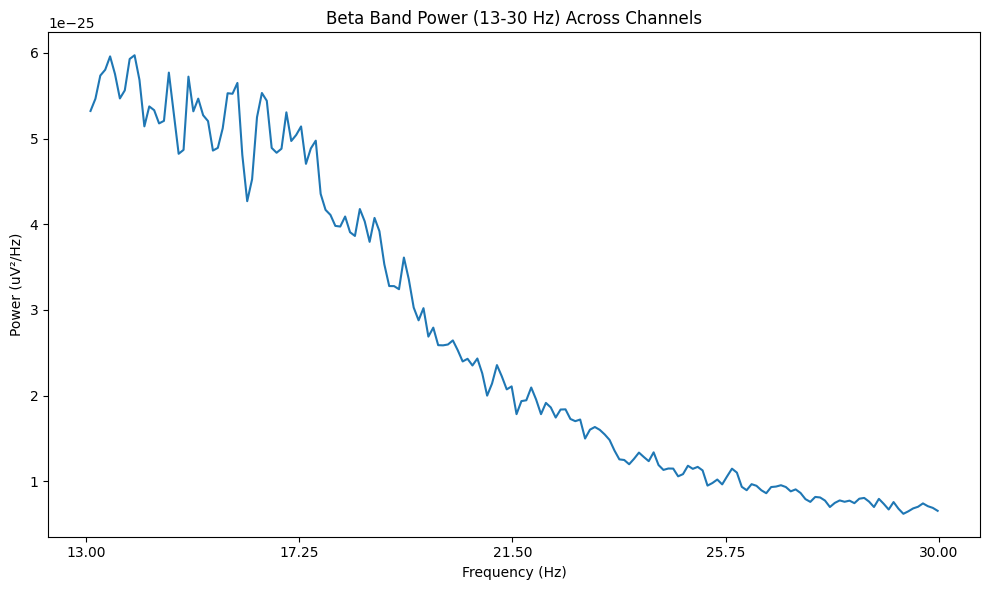

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d48 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d48.head())
print(d48.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d48_clean = d48.replace([np.inf, -np.inf], np.nan)
d48_clean = d48_clean.fillna(d48_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d48_scaled = pd.DataFrame(
    scaler.fit_transform(d48_clean),
    columns=d48_clean.columns,
    index=d48_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d48_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d48_scaled.index,
    columns=d48_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d48_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df48 = d48_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df48["Pd_indicator_meg"] = 0

print("\nShape of df5:", df48.shape)
print(df48.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647, df48], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2605    3.698925             0.067587          6.084050e-12  0.799013   
2606    3.306452             0.075610          3.525265e-13  0.930389   
2607    3.602151             0.069403          6.668070e-12  0.813095   
2608    3.381720             0.073927          7.540065e-12  1.322286   
2609    3.365591             0.074281          3.475309e-13  0.893349   

      duty_cy

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748.to_csv('/content/drive/MyDrive/combined_features_upto_sub0048_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748 preserved.


sub-49

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-49'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-049_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-049_task-go_run-1_proc-tsss+mc_events.json', 'sub-049_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-049_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-049_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-049_coordsystem.json', 'sub-049_task-go_run-1_proc-tsss+mc_meg.json', 'sub-049_task-noise_proc-tsss_channels.tsv', 'sub-049_task-noise_proc-tsss_meg.fif', 'sub-049_task-noise_proc-tsss_meg.json', 'sub-049_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-049_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-049_task-passive_run-1_proc-tsss+mc_events.json', 'sub-049_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-049_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-049_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-049_task-rest_run-1_proc-tsss+mc_events.json', 'sub-049_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-049_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-049_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-049_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-049_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-049_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-049_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-49/meg/sub-049_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-49/meg/sub-049_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 14000 ... 201999 =     14.000 ...   201.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spetral Density

Effective window size : 10.240 (s)


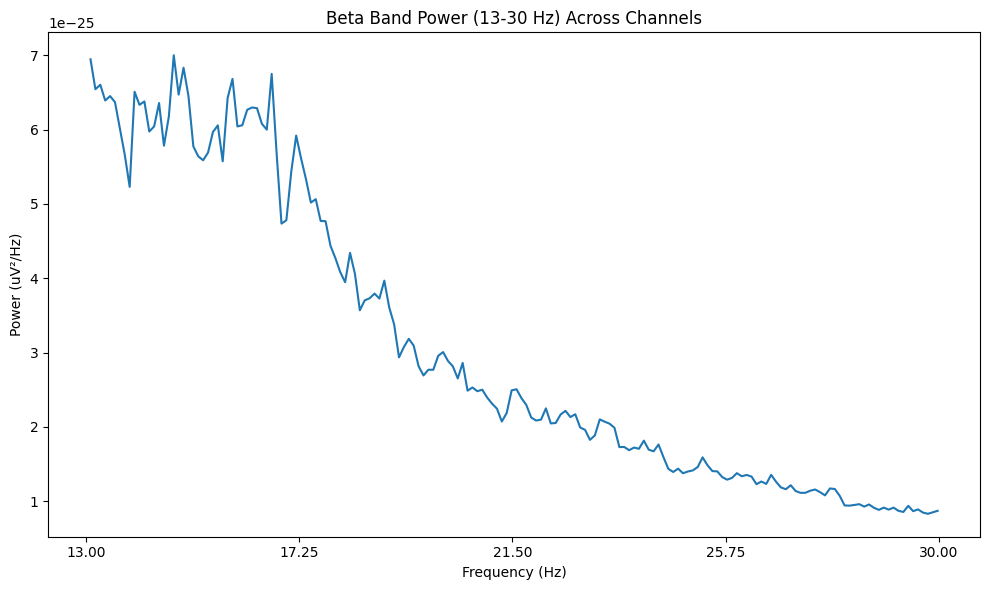

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d49 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d49.head())
print(d49.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d49_clean = d49.replace([np.inf, -np.inf], np.nan)
d49_clean = d49_clean.fillna(d49_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d49_scaled = pd.DataFrame(
    scaler.fit_transform(d49_clean),
    columns=d49_clean.columns,
    index=d49_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d49_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d49_scaled.index,
    columns=d49_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d49_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df49 = d49_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df49["Pd_indicator_meg"] = 1

print("\nShape of df5:", df49.shape)
print(df49.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748, df49], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2663    4.042553             0.061842          3.800081e-12  0.725423   
2664    3.893617             0.064139          2.552164e-13  0.775326   
2665    3.877660             0.064472          4.733705e-12  0.787419   
2666    4.143617             0.060334          4.109435e-12  0.744992   
2667    4.074468             0.061358          2.647979e-13  0.710821   

      duty_

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849.to_csv('/content/drive/MyDrive/combined_features_upto_sub0049_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849 preserved.


sub-50

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-50'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-050_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-050_coordsystem.json', 'sub-050_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-050_task-go_run-1_proc-tsss+mc_events.json', 'sub-050_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-050_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-050_task-go_run-1_proc-tsss+mc_meg.json', 'sub-050_task-noise_proc-tsss_channels.tsv', 'sub-050_task-noise_proc-tsss_meg.fif', 'sub-050_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-050_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-050_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-050_task-passive_run-1_proc-tsss+mc_events.json', 'sub-050_task-noise_proc-tsss_meg.json', 'sub-050_task-rest_run-1_proc-tsss+mc_events.json', 'sub-050_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-050_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-050_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-050_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-050_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-050_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-050_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-050_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-050_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-50/meg/sub-050_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-50/meg/sub-050_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 13000 ... 198999 =     13.000 ...   198.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


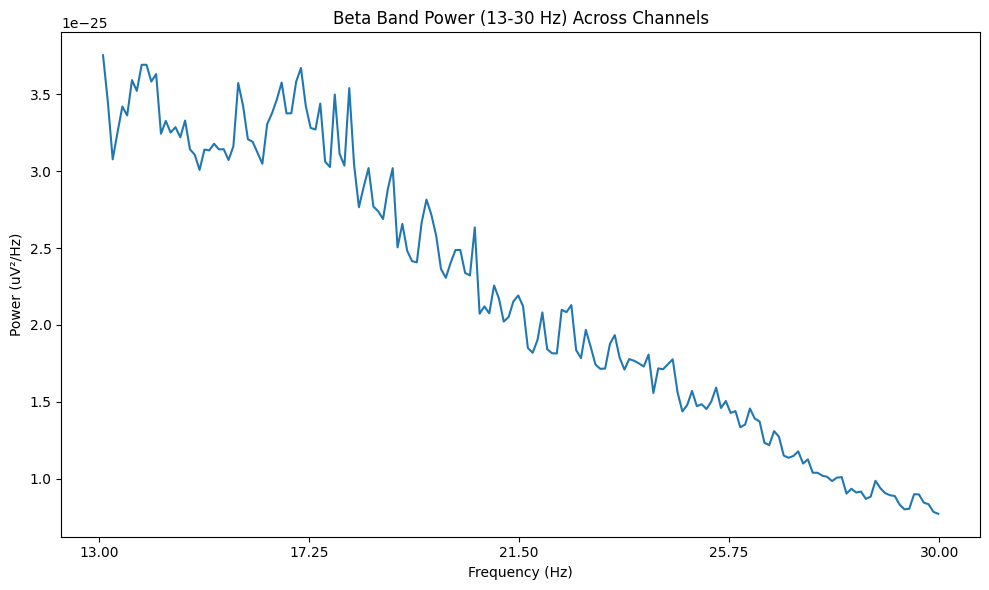

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d50 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d50.head())
print(d50.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d50_clean = d50.replace([np.inf, -np.inf], np.nan)
d50_clean = d50_clean.fillna(d50_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d50_scaled = pd.DataFrame(
    scaler.fit_transform(d50_clean),
    columns=d50_clean.columns,
    index=d50_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d50_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d50_scaled.index,
    columns=d50_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d50_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df50 = d50_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df50["Pd_indicator_meg"] = 0

print("\nShape of df5:", df50.shape)
print(df50.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849, df50], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2721    3.344086             0.074759          6.391209e-12  0.948639   
2722    3.763441             0.066429          2.899036e-13  0.951071   
2723    3.612903             0.069196          6.240157e-12  0.962902   
2724    3.435484             0.072770          5.959814e-12  0.980711   
2725    3.478495             0.071870          2.957953e-13  0.943367   

      dut

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950.to_csv('/content/drive/MyDrive/combined_features_upto_sub0050_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950 preserved.


sub-51

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-51'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-051_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-051_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-051_coordsystem.json', 'sub-051_task-go_run-1_proc-tsss+mc_events.json', 'sub-051_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-051_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-051_task-noise_proc-tsss_meg.fif', 'sub-051_task-noise_proc-tsss_channels.tsv', 'sub-051_task-go_run-1_proc-tsss+mc_meg.json', 'sub-051_task-noise_proc-tsss_meg.json', 'sub-051_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-051_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-051_task-passive_run-1_proc-tsss+mc_events.json', 'sub-051_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-051_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-051_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-051_task-rest_run-1_proc-tsss+mc_events.json', 'sub-051_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-051_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-051_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-051_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-051_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-051_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-051_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-51/meg/sub-051_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-51/meg/sub-051_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 83000 ... 269999 =     83.000 ...   269.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


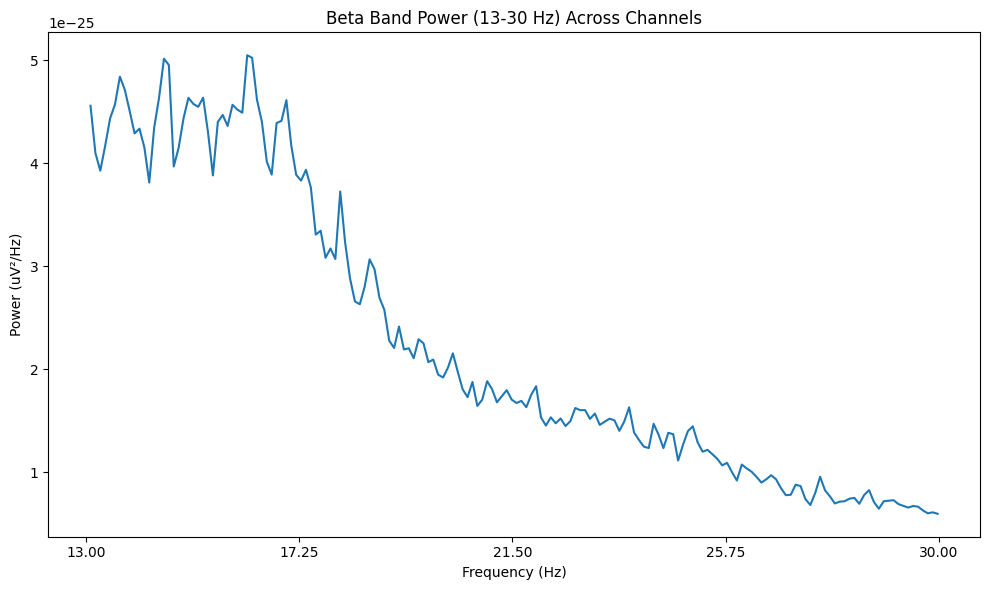

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d51 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d51.head())
print(d51.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d51_clean = d51.replace([np.inf, -np.inf], np.nan)
d51_clean = d51_clean.fillna(d51_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d51_scaled = pd.DataFrame(
    scaler.fit_transform(d51_clean),
    columns=d51_clean.columns,
    index=d51_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d51_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d51_scaled.index,
    columns=d51_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d51_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df51 = d51_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df51["Pd_indicator_meg"] = 1

print("\nShape of df5:", df51.shape)
print(df51.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950, df51], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2779    3.951872             0.063261          5.444068e-12  0.790741   
2780    3.877005             0.064483          3.082807e-13  0.928027   
2781    3.828877             0.065293          5.753047e-12  0.827289   
2782    3.914439             0.063866          5.519633e-12  0.925584   
2783    3.818182             0.065476          3.003104e-13  0.962458   

      d

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051.to_csv('/content/drive/MyDrive/combined_features_upto_sub0051_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051 preserved.


sub-52

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-52'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-052_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-052_coordsystem.json', 'sub-052_task-go_run-1_proc-tsss+mc_events.json', 'sub-052_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-052_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-052_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-052_task-go_run-1_proc-tsss+mc_meg.json', 'sub-052_task-noise_proc-tsss_channels.tsv', 'sub-052_task-noise_proc-tsss_meg.fif', 'sub-052_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-052_task-passive_run-1_proc-tsss+mc_events.json', 'sub-052_task-noise_proc-tsss_meg.json', 'sub-052_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-052_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-052_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-052_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-052_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-052_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-052_task-rest_run-1_proc-tsss+mc_events.json', 'sub-052_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-052_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-052_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-052_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-052_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-52/meg/sub-052_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-52/meg/sub-052_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 197999 =      7.000 ...   197.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


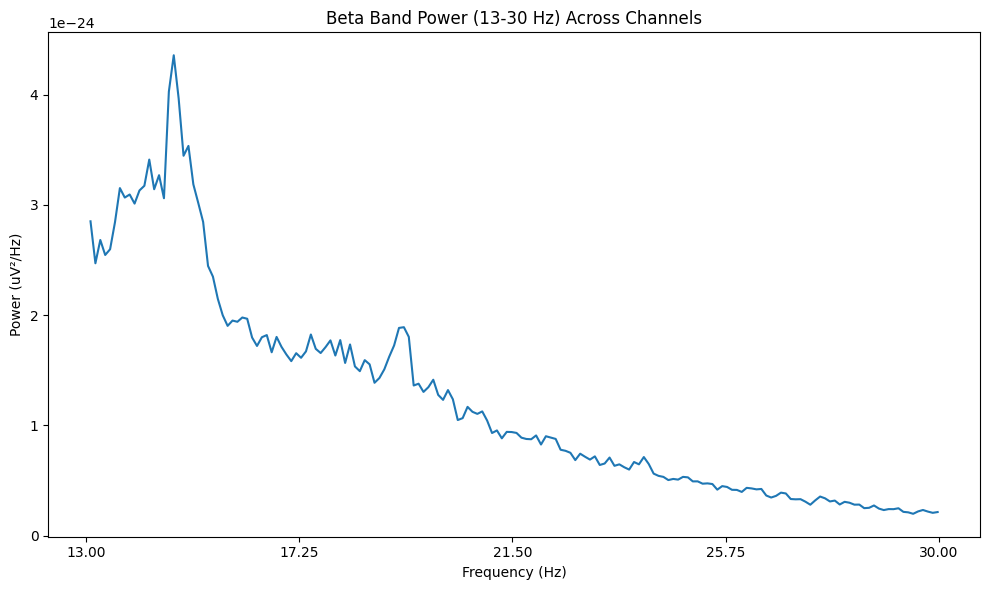

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d52 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d52.head())
print(d52.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d52_clean = d52.replace([np.inf, -np.inf], np.nan)
d52_clean = d52_clean.fillna(d52_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d52_scaled = pd.DataFrame(
    scaler.fit_transform(d52_clean),
    columns=d52_clean.columns,
    index=d52_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d52_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d52_scaled.index,
    columns=d52_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d52_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df52 = d52_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df52["Pd_indicator_meg"] = 1

print("\nShape of df5:", df52.shape)
print(df52.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051, df52], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2837    3.968586             0.062995          1.273315e-11  0.789311   
2838    4.041885             0.061852          7.251218e-13  0.794010   
2839    3.958115             0.063161          1.639892e-11  0.877153   
2840    4.041885             0.061852          1.427070e-11  0.809476   
2841    3.958115             0.063161          7.604903e-13  0.838492   

     

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152.to_csv('/content/drive/MyDrive/combined_features_upto_sub0052_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152 preserved.


sub-53

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-53'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-053_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-053_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-053_task-go_run-1_proc-tsss+mc_events.json', 'sub-053_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-053_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-053_coordsystem.json', 'sub-053_task-go_run-1_proc-tsss+mc_meg.json', 'sub-053_task-noise_proc-tsss_meg.fif', 'sub-053_task-noise_proc-tsss_channels.tsv', 'sub-053_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-053_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-053_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-053_task-passive_run-1_proc-tsss+mc_events.json', 'sub-053_task-noise_proc-tsss_meg.json', 'sub-053_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-053_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-053_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-053_task-rest_run-1_proc-tsss+mc_events.json', 'sub-053_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-053_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-053_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-053_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-053_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-053_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-53/meg/sub-053_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [553]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-53/meg/sub-053_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 209999 =     18.000 ...   209.999 secs
Ready.
Reading 0 ... 191999  =      0.000 ...   191.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing power Spectral Density

Effective window size : 10.240 (s)


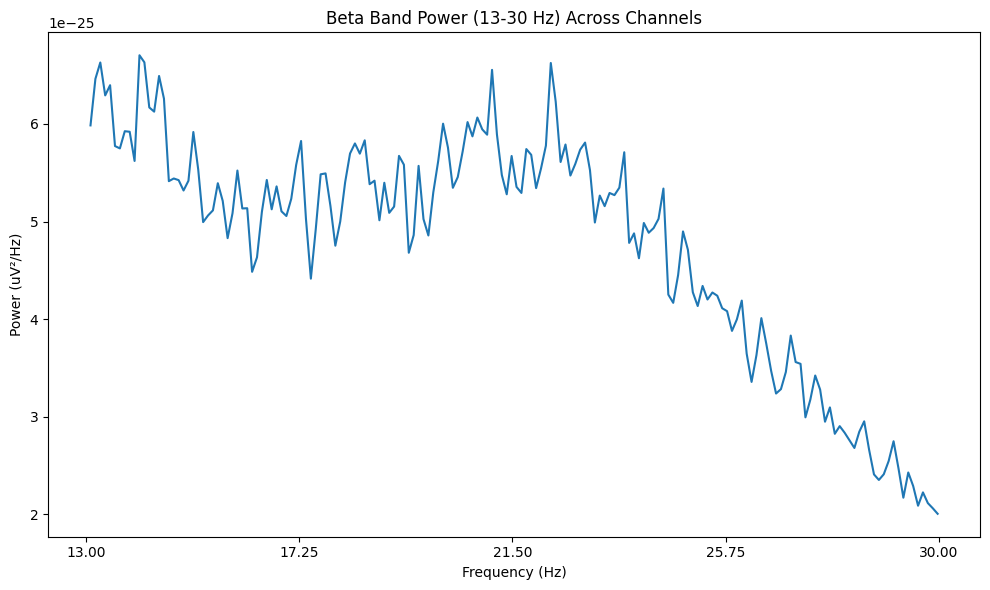

Extracted Beta Band Power (13-30 Hz) successfully.


In [554]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [555]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d53 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d53.head())
print(d53.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [556]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d53_clean = d53.replace([np.inf, -np.inf], np.nan)
d53_clean = d53_clean.fillna(d53_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d53_scaled = pd.DataFrame(
    scaler.fit_transform(d53_clean),
    columns=d53_clean.columns,
    index=d53_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d53_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d53_scaled.index,
    columns=d53_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d53_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df53 = d53_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df53["Pd_indicator_meg"] = 0

print("\nShape of df5:", df53.shape)
print(df53.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [557]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152, df53], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2895    3.838542             0.065129          9.605846e-12  0.873467   
2896    4.052083             0.061697          4.045430e-13  0.863213   
2897    3.984375             0.062745          8.595147e-12  0.887924   
2898    3.765625             0.066390          8.109776e-12  0.907521   
2899    3.989583             0.062663          4.579759e-13  0.904638   

   

In [558]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253.to_csv('/content/drive/MyDrive/combined_features_upto_sub0053_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253 preserved.


sub-54

In [559]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-54'  # Replace with your folder path


In [560]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-054_scans.tsv', 'meg']


In [561]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-054_task-go_run-1_proc-tsss+mc_events.json', 'sub-054_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-054_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-054_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-054_coordsystem.json', 'sub-054_task-noise_proc-tsss_meg.fif', 'sub-054_task-noise_proc-tsss_channels.tsv', 'sub-054_task-go_run-1_proc-tsss+mc_meg.json', 'sub-054_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-054_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-054_task-noise_proc-tsss_meg.json', 'sub-054_task-passive_run-1_proc-tsss+mc_events.json', 'sub-054_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-054_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-054_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-054_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-054_task-rest_run-1_proc-tsss+mc_events.json', 'sub-054_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-054_task-rest_run-1_proc-tsss+mc_meg.json']


In [562]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-054_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-054_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-054_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-054_task-rest_run-1_proc-tsss+mc_meg.fif']


In [563]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-54/meg/sub-054_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [564]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-54/meg/sub-054_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 22000 ... 213999 =     22.000 ...   213.999 secs
Ready.
Reading 0 ... 191999  =      0.000 ...   191.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


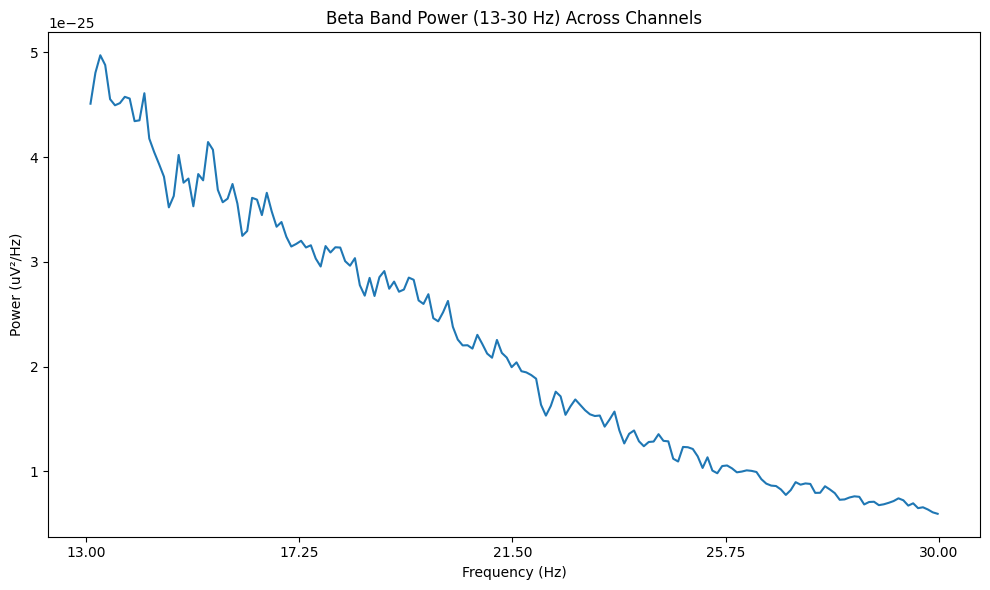

Extracted Beta Band Power (13-30 Hz) successfully.


In [565]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [566]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d54 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d54.head())
print(d54.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [567]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d54_clean = d54.replace([np.inf, -np.inf], np.nan)
d54_clean = d54_clean.fillna(d54_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d54_scaled = pd.DataFrame(
    scaler.fit_transform(d54_clean),
    columns=d54_clean.columns,
    index=d54_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d54_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d54_scaled.index,
    columns=d54_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d54_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df54 = d54_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df54["Pd_indicator_meg"] = 1

print("\nShape of df5:", df54.shape)
print(df54.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [568]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253, df54], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
2953    3.692708             0.067701          4.992909e-12  0.956799   
2954    3.885417             0.064343          2.601728e-13  0.895564   
2955    3.802083             0.065753          4.863775e-12  0.911445   
2956    3.796875             0.065844          5.049543e-12  0.863360   
2957    3.880208             0.064430          2.648358e-13  0.882800   

 

In [569]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354.to_csv('/content/drive/MyDrive/combined_features_upto_sub0054_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354 preserved.


sub-55

In [570]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-55'  # Replace with your folder path


In [571]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-055_scans.tsv', 'meg']


In [572]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-055_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-055_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-055_coordsystem.json', 'sub-055_task-go_run-1_proc-tsss+mc_events.json', 'sub-055_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-055_task-go_run-1_proc-tsss+mc_meg.json', 'sub-055_task-noise_proc-tsss_meg.fif', 'sub-055_task-noise_proc-tsss_channels.tsv', 'sub-055_task-noise_proc-tsss_meg.json', 'sub-055_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-055_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-055_task-passive_run-1_proc-tsss+mc_events.json', 'sub-055_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-055_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-055_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-055_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-055_task-rest_run-1_proc-tsss+mc_events.json', 'sub-055_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-055_task-rest_run-1_proc-tsss+mc_meg.json']


In [573]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-055_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-055_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-055_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-055_task-rest_run-1_proc-tsss+mc_meg.fif']


In [574]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-55/meg/sub-055_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [575]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-55/meg/sub-055_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 19000 ... 202999 =     19.000 ...   202.999 secs
Ready.
Reading 0 ... 183999  =      0.000 ...   183.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


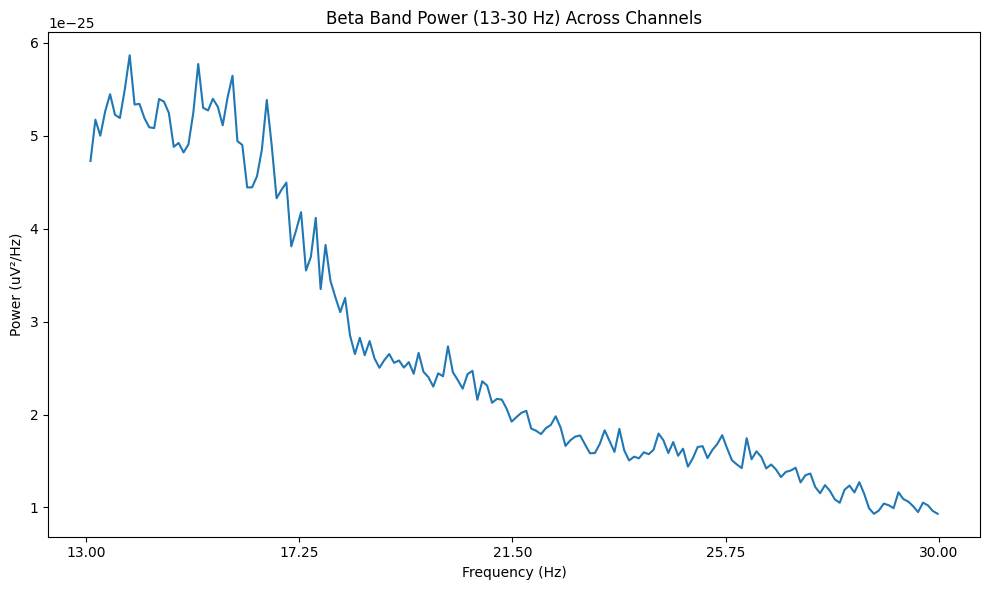

Extracted Beta Band Power (13-30 Hz) successfully.


In [576]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [577]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d55 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d55.head())
print(d55.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [578]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d55_clean = d55.replace([np.inf, -np.inf], np.nan)
d55_clean = d55_clean.fillna(d55_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d55_scaled = pd.DataFrame(
    scaler.fit_transform(d55_clean),
    columns=d55_clean.columns,
    index=d55_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d55_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d55_scaled.index,
    columns=d55_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d55_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df55 = d55_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df55["Pd_indicator_meg"] = 1

print("\nShape of df5:", df55.shape)
print(df55.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [579]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354, df55], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3011    4.304348             0.058081          5.364404e-12  1.066373   
3012    3.956522             0.063187          3.393524e-13  1.432178   
3013    4.092391             0.061089          5.659230e-12  1.029082   
3014    4.364130             0.057285          5.524578e-12  1.204839   
3015    3.929348             0.063624          3.219752e-13  1.174585   


In [580]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455.to_csv('/content/drive/MyDrive/combined_features_upto_sub0055_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455 preserved.


sub-56

In [581]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-56'  # Replace with your folder path


In [582]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-056_scans.tsv', 'meg']


In [583]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-056_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-056_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-056_coordsystem.json', 'sub-056_task-go_run-1_proc-tsss+mc_events.json', 'sub-056_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-056_task-noise_proc-tsss_channels.tsv', 'sub-056_task-go_run-1_proc-tsss+mc_meg.json', 'sub-056_task-noise_proc-tsss_meg.fif', 'sub-056_task-noise_proc-tsss_meg.json', 'sub-056_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-056_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-056_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-056_task-passive_run-1_proc-tsss+mc_events.json', 'sub-056_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-056_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-056_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-056_task-rest_run-1_proc-tsss+mc_events.json', 'sub-056_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-056_task-rest_run-1_proc-tsss+mc_meg.json']


In [584]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-056_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-056_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-056_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-056_task-rest_run-1_proc-tsss+mc_meg.fif']


In [585]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-56/meg/sub-056_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [586]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-56/meg/sub-056_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 12000 ... 220999 =     12.000 ...   220.999 secs
Ready.
Reading 0 ... 208999  =      0.000 ...   208.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


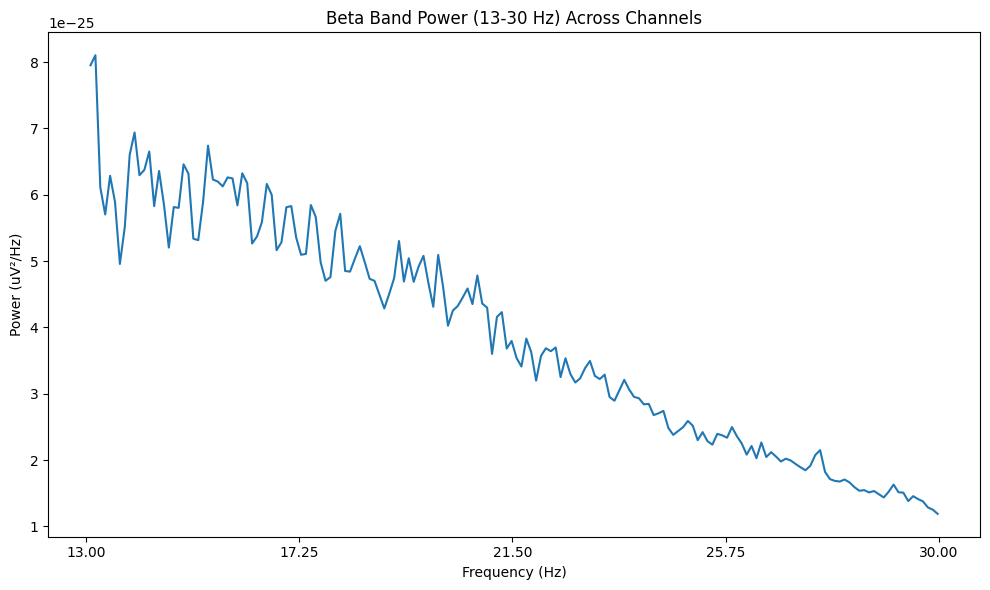

Extracted Beta Band Power (13-30 Hz) successfully.


In [587]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [588]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d56 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d56.head())
print(d56.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [589]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d56_clean = d56.replace([np.inf, -np.inf], np.nan)
d56_clean = d56_clean.fillna(d56_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d56_scaled = pd.DataFrame(
    scaler.fit_transform(d56_clean),
    columns=d56_clean.columns,
    index=d56_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d56_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d56_scaled.index,
    columns=d56_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d56_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df56 = d56_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df56["Pd_indicator_meg"] = 1

print("\nShape of df5:", df56.shape)
print(df56.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [590]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455, df56], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3069    3.650718             0.068480          6.930937e-12  1.087786   
3070    3.416268             0.073179          3.963116e-13  1.135998   
3071    3.555024             0.070323          7.599891e-12  1.113220   
3072    3.583732             0.069760          6.730875e-12  1.131334   
3073    3.306220             0.075615          4.271186e-13  1.288195  

In [591]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556.to_csv('/content/drive/MyDrive/combined_features_upto_sub0056_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556 preserved.


sub-57

In [592]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-57'  # Replace with your folder path


In [593]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-057_scans.tsv', 'meg']


In [594]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-057_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-057_task-noise_proc-tsss_meg.fif', 'sub-057_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-057_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-057_task-go_run-1_proc-tsss+mc_events.json', 'sub-057_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-057_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-057_task-noise_proc-tsss_meg.json', 'sub-057_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-057_task-passive_run-1_proc-tsss+mc_events.json', 'sub-057_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-057_task-noise_proc-tsss_channels.tsv', 'sub-057_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-057_coordsystem.json', 'sub-057_task-rest_run-1_proc-tsss+mc_events.json', 'sub-057_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-057_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-057_task-go_run-1_proc-tsss+mc_meg.json', 'sub-057_task-passive_run-1_proc-tsss+mc_channels.tsv']


In [595]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-057_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-057_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-057_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-057_task-rest_run-1_proc-tsss+mc_meg.fif']


In [596]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-57/meg/sub-057_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [597]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-57/meg/sub-057_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 207999 =     18.000 ...   207.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


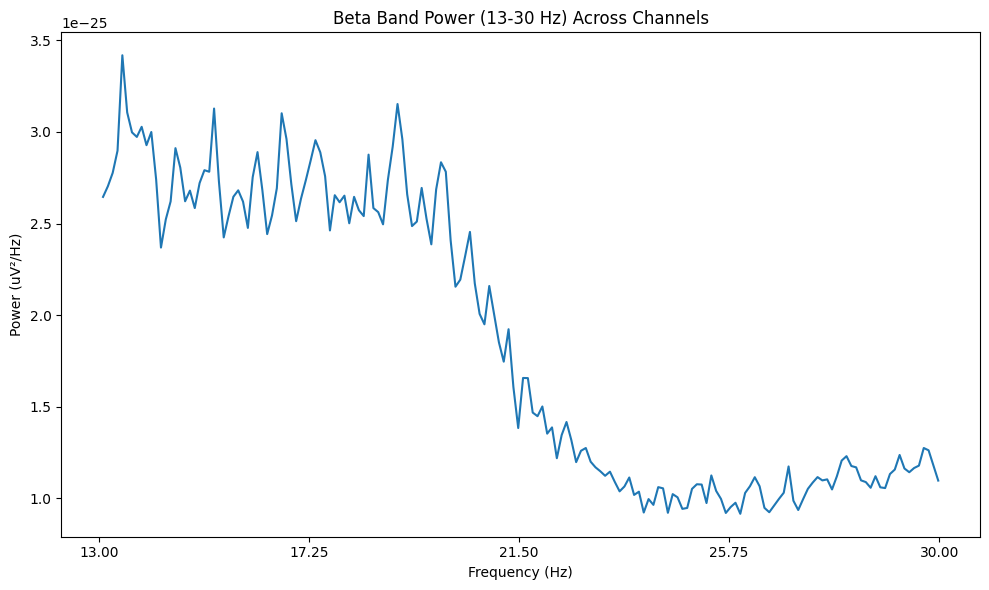

Extracted Beta Band Power (13-30 Hz) successfully.


In [598]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [599]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d57 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d57.head())
print(d57.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [600]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d57_clean = d57.replace([np.inf, -np.inf], np.nan)
d57_clean = d57_clean.fillna(d57_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d57_scaled = pd.DataFrame(
    scaler.fit_transform(d57_clean),
    columns=d57_clean.columns,
    index=d57_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d57_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d57_scaled.index,
    columns=d57_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d57_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df57 = d57_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df57["Pd_indicator_meg"] = 0

print("\nShape of df5:", df57.shape)
print(df57.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [601]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556, df57], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3127    4.657895             0.053672          3.731063e-12  0.920403   
3128    4.478947             0.055817          2.226081e-13  0.995142   
3129    4.494737             0.055621          4.695410e-12  0.934301   
3130    4.057895             0.061608          4.320716e-12  1.004542   
3131    4.789474             0.052198          2.125561e-13  0.881387

In [602]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657.to_csv('/content/drive/MyDrive/combined_features_upto_sub0057_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657 preserved.")


RAM Used After Cleanup: 0.64 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657 preserved.


sub-58

In [603]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-58'  # Replace with your folder paths

In [604]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['meg', 'sub-058_scans.tsv']


In [605]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-058_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-058_task-noise_proc-tsss_meg.fif', 'sub-058_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-058_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-058_coordsystem.json', 'sub-058_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-058_task-go_run-1_proc-tsss+mc_meg.json', 'sub-058_task-passive_run-1_proc-tsss+mc_events.json', 'sub-058_task-noise_proc-tsss_meg.json', 'sub-058_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-058_task-noise_proc-tsss_channels.tsv', 'sub-058_task-rest_run-1_proc-tsss+mc_events.json', 'sub-058_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-058_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-058_task-go_run-1_proc-tsss+mc_events.json', 'sub-058_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-058_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-058_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-058_task-go_run-1_proc-tsss+mc_events.tsv']


In [606]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-058_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-058_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-058_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-058_task-rest_run-1_proc-tsss+mc_meg.fif']


In [607]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-58/meg/sub-058_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [608]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-58/meg/sub-058_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 15000 ... 203999 =     15.000 ...   203.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


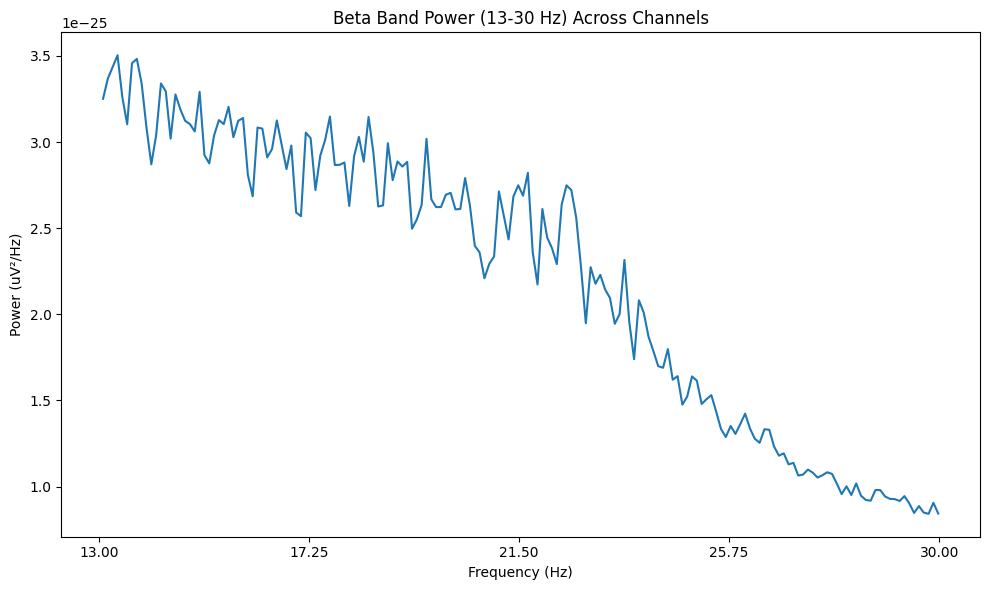

Extracted Beta Band Power (13-30 Hz) successfully.


In [609]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [610]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d58 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d58.head())
print(d58.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [612]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d58_clean = d58.replace([np.inf, -np.inf], np.nan)
d58_clean = d58_clean.fillna(d58_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d58_scaled = pd.DataFrame(
    scaler.fit_transform(d58_clean),
    columns=d58_clean.columns,
    index=d58_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d58_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d58_scaled.index,
    columns=d58_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d58_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df58 = d58_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df58["Pd_indicator_meg"] = 0

print("\nShape of df5:", df58.shape)
print(df58.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [613]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657, df58], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3185    4.068783             0.061443          2.710378e-12  0.776980   
3186    3.592593             0.069588          2.056419e-13  0.822952   
3187    4.100529             0.060968          2.782770e-12  0.774235   
3188    3.788360             0.065992          3.083987e-12  0.885466   
3189    3.603175             0.069383          1.981210e-13  0.9225

In [614]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758.to_csv('/content/drive/MyDrive/combined_features_upto_sub0058_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758 preserved.")


RAM Used After Cleanup: 0.64 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758 preserved.


sub-59

In [615]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-59'  # Replace with your folder path


In [616]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-059_scans.tsv', 'meg']


In [617]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-059_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-059_task-go_run-1_proc-tsss+mc_events.json', 'sub-059_coordsystem.json', 'sub-059_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-059_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-059_task-noise_proc-tsss_meg.fif', 'sub-059_task-noise_proc-tsss_channels.tsv', 'sub-059_task-go_run-1_proc-tsss+mc_meg.json', 'sub-059_task-passive_run-1_proc-tsss+mc_events.json', 'sub-059_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-059_task-noise_proc-tsss_meg.json', 'sub-059_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-059_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-059_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-059_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-059_task-rest_run-1_proc-tsss+mc_events.json', 'sub-059_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-059_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-059_task-rest_run-1_proc-tsss+mc_meg.json']


In [618]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-059_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-059_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-059_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-059_task-rest_run-1_proc-tsss+mc_meg.fif']


In [619]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-59/meg/sub-059_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [620]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-59/meg/sub-059_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 48000 ... 232999 =     48.000 ...   232.999 secs
Ready.
Reading 0 ... 184999  =      0.000 ...   184.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


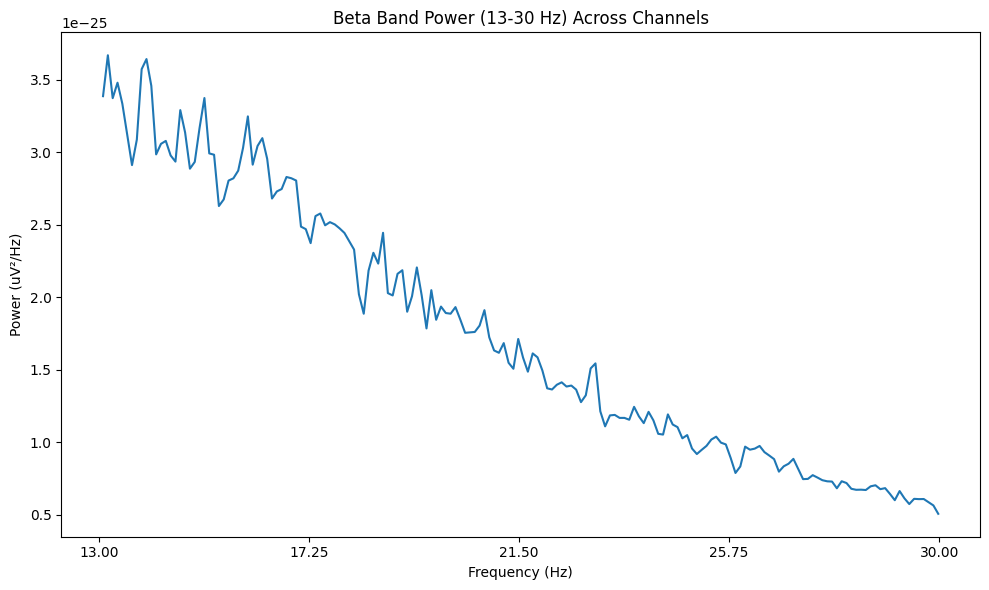

Extracted Beta Band Power (13-30 Hz) successfully.


In [621]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [622]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d59 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d59.head())
print(d59.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [623]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d59_clean = d59.replace([np.inf, -np.inf], np.nan)
d59_clean = d59_clean.fillna(d59_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d59_scaled = pd.DataFrame(
    scaler.fit_transform(d59_clean),
    columns=d59_clean.columns,
    index=d59_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d59_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d59_scaled.index,
    columns=d59_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d59_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df59 = d59_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df59["Pd_indicator_meg"] = 0

print("\nShape of df5:", df59.shape)
print(df59.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [624]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758, df59], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3243    3.724324             0.067126          4.439784e-12  0.946976   
3244    3.481081             0.071817          2.651288e-13  1.140000   
3245    3.567568             0.070076          5.346942e-12  1.097355   
3246    3.335135             0.074959          5.301864e-12  1.231677   
3247    3.486486             0.071705          2.629539e-13  1.06

In [625]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859.to_csv('/content/drive/MyDrive/combined_features_upto_sub0059_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859 preserved.


sub-60

In [626]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-60'  # Replace with your folder path


In [627]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-060_scans.tsv', 'meg']


In [628]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-060_coordsystem.json', 'sub-060_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-060_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-060_task-go_run-1_proc-tsss+mc_events.json', 'sub-060_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-060_task-noise_proc-tsss_channels.tsv', 'sub-060_task-go_run-1_proc-tsss+mc_meg.json', 'sub-060_task-noise_proc-tsss_meg.fif', 'sub-060_task-noise_proc-tsss_meg.json', 'sub-060_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-060_task-passive_run-1_proc-tsss+mc_events.json', 'sub-060_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-060_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-060_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-060_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-060_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-060_task-rest_run-1_proc-tsss+mc_events.json', 'sub-060_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-060_task-rest_run-1_proc-tsss+mc_meg.json']


In [629]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-060_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-060_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-060_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-060_task-rest_run-1_proc-tsss+mc_meg.fif']


In [630]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-60/meg/sub-060_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [631]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-60/meg/sub-060_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 102000 ... 287999 =    102.000 ...   287.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


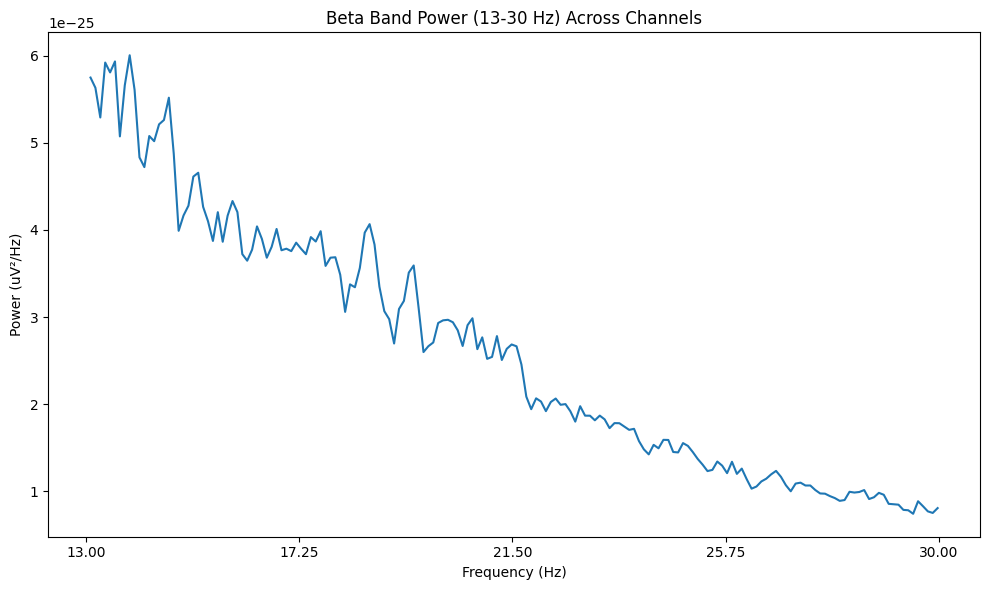

Extracted Beta Band Power (13-30 Hz) successfully.


In [632]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [633]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d60 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d60.head())
print(d60.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [634]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d60_clean = d60.replace([np.inf, -np.inf], np.nan)
d60_clean = d60_clean.fillna(d60_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d60_scaled = pd.DataFrame(
    scaler.fit_transform(d60_clean),
    columns=d60_clean.columns,
    index=d60_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d60_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d60_scaled.index,
    columns=d60_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d60_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df60 = d60_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df60["Pd_indicator_meg"] = 1

print("\nShape of df5:", df60.shape)
print(df60.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [635]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859, df60], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3301    4.413978             0.056638          2.960163e-12  0.763722   
3302    4.123656             0.060626          2.215254e-13  0.808359   
3303    4.236559             0.059010          3.583113e-12  0.845040   
3304    4.161290             0.060078          4.031050e-12  0.845003   
3305    4.263441             0.058638          2.162782e-13  0.

In [636]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960.to_csv('/content/drive/MyDrive/combined_features_upto_sub0060_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960 preserved.


sub-61

In [637]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-61'  # Replace with your folder path


In [638]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-061_scans.tsv', 'meg']


In [639]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-061_coordsystem.json', 'sub-061_task-go_run-1_proc-tsss+mc_events.json', 'sub-061_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-061_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-061_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-061_task-noise_proc-tsss_meg.fif', 'sub-061_task-go_run-1_proc-tsss+mc_meg.json', 'sub-061_task-noise_proc-tsss_channels.tsv', 'sub-061_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-061_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-061_task-passive_run-1_proc-tsss+mc_events.json', 'sub-061_task-noise_proc-tsss_meg.json', 'sub-061_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-061_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-061_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-061_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-061_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-061_task-rest_run-1_proc-tsss+mc_events.json', 'sub-061_task-rest_run-1_proc-tsss+mc_meg.json']


In [640]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-061_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-061_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-061_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-061_task-rest_run-1_proc-tsss+mc_meg.fif']


In [641]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-61/meg/sub-061_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [642]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-61/meg/sub-061_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 29000 ... 218999 =     29.000 ...   218.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


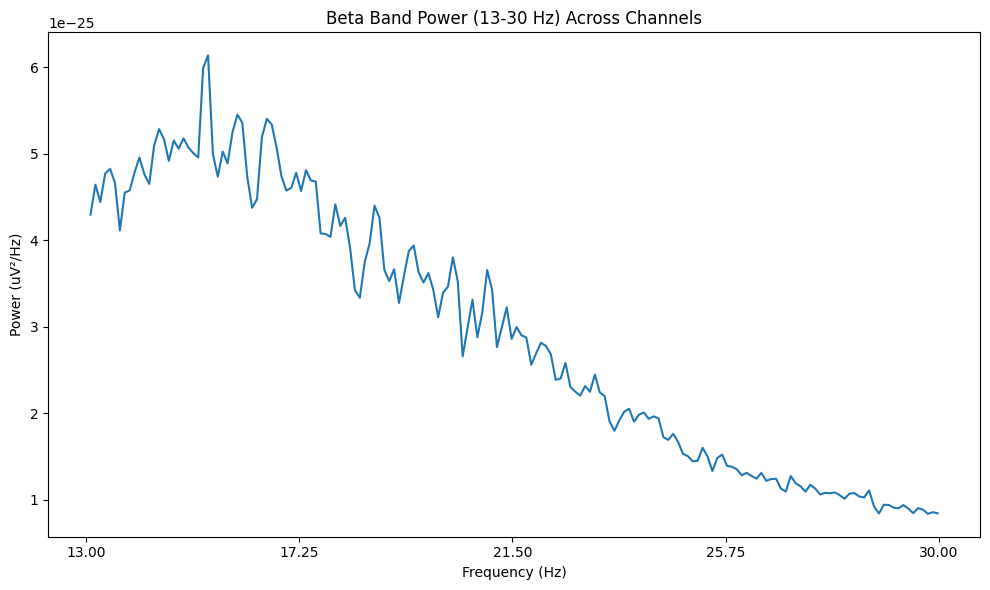

Extracted Beta Band Power (13-30 Hz) successfully.


In [643]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [644]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d61 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d61.head())
print(d61.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [645]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d61_clean = d61.replace([np.inf, -np.inf], np.nan)
d61_clean = d61_clean.fillna(d61_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d61_scaled = pd.DataFrame(
    scaler.fit_transform(d61_clean),
    columns=d61_clean.columns,
    index=d61_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d61_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d61_scaled.index,
    columns=d61_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d61_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df61 = d61_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df61["Pd_indicator_meg"] = 0

print("\nShape of df5:", df61.shape)
print(df61.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [646]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960, df61], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3359    3.815789             0.065517          3.794168e-12  0.855104   
3360    2.810526             0.088951          3.582542e-13  1.041934   
3361    3.463158             0.072188          4.969184e-12  0.822350   
3362    3.515789             0.071108          4.794377e-12  0.949902   
3363    2.863158             0.087316          3.424027e-13  

In [647]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061.to_csv('/content/drive/MyDrive/combined_features_upto_sub0061_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061 preserved.


sub-63

In [648]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-63'  # Replace with your folder path


In [649]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-063_scans.tsv', 'meg']


In [650]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-063_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-063_coordsystem.json', 'sub-063_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-063_task-go_run-1_proc-tsss+mc_events.json', 'sub-063_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-063_task-go_run-1_proc-tsss+mc_meg.json', 'sub-063_task-noise_proc-tsss_channels.tsv', 'sub-063_task-noise_proc-tsss_meg.fif', 'sub-063_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-063_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-063_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-063_task-noise_proc-tsss_meg.json', 'sub-063_task-passive_run-1_proc-tsss+mc_events.json', 'sub-063_task-rest_run-1_proc-tsss+mc_events.json', 'sub-063_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-063_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-063_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-063_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-063_task-rest_run-1_proc-tsss+mc_meg.json']


In [651]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-063_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-063_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-063_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-063_task-rest_run-1_proc-tsss+mc_meg.fif']


In [652]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-63/meg/sub-063_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [653]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-63/meg/sub-063_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 32000 ... 215999 =     32.000 ...   215.999 secs
Ready.
Reading 0 ... 183999  =      0.000 ...   183.999 secs...
Finding events on: STI101
Trigger channel STI101 has a non-zero initial value of 14592 (consider using initial_event=True to detect this event)
2 events found on stim channel STI101
Event IDs: [14593 14656]
Finding events on: STI101
Trigger channel STI101 has a non-zero initial value of 14592 (consider using initial_event=True to detect this event)
2 events found on stim channel STI101
Event IDs: [14593 14656]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.0

Computing Power Spectral Density

Effective window size : 10.240 (s)


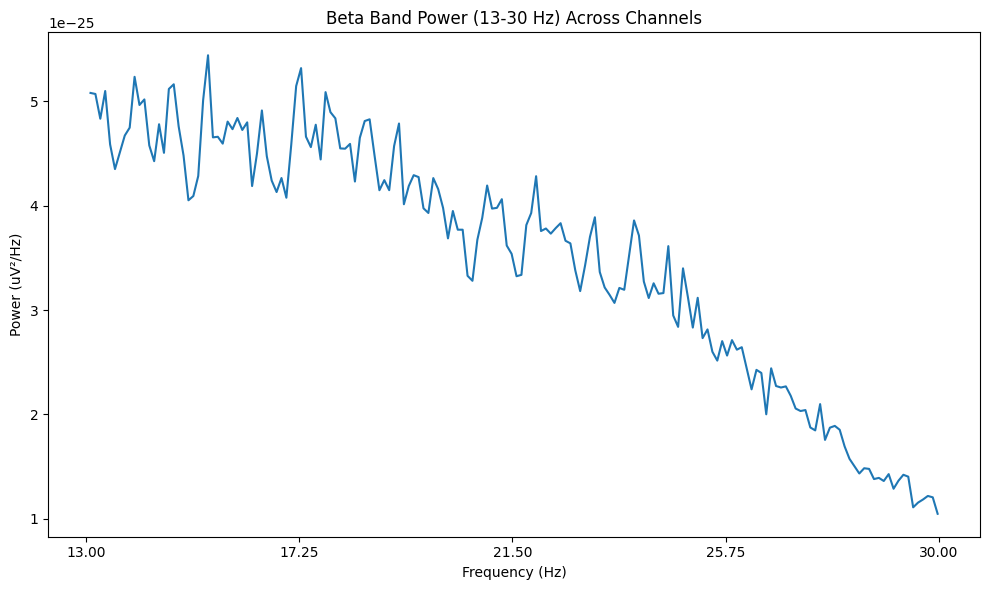

Extracted Beta Band Power (13-30 Hz) successfully.


In [654]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [655]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d63 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d63.head())
print(d63.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [656]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d63_clean = d63.replace([np.inf, -np.inf], np.nan)
d63_clean = d63_clean.fillna(d63_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d63_scaled = pd.DataFrame(
    scaler.fit_transform(d63_clean),
    columns=d63_clean.columns,
    index=d63_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d63_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d63_scaled.index,
    columns=d63_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d63_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df63 = d63_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df63["Pd_indicator_meg"] = 0

print("\nShape of df5:", df63.shape)
print(df63.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [657]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061, df63], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3417    3.918478             0.063800          6.007150e-12  0.787308   
3418    3.592391             0.069592          3.924287e-13  0.967051   
3419    3.646739             0.068554          7.686999e-12  0.906109   
3420    3.494565             0.071540          8.765686e-12  1.031274   
3421    3.793478             0.065903          3.696818e-13

In [658]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163.to_csv('/content/drive/MyDrive/combined_features_upto_sub0063_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163 preserved.


sub-64

In [659]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-64'  # Replace with your folder path


In [660]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-064_scans.tsv', 'meg']


In [661]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-064_coordsystem.json', 'sub-064_task-go_run-1_proc-tsss+mc_events.json', 'sub-064_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-064_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-064_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-064_task-noise_proc-tsss_meg.fif', 'sub-064_task-noise_proc-tsss_channels.tsv', 'sub-064_task-go_run-1_proc-tsss+mc_meg.json', 'sub-064_task-passive_run-1_proc-tsss+mc_events.json', 'sub-064_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-064_task-noise_proc-tsss_meg.json', 'sub-064_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-064_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-064_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-064_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-064_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-064_task-rest_run-1_proc-tsss+mc_events.json', 'sub-064_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-064_task-rest_run-1_proc-tsss+mc_meg.json']


In [662]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-064_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-064_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-064_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-064_task-rest_run-1_proc-tsss+mc_meg.fif']


In [663]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-64/meg/sub-064_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [664]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-64/meg/sub-064_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 210999 =     18.000 ...   210.999 secs
Ready.
Reading 0 ... 192999  =      0.000 ...   192.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


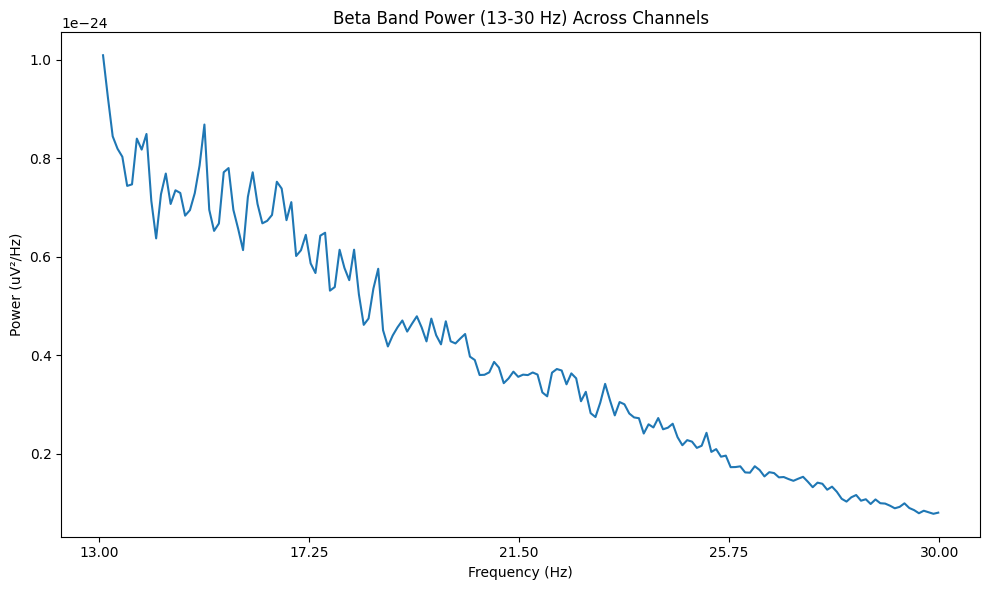

Extracted Beta Band Power (13-30 Hz) successfully.


In [665]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [666]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d64 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d64.head())
print(d64.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [667]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d64_clean = d64.replace([np.inf, -np.inf], np.nan)
d64_clean = d64_clean.fillna(d64_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d64_scaled = pd.DataFrame(
    scaler.fit_transform(d64_clean),
    columns=d64_clean.columns,
    index=d64_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d64_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d64_scaled.index,
    columns=d64_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d64_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df64 = d64_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df64["Pd_indicator_meg"] = 1

print("\nShape of df5:", df64.shape)
print(df64.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [668]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163, df64], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3475    3.331606             0.074868          1.071071e-11  1.088794   
3476    4.041451             0.061859          4.292800e-13  0.884986   
3477    3.554404             0.070284          1.059981e-11  0.967923   
3478    4.031088             0.061954          7.599570e-12  0.924212   
3479    3.720207             0.067201          4.892627e-

In [669]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364.to_csv('/content/drive/MyDrive/combined_features_upto_sub0064_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364 preserved.


sub-65

In [670]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-65'  # Replace with your folder path


In [671]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-065_scans.tsv', 'meg']


In [672]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-065_task-go_run-1_proc-tsss+mc_events.json', 'sub-065_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-065_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-065_coordsystem.json', 'sub-065_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-065_task-go_run-1_proc-tsss+mc_meg.json', 'sub-065_task-noise_proc-tsss_meg.fif', 'sub-065_task-noise_proc-tsss_channels.tsv', 'sub-065_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-065_task-passive_run-1_proc-tsss+mc_events.json', 'sub-065_task-noise_proc-tsss_meg.json', 'sub-065_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-065_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-065_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-065_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-065_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-065_task-rest_run-1_proc-tsss+mc_events.json', 'sub-065_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-065_task-rest_run-1_proc-tsss+mc_meg.json']


In [673]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-065_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-065_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-065_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-065_task-rest_run-1_proc-tsss+mc_meg.fif']


In [674]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-65/meg/sub-065_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [675]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-65/meg/sub-065_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 20000 ... 216999 =     20.000 ...   216.999 secs
Ready.
Reading 0 ... 196999  =      0.000 ...   196.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


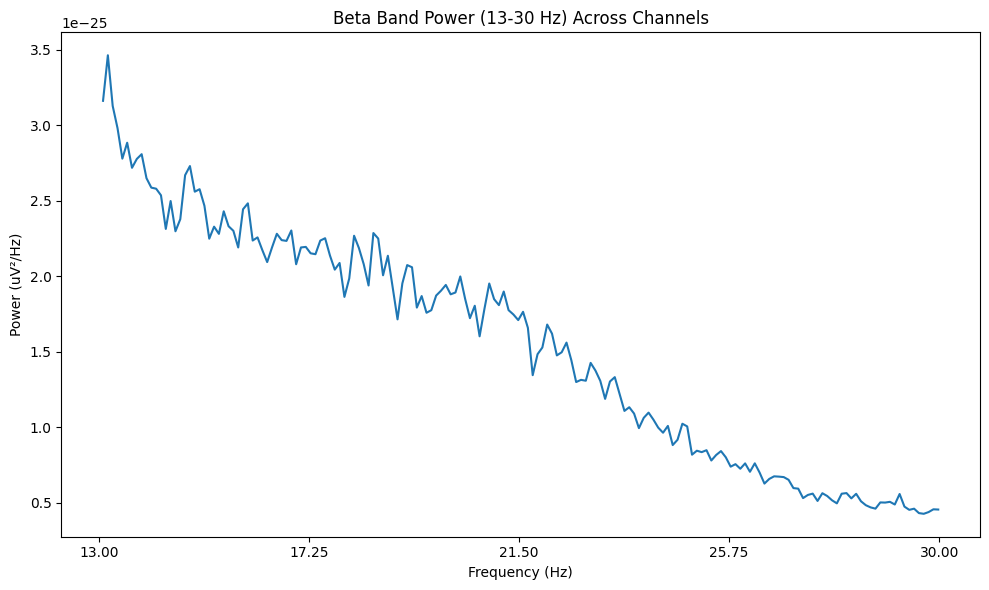

Extracted Beta Band Power (13-30 Hz) successfully.


In [676]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [677]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d65 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d65.head())
print(d65.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [678]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d65_clean = d65.replace([np.inf, -np.inf], np.nan)
d65_clean = d65_clean.fillna(d65_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d65_scaled = pd.DataFrame(
    scaler.fit_transform(d65_clean),
    columns=d65_clean.columns,
    index=d65_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d65_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d65_scaled.index,
    columns=d65_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d65_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df65 = d65_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df65["Pd_indicator_meg"] = 0

print("\nShape of df5:", df65.shape)
print(df65.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [679]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364, df65], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3533    3.796954             0.065842          3.930658e-12  0.747605   
3534    3.431472             0.072855          2.721527e-13  0.805880   
3535    3.634518             0.068785          5.014962e-12  0.834629   
3536    3.730964             0.067007          4.383167e-12  0.759685   
3537    3.538071             0.070660          2.677421

In [680]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465.to_csv('/content/drive/MyDrive/combined_features_upto_sub0065_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465 preserved.


sub-66

In [681]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-66'  # Replace with your folder path


In [682]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-066_scans.tsv', 'meg']


In [683]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-066_coordsystem.json', 'sub-066_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-066_task-go_run-1_proc-tsss+mc_events.json', 'sub-066_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-066_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-066_task-noise_proc-tsss_meg.fif', 'sub-066_task-go_run-1_proc-tsss+mc_meg.json', 'sub-066_task-noise_proc-tsss_channels.tsv', 'sub-066_task-passive_run-1_proc-tsss+mc_events.json', 'sub-066_task-noise_proc-tsss_meg.json', 'sub-066_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-066_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-066_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-066_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-066_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-066_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-066_task-rest_run-1_proc-tsss+mc_events.json', 'sub-066_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-066_task-rest_run-1_proc-tsss+mc_meg.json']


In [684]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-066_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-066_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-066_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-066_task-rest_run-1_proc-tsss+mc_meg.fif']


In [685]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-66/meg/sub-066_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [686]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-66/meg/sub-066_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 23000 ... 214999 =     23.000 ...   214.999 secs
Ready.
Reading 0 ... 191999  =      0.000 ...   191.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


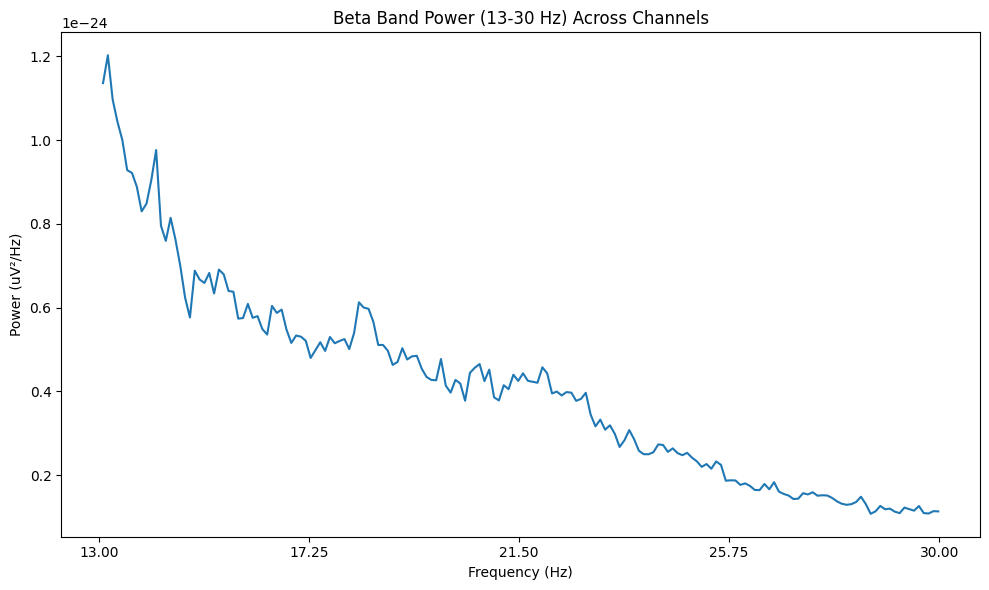

Extracted Beta Band Power (13-30 Hz) successfully.


In [687]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [688]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d66 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d66.head())
print(d66.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [689]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d66_clean = d66.replace([np.inf, -np.inf], np.nan)
d66_clean = d66_clean.fillna(d66_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d66_scaled = pd.DataFrame(
    scaler.fit_transform(d66_clean),
    columns=d66_clean.columns,
    index=d66_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d66_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d66_scaled.index,
    columns=d66_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d66_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df66 = d66_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df66["Pd_indicator_meg"] = 0

print("\nShape of df5:", df66.shape)
print(df66.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [690]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465, df66], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3591    4.166667             0.060000          6.224069e-12  0.957693   
3592    3.687500             0.067797          4.350273e-13  0.968432   
3593    4.119792             0.060683          7.921223e-12  0.979333   
3594    4.187500             0.059701          7.560739e-12  0.924229   
3595    4.052083             0.061697          4.2521

In [691]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566.to_csv('/content/drive/MyDrive/combined_features_upto_sub0066_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566 preserved.")


RAM Used After Cleanup: 0.64 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566 preserved.


sub-67

In [692]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-67'  # Replace with your folder path


In [693]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-067_scans.tsv', 'meg']


In [694]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-067_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-067_coordsystem.json', 'sub-067_task-go_run-1_proc-tsss+mc_events.json', 'sub-067_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-067_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-067_task-noise_proc-tsss_channels.tsv', 'sub-067_task-go_run-1_proc-tsss+mc_meg.json', 'sub-067_task-noise_proc-tsss_meg.fif', 'sub-067_task-noise_proc-tsss_meg.json', 'sub-067_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-067_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-067_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-067_task-passive_run-1_proc-tsss+mc_events.json', 'sub-067_task-rest_run-1_proc-tsss+mc_events.json', 'sub-067_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-067_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-067_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-067_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-067_task-rest_run-1_proc-tsss+mc_meg.json']


In [695]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-067_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-067_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-067_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-067_task-rest_run-1_proc-tsss+mc_meg.fif']


In [696]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-67/meg/sub-067_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [697]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-67/meg/sub-067_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 34000 ... 230999 =     34.000 ...   230.999 secs
Ready.
Reading 0 ... 196999  =      0.000 ...   196.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


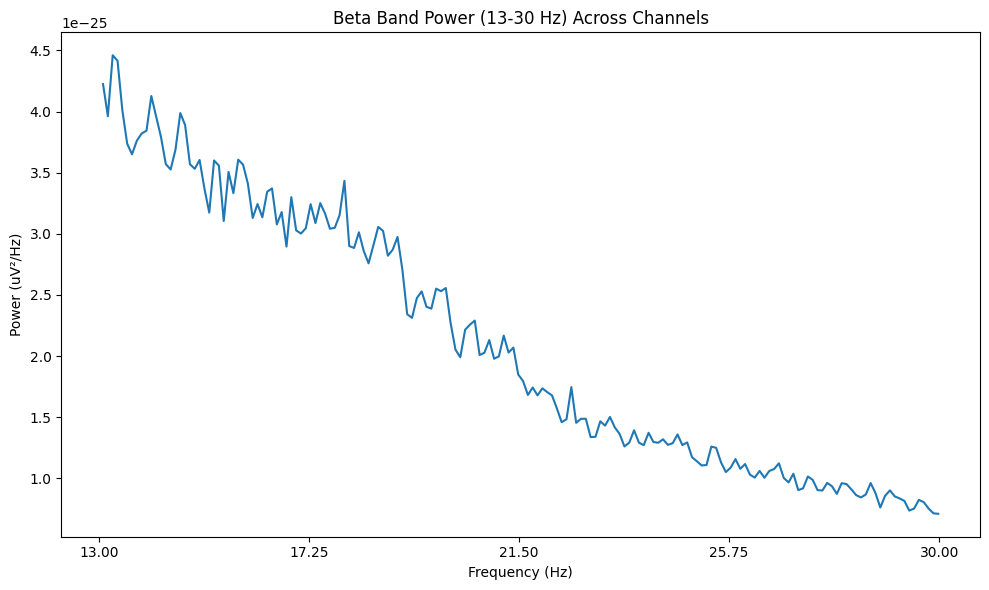

Extracted Beta Band Power (13-30 Hz) successfully.


In [698]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [699]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d67 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d67.head())
print(d67.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [700]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d67_clean = d67.replace([np.inf, -np.inf], np.nan)
d67_clean = d67_clean.fillna(d67_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d67_scaled = pd.DataFrame(
    scaler.fit_transform(d67_clean),
    columns=d67_clean.columns,
    index=d67_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d67_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d67_scaled.index,
    columns=d67_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d67_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df67 = d67_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df67["Pd_indicator_meg"] = 1

print("\nShape of df5:", df67.shape)
print(df67.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [701]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566, df67], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3649    3.639594             0.068689          6.662843e-12  0.949855   
3650    3.654822             0.068403          3.223762e-13  1.158675   
3651    3.786802             0.066019          5.891295e-12  0.920518   
3652    3.756345             0.066554          5.586569e-12  1.041110   
3653    3.675127             0.068025          3.14

In [702]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667.to_csv('/content/drive/MyDrive/combined_features_upto_sub0067_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667 preserved.


sub-68

In [703]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-68'  # Replace with your folder path


In [704]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-068_scans.tsv', 'meg']


In [705]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-068_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-068_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-068_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-068_coordsystem.json', 'sub-068_task-go_run-1_proc-tsss+mc_events.json', 'sub-068_task-noise_proc-tsss_channels.tsv', 'sub-068_task-noise_proc-tsss_meg.fif', 'sub-068_task-go_run-1_proc-tsss+mc_meg.json', 'sub-068_task-passive_run-1_proc-tsss+mc_events.json', 'sub-068_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-068_task-noise_proc-tsss_meg.json', 'sub-068_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-068_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-068_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-068_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-068_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-068_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-068_task-rest_run-1_proc-tsss+mc_events.json', 'sub-068_task-rest_run-1_proc-tsss+mc_meg.json']


In [706]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-068_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-068_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-068_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-068_task-rest_run-1_proc-tsss+mc_meg.fif']


In [707]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-68/meg/sub-068_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [708]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-68/meg/sub-068_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 62000 ... 334999 =     62.000 ...   334.999 secs
Ready.
Reading 0 ... 272999  =      0.000 ...   272.999 secs...
Finding events on: STI101
1 event found on stim channel STI101
Event IDs: [1]
Finding events on: STI101
1 event found on stim channel STI101
Event IDs: [1]
Resampling done
Filtering raw data in 2 contiguous segments
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitting IC

Computing Power Spectral Density

Setting 4800 of 54600 (8.79%) samples to NaN, retaining 49800 (91.21%) samples.
Effective window size : 10.240 (s)
At least one good data span is shorter than n_per_seg, and will be analyzed with a shorter window than the rest of the file.


/usr/local/lib/python3.12/dist-packages/mne/time_frequency/psd.py:291: UserWarning: nperseg = 2048 is greater than input length  = 400, using nperseg = 400
  return _func(*args, **kwargs)


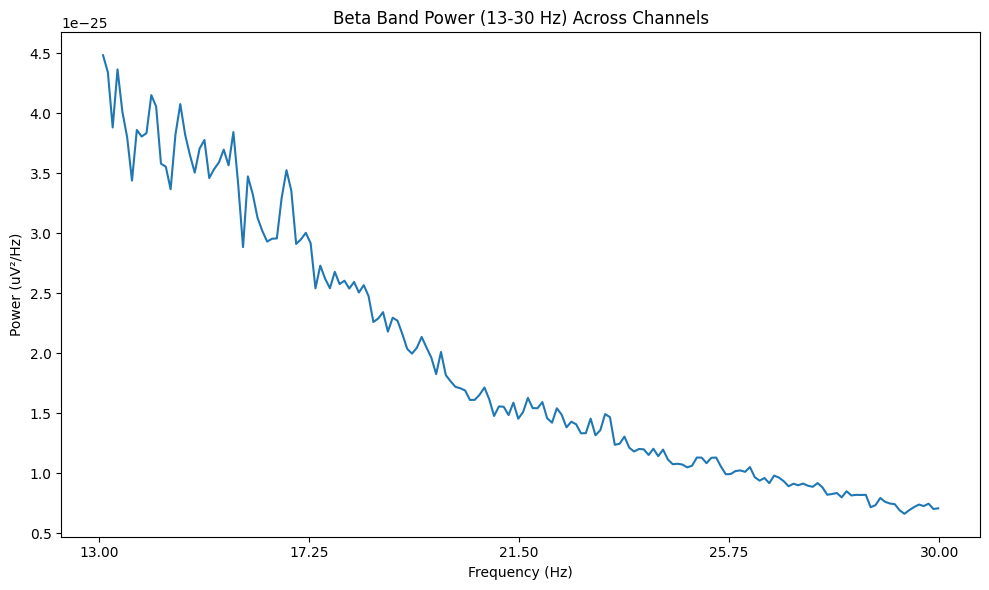

Extracted Beta Band Power (13-30 Hz) successfully.


In [709]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [710]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d68 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d68.head())
print(d68.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [711]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d68_clean = d68.replace([np.inf, -np.inf], np.nan)
d68_clean = d68_clean.fillna(d68_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d68_scaled = pd.DataFrame(
    scaler.fit_transform(d68_clean),
    columns=d68_clean.columns,
    index=d68_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d68_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d68_scaled.index,
    columns=d68_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d68_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df68 = d68_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df68["Pd_indicator_meg"] = 0

print("\nShape of df5:", df68.shape)
print(df68.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [712]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667, df68], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3707    3.857143             0.064815          2.867367e-12  2.978384   
3708    3.604396             0.069360          1.904949e-13  2.936148   
3709    3.677656             0.067978          3.399078e-12  2.935097   
3710    3.761905             0.066456          3.223254e-12  2.936151   
3711    3.542125             0.070579          2.

In [713]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768.to_csv('/content/drive/MyDrive/combined_features_upto_sub0068_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768 preserved.")


RAM Used After Cleanup: 0.64 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768 preserved.


sub-69

In [714]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-69'  # Replace with your folder path


In [715]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-069_scans.tsv', 'meg']


In [716]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-069_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-069_coordsystem.json', 'sub-069_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-069_task-go_run-1_proc-tsss+mc_events.json', 'sub-069_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-069_task-go_run-1_proc-tsss+mc_meg.json', 'sub-069_task-noise_proc-tsss_meg.fif', 'sub-069_task-noise_proc-tsss_channels.tsv', 'sub-069_task-noise_proc-tsss_meg.json', 'sub-069_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-069_task-passive_run-1_proc-tsss+mc_events.json', 'sub-069_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-069_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-069_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-069_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-069_task-rest_run-1_proc-tsss+mc_events.json', 'sub-069_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-069_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-069_task-rest_run-1_proc-tsss+mc_meg.json']


In [717]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-069_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-069_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-069_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-069_task-rest_run-1_proc-tsss+mc_meg.fif']


In [718]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-69/meg/sub-069_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [719]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-69/meg/sub-069_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 14000 ... 199999 =     14.000 ...   199.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


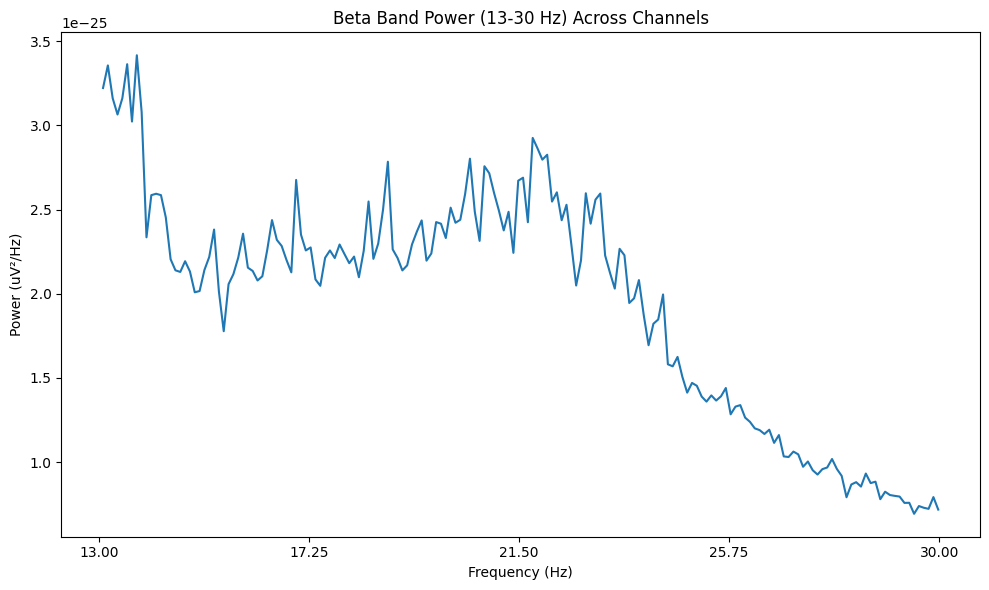

Extracted Beta Band Power (13-30 Hz) successfully.


In [720]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [721]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d69 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d69.head())
print(d69.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [722]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d69_clean = d69.replace([np.inf, -np.inf], np.nan)
d69_clean = d69_clean.fillna(d69_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d69_scaled = pd.DataFrame(
    scaler.fit_transform(d69_clean),
    columns=d69_clean.columns,
    index=d69_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d69_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d69_scaled.index,
    columns=d69_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d69_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df69 = d69_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df69["Pd_indicator_meg"] = 0

print("\nShape of df5:", df69.shape)
print(df69.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [723]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768, df69], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3765    3.467742             0.072093          6.824434e-12  0.855179   
3766    3.768817             0.066334          3.187189e-13  0.851459   
3767    3.494624             0.071538          7.474213e-12  0.879747   
3768    3.623656             0.068991          6.154120e-12  0.790680   
3769    3.510753             0.071210          

In [724]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869.to_csv('/content/drive/MyDrive/combined_features_upto_sub0069_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869 preserved.


sub-70

In [725]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-70'  # Replace with your folder path


In [726]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-070_scans.tsv', 'meg']


In [727]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-070_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-070_coordsystem.json', 'sub-070_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-070_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-070_task-go_run-1_proc-tsss+mc_events.json', 'sub-070_task-go_run-1_proc-tsss+mc_meg.json', 'sub-070_task-noise_proc-tsss_meg.fif', 'sub-070_task-noise_proc-tsss_channels.tsv', 'sub-070_task-noise_proc-tsss_meg.json', 'sub-070_task-passive_run-1_proc-tsss+mc_events.json', 'sub-070_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-070_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-070_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-070_task-rest_run-1_proc-tsss+mc_events.json', 'sub-070_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-070_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-070_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-070_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-070_task-rest_run-1_proc-tsss+mc_meg.json']


In [728]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-070_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-070_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-070_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-070_task-rest_run-1_proc-tsss+mc_meg.fif']


In [729]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-70/meg/sub-070_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [730]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-70/meg/sub-070_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 22000 ... 207999 =     22.000 ...   207.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


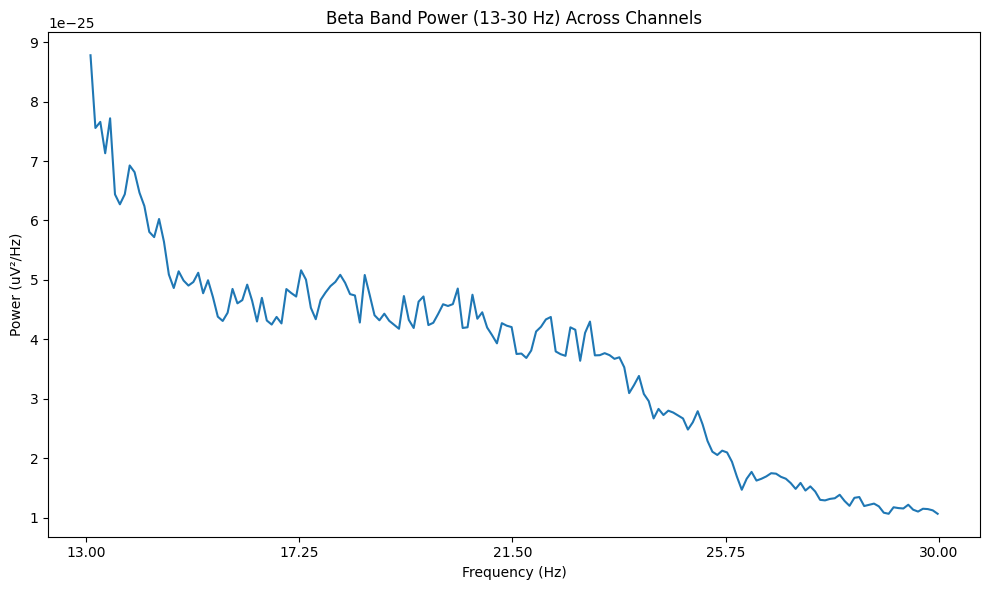

Extracted Beta Band Power (13-30 Hz) successfully.


In [731]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [732]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d70 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d70.head())
print(d70.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [733]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d70_clean = d70.replace([np.inf, -np.inf], np.nan)
d70_clean = d70_clean.fillna(d70_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d70_scaled = pd.DataFrame(
    scaler.fit_transform(d70_clean),
    columns=d70_clean.columns,
    index=d70_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d70_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d70_scaled.index,
    columns=d70_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d70_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df70 = d70_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df70["Pd_indicator_meg"] = 1

print("\nShape of df5:", df70.shape)
print(df70.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [734]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869, df70], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3823    3.892473             0.064227          6.634819e-12  0.917853   
3824    3.844086             0.065035          3.680355e-13  0.944302   
3825    4.005376             0.062416          7.054623e-12  0.964245   
3826    3.795699             0.065864          6.717527e-12  1.050994   
3827    4.134409             0.060468        

In [735]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970.to_csv('/content/drive/MyDrive/combined_features_upto_sub0070_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970 preserved.


sub-71

In [736]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [737]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub0070_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (3828, 22)


In [738]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-71'  # Replace with your folder path


In [739]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-071_scans.tsv', 'meg']


In [740]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-071_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-071_task-noise_proc-tsss_meg.fif', 'sub-071_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-071_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-071_task-rest_run-1_proc-tsss+mc_events.json', 'sub-071_coordsystem.json', 'sub-071_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-071_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-071_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-071_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-071_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-071_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-071_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-071_task-passive_run-1_proc-tsss+mc_events.json', 'sub-071_task-noise_proc-tsss_channels.tsv', 'sub-071_task-go_run-1_proc-tsss+mc_meg.json', 'sub-071_task-noise_proc-tsss_meg.json', 'sub-071_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-071_task-go_run-1_proc-tsss+mc_events.json']


In [741]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-071_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-071_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-071_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-071_task-rest_run-1_proc-tsss+mc_meg.fif']


In [742]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-71/meg/sub-071_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [743]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-71/meg/sub-071_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 14000 ... 203999 =     14.000 ...   203.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


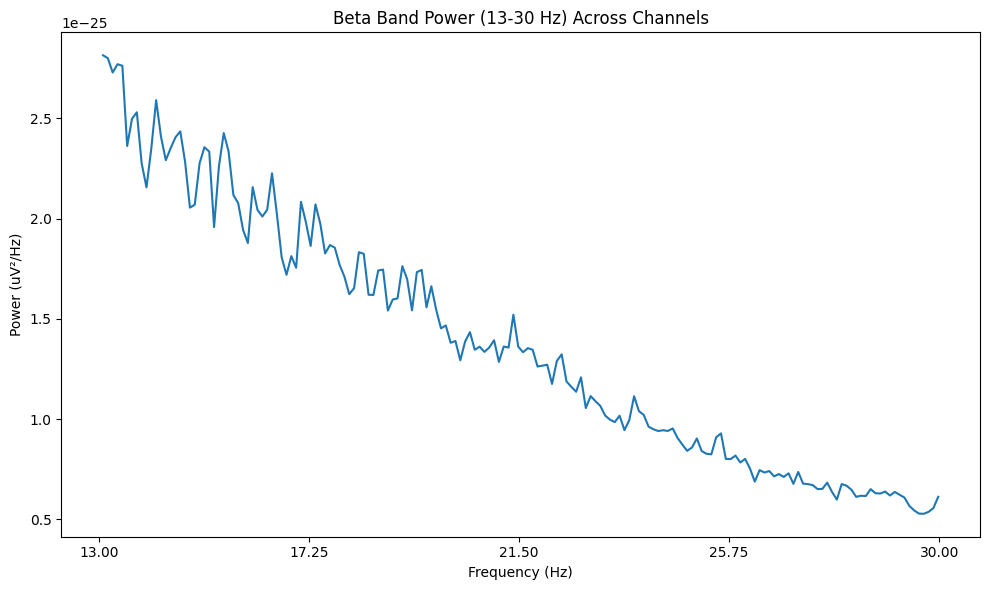

Extracted Beta Band Power (13-30 Hz) successfully.


In [744]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [745]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d71 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d71.head())
print(d71.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [746]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d71_clean = d71.replace([np.inf, -np.inf], np.nan)
d71_clean = d71_clean.fillna(d71_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d71_scaled = pd.DataFrame(
    scaler.fit_transform(d71_clean),
    columns=d71_clean.columns,
    index=d71_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d71_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d71_scaled.index,
    columns=d71_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d71_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df71 = d71_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df71["Pd_indicator_meg"] = 0

print("\nShape of df5:", df71.shape)
print(df71.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [747]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071 = pd.concat([previous_df, df71], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3881    4.478947             0.055817          3.212970e-12  0.685491   
3882    4.231579             0.059080          1.856352e-13  0.728887   
3883    4.415789             0.056615          3.506938e-12  0.733872   
3884    4.400000             0.056818          3.096273e-12  0.712576   
3885    4.121053             0.060664      

In [748]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071.to_csv('/content/drive/MyDrive/combined_features_upto_sub0071_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071 preserved.


sub-72

In [749]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-72'  # Replace with your folder path


In [750]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-072_scans.tsv', 'meg']


In [751]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-072_coordsystem.json', 'sub-072_task-go_run-1_proc-tsss+mc_events.json', 'sub-072_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-072_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-072_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-072_task-noise_proc-tsss_channels.tsv', 'sub-072_task-go_run-1_proc-tsss+mc_meg.json', 'sub-072_task-noise_proc-tsss_meg.fif', 'sub-072_task-noise_proc-tsss_meg.json', 'sub-072_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-072_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-072_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-072_task-passive_run-1_proc-tsss+mc_events.json', 'sub-072_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-072_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-072_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-072_task-rest_run-1_proc-tsss+mc_events.json', 'sub-072_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-072_task-rest_run-1_proc-tsss+mc_meg.json']


In [752]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-072_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-072_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-072_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-072_task-rest_run-1_proc-tsss+mc_meg.fif']


In [753]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-72/meg/sub-072_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [754]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-72/meg/sub-072_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 16000 ... 201999 =     16.000 ...   201.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


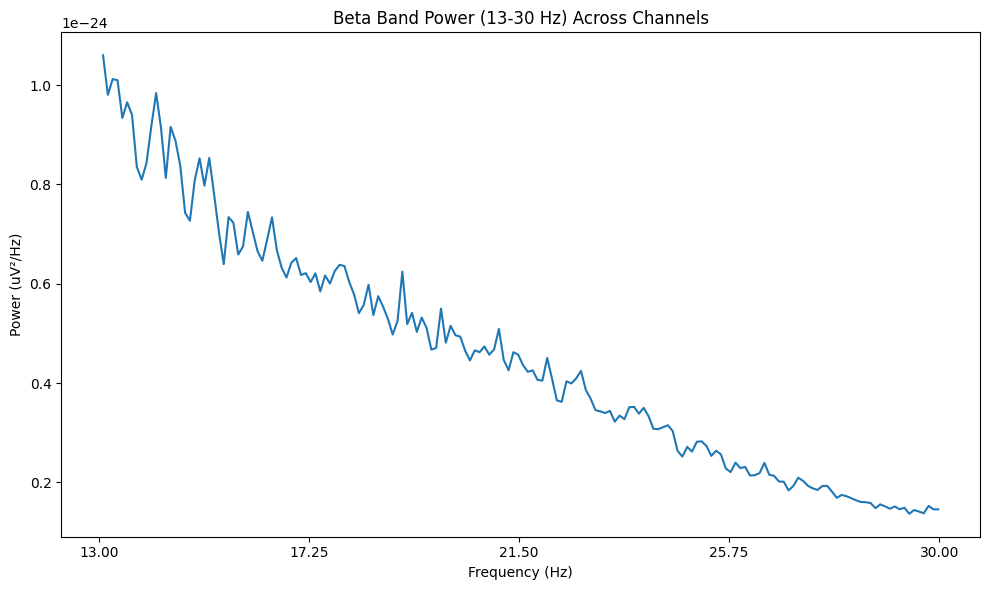

Extracted Beta Band Power (13-30 Hz) successfully.


In [755]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [756]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d72 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d72.head())
print(d72.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [757]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d72_clean = d72.replace([np.inf, -np.inf], np.nan)
d72_clean = d72_clean.fillna(d72_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d72_scaled = pd.DataFrame(
    scaler.fit_transform(d72_clean),
    columns=d72_clean.columns,
    index=d72_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d72_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d72_scaled.index,
    columns=d72_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d72_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df72 = d72_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df72["Pd_indicator_meg"] = 0

print("\nShape of df5:", df72.shape)
print(df72.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [758]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071, df72], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3939    4.026882             0.062083          8.463439e-12  0.865237   
3940    3.897849             0.064138          4.312659e-13  0.853351   
3941    3.946237             0.063351          9.219210e-12  0.914468   
3942    3.924731             0.063699          9.261405e-12  0.867557   
3943    3.956989             0.063179    

In [759]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172.to_csv('/content/drive/MyDrive/combined_features_upto_sub0072_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172 preserved.


sub-73

In [760]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-73'  # Replace with your folder path


In [761]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-073_scans.tsv', 'meg']


In [762]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-073_coordsystem.json', 'sub-073_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-073_task-go_run-1_proc-tsss+mc_events.json', 'sub-073_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-073_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-073_task-noise_proc-tsss_meg.fif', 'sub-073_task-go_run-1_proc-tsss+mc_meg.json', 'sub-073_task-noise_proc-tsss_channels.tsv', 'sub-073_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-073_task-passive_run-1_proc-tsss+mc_events.json', 'sub-073_task-noise_proc-tsss_meg.json', 'sub-073_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-073_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-073_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-073_task-rest_run-1_proc-tsss+mc_events.json', 'sub-073_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-073_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-073_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-073_task-rest_run-1_proc-tsss+mc_meg.json']


In [763]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-073_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-073_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-073_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-073_task-rest_run-1_proc-tsss+mc_meg.fif']


In [764]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-73/meg/sub-073_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [765]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-73/meg/sub-073_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 27000 ... 217999 =     27.000 ...   217.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


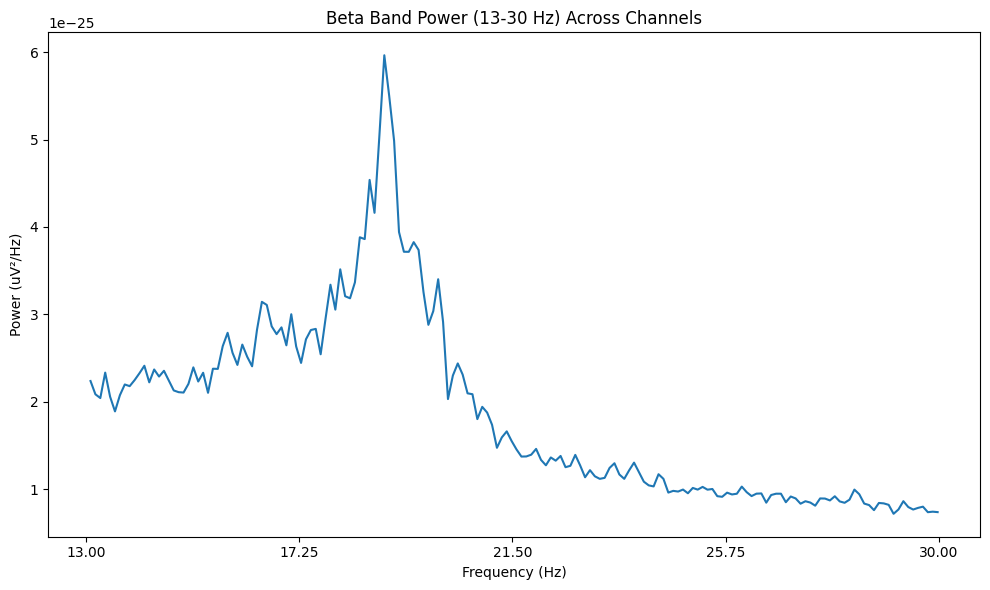

Extracted Beta Band Power (13-30 Hz) successfully.


In [766]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [767]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d73 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d73.head())
print(d73.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [768]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d73_clean = d73.replace([np.inf, -np.inf], np.nan)
d73_clean = d73_clean.fillna(d73_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d73_scaled = pd.DataFrame(
    scaler.fit_transform(d73_clean),
    columns=d73_clean.columns,
    index=d73_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d73_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d73_scaled.index,
    columns=d73_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d73_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df73 = d73_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df73["Pd_indicator_meg"] = 0

print("\nShape of df5:", df73.shape)
print(df73.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [769]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172, df73], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
3997    3.921466             0.063752          3.187072e-12  0.861657   
3998    3.036649             0.082328          2.529042e-13  1.275329   
3999    3.659686             0.068312          3.768139e-12  1.020257   
4000    3.157068             0.079187          4.317718e-12  1.242294   
4001    3.277487             0.076278  

In [770]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273.to_csv('/content/drive/MyDrive/combined_features_upto_sub0073_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273 preserved.


sub-74

In [771]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [772]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-74'  # Replace with your folder path


In [773]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-074_scans.tsv', 'meg']


In [774]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-074_task-go_run-1_proc-tsss+mc_events.json', 'sub-074_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-074_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-074_coordsystem.json', 'sub-074_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-074_task-noise_proc-tsss_meg.fif', 'sub-074_task-go_run-1_proc-tsss+mc_meg.json', 'sub-074_task-noise_proc-tsss_channels.tsv', 'sub-074_task-noise_proc-tsss_meg.json', 'sub-074_task-passive_run-1_proc-tsss+mc_events.json', 'sub-074_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-074_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-074_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-074_task-rest_run-1_proc-tsss+mc_events.json', 'sub-074_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-074_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-074_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-074_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-074_task-rest_run-1_proc-tsss+mc_meg.json']


In [775]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-074_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-074_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-074_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-074_task-rest_run-1_proc-tsss+mc_meg.fif']


In [776]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-74/meg/sub-074_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [777]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-74/meg/sub-074_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 28000 ... 214999 =     28.000 ...   214.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


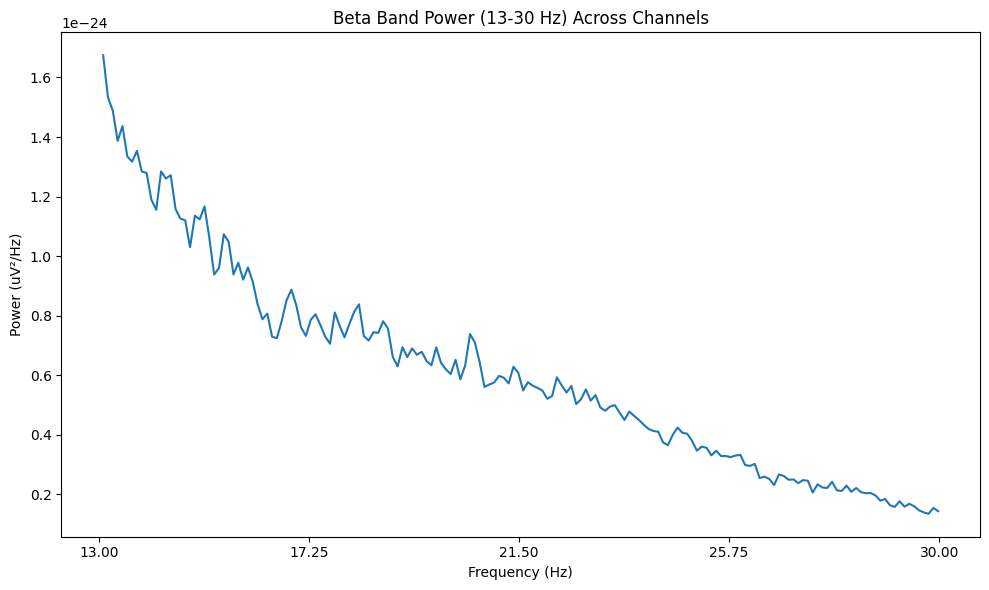

Extracted Beta Band Power (13-30 Hz) successfully.


In [778]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [779]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d74 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d74.head())
print(d74.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [780]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d74_clean = d74.replace([np.inf, -np.inf], np.nan)
d74_clean = d74_clean.fillna(d74_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d74_scaled = pd.DataFrame(
    scaler.fit_transform(d74_clean),
    columns=d74_clean.columns,
    index=d74_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d74_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d74_scaled.index,
    columns=d74_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d74_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df74 = d74_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df74["Pd_indicator_meg"] = 0

print("\nShape of df5:", df74.shape)
print(df74.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [781]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273, df74], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4055    3.882353             0.064394          8.055661e-12  0.873711   
4056    3.743316             0.066786          4.498551e-13  0.945871   
4057    3.973262             0.062921          8.773403e-12  0.824749   
4058    3.855615             0.064799          7.868737e-12  0.852365   
4059    3.695187             0.067656

In [782]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374.to_csv('/content/drive/MyDrive/combined_features_upto_sub0074_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374 preserved.


sub-75

In [783]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-75'  # Replace with your folder path


In [784]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-075_scans.tsv', 'meg']


In [785]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-075_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-075_task-go_run-1_proc-tsss+mc_events.json', 'sub-075_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-075_coordsystem.json', 'sub-075_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-075_task-go_run-1_proc-tsss+mc_meg.json', 'sub-075_task-noise_proc-tsss_channels.tsv', 'sub-075_task-noise_proc-tsss_meg.fif', 'sub-075_task-noise_proc-tsss_meg.json', 'sub-075_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-075_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-075_task-passive_run-1_proc-tsss+mc_events.json', 'sub-075_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-075_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-075_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-075_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-075_task-rest_run-1_proc-tsss+mc_events.json', 'sub-075_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-075_task-rest_run-1_proc-tsss+mc_meg.json']


In [786]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-075_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-075_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-075_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-075_task-rest_run-1_proc-tsss+mc_meg.fif']


In [787]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-75/meg/sub-075_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [788]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-75/meg/sub-075_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 28000 ... 229999 =     28.000 ...   229.999 secs
Ready.
Reading 0 ... 201999  =      0.000 ...   201.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


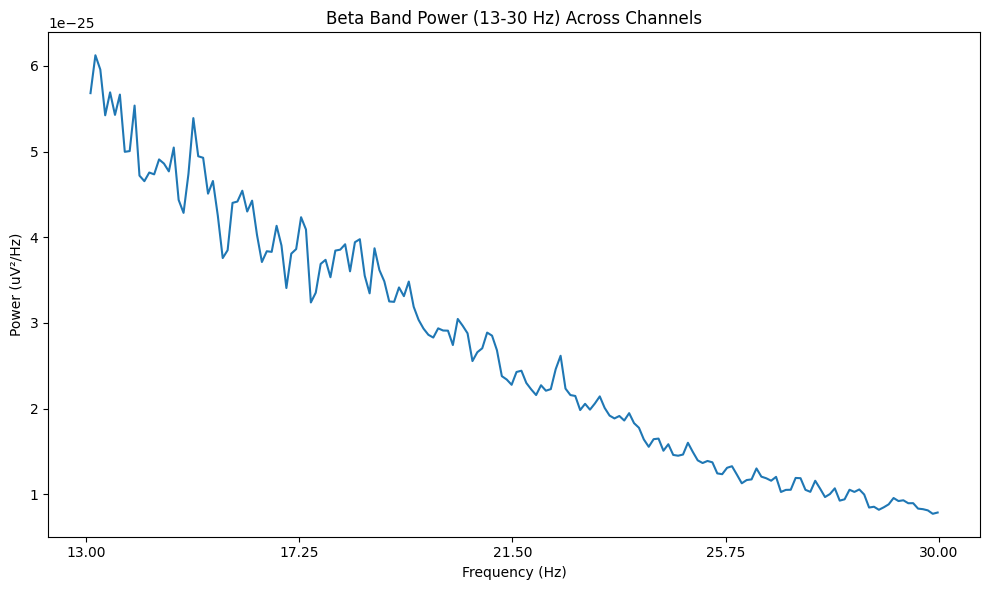

Extracted Beta Band Power (13-30 Hz) successfully.


In [789]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [790]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d75 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d75.head())
print(d75.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [791]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d75_clean = d75.replace([np.inf, -np.inf], np.nan)
d75_clean = d75_clean.fillna(d75_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d75_scaled = pd.DataFrame(
    scaler.fit_transform(d75_clean),
    columns=d75_clean.columns,
    index=d75_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d75_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d75_scaled.index,
    columns=d75_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d75_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df75 = d75_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df75["Pd_indicator_meg"] = 1

print("\nShape of df5:", df75.shape)
print(df75.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [792]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374, df75], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4113    3.311881             0.075486          7.220779e-12  0.960018   
4114    3.752475             0.066623          3.145238e-13  0.868626   
4115    3.514851             0.071127          7.424179e-12  0.905525   
4116    3.707921             0.067423          6.564576e-12  0.894463   
4117    3.623762             0.0689

In [793]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475.to_csv('/content/drive/MyDrive/combined_features_upto_sub0075_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475 preserved.


sub-76

In [794]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-76'  # Replace with your folder path


In [795]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-076_scans.tsv', 'meg']


In [796]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-076_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-076_coordsystem.json', 'sub-076_task-go_run-1_proc-tsss+mc_events.json', 'sub-076_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-076_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-076_task-go_run-1_proc-tsss+mc_meg.json', 'sub-076_task-noise_proc-tsss_meg.fif', 'sub-076_task-noise_proc-tsss_channels.tsv', 'sub-076_task-noise_proc-tsss_meg.json', 'sub-076_task-passive_run-1_proc-tsss+mc_events.json', 'sub-076_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-076_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-076_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-076_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-076_task-rest_run-1_proc-tsss+mc_events.json', 'sub-076_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-076_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-076_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-076_task-rest_run-1_proc-tsss+mc_meg.json']


In [797]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-076_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-076_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-076_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-076_task-rest_run-1_proc-tsss+mc_meg.fif']


In [798]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-76/meg/sub-076_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [799]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-76/meg/sub-076_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 42000 ... 234999 =     42.000 ...   234.999 secs
Ready.
Reading 0 ... 192999  =      0.000 ...   192.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


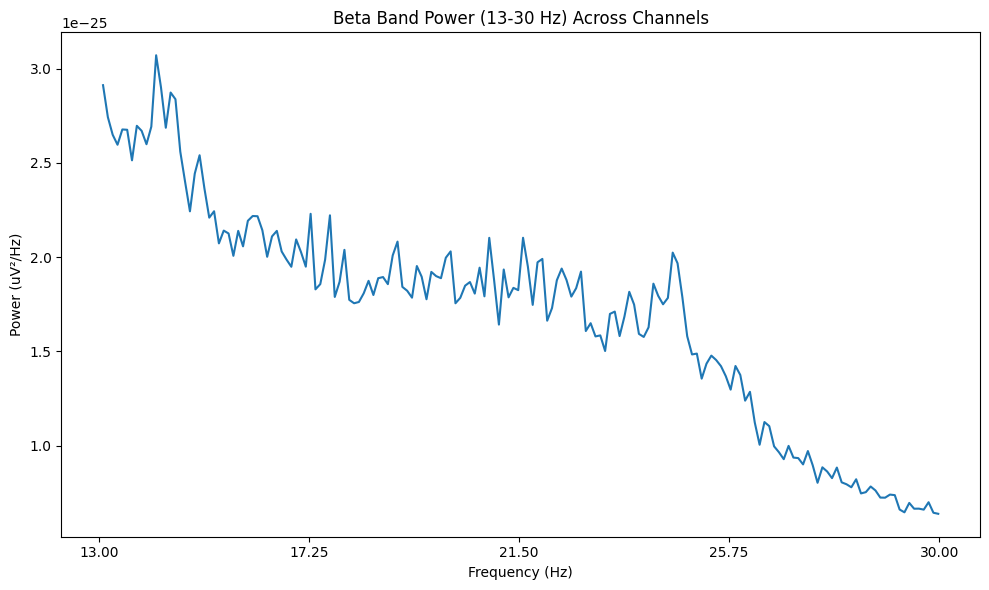

Extracted Beta Band Power (13-30 Hz) successfully.


In [800]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [801]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d76 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d76.head())
print(d76.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [802]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d76_clean = d76.replace([np.inf, -np.inf], np.nan)
d76_clean = d76_clean.fillna(d76_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d76_scaled = pd.DataFrame(
    scaler.fit_transform(d76_clean),
    columns=d76_clean.columns,
    index=d76_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d76_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d76_scaled.index,
    columns=d76_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d76_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df76 = d76_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df76["Pd_indicator_meg"] = 1

print("\nShape of df5:", df76.shape)
print(df76.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [803]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475, df76], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4171    3.865285             0.064678          6.237281e-12  0.985272   
4172    3.854922             0.064852          2.932503e-13  0.888295   
4173    4.181347             0.059789          5.936746e-12  0.830846   
4174    4.082902             0.061231          4.796346e-12  0.786762   
4175    3.782383             0.06

In [804]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576.to_csv('/content/drive/MyDrive/combined_features_upto_sub0076_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576 preserved.


sub-77

In [805]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-77'  # Replace with your folder path


In [806]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-077_scans.tsv', 'meg']


In [807]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-077_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-077_coordsystem.json', 'sub-077_task-go_run-1_proc-tsss+mc_events.json', 'sub-077_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-077_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-077_task-go_run-1_proc-tsss+mc_meg.json', 'sub-077_task-noise_proc-tsss_channels.tsv', 'sub-077_task-noise_proc-tsss_meg.fif', 'sub-077_task-noise_proc-tsss_meg.json', 'sub-077_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-077_task-passive_run-1_proc-tsss+mc_events.json', 'sub-077_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-077_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-077_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-077_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-077_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-077_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-077_task-rest_run-1_proc-tsss+mc_events.json', 'sub-077_task-rest_run-1_proc-tsss+mc_meg.json']


In [808]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-077_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-077_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-077_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-077_task-rest_run-1_proc-tsss+mc_meg.fif']


In [809]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-77/meg/sub-077_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [810]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-77/meg/sub-077_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 71000 ... 260999 =     71.000 ...   260.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


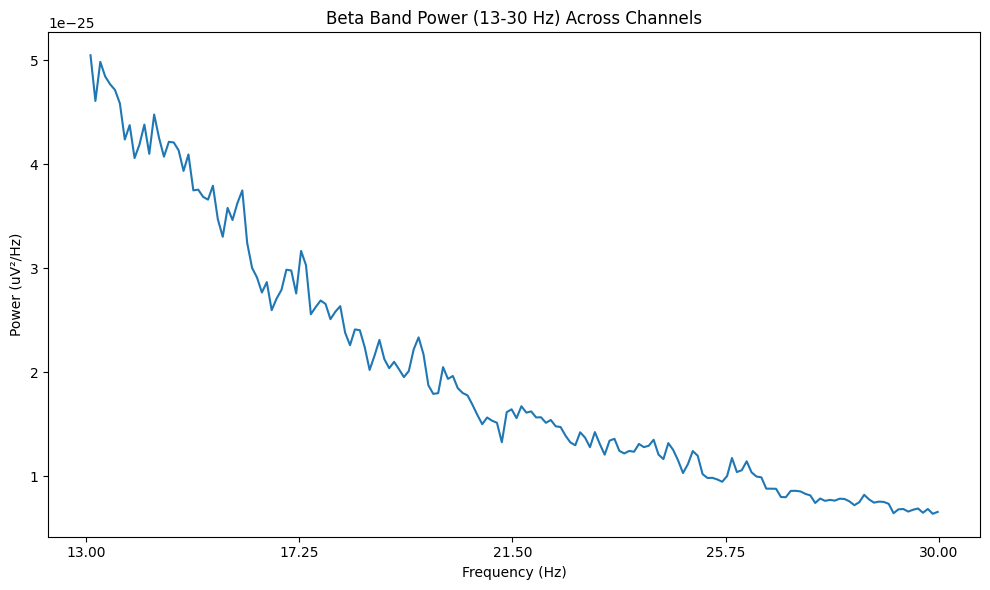

Extracted Beta Band Power (13-30 Hz) successfully.


In [811]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [812]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d77 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d77.head())
print(d77.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [813]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d77_clean = d77.replace([np.inf, -np.inf], np.nan)
d77_clean = d77_clean.fillna(d77_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d77_scaled = pd.DataFrame(
    scaler.fit_transform(d77_clean),
    columns=d77_clean.columns,
    index=d77_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d77_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d77_scaled.index,
    columns=d77_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d77_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df77 = d77_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df77["Pd_indicator_meg"] = 1

print("\nShape of df5:", df77.shape)
print(df77.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [814]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576, df77], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4229    3.978947             0.062831          5.463781e-12  1.070415   
4230    3.657895             0.068345          2.754075e-13  1.008033   
4231    4.005263             0.062418          5.508457e-12  0.994435   
4232    3.994737             0.062582          4.784326e-12  1.007232   
4233    3.847368             0.

In [815]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677.to_csv('/content/drive/MyDrive/combined_features_upto_sub0077_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677 preserved.


sub-78

In [816]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-78'  # Replace with your folder path


In [817]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-078_scans.tsv', 'meg']


In [818]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-078_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-078_coordsystem.json', 'sub-078_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-078_task-go_run-1_proc-tsss+mc_events.json', 'sub-078_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-078_task-go_run-1_proc-tsss+mc_meg.json', 'sub-078_task-noise_proc-tsss_meg.fif', 'sub-078_task-noise_proc-tsss_channels.tsv', 'sub-078_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-078_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-078_task-passive_run-1_proc-tsss+mc_events.json', 'sub-078_task-noise_proc-tsss_meg.json', 'sub-078_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-078_task-rest_run-1_proc-tsss+mc_events.json', 'sub-078_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-078_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-078_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-078_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-078_task-rest_run-1_proc-tsss+mc_meg.json']


In [819]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-078_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-078_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-078_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-078_task-rest_run-1_proc-tsss+mc_meg.fif']


In [820]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-78/meg/sub-078_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [821]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-78/meg/sub-078_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 35000 ... 233999 =     35.000 ...   233.999 secs
Ready.
Reading 0 ... 198999  =      0.000 ...   198.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


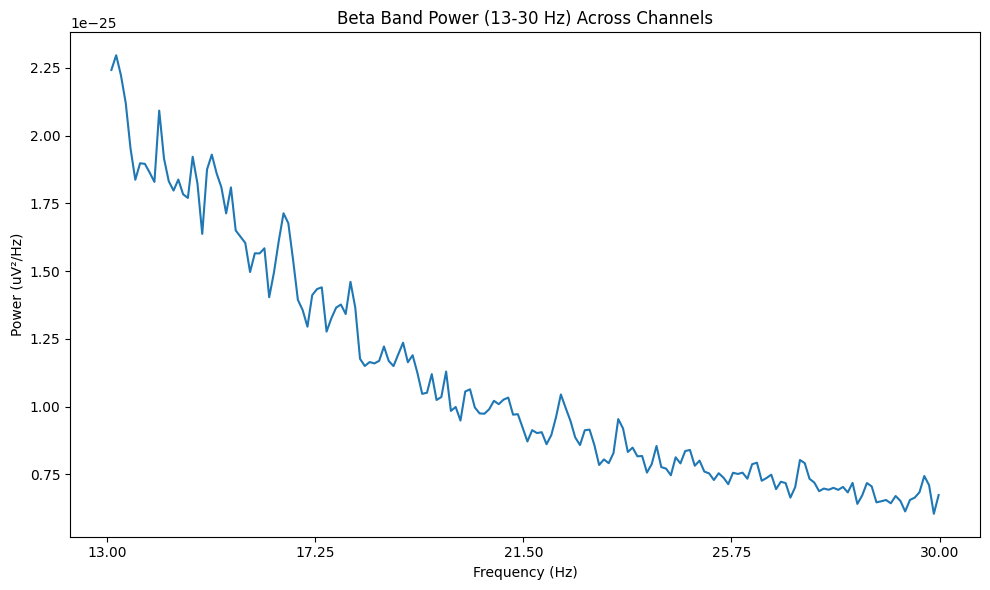

Extracted Beta Band Power (13-30 Hz) successfully.


In [822]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [823]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d78 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d78.head())
print(d78.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [824]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d78_clean = d78.replace([np.inf, -np.inf], np.nan)
d78_clean = d78_clean.fillna(d78_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d78_scaled = pd.DataFrame(
    scaler.fit_transform(d78_clean),
    columns=d78_clean.columns,
    index=d78_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d78_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d78_scaled.index,
    columns=d78_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d78_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df78 = d78_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df78["Pd_indicator_meg"] = 0

print("\nShape of df5:", df78.shape)
print(df78.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [825]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677, df78], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4287    4.638191             0.053900          2.885431e-12  0.747378   
4288    4.492462             0.055649          1.506365e-13  0.725519   
4289    4.537688             0.055094          2.921273e-12  0.753493   
4290    4.658291             0.053668          2.796397e-12  0.698282   
4291    4.497487             

In [826]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778.to_csv('/content/drive/MyDrive/combined_features_upto_sub0078_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778 preserved.


sub-79

In [827]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-79'  # Replace with your folder path


In [828]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-079_scans.tsv', 'meg']


In [829]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-079_coordsystem.json', 'sub-079_task-go_run-1_proc-tsss+mc_events.json', 'sub-079_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-079_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-079_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-079_task-noise_proc-tsss_meg.fif', 'sub-079_task-go_run-1_proc-tsss+mc_meg.json', 'sub-079_task-noise_proc-tsss_channels.tsv', 'sub-079_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-079_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-079_task-passive_run-1_proc-tsss+mc_events.json', 'sub-079_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-079_task-noise_proc-tsss_meg.json', 'sub-079_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-079_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-079_task-rest_run-1_proc-tsss+mc_events.json', 'sub-079_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-079_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-079_task-rest_run-1_proc-tsss+mc_meg.json']


In [830]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-079_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-079_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-079_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-079_task-rest_run-1_proc-tsss+mc_meg.fif']


In [831]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-79/meg/sub-079_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [832]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-79/meg/sub-079_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 77000 ... 261999 =     77.000 ...   261.999 secs
Ready.
Reading 0 ... 184999  =      0.000 ...   184.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


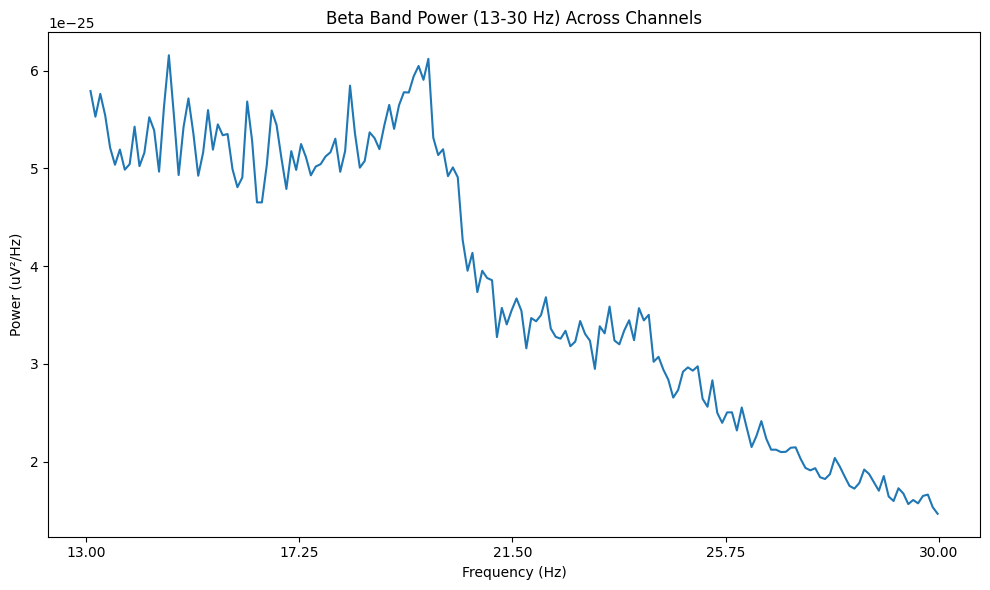

Extracted Beta Band Power (13-30 Hz) successfully.


In [833]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [834]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d79 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d79.head())
print(d79.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [835]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d79_clean = d79.replace([np.inf, -np.inf], np.nan)
d79_clean = d79_clean.fillna(d79_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d79_scaled = pd.DataFrame(
    scaler.fit_transform(d79_clean),
    columns=d79_clean.columns,
    index=d79_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d79_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d79_scaled.index,
    columns=d79_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d79_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df79 = d79_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df79["Pd_indicator_meg"] = 0

print("\nShape of df5:", df79.shape)
print(df79.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [836]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778, df79], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4345    3.740541             0.066835          6.058000e-12  0.823129   
4346    3.978378             0.062840          3.463596e-13  0.738370   
4347    3.713514             0.067322          6.658237e-12  0.847747   
4348    4.021622             0.062164          6.112105e-12  0.813804   
4349    3.832432           

In [837]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879.to_csv('/content/drive/MyDrive/combined_features_upto_sub0079_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879 preserved.")


RAM Used After Cleanup: 0.61 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879 preserved.


sub-80

In [838]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-80'  # Replace with your folder path


In [839]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-080_scans.tsv', 'meg']


In [840]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-080_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-080_coordsystem.json', 'sub-080_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-080_task-go_run-1_proc-tsss+mc_events.json', 'sub-080_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-080_task-go_run-1_proc-tsss+mc_meg.json', 'sub-080_task-noise_proc-tsss_channels.tsv', 'sub-080_task-noise_proc-tsss_meg.fif', 'sub-080_task-noise_proc-tsss_meg.json', 'sub-080_task-passive_run-1_proc-tsss+mc_events.json', 'sub-080_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-080_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-080_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-080_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-080_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-080_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-080_task-rest_run-1_proc-tsss+mc_events.json', 'sub-080_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-080_task-rest_run-1_proc-tsss+mc_meg.json']


In [841]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-080_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-080_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-080_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-080_task-rest_run-1_proc-tsss+mc_meg.fif']


In [842]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-80/meg/sub-080_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [843]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-80/meg/sub-080_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 53000 ... 247999 =     53.000 ...   247.999 secs
Ready.
Reading 0 ... 194999  =      0.000 ...   194.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


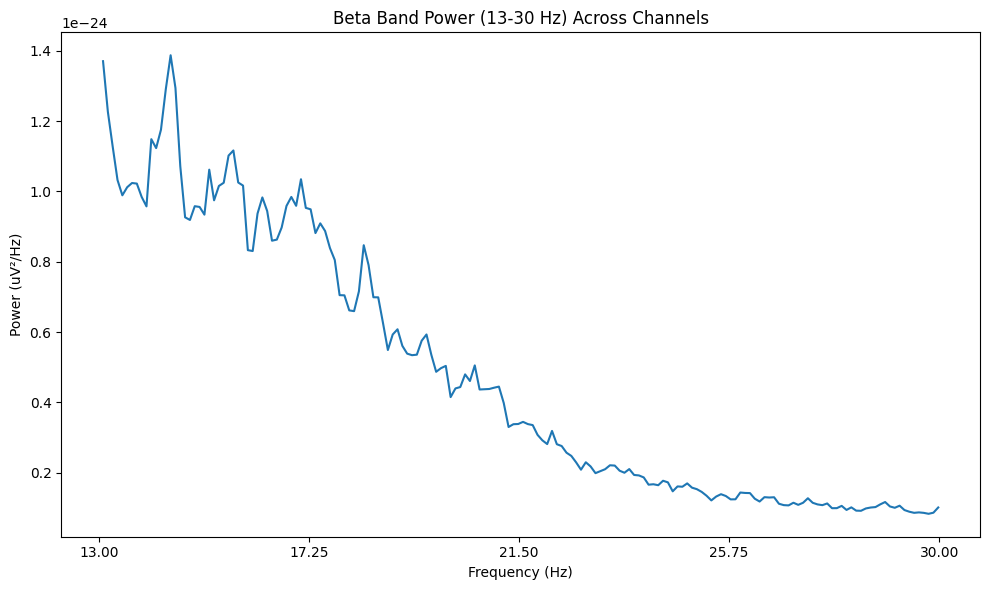

Extracted Beta Band Power (13-30 Hz) successfully.


In [844]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [845]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d80 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d80.head())
print(d80.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [846]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d80_clean = d80.replace([np.inf, -np.inf], np.nan)
d80_clean = d80_clean.fillna(d80_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d80_scaled = pd.DataFrame(
    scaler.fit_transform(d80_clean),
    columns=d80_clean.columns,
    index=d80_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d80_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d80_scaled.index,
    columns=d80_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d80_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df80 = d80_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df80["Pd_indicator_meg"] = 1

print("\nShape of df5:", df80.shape)
print(df80.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [847]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879, df80], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4403    3.138462             0.079657          8.035879e-12  1.216844   
4404    3.025641             0.082449          4.450480e-13  1.245905   
4405    3.169231             0.078819          7.450242e-12  1.183473   
4406    3.138462             0.079657          7.931828e-12  1.320387   
4407    3.025641         

In [848]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980.to_csv('/content/drive/MyDrive/combined_features_upto_sub0080_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980 preserved.")


RAM Used After Cleanup: 0.61 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980 preserved.


sub-81

In [849]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-81'  # Replace with your folder path


In [850]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-081_scans.tsv', 'meg']


In [851]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-081_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-081_coordsystem.json', 'sub-081_task-go_run-1_proc-tsss+mc_events.json', 'sub-081_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-081_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-081_task-go_run-1_proc-tsss+mc_meg.json', 'sub-081_task-noise_proc-tsss_channels.tsv', 'sub-081_task-noise_proc-tsss_meg.fif', 'sub-081_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-081_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-081_task-passive_run-1_proc-tsss+mc_events.json', 'sub-081_task-noise_proc-tsss_meg.json', 'sub-081_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-081_task-rest_run-1_proc-tsss+mc_events.json', 'sub-081_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-081_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-081_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-081_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-081_task-rest_run-1_proc-tsss+mc_meg.json']


In [852]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-081_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-081_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-081_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-081_task-rest_run-1_proc-tsss+mc_meg.fif']


In [853]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-81/meg/sub-081_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [854]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-81/meg/sub-081_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 44000 ... 237999 =     44.000 ...   237.999 secs
Ready.
Reading 0 ... 193999  =      0.000 ...   193.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


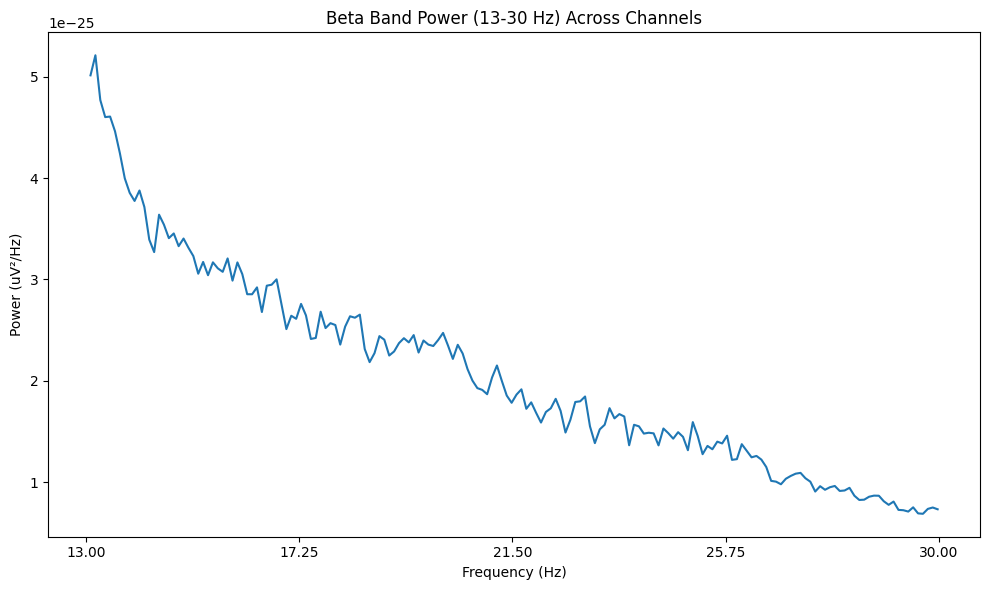

Extracted Beta Band Power (13-30 Hz) successfully.


In [855]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [856]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d81 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d81.head())
print(d81.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [857]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d81_clean = d81.replace([np.inf, -np.inf], np.nan)
d81_clean = d81_clean.fillna(d81_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d81_scaled = pd.DataFrame(
    scaler.fit_transform(d81_clean),
    columns=d81_clean.columns,
    index=d81_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d81_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d81_scaled.index,
    columns=d81_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d81_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df81 = d81_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df81["Pd_indicator_meg"] = 0

print("\nShape of df5:", df81.shape)
print(df81.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [858]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980, df81], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4461    4.443299             0.056212          3.743977e-12  0.765159   
4462    4.448454             0.056199          2.351708e-13  0.827103   
4463    4.469072             0.055882          4.759492e-12  0.798534   
4464    4.201031             0.059509          4.486650e-12  0.853744   
4465    4.402062       

In [859]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081.to_csv('/content/drive/MyDrive/combined_features_upto_0081_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081 preserved.


sub-82

In [860]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-82'  # Replace with your folder path


In [861]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-082_scans.tsv', 'meg']


In [862]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-082_coordsystem.json', 'sub-082_task-go_run-1_proc-tsss+mc_events.json', 'sub-082_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-082_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-082_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-082_task-noise_proc-tsss_meg.fif', 'sub-082_task-go_run-1_proc-tsss+mc_meg.json', 'sub-082_task-noise_proc-tsss_channels.tsv', 'sub-082_task-noise_proc-tsss_meg.json', 'sub-082_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-082_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-082_task-passive_run-1_proc-tsss+mc_events.json', 'sub-082_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-082_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-082_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-082_task-rest_run-1_proc-tsss+mc_events.json', 'sub-082_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-082_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-082_task-rest_run-1_proc-tsss+mc_meg.json']


In [863]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-082_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-082_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-082_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-082_task-rest_run-1_proc-tsss+mc_meg.fif']


In [864]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-82/meg/sub-082_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [865]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-82/meg/sub-082_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 12000 ... 198999 =     12.000 ...   198.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


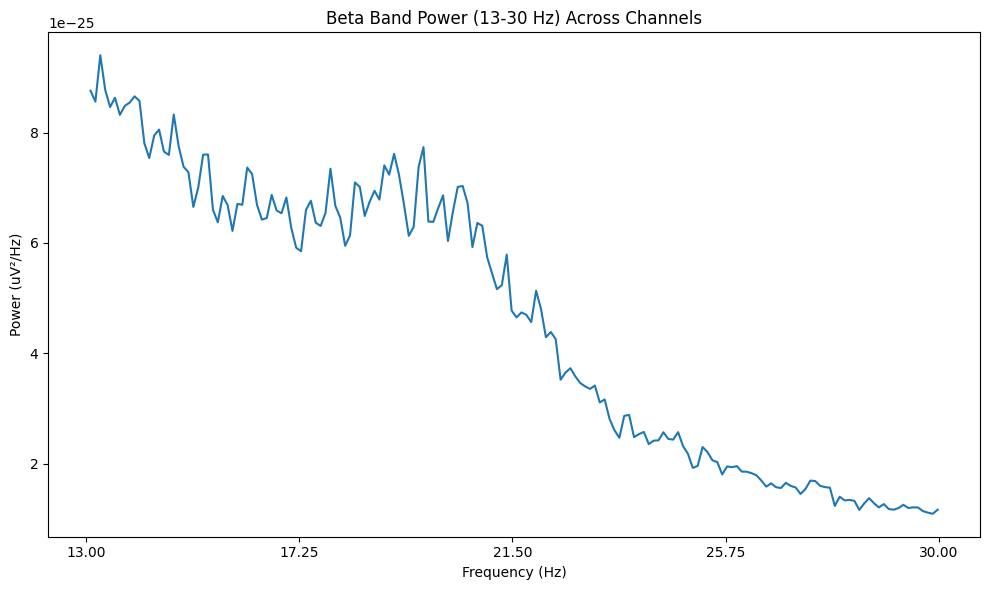

Extracted Beta Band Power (13-30 Hz) successfully.


In [866]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [867]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d82 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d82.head())
print(d82.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [868]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d82_clean = d82.replace([np.inf, -np.inf], np.nan)
d82_clean = d82_clean.fillna(d82_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d82_scaled = pd.DataFrame(
    scaler.fit_transform(d82_clean),
    columns=d82_clean.columns,
    index=d82_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d82_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d82_scaled.index,
    columns=d82_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d82_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df82 = d82_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df82["Pd_indicator_meg"] = 1

print("\nShape of df5:", df82.shape)
print(df82.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [869]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081, df82], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4519    3.598930             0.069465          8.600776e-12  0.781779   
4520    3.700535             0.067507          4.605071e-13  0.827989   
4521    3.743316             0.066786          8.631510e-12  0.847386   
4522    3.727273             0.067073          8.346148e-12  0.816567   
4523    3.641711     

In [870]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182.to_csv('/content/drive/MyDrive/combined_features_upto_sub0082_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182 preserved.


sub-83

In [871]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-83'  # Replace with your folder path


In [872]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-083_scans.tsv', 'meg']


In [873]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-083_coordsystem.json', 'sub-083_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-083_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-083_task-go_run-1_proc-tsss+mc_events.json', 'sub-083_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-083_task-noise_proc-tsss_channels.tsv', 'sub-083_task-go_run-1_proc-tsss+mc_meg.json', 'sub-083_task-noise_proc-tsss_meg.fif', 'sub-083_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-083_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-083_task-noise_proc-tsss_meg.json', 'sub-083_task-passive_run-1_proc-tsss+mc_events.json', 'sub-083_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-083_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-083_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-083_task-rest_run-1_proc-tsss+mc_events.json', 'sub-083_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-083_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-083_task-rest_run-1_proc-tsss+mc_meg.json']


In [874]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-083_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-083_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-083_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-083_task-rest_run-1_proc-tsss+mc_meg.fif']


In [875]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-83/meg/sub-083_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [876]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-83/meg/sub-083_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 12000 ... 203999 =     12.000 ...   203.999 secs
Ready.
Reading 0 ... 191999  =      0.000 ...   191.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


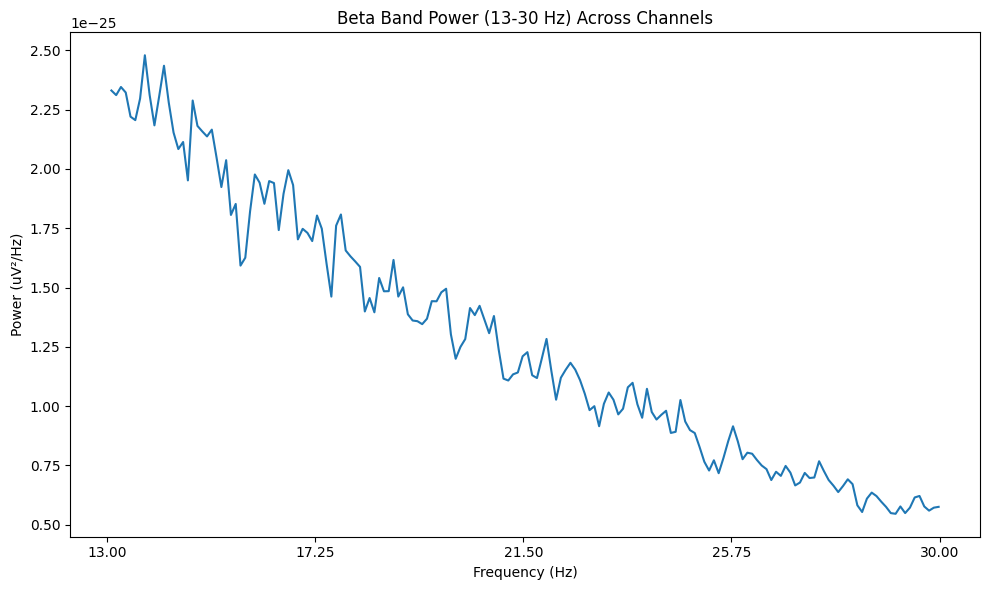

Extracted Beta Band Power (13-30 Hz) successfully.


In [877]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [878]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d83 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d83.head())
print(d83.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [879]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d83_clean = d83.replace([np.inf, -np.inf], np.nan)
d83_clean = d83_clean.fillna(d83_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d83_scaled = pd.DataFrame(
    scaler.fit_transform(d83_clean),
    columns=d83_clean.columns,
    index=d83_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d83_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d83_scaled.index,
    columns=d83_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d83_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df83 = d83_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df83["Pd_indicator_meg"] = 1

print("\nShape of df5:", df83.shape)
print(df83.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [880]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182, df83], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4577    3.781250             0.066116          3.926456e-12  0.953960   
4578    3.921875             0.063692          2.071835e-13  0.920610   
4579    4.036458             0.061935          3.684109e-12  0.860915   
4580    3.937500             0.063492          3.539892e-12  0.912741   
4581    3.859375   

In [881]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283.to_csv(
    '/content/drive/MyDrive/combined_features_upto_sub0083_21.csv',
    index=False
)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283 preserved.


sub-84

In [882]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-84'  # Replace with your folder path


In [883]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-084_scans.tsv', 'meg']


In [884]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-084_coordsystem.json', 'sub-084_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-084_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-084_task-go_run-1_proc-tsss+mc_events.json', 'sub-084_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-084_task-noise_proc-tsss_meg.fif', 'sub-084_task-noise_proc-tsss_channels.tsv', 'sub-084_task-go_run-1_proc-tsss+mc_meg.json', 'sub-084_task-noise_proc-tsss_meg.json', 'sub-084_task-passive_run-1_proc-tsss+mc_events.json', 'sub-084_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-084_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-084_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-084_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-084_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-084_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-084_task-rest_run-1_proc-tsss+mc_events.json', 'sub-084_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-084_task-rest_run-1_proc-tsss+mc_meg.json']


In [885]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-084_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-084_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-084_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-084_task-rest_run-1_proc-tsss+mc_meg.fif']


In [886]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-84/meg/sub-084_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [887]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-84/meg/sub-084_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 10000 ... 194999 =     10.000 ...   194.999 secs
Ready.
Reading 0 ... 184999  =      0.000 ...   184.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


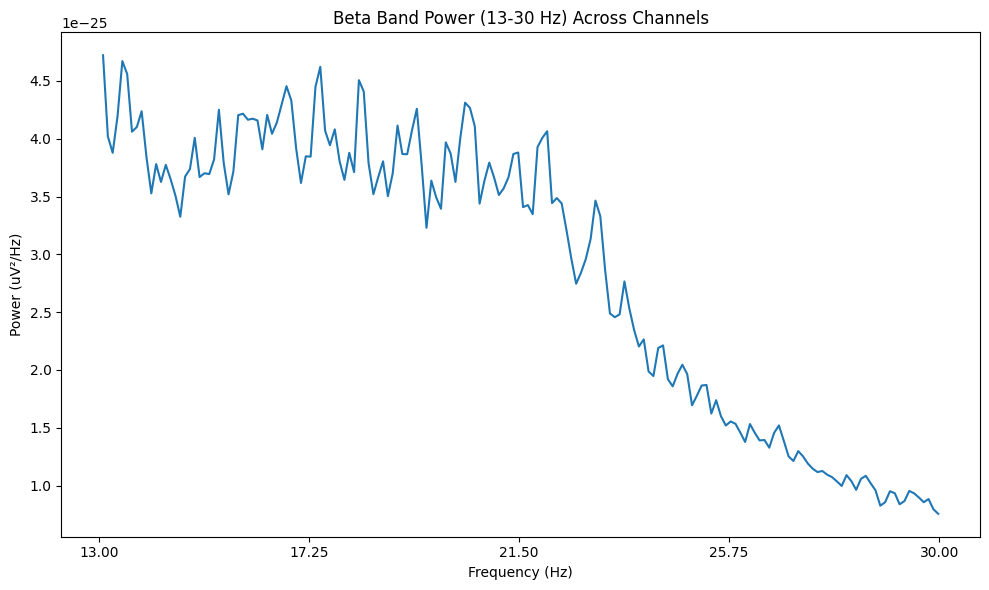

Extracted Beta Band Power (13-30 Hz) successfully.


In [888]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [889]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d84 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d84.head())
print(d84.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [890]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d84_clean = d84.replace([np.inf, -np.inf], np.nan)
d84_clean = d84_clean.fillna(d84_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d84_scaled = pd.DataFrame(
    scaler.fit_transform(d84_clean),
    columns=d84_clean.columns,
    index=d84_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d84_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d84_scaled.index,
    columns=d84_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d84_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df84 = d84_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df84["Pd_indicator_meg"] = 1

print("\nShape of df5:", df84.shape)
print(df84.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [891]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283, df84], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4635    3.859459             0.064776          6.732301e-12  0.857018   
4636    3.962162             0.063097          3.788091e-13  0.816040   
4637    3.913514             0.063881          7.720288e-12  0.793321   
4638    3.978378             0.062840          7.653153e-12  0.810419   
4639    3.767568 

In [892]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384.to_csv('/content/drive/MyDrive/combined_features_upto_sub0084_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384 preserved.


sub-85

In [893]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-85'  # Replace with your folder path


In [894]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-085_scans.tsv', 'meg']


In [895]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-085_coordsystem.json', 'sub-085_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-085_task-go_run-1_proc-tsss+mc_events.json', 'sub-085_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-085_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-085_task-go_run-1_proc-tsss+mc_meg.json', 'sub-085_task-noise_proc-tsss_channels.tsv', 'sub-085_task-noise_proc-tsss_meg.fif', 'sub-085_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-085_task-noise_proc-tsss_meg.json', 'sub-085_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-085_task-passive_run-1_proc-tsss+mc_events.json', 'sub-085_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-085_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-085_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-085_task-rest_run-1_proc-tsss+mc_events.json', 'sub-085_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-085_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-085_task-rest_run-1_proc-tsss+mc_meg.json']


In [896]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-085_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-085_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-085_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-085_task-rest_run-1_proc-tsss+mc_meg.fif']


In [897]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-85/meg/sub-085_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [898]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-85/meg/sub-085_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 92000 ... 282999 =     92.000 ...   282.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


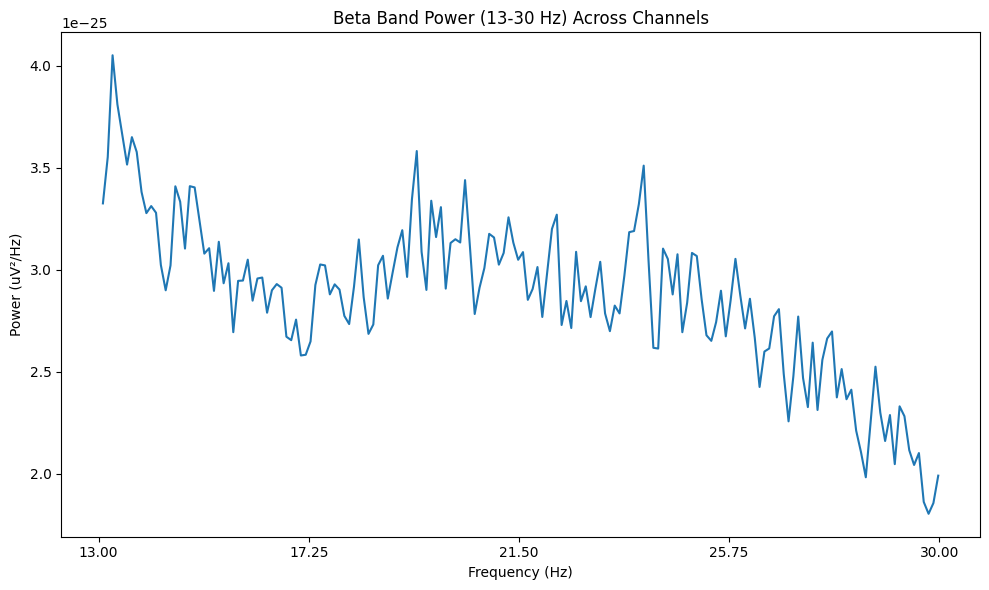

Extracted Beta Band Power (13-30 Hz) successfully.


In [899]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [900]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d85 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d85.head())
print(d85.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [901]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d85_clean = d85.replace([np.inf, -np.inf], np.nan)
d85_clean = d85_clean.fillna(d85_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d85_scaled = pd.DataFrame(
    scaler.fit_transform(d85_clean),
    columns=d85_clean.columns,
    index=d85_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d85_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d85_scaled.index,
    columns=d85_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d85_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df85 = d85_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df85["Pd_indicator_meg"] = 1

print("\nShape of df5:", df85.shape)
print(df85.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [902]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384, df85], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4693    4.151832             0.060214          6.700299e-12  0.791627   
4694    3.958115             0.063161          3.270423e-13  0.927334   
4695    4.335079             0.057669          6.423292e-12  0.850794   
4696    4.047120             0.061772          6.287788e-12  0.899615   
4697    4.20942

In [903]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485.to_csv('/content/drive/MyDrive/combined_features_upto_sub0085_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485 preserved.


sub-86

In [904]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-86'  # Replace with your folder path


In [905]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-086_scans.tsv', 'meg']


In [906]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-086_task-go_run-1_proc-tsss+mc_events.json', 'sub-086_coordsystem.json', 'sub-086_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-086_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-086_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-086_task-go_run-1_proc-tsss+mc_meg.json', 'sub-086_task-noise_proc-tsss_meg.fif', 'sub-086_task-noise_proc-tsss_channels.tsv', 'sub-086_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-086_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-086_task-passive_run-1_proc-tsss+mc_events.json', 'sub-086_task-noise_proc-tsss_meg.json', 'sub-086_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-086_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-086_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-086_task-rest_run-1_proc-tsss+mc_events.json', 'sub-086_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-086_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-086_task-rest_run-1_proc-tsss+mc_meg.json']


In [907]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-086_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-086_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-086_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-086_task-rest_run-1_proc-tsss+mc_meg.fif']


In [908]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-86/meg/sub-086_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [909]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-86/meg/sub-086_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 24000 ... 210999 =     24.000 ...   210.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


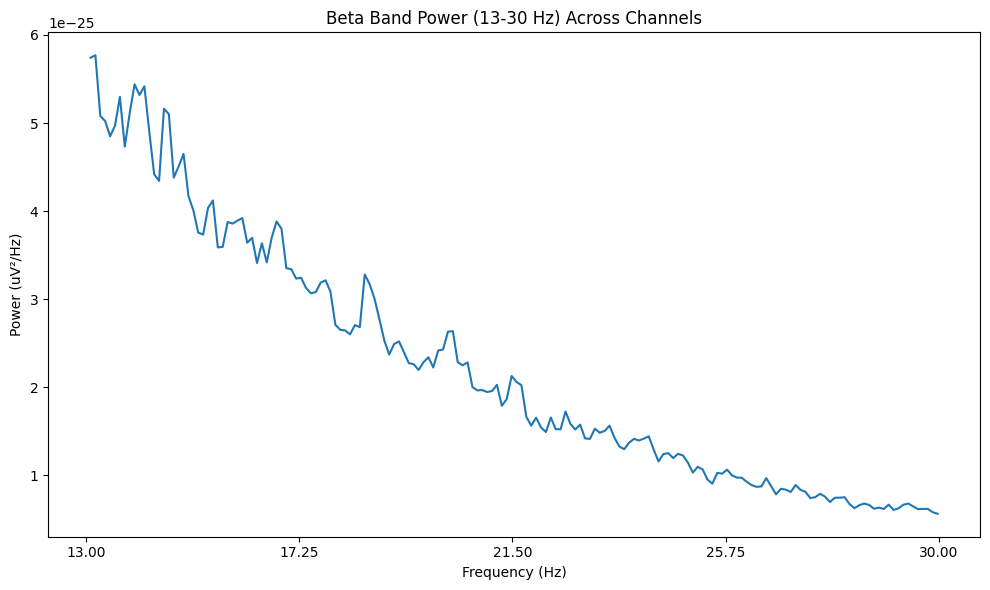

Extracted Beta Band Power (13-30 Hz) successfully.


In [910]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [911]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d86 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d86.head())
print(d86.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [912]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d86_clean = d86.replace([np.inf, -np.inf], np.nan)
d86_clean = d86_clean.fillna(d86_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d86_scaled = pd.DataFrame(
    scaler.fit_transform(d86_clean),
    columns=d86_clean.columns,
    index=d86_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d86_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d86_scaled.index,
    columns=d86_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d86_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df86 = d86_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df86["Pd_indicator_meg"] = 1

print("\nShape of df5:", df86.shape)
print(df86.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [913]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485, df86], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4751    3.914439             0.063866          4.625662e-12  0.906798   
4752    3.491979             0.071593          2.922361e-13  0.965941   
4753    3.962567             0.063090          4.650842e-12  0.977027   
4754    3.737968             0.066831          4.574173e-12  0.897444   
4755    3.481

In [914]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586.to_csv('/content/drive/MyDrive/combined_features_upto_sub0086_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586 preserved.")


RAM Used After Cleanup: 0.66 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586 preserved.


sub-87

In [915]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-87'  # Replace with your folder path


In [916]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-087_scans.tsv', 'meg']


In [917]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-087_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-087_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-087_task-go_run-1_proc-tsss+mc_events.json', 'sub-087_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-087_coordsystem.json', 'sub-087_task-go_run-1_proc-tsss+mc_meg.json', 'sub-087_task-noise_proc-tsss_meg.fif', 'sub-087_task-noise_proc-tsss_channels.tsv', 'sub-087_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-087_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-087_task-passive_run-1_proc-tsss+mc_events.json', 'sub-087_task-noise_proc-tsss_meg.json', 'sub-087_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-087_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-087_task-rest_run-1_proc-tsss+mc_events.json', 'sub-087_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-087_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-087_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-087_task-rest_run-1_proc-tsss+mc_meg.json']


In [918]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-087_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-087_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-087_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-087_task-rest_run-1_proc-tsss+mc_meg.fif']


In [919]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-87/meg/sub-087_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [920]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-87/meg/sub-087_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 32000 ... 221999 =     32.000 ...   221.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


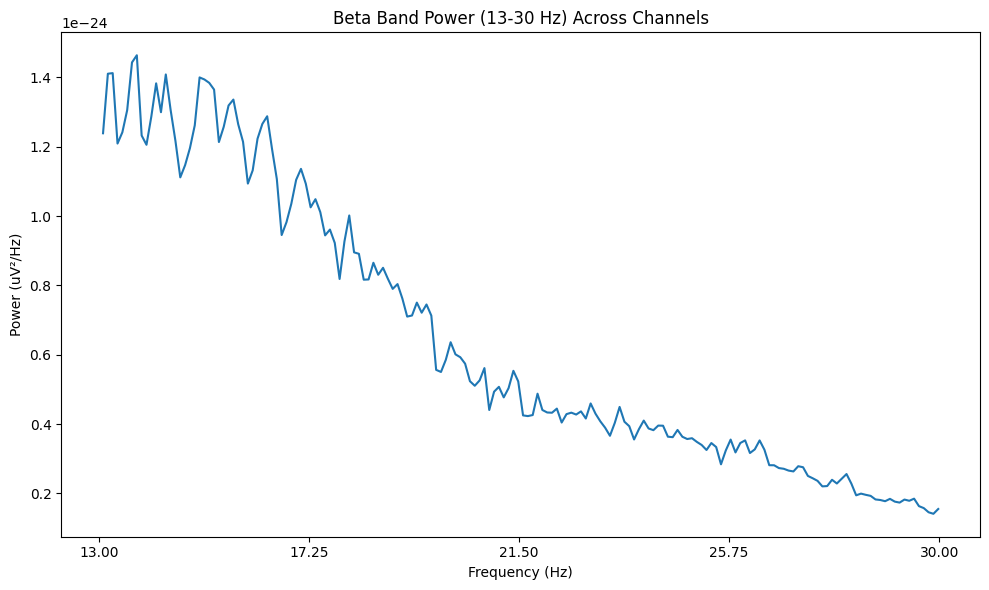

Extracted Beta Band Power (13-30 Hz) successfully.


In [921]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [922]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d87 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d87.head())
print(d87.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [923]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d87_clean = d87.replace([np.inf, -np.inf], np.nan)
d87_clean = d87_clean.fillna(d87_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d87_scaled = pd.DataFrame(
    scaler.fit_transform(d87_clean),
    columns=d87_clean.columns,
    index=d87_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d87_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d87_scaled.index,
    columns=d87_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d87_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df87 = d87_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df87["Pd_indicator_meg"] = 0

print("\nShape of df5:", df87.shape)
print(df87.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [924]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586, df87], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4809    4.352632             0.057437          7.286116e-12  0.863913   
4810    3.957895             0.063165          5.261492e-13  0.888482   
4811    4.000000             0.062500          9.630488e-12  0.922922   
4812    4.357895             0.057367          9.193889e-12  0.829917   
4813    3.9

In [925]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687.to_csv('/content/drive/MyDrive/combined_features_upto_sub0087_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687 preserved.


sub-88

In [926]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-88'  # Replace with your folder path


In [927]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-088_scans.tsv', 'meg']


In [928]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-088_task-go_run-1_proc-tsss+mc_events.json', 'sub-088_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-088_coordsystem.json', 'sub-088_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-088_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-088_task-go_run-1_proc-tsss+mc_meg.json', 'sub-088_task-noise_proc-tsss_meg.fif', 'sub-088_task-noise_proc-tsss_channels.tsv', 'sub-088_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-088_task-passive_run-1_proc-tsss+mc_events.json', 'sub-088_task-noise_proc-tsss_meg.json', 'sub-088_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-088_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-088_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-088_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-088_task-rest_run-1_proc-tsss+mc_events.json', 'sub-088_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-088_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-088_task-rest_run-1_proc-tsss+mc_meg.json']


In [929]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-088_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-088_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-088_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-088_task-rest_run-1_proc-tsss+mc_meg.fif']


In [930]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-88/meg/sub-088_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [931]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-88/meg/sub-088_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 13000 ... 196999 =     13.000 ...   196.999 secs
Ready.
Reading 0 ... 183999  =      0.000 ...   183.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


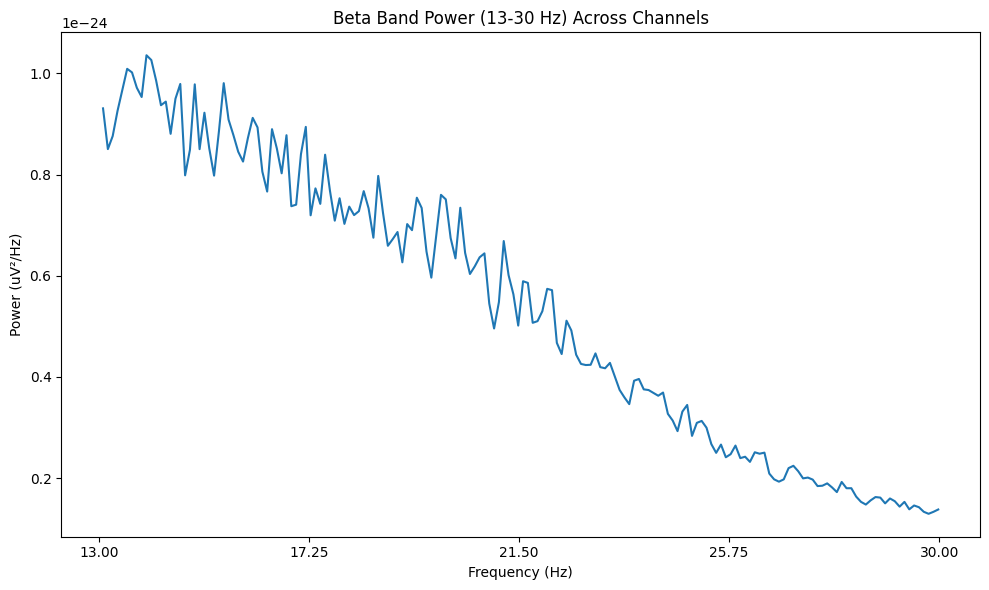

Extracted Beta Band Power (13-30 Hz) successfully.


In [932]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [933]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d88 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d88.head())
print(d88.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [934]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d88_clean = d88.replace([np.inf, -np.inf], np.nan)
d88_clean = d88_clean.fillna(d88_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d88_scaled = pd.DataFrame(
    scaler.fit_transform(d88_clean),
    columns=d88_clean.columns,
    index=d88_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d88_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d88_scaled.index,
    columns=d88_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d88_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df88 = d88_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df88["Pd_indicator_meg"] = 0

print("\nShape of df5:", df88.shape)
print(df88.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [935]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687, df88], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4867    3.777174             0.066187          9.292796e-12  0.888987   
4868    3.711957             0.067350          5.155495e-13  1.015341   
4869    3.777174             0.066187          8.852360e-12  0.929100   
4870    3.554348             0.070336          1.027410e-11  1.056226   
4871    3

In [936]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788.to_csv('/content/drive/MyDrive/combined_features_upto_sub0088_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788 preserved.


sub-89

In [937]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-89'  # Replace with your folder path


In [938]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-089_scans.tsv', 'meg']


In [939]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-089_coordsystem.json', 'sub-089_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-089_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-089_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-089_task-go_run-1_proc-tsss+mc_events.json', 'sub-089_task-go_run-1_proc-tsss+mc_meg.json', 'sub-089_task-noise_proc-tsss_meg.fif', 'sub-089_task-noise_proc-tsss_channels.tsv', 'sub-089_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-089_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-089_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-089_task-passive_run-1_proc-tsss+mc_events.json', 'sub-089_task-noise_proc-tsss_meg.json', 'sub-089_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-089_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-089_task-rest_run-1_proc-tsss+mc_events.json', 'sub-089_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-089_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-089_task-rest_run-1_proc-tsss+mc_meg.json']


In [940]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-089_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-089_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-089_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-089_task-rest_run-1_proc-tsss+mc_meg.fif']


In [941]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-89/meg/sub-089_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [942]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-89/meg/sub-089_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 512000 ... 699999 =    512.000 ...   699.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


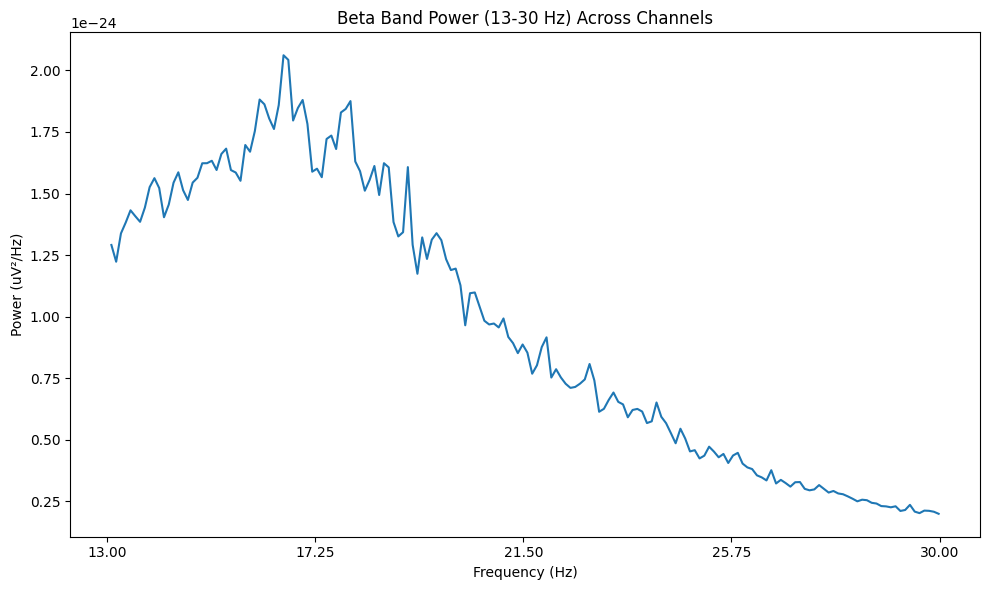

Extracted Beta Band Power (13-30 Hz) successfully.


In [943]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [944]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d89 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d89.head())
print(d89.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [945]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d89_clean = d89.replace([np.inf, -np.inf], np.nan)
d89_clean = d89_clean.fillna(d89_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d89_scaled = pd.DataFrame(
    scaler.fit_transform(d89_clean),
    columns=d89_clean.columns,
    index=d89_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d89_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d89_scaled.index,
    columns=d89_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d89_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df89 = d89_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df89["Pd_indicator_meg"] = 1

print("\nShape of df5:", df89.shape)
print(df89.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [946]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788, df89], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4925    3.335106             0.074960          1.003350e-11  0.838872   
4926    3.324468             0.075200          6.933265e-13  0.885629   
4927    3.526596             0.070890          9.931770e-12  0.866042   
4928    3.542553             0.070571          9.344839e-12  1.022110   
4929   

In [947]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889.to_csv('/content/drive/MyDrive/combined_features_upto_sub0089_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889 preserved.


sub-90

In [948]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-90'  # Replace with your folder path


In [949]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-090_scans.tsv', 'meg']


In [950]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-090_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-090_coordsystem.json', 'sub-090_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-090_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-090_task-go_run-1_proc-tsss+mc_events.json', 'sub-090_task-noise_proc-tsss_channels.tsv', 'sub-090_task-noise_proc-tsss_meg.fif', 'sub-090_task-go_run-1_proc-tsss+mc_meg.json', 'sub-090_task-noise_proc-tsss_meg.json', 'sub-090_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-090_task-passive_run-1_proc-tsss+mc_events.json', 'sub-090_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-090_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-090_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-090_task-rest_run-1_proc-tsss+mc_events.json', 'sub-090_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-090_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-090_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-090_task-rest_run-1_proc-tsss+mc_meg.json']


In [951]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-090_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-090_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-090_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-090_task-rest_run-1_proc-tsss+mc_meg.fif']


In [952]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-90/meg/sub-090_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [953]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-90/meg/sub-090_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 198999 =      8.000 ...   198.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


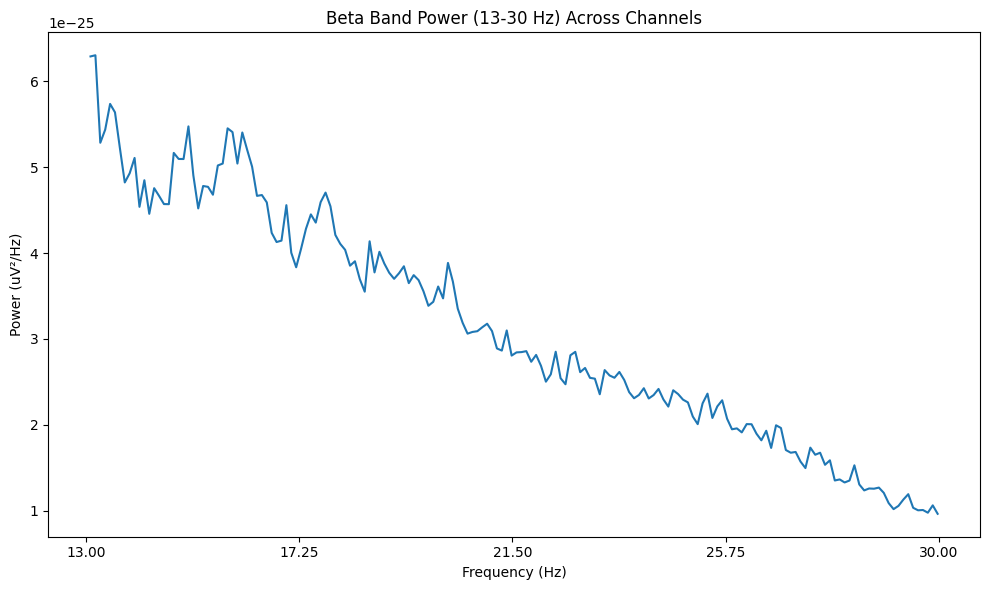

Extracted Beta Band Power (13-30 Hz) successfully.


In [954]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [955]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d90 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d90.head())
print(d90.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [956]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d90_clean = d90.replace([np.inf, -np.inf], np.nan)
d90_clean = d90_clean.fillna(d90_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d90_scaled = pd.DataFrame(
    scaler.fit_transform(d90_clean),
    columns=d90_clean.columns,
    index=d90_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d90_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d90_scaled.index,
    columns=d90_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d90_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df90 = d90_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df90["Pd_indicator_meg"] = 1

print("\nShape of df5:", df90.shape)
print(df90.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [957]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889, df90], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
4983    3.973822             0.062912          7.415376e-12  0.888061   
4984    4.000000             0.062500          3.304585e-13  0.909848   
4985    4.005236             0.062418          6.932026e-12  0.924368   
4986    4.272251             0.058517          5.847581e-12  0.852019   
4987 

In [958]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990.to_csv('/content/drive/MyDrive/combined_features_upto_sub0090_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990 preserved.


sub-91

In [959]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-91'  # Replace with your folder path


In [960]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-091_scans.tsv', 'meg']


In [961]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-091_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-091_task-go_run-1_proc-tsss+mc_events.json', 'sub-091_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-091_coordsystem.json', 'sub-091_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-091_task-go_run-1_proc-tsss+mc_meg.json', 'sub-091_task-noise_proc-tsss_channels.tsv', 'sub-091_task-noise_proc-tsss_meg.fif', 'sub-091_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-091_task-noise_proc-tsss_meg.json', 'sub-091_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-091_task-passive_run-1_proc-tsss+mc_events.json', 'sub-091_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-091_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-091_task-rest_run-1_proc-tsss+mc_events.json', 'sub-091_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-091_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-091_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-091_task-rest_run-1_proc-tsss+mc_meg.json']


In [962]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-091_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-091_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-091_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-091_task-rest_run-1_proc-tsss+mc_meg.fif']


In [963]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-91/meg/sub-091_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [964]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-91/meg/sub-091_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 20000 ... 207999 =     20.000 ...   207.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing power Spectral Density

Effective window size : 10.240 (s)


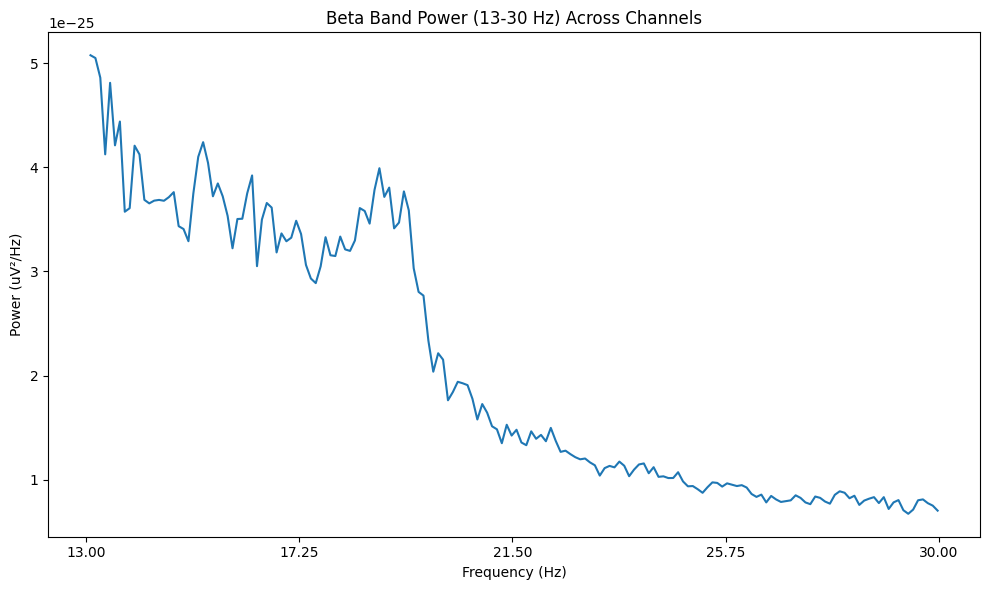

Extracted Beta Band Power (13-30 Hz) successfully.


In [965]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [966]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d91 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d91.head())
print(d91.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [967]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d91_clean = d91.replace([np.inf, -np.inf], np.nan)
d91_clean = d91_clean.fillna(d91_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d91_scaled = pd.DataFrame(
    scaler.fit_transform(d91_clean),
    columns=d91_clean.columns,
    index=d91_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d91_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d91_scaled.index,
    columns=d91_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d91_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df91 = d91_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df91["Pd_indicator_meg"] = 0

print("\nShape of df5:", df91.shape)
print(df91.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [968]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990, df91], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5041    4.691489             0.053288          2.275412e-12  0.794120   
5042    4.547872             0.054971          1.552377e-13  0.834600   
5043    4.643617             0.053837          2.491555e-12  0.781965   
5044    4.622340             0.054085          2.226914e-12  0.764792   
504

In [969]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091.to_csv('/content/drive/MyDrive/combined_features_upto_sub0091_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091 preserved.


sub-93

In [970]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-93'  # Replace with your folder path


In [971]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-093_scans.tsv', 'meg']


In [972]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-093_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-093_coordsystem.json', 'sub-093_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-093_task-go_run-1_proc-tsss+mc_events.json', 'sub-093_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-093_task-noise_proc-tsss_meg.fif', 'sub-093_task-go_run-1_proc-tsss+mc_meg.json', 'sub-093_task-noise_proc-tsss_channels.tsv', 'sub-093_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-093_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-093_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-093_task-passive_run-1_proc-tsss+mc_events.json', 'sub-093_task-noise_proc-tsss_meg.json', 'sub-093_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-093_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-093_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-093_task-rest_run-1_proc-tsss+mc_events.json', 'sub-093_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-093_task-rest_run-1_proc-tsss+mc_meg.json']


In [973]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-093_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-093_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-093_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-093_task-rest_run-1_proc-tsss+mc_meg.fif']


In [974]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-93/meg/sub-093_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [975]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-93/meg/sub-093_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 13000 ... 197999 =     13.000 ...   197.999 secs
Ready.
Reading 0 ... 184999  =      0.000 ...   184.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


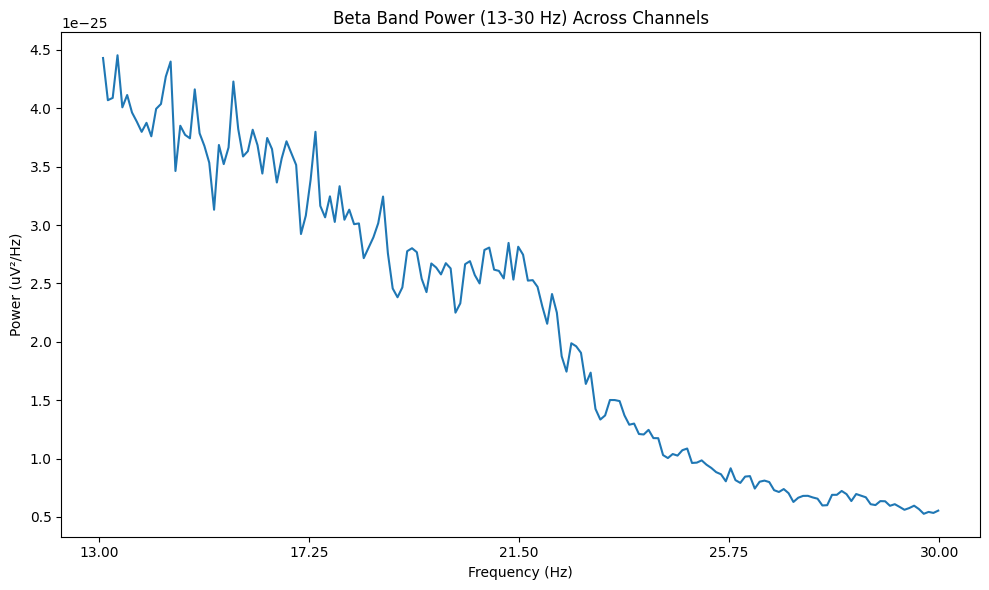

Extracted Beta Band Power (13-30 Hz) successfully.


In [976]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [977]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d93 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d93.head())
print(d93.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [978]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d93_clean = d93.replace([np.inf, -np.inf], np.nan)
d93_clean = d93_clean.fillna(d93_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d93_scaled = pd.DataFrame(
    scaler.fit_transform(d93_clean),
    columns=d93_clean.columns,
    index=d93_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d93_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d93_scaled.index,
    columns=d93_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d93_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df93 = d93_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df93["Pd_indicator_meg"] = 1

print("\nShape of df5:", df93.shape)
print(df93.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [979]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091, df93], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5099    3.891892             0.064236          4.323198e-12  0.817101   
5100    3.691892             0.067716          2.573320e-13  0.730097   
5101    3.978378             0.062840          4.478507e-12  0.856941   
5102    3.843243             0.065049          4.322454e-12  0.794774   
5

In [980]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193.to_csv('/content/drive/MyDrive/combined_features_upto_sub0093_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193 preserved.")


RAM Used After Cleanup: 0.62 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193 preserved.


sub-94

In [981]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-94'  # Replace with your folder path


In [982]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-094_scans.tsv', 'meg']


In [983]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-094_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-094_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-094_coordsystem.json', 'sub-094_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-094_task-go_run-1_proc-tsss+mc_events.json', 'sub-094_task-noise_proc-tsss_channels.tsv', 'sub-094_task-go_run-1_proc-tsss+mc_meg.json', 'sub-094_task-noise_proc-tsss_meg.fif', 'sub-094_task-passive_run-1_proc-tsss+mc_events.json', 'sub-094_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-094_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-094_task-noise_proc-tsss_meg.json', 'sub-094_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-094_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-094_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-094_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-094_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-094_task-rest_run-1_proc-tsss+mc_events.json', 'sub-094_task-rest_run-1_proc-tsss+mc_meg.json']


In [984]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-094_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-094_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-094_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-094_task-rest_run-1_proc-tsss+mc_meg.fif']


In [985]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-94/meg/sub-094_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [986]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-94/meg/sub-094_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 74000 ... 260999 =     74.000 ...   260.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


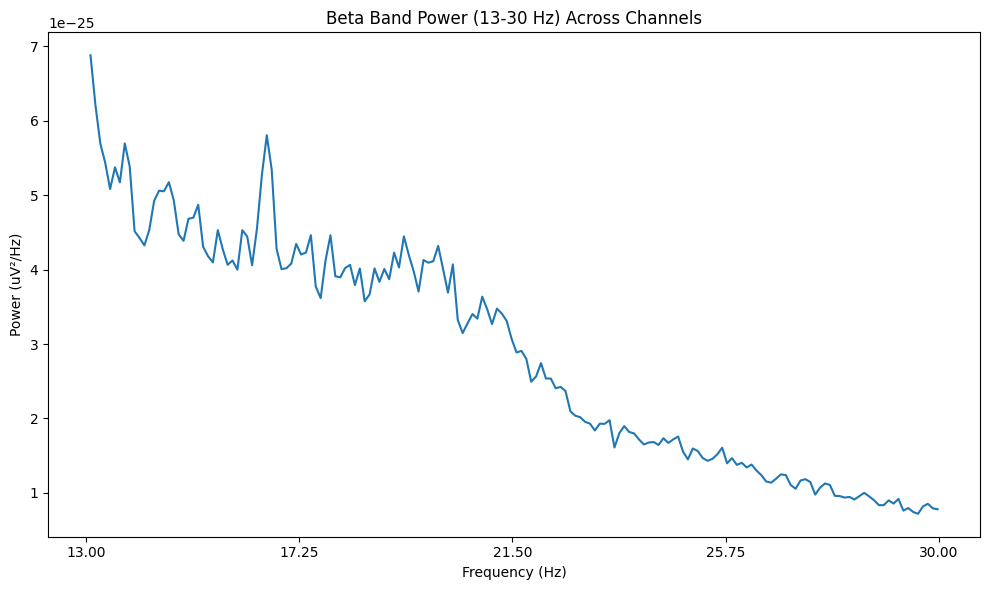

Extracted Beta Band Power (13-30 Hz) successfully.


In [987]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [988]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d94 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d94.head())
print(d94.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [989]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d94_clean = d94.replace([np.inf, -np.inf], np.nan)
d94_clean = d94_clean.fillna(d94_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d94_scaled = pd.DataFrame(
    scaler.fit_transform(d94_clean),
    columns=d94_clean.columns,
    index=d94_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d94_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d94_scaled.index,
    columns=d94_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d94_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df94 = d94_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df94["Pd_indicator_meg"] = 1

print("\nShape of df5:", df94.shape)
print(df94.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [990]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193, df94], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5157    3.834225             0.065202          4.711929e-12  0.835414   
5158    3.978610             0.062836          2.856197e-13  0.836218   
5159    4.048128             0.061757          5.118688e-12  0.808875   
5160    3.866310             0.064661          5.719374e-12  0.964106   

In [991]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394.to_csv('/content/drive/MyDrive/combined_features_upto_sub0094_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394 preserved.")


RAM Used After Cleanup: 0.67 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394 preserved.


sub-95

In [992]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-95'  # Replace with your folder path


In [993]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-095_scans.tsv', 'meg']


In [994]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-095_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-095_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-095_coordsystem.json', 'sub-095_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-095_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-095_task-go_run-1_proc-tsss+mc_meg.json', 'sub-095_task-passive_run-1_proc-tsss+mc_events.json', 'sub-095_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-095_task-go_run-1_proc-tsss+mc_events.json', 'sub-095_task-noise_proc-tsss_meg.json', 'sub-095_task-noise_proc-tsss_channels.tsv', 'sub-095_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-095_task-rest_run-1_proc-tsss+mc_events.json', 'sub-095_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-095_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-095_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-095_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-095_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-095_task-noise_proc-tsss_meg.fif']


In [995]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'passive': ['sub-095_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-095_task-rest_run-1_proc-tsss+mc_meg.fif']
Task 'go': ['sub-095_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-095_task-noise_proc-tsss_meg.fif']


In [996]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-95/meg/sub-095_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [997]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-95/meg/sub-095_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 39000 ... 293999 =     39.000 ...   293.999 secs
Ready.
Reading 0 ... 254999  =      0.000 ...   254.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


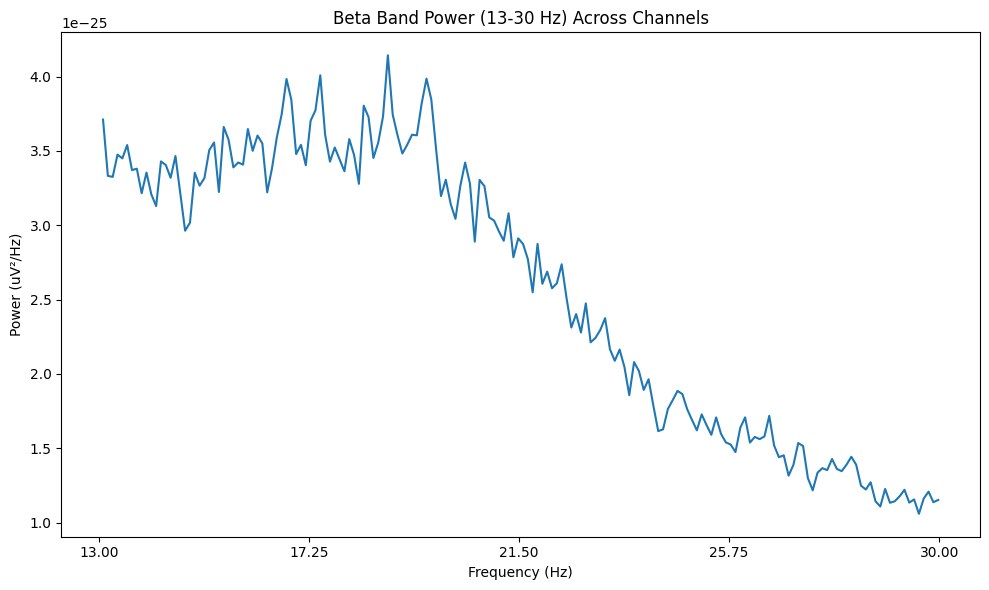

Extracted Beta Band Power (13-30 Hz) successfully.


In [998]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [999]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d95 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d95.head())
print(d95.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [1000]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d95_clean = d95.replace([np.inf, -np.inf], np.nan)
d95_clean = d95_clean.fillna(d95_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d95_scaled = pd.DataFrame(
    scaler.fit_transform(d95_clean),
    columns=d95_clean.columns,
    index=d95_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d95_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d95_scaled.index,
    columns=d95_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d95_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df95 = d95_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df95["Pd_indicator_meg"] = 1

print("\nShape of df5:", df95.shape)
print(df95.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [1001]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394, df95], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5215    3.533333             0.070755          5.810004e-12  0.987033   
5216    3.643137             0.068622          2.877014e-13  0.899777   
5217    3.929412             0.063623          5.463898e-12  0.931548   
5218    3.894118             0.064199          5.261914e-12  0.808783 

In [1002]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495.to_csv('/content/drive/MyDrive/combined_features_upto_sub0095_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495 preserved.")


RAM Used After Cleanup: 0.70 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495 preserved.


sub-96

In [1003]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-96'  # Replace with your folder path


In [1004]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-096_scans.tsv', 'meg']


In [1005]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-096_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-096_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-096_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-096_coordsystem.json', 'sub-096_task-go_run-1_proc-tsss+mc_events.json', 'sub-096_task-go_run-1_proc-tsss+mc_meg.json', 'sub-096_task-noise_proc-tsss_meg.fif', 'sub-096_task-noise_proc-tsss_channels.tsv', 'sub-096_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-096_task-passive_run-1_proc-tsss+mc_events.json', 'sub-096_task-noise_proc-tsss_meg.json', 'sub-096_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-096_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-096_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-096_task-rest_run-1_proc-tsss+mc_events.json', 'sub-096_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-096_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-096_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-096_task-rest_run-1_proc-tsss+mc_meg.json']


In [1006]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-096_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-096_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-096_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-096_task-rest_run-1_proc-tsss+mc_meg.fif']


In [1007]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-96/meg/sub-096_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [1008]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-96/meg/sub-096_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 38000 ... 235999 =     38.000 ...   235.999 secs
Ready.
Reading 0 ... 197999  =      0.000 ...   197.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


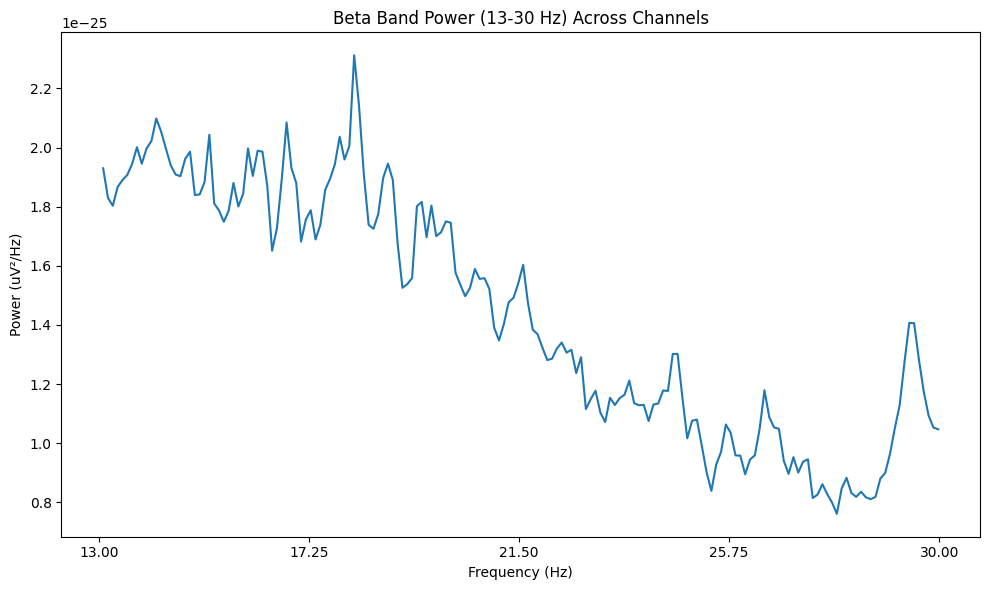

Extracted Beta Band Power (13-30 Hz) successfully.


In [1009]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [1010]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d96 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d96.head())
print(d96.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [1011]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d96_clean = d96.replace([np.inf, -np.inf], np.nan)
d96_clean = d96_clean.fillna(d96_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d96_scaled = pd.DataFrame(
    scaler.fit_transform(d96_clean),
    columns=d96_clean.columns,
    index=d96_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d96_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d96_scaled.index,
    columns=d96_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d96_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df96 = d96_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df96["Pd_indicator_meg"] = 0

print("\nShape of df5:", df96.shape)
print(df96.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [1012]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495, df96], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5273    4.000000             0.062500          3.521984e-12  0.819785   
5274    3.772727             0.066265          1.969950e-13  0.755878   
5275    4.207071             0.059424          3.403883e-12  0.747102   
5276    4.055556             0.061644          3.059433e-12  0.77715

In [1013]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596.to_csv('/content/drive/MyDrive/combined_features_upto_sub0096_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596 preserved.")


RAM Used After Cleanup: 0.68 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596 preserved.


sub-97

In [1014]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-97'  # Replace with your folder path


In [1015]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-097_scans.tsv', 'meg']


In [1016]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-097_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-097_task-go_run-1_proc-tsss+mc_events.json', 'sub-097_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-097_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-097_coordsystem.json', 'sub-097_task-noise_proc-tsss_channels.tsv', 'sub-097_task-go_run-1_proc-tsss+mc_meg.json', 'sub-097_task-noise_proc-tsss_meg.fif', 'sub-097_task-noise_proc-tsss_meg.json', 'sub-097_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-097_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-097_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-097_task-passive_run-1_proc-tsss+mc_events.json', 'sub-097_task-rest_run-1_proc-tsss+mc_events.json', 'sub-097_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-097_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-097_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-097_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-097_task-rest_run-1_proc-tsss+mc_meg.json']


In [1017]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-097_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-097_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-097_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-097_task-rest_run-1_proc-tsss+mc_meg.fif']


In [1018]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-97/meg/sub-097_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [1019]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-97/meg/sub-097_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 48000 ... 240999 =     48.000 ...   240.999 secs
Ready.
Reading 0 ... 192999  =      0.000 ...   192.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


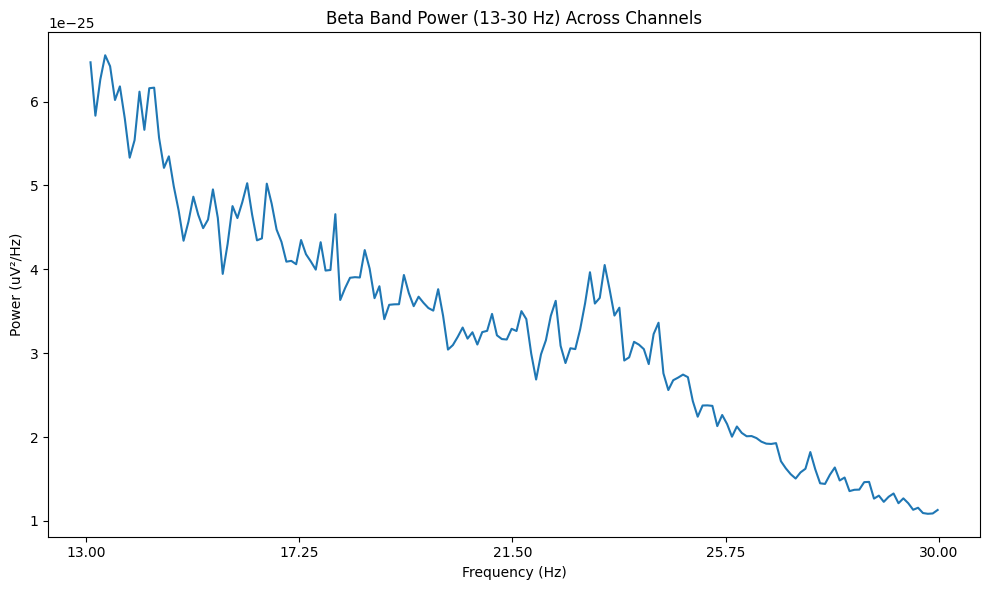

Extracted Beta Band Power (13-30 Hz) successfully.


In [1020]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [1021]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d97 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d97.head())
print(d97.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [1022]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d97_clean = d97.replace([np.inf, -np.inf], np.nan)
d97_clean = d97_clean.fillna(d97_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d97_scaled = pd.DataFrame(
    scaler.fit_transform(d97_clean),
    columns=d97_clean.columns,
    index=d97_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d97_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d97_scaled.index,
    columns=d97_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d97_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df97 = d97_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df97["Pd_indicator_meg"] = 1

print("\nShape of df5:", df97.shape)
print(df97.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [1023]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596, df97], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5331    3.668394             0.068150          7.182903e-12  1.011248   
5332    4.015544             0.062258          3.375692e-13  0.829013   
5333    3.974093             0.062907          6.399868e-12  0.941584   
5334    4.067358             0.061465          6.696475e-12  0.891

In [1024]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697.to_csv('/content/drive/MyDrive/combined_features_upto_sub0097_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697 preserved.")


RAM Used After Cleanup: 0.63 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697 preserved.


sub-98

In [1025]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-98'  # Replace with your folder path


In [1026]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-098_scans.tsv', 'meg']


In [1027]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-098_coordsystem.json', 'sub-098_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-098_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-098_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-098_task-go_run-1_proc-tsss+mc_events.json', 'sub-098_task-go_run-1_proc-tsss+mc_meg.json', 'sub-098_task-noise_proc-tsss_channels.tsv', 'sub-098_task-noise_proc-tsss_meg.fif', 'sub-098_task-noise_proc-tsss_meg.json', 'sub-098_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-098_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-098_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-098_task-passive_run-1_proc-tsss+mc_events.json', 'sub-098_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-098_task-rest_run-1_proc-tsss+mc_events.json', 'sub-098_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-098_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-098_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-098_task-rest_run-1_proc-tsss+mc_meg.json']


In [1028]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-098_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-098_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-098_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-098_task-rest_run-1_proc-tsss+mc_meg.fif']


In [1029]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-98/meg/sub-098_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [1030]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-98/meg/sub-098_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 208999 =     18.000 ...   208.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


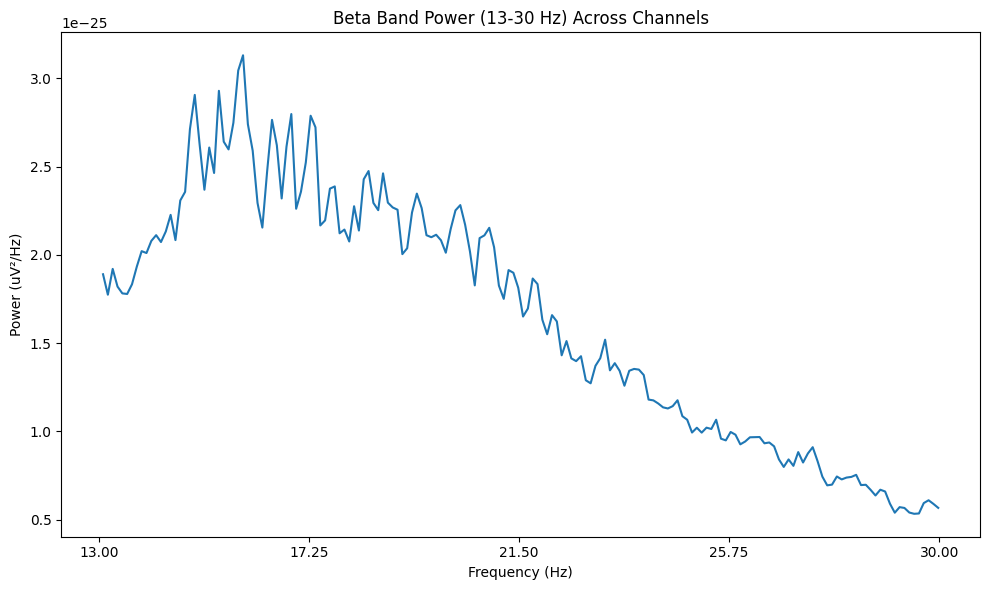

Extracted Beta Band Power (13-30 Hz) successfully.


In [1031]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [1032]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d98 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d98.head())
print(d98.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [1033]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d98_clean = d98.replace([np.inf, -np.inf], np.nan)
d98_clean = d98_clean.fillna(d98_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d98_scaled = pd.DataFrame(
    scaler.fit_transform(d98_clean),
    columns=d98_clean.columns,
    index=d98_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d98_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d98_scaled.index,
    columns=d98_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d98_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df98 = d98_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df98["Pd_indicator_meg"] = 0

print("\nShape of df5:", df98.shape)
print(df98.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [1034]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697, df98], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5389    3.680628             0.067923          5.512402e-12  0.932124   
5390    3.769634             0.066319          1.963702e-13  0.897449   
5391    3.989529             0.062664          3.808597e-12  0.894333   
5392    3.884817             0.064353          3.664613e-12  0.8

In [1035]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798.to_csv('/content/drive/MyDrive/combined_features_upto_sub0098_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798 preserved.")


RAM Used After Cleanup: 0.68 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798 preserved.


sub-99

In [1036]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-99'  # Replace with your folder path


In [1037]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-099_scans.tsv', 'meg']


In [1038]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-099_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-099_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-099_coordsystem.json', 'sub-099_task-go_run-1_proc-tsss+mc_events.json', 'sub-099_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-099_task-noise_proc-tsss_channels.tsv', 'sub-099_task-noise_proc-tsss_meg.fif', 'sub-099_task-go_run-1_proc-tsss+mc_meg.json', 'sub-099_task-passive_run-1_proc-tsss+mc_events.json', 'sub-099_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-099_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-099_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-099_task-noise_proc-tsss_meg.json', 'sub-099_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-099_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-099_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-099_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-099_task-rest_run-1_proc-tsss+mc_events.json', 'sub-099_task-rest_run-1_proc-tsss+mc_meg.json']


In [1039]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-099_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-099_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-099_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-099_task-rest_run-1_proc-tsss+mc_meg.fif']


In [1040]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-99/meg/sub-099_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [1041]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-99/meg/sub-099_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 25000 ... 214999 =     25.000 ...   214.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


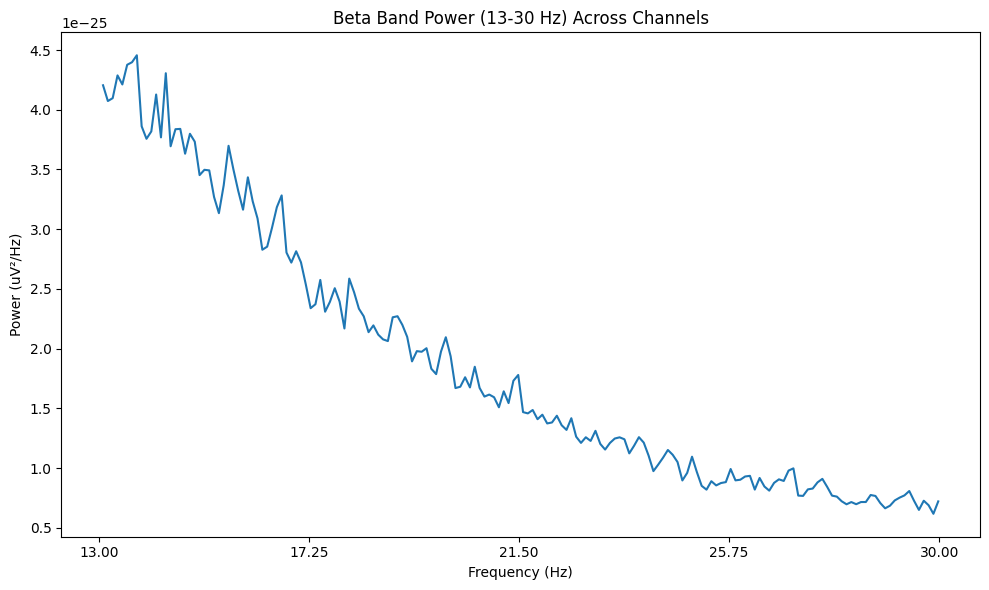

Extracted Beta Band Power (13-30 Hz) successfully.


In [1042]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [1043]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d99 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d99.head())
print(d99.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [1044]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d99_clean = d99.replace([np.inf, -np.inf], np.nan)
d99_clean = d99_clean.fillna(d99_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d99_scaled = pd.DataFrame(
    scaler.fit_transform(d99_clean),
    columns=d99_clean.columns,
    index=d99_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d99_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d99_scaled.index,
    columns=d99_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d99_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df99 = d99_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df99["Pd_indicator_meg"] = 1

print("\nShape of df5:", df99.shape)
print(df99.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [1045]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798, df99], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5447    3.942105             0.063418          3.758751e-12  0.782555   
5448    4.205263             0.059449          1.861615e-13  0.797696   
5449    4.210526             0.059375          3.334141e-12  0.745161   
5450    4.152632             0.060203          3.333790e-12  0

In [1046]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899.to_csv('/content/drive/MyDrive/combined_features_upto_sub0099_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899 preserved.")


RAM Used After Cleanup: 0.64 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899 preserved.


sub-100

In [1047]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-100'  # Replace with your folder path


In [1048]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-100_scans.tsv', 'meg']


In [1049]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-100_coordsystem.json', 'sub-100_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-100_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-100_task-go_run-1_proc-tsss+mc_events.json', 'sub-100_task-go_run-1_proc-tsss+mc_meg.json', 'sub-100_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-100_task-noise_proc-tsss_channels.tsv', 'sub-100_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-100_task-noise_proc-tsss_meg.json', 'sub-100_task-noise_proc-tsss_meg.fif', 'sub-100_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-100_task-passive_run-1_proc-tsss+mc_events.json', 'sub-100_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-100_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-100_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-100_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-100_task-rest_run-1_proc-tsss+mc_events.json', 'sub-100_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-100_task-rest_run-1_proc-tsss+mc_meg.fif']


In [1050]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-100_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-100_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-100_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-100_task-rest_run-1_proc-tsss+mc_meg.fif']


In [1051]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-100/meg/sub-100_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [1052]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-100/meg/sub-100_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 38000 ... 222999 =     38.000 ...   222.999 secs
Ready.
Reading 0 ... 184999  =      0.000 ...   184.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


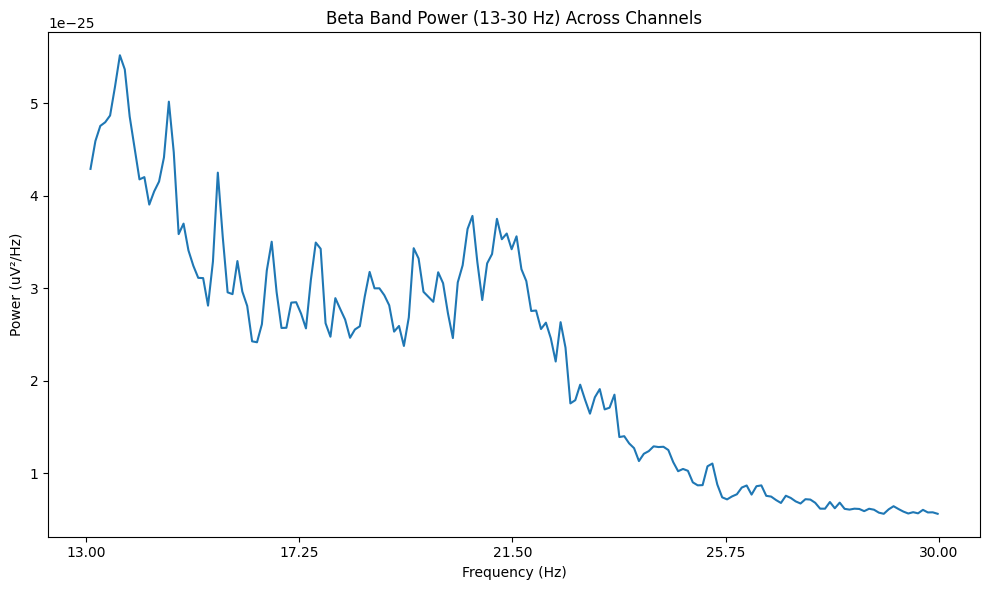

Extracted Beta Band Power (13-30 Hz) successfully.


In [1053]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [1054]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d100 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d100.head())
print(d100.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [1055]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d100_clean = d100.replace([np.inf, -np.inf], np.nan)
d100_clean = d100_clean.fillna(d100_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d100_scaled = pd.DataFrame(
    scaler.fit_transform(d100_clean),
    columns=d100_clean.columns,
    index=d100_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d100_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d100_scaled.index,
    columns=d100_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d100_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df100 = d100_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df100["Pd_indicator_meg"] = 1

print("\nShape of df5:", df100.shape)
print(df100.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [1056]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899, df100], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5505    3.945946             0.063356          5.894435e-12  0.790149   
5506    3.643243             0.068620          3.114115e-13  1.038960   
5507    3.913514             0.063881          4.859484e-12  0.764934   
5508    3.945946             0.063356          5.033439e-12

In [1057]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100.to_csv('/content/drive/MyDrive/combined_features_upto_sub00100_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100 preserved.")


RAM Used After Cleanup: 0.64 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100 preserved.


sub-101

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub00100_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (5510, 22)


In [4]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-101'  # Replace with your folder path


In [5]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-101_scans.tsv', 'meg']


In [6]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-101_task-go_run-1_proc-tsss+mc_events.json', 'sub-101_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-101_coordsystem.json', 'sub-101_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-101_task-go_run-1_proc-tsss+mc_meg.json', 'sub-101_task-noise_proc-tsss_channels.tsv', 'sub-101_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-101_task-noise_proc-tsss_meg.json', 'sub-101_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-101_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-101_task-passive_run-1_proc-tsss+mc_events.json', 'sub-101_task-noise_proc-tsss_meg.fif', 'sub-101_task-rest_run-1_proc-tsss+mc_events.json', 'sub-101_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-101_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-101_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-101_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-101_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-101_task-rest_run-1_proc-tsss+mc_meg.fif']


In [7]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-101_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-101_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-101_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-101_task-rest_run-1_proc-tsss+mc_meg.fif']


In [8]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 26.1 MB/s eta 0:00:00

Found .fif file: /content/drive/MyDrive/sub-101/meg/sub-101_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [9]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-101/meg/sub-101_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 26000 ... 227999 =     26.000 ...   227.999 secs
Ready.
Reading 0 ... 201999  =      0.000 ...   201.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


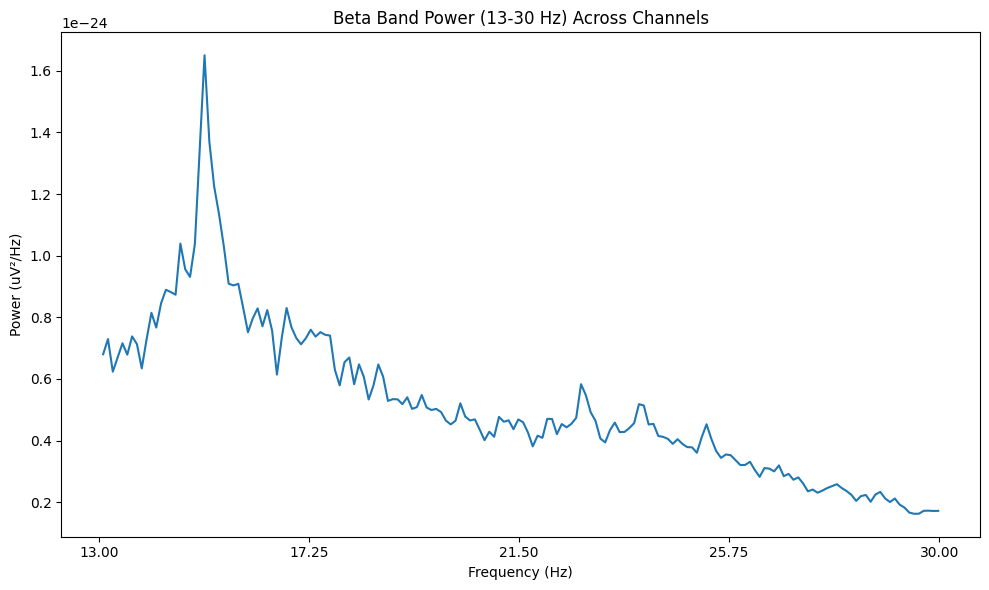

Extracted Beta Band Power (13-30 Hz) successfully.


In [10]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [11]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d101 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d101.head())
print(d101.shape)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 62.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 2.6 MB/s eta 0:00:00
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.12

Extraction of Top 58 channels

In [12]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d101_clean = d101.replace([np.inf, -np.inf], np.nan)
d101_clean = d101_clean.fillna(d101_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d101_scaled = pd.DataFrame(
    scaler.fit_transform(d101_clean),
    columns=d101_clean.columns,
    index=d101_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d101_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d101_scaled.index,
    columns=d101_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d101_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df101 = d101_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df101["Pd_indicator_meg"] = 0

print("\nShape of df5:", df101.shape)
print(df101.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [14]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101 = pd.concat([previous_df,df101], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5563    4.138614             0.060407          3.742543e-12  0.845126   
5564    4.326733             0.057740          3.350145e-12  0.885572   
5565    4.297030             0.058180          1.767375e-13  0.877305   
5566    4.371287             0.057191          3.566117e

In [15]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101.to_csv('/content/drive/MyDrive/combined_features_upto_sub00101_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101 preserved.")


RAM Used After Cleanup: 0.52 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101 preserved.


sub-102

In [16]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub00101_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (5568, 22)


In [18]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-102'  # Replace with your folder path


In [19]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-102_scans.tsv', 'meg']


In [20]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-102_task-go_run-1_proc-tsss+mc_events.json', 'sub-102_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-102_coordsystem.json', 'sub-102_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-102_task-go_run-1_proc-tsss+mc_meg.json', 'sub-102_task-noise_proc-tsss_channels.tsv', 'sub-102_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-102_task-passive_run-1_proc-tsss+mc_events.json', 'sub-102_task-noise_proc-tsss_meg.fif', 'sub-102_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-102_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-102_task-noise_proc-tsss_meg.json', 'sub-102_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-102_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-102_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-102_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-102_task-rest_run-1_proc-tsss+mc_events.json', 'sub-102_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-102_task-rest_run-1_proc-tsss+mc_meg.json']


In [21]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-102_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-102_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-102_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-102_task-rest_run-1_proc-tsss+mc_meg.fif']


In [22]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-102/meg/sub-102_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [23]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-102/meg/sub-102_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 13000 ... 217999 =     13.000 ...   217.999 secs
Ready.
Reading 0 ... 204999  =      0.000 ...   204.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


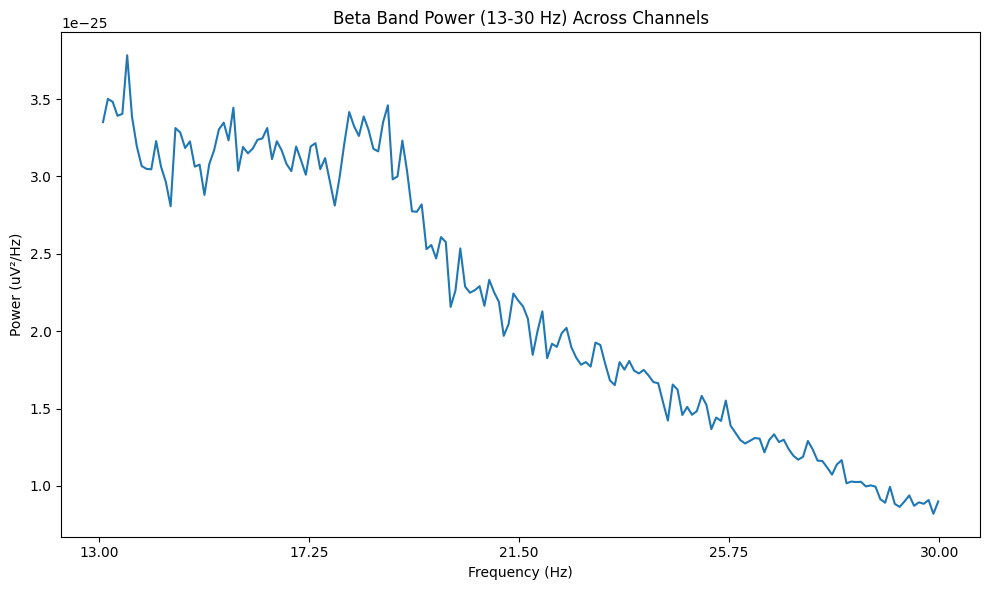

Extracted Beta Band Power (13-30 Hz) successfully.


In [24]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [25]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d102 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d102.head())
print(d102.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [26]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d102_clean = d102.replace([np.inf, -np.inf], np.nan)
d102_clean = d102_clean.fillna(d102_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d102_scaled = pd.DataFrame(
    scaler.fit_transform(d102_clean),
    columns=d102_clean.columns,
    index=d102_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d102_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d102_scaled.index,
    columns=d102_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d102_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df102 = d102_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df102["Pd_indicator_meg"] = 0

print("\nShape of df5:", df102.shape)
print(df102.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [27]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102 = pd.concat([previous_df, df102], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5621    4.292683             0.058239          2.450754e-12  0.780701   
5622    4.180488             0.059802          1.971384e-12  0.745670   
5623    4.302439             0.058107          1.260662e-13  0.770319   
5624    4.360976             0.057327          2.2692

In [28]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102.to_csv('/content/drive/MyDrive/combined_features_upto_sub00102_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102 preserved.")


RAM Used After Cleanup: 0.54 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102 preserved.


sub-103

In [29]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-103'  # Replace with your folder path


In [30]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-103_scans.tsv', 'meg']


In [31]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-103_task-go_run-1_proc-tsss+mc_events.json', 'sub-103_coordsystem.json', 'sub-103_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-103_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-103_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-103_task-go_run-1_proc-tsss+mc_meg.json', 'sub-103_task-noise_proc-tsss_channels.tsv', 'sub-103_task-noise_proc-tsss_meg.fif', 'sub-103_task-noise_proc-tsss_meg.json', 'sub-103_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-103_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-103_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-103_task-passive_run-1_proc-tsss+mc_events.json', 'sub-103_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-103_task-rest_run-1_proc-tsss+mc_events.json', 'sub-103_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-103_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-103_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-103_task-rest_run-1_proc-tsss+mc_meg.json']


In [32]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-103_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-103_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-103_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-103_task-rest_run-1_proc-tsss+mc_meg.fif']


In [33]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-103/meg/sub-103_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [34]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-103/meg/sub-103_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 27000 ... 243999 =     27.000 ...   243.999 secs
Ready.
Reading 0 ... 216999  =      0.000 ...   216.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


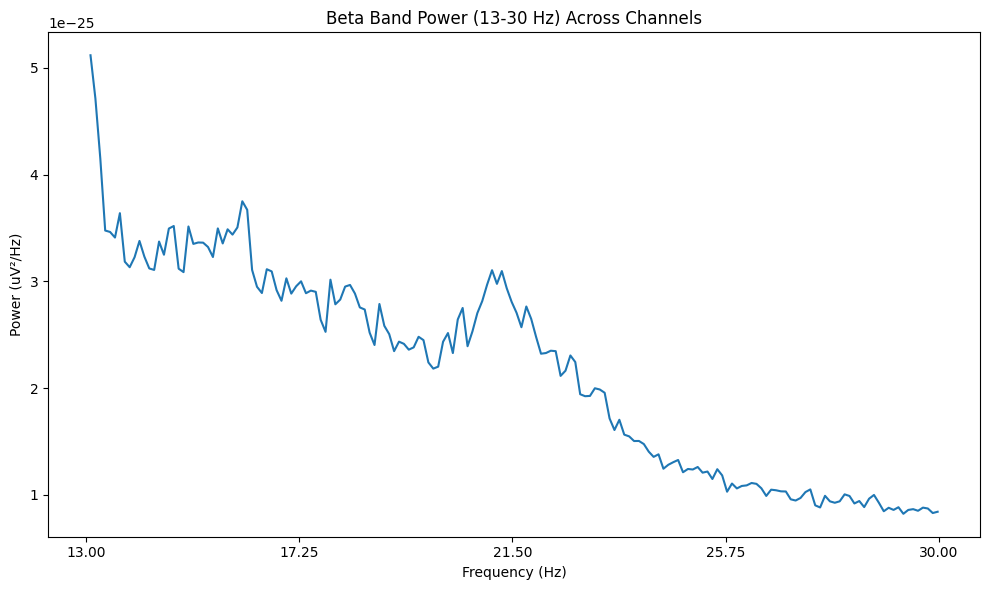

Extracted Beta Band Power (13-30 Hz) successfully.


In [35]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [36]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d103 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d103.head())
print(d103.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [37]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d103_clean = d103.replace([np.inf, -np.inf], np.nan)
d103_clean = d103_clean.fillna(d103_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d103_scaled = pd.DataFrame(
    scaler.fit_transform(d103_clean),
    columns=d103_clean.columns,
    index=d103_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d103_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d103_scaled.index,
    columns=d103_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d103_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df103 = d103_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df103["Pd_indicator_meg"] = 0

print("\nShape of df5:", df103.shape)
print(df103.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [38]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102, df103], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5679    4.230415             0.059096          2.312138e-12  0.681314   
5680    4.258065             0.058712          2.445435e-12  0.751234   
5681    4.198157             0.059550          1.300265e-13  0.759693   
5682    4.313364             0.057959          2.7

In [39]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103.to_csv('/content/drive/MyDrive/combined_features_upto_sub00103_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103 preserved.")


RAM Used After Cleanup: 0.56 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103 preserved.


sub-104

In [40]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-104'  # Replace with your folder path


In [41]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-104_scans.tsv', 'meg']


In [42]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-104_coordsystem.json', 'sub-104_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-104_task-go_run-1_proc-tsss+mc_events.json', 'sub-104_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-104_task-go_run-1_proc-tsss+mc_meg.json', 'sub-104_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-104_task-noise_proc-tsss_channels.tsv', 'sub-104_task-passive_run-1_proc-tsss+mc_events.json', 'sub-104_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-104_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-104_task-noise_proc-tsss_meg.json', 'sub-104_task-noise_proc-tsss_meg.fif', 'sub-104_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-104_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-104_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-104_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-104_task-rest_run-1_proc-tsss+mc_events.json', 'sub-104_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-104_task-rest_run-1_proc-tsss+mc_meg.json']


In [43]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-104_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-104_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-104_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-104_task-rest_run-1_proc-tsss+mc_meg.fif']


In [44]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-104/meg/sub-104_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [45]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-104/meg/sub-104_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 25000 ... 232999 =     25.000 ...   232.999 secs
Ready.
Reading 0 ... 207999  =      0.000 ...   207.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


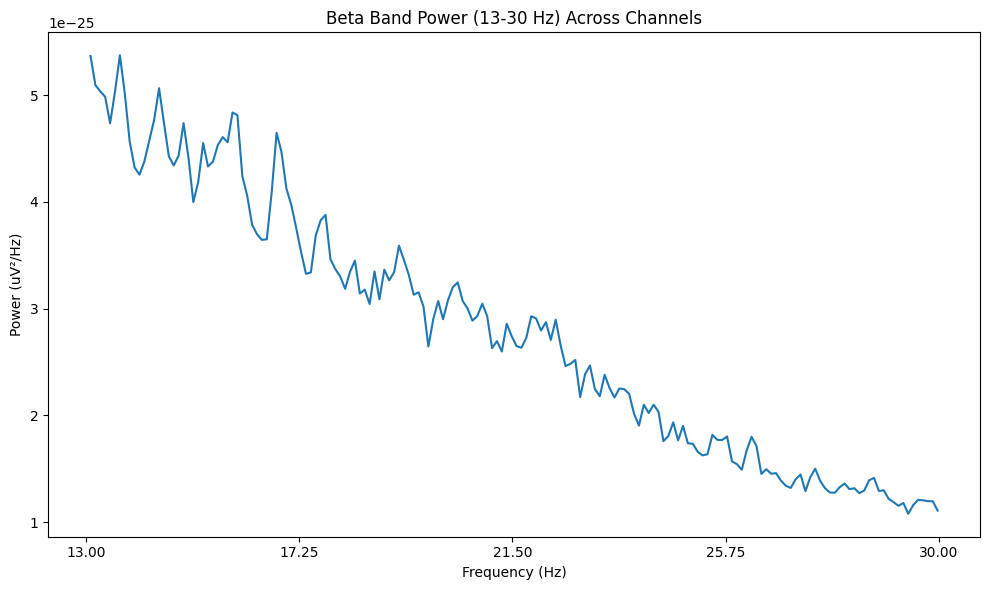

Extracted Beta Band Power (13-30 Hz) successfully.


In [46]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [47]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d104 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d104.head())
print(d104.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [48]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d104_clean = d104.replace([np.inf, -np.inf], np.nan)
d104_clean = d104_clean.fillna(d104_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d104_scaled = pd.DataFrame(
    scaler.fit_transform(d104_clean),
    columns=d104_clean.columns,
    index=d104_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d104_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d104_scaled.index,
    columns=d104_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d104_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df104 = d104_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df104["Pd_indicator_meg"] = 1

print("\nShape of df5:", df104.shape)
print(df104.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [49]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103, df104], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5737    4.076923             0.061321          3.222992e-12  0.799343   
5738    4.139423             0.060395          3.080423e-12  0.892446   
5739    4.052885             0.061684          1.781047e-13  0.815988   
5740    3.865385             0.064677          

In [50]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104.to_csv('/content/drive/MyDrive/combined_features_upto_sub00104_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104 preserved.")


RAM Used After Cleanup: 0.56 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104 preserved.


sub-105

In [51]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-105'  # Replace with your folder path


In [52]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-105_scans.tsv', 'meg']


In [53]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-105_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-105_task-go_run-1_proc-tsss+mc_events.json', 'sub-105_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-105_coordsystem.json', 'sub-105_task-go_run-1_proc-tsss+mc_meg.json', 'sub-105_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-105_task-noise_proc-tsss_channels.tsv', 'sub-105_task-noise_proc-tsss_meg.json', 'sub-105_task-noise_proc-tsss_meg.fif', 'sub-105_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-105_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-105_task-passive_run-1_proc-tsss+mc_events.json', 'sub-105_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-105_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-105_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-105_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-105_task-rest_run-1_proc-tsss+mc_events.json', 'sub-105_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-105_task-rest_run-1_proc-tsss+mc_meg.json']


In [54]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-105_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-105_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-105_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-105_task-rest_run-1_proc-tsss+mc_meg.fif']


In [55]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-105/meg/sub-105_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [56]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-105/meg/sub-105_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 12000 ... 198999 =     12.000 ...   198.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
1 event found on stim channel STI101
Event IDs: [64]
Finding events on: STI101
1 event found on stim channel STI101
Event IDs: [64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitting 

Computing Power Spectral Density

Effective window size : 10.240 (s)


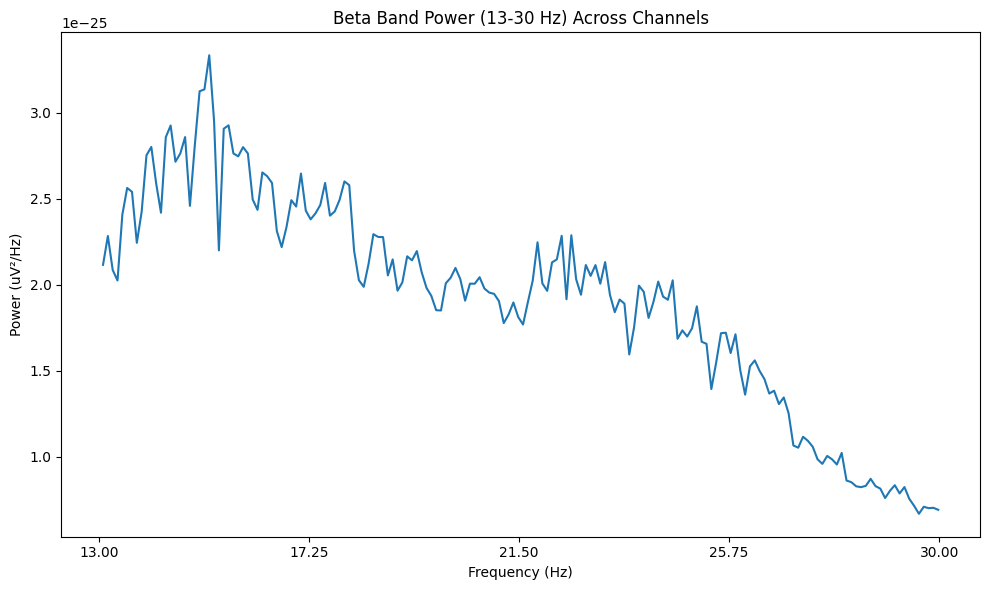

Extracted Beta Band Power (13-30 Hz) successfully.


In [57]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [58]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d105 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d105.head())
print(d105.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [59]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d105_clean = d105.replace([np.inf, -np.inf], np.nan)
d105_clean = d105_clean.fillna(d105_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d105_scaled = pd.DataFrame(
    scaler.fit_transform(d105_clean),
    columns=d105_clean.columns,
    index=d105_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d105_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d105_scaled.index,
    columns=d105_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d105_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df105 = d105_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df105["Pd_indicator_meg"] = 0

print("\nShape of df5:", df105.shape)
print(df105.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [60]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104, df105], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5795    3.828877             0.065293          2.610015e-12  0.781286   
5796    4.085561             0.061191          2.140833e-12  0.785937   
5797    4.540107             0.055065          1.088798e-13  0.735650   
5798    3.930481             0.063605       

In [61]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105.to_csv('/content/drive/MyDrive/combined_features_upto_sub00105_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105 preserved.


sub-106

In [62]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-106'  # Replace with your folder path


In [63]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-106_scans.tsv', 'meg']


In [64]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-106_coordsystem.json', 'sub-106_task-go_run-1_proc-tsss+mc_events.json', 'sub-106_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-106_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-106_task-go_run-1_proc-tsss+mc_meg.json', 'sub-106_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-106_task-noise_proc-tsss_channels.tsv', 'sub-106_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-106_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-106_task-passive_run-1_proc-tsss+mc_events.json', 'sub-106_task-noise_proc-tsss_meg.json', 'sub-106_task-noise_proc-tsss_meg.fif', 'sub-106_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-106_task-rest_run-1_proc-tsss+mc_events.json', 'sub-106_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-106_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-106_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-106_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-106_task-rest_run-1_proc-tsss+mc_meg.fif']


In [65]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-106_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-106_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-106_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-106_task-rest_run-1_proc-tsss+mc_meg.fif']


In [66]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-106/meg/sub-106_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [67]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-106/meg/sub-106_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 146000 ... 335999 =    146.000 ...   335.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA

Computing Power Spectral Density

Effective window size : 10.240 (s)


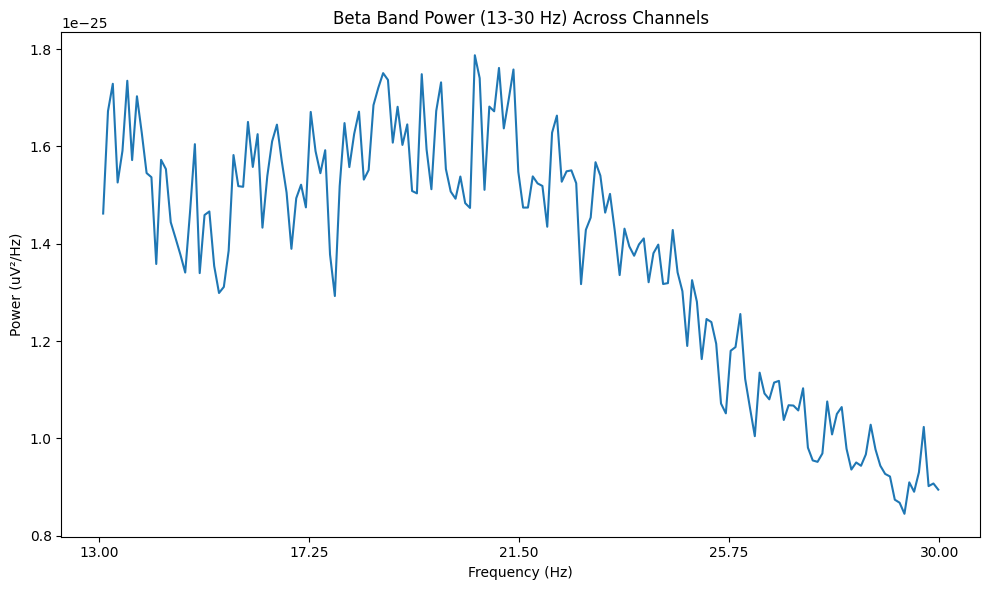

Extracted Beta Band Power (13-30 Hz) successfully.


In [68]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [69]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d106 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d106.head())
print(d106.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [70]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d106_clean = d106.replace([np.inf, -np.inf], np.nan)
d106_clean = d106_clean.fillna(d106_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d106_scaled = pd.DataFrame(
    scaler.fit_transform(d106_clean),
    columns=d106_clean.columns,
    index=d106_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d106_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d106_scaled.index,
    columns=d106_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d106_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df106 = d106_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df106["Pd_indicator_meg"] = 1

print("\nShape of df5:", df106.shape)
print(df106.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [71]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105, df106], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5853    4.478947             0.055817          3.397132e-12  0.698740   
5854    4.447368             0.056213          3.340900e-12  0.722011   
5855    4.647368             0.053794          1.416022e-13  0.716295   
5856    4.615789             0.054162    

In [72]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106.to_csv('/content/drive/MyDrive/combined_features_upto_sub00106_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106 preserved.")


RAM Used After Cleanup: 0.58 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106 preserved.


sub-107

In [73]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-107'  # Replace with your folder path


In [74]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-107_scans.tsv', 'meg']


In [75]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-107_coordsystem.json', 'sub-107_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-107_task-go_run-1_proc-tsss+mc_events.json', 'sub-107_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-107_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-107_task-go_run-1_proc-tsss+mc_meg.json', 'sub-107_task-noise_proc-tsss_channels.tsv', 'sub-107_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-107_task-passive_run-1_proc-tsss+mc_events.json', 'sub-107_task-noise_proc-tsss_meg.json', 'sub-107_task-noise_proc-tsss_meg.fif', 'sub-107_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-107_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-107_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-107_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-107_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-107_task-rest_run-1_proc-tsss+mc_events.json', 'sub-107_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-107_task-rest_run-1_proc-tsss+mc_meg.json']


In [76]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-107_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-107_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-107_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-107_task-rest_run-1_proc-tsss+mc_meg.fif']


In [77]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-107/meg/sub-107_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [78]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-107/meg/sub-107_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 196999 =      8.000 ...   196.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


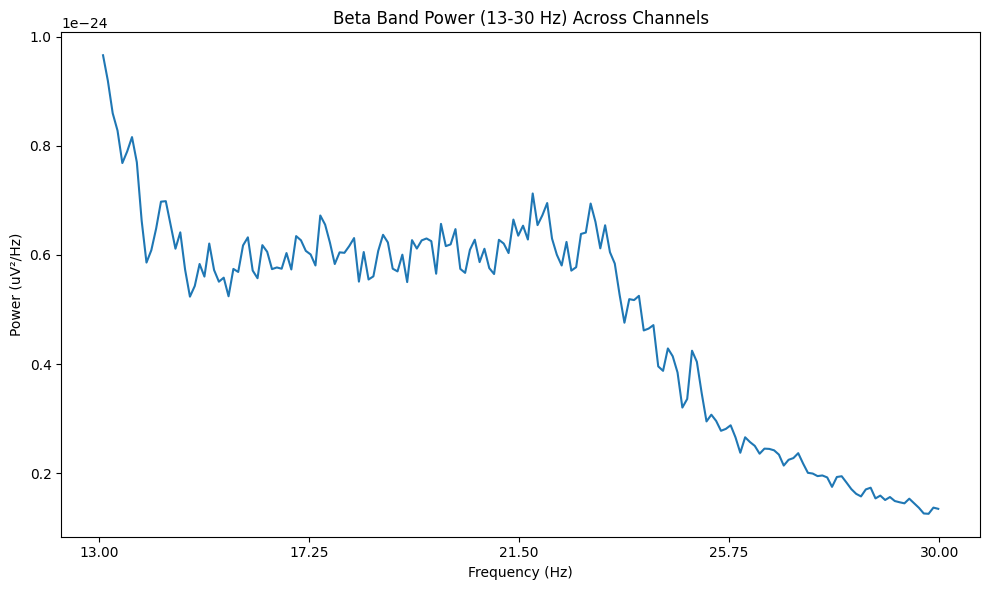

Extracted Beta Band Power (13-30 Hz) successfully.


In [79]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [80]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d107 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d107.head())
print(d107.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [81]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d107_clean = d107.replace([np.inf, -np.inf], np.nan)
d107_clean = d107_clean.fillna(d107_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d107_scaled = pd.DataFrame(
    scaler.fit_transform(d107_clean),
    columns=d107_clean.columns,
    index=d107_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d107_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d107_scaled.index,
    columns=d107_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d107_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df107 = d107_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df107["Pd_indicator_meg"] = 1

print("\nShape of df5:", df107.shape)
print(df107.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [82]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106, df107], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5911    3.671958             0.068084          3.748753e-12  0.890159   
5912    3.783069             0.065979          3.613212e-12  0.835163   
5913    3.751323             0.066643          1.988864e-13  0.790263   
5914    3.809524             0.065625 

In [83]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107.to_csv('/content/drive/MyDrive/combined_features_upto_sub00107_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107 preserved.")


RAM Used After Cleanup: 0.58 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107 preserved.


sub-108

In [84]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-108'  # Replace with your folder path


In [85]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-108_scans.tsv', 'meg']


In [86]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-108_coordsystem.json', 'sub-108_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-108_task-go_run-1_proc-tsss+mc_events.json', 'sub-108_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-108_task-go_run-1_proc-tsss+mc_meg.json', 'sub-108_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-108_task-noise_proc-tsss_channels.tsv', 'sub-108_task-passive_run-1_proc-tsss+mc_events.json', 'sub-108_task-noise_proc-tsss_meg.json', 'sub-108_task-noise_proc-tsss_meg.fif', 'sub-108_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-108_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-108_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-108_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-108_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-108_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-108_task-rest_run-1_proc-tsss+mc_events.json', 'sub-108_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-108_task-rest_run-1_proc-tsss+mc_meg.json']


In [87]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-108_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-108_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-108_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-108_task-rest_run-1_proc-tsss+mc_meg.fif']


In [88]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-108/meg/sub-108_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [89]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-108/meg/sub-108_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 59000 ... 262999 =     59.000 ...   262.999 secs
Ready.
Reading 0 ... 203999  =      0.000 ...   203.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


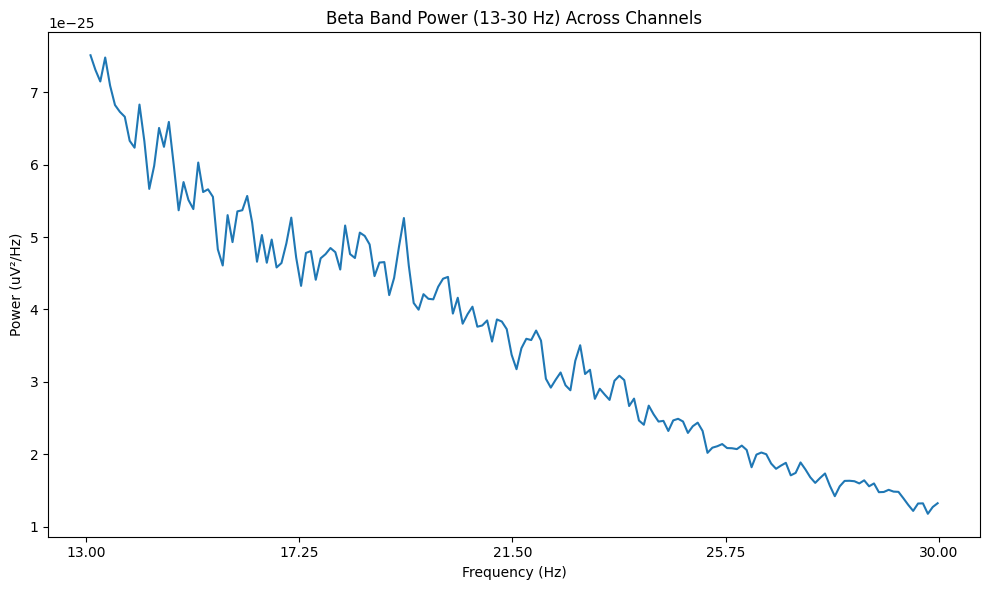

Extracted Beta Band Power (13-30 Hz) successfully.


In [90]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [91]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d108 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d108.head())
print(d108.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [92]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d108_clean = d108.replace([np.inf, -np.inf], np.nan)
d108_clean = d108_clean.fillna(d108_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d108_scaled = pd.DataFrame(
    scaler.fit_transform(d108_clean),
    columns=d108_clean.columns,
    index=d108_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d108_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d108_scaled.index,
    columns=d108_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d108_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df108 = d108_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df108["Pd_indicator_meg"] = 1

print("\nShape of df5:", df108.shape)
print(df108.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [93]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107, df108], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
5969    3.892157             0.064232          4.218989e-12  0.912850   
5970    4.117647             0.060714          3.454087e-12  0.826982   
5971    3.960784             0.063119          1.943789e-13  0.866168   
5972    4.014706             0.0622

In [94]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108.to_csv('/content/drive/MyDrive/combined_features_upto_sub00108_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108 preserved.")


RAM Used After Cleanup: 0.60 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108 preserved.


sub-109

In [95]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-109'  # Replace with your folder path


In [96]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-109_scans.tsv', 'meg']


In [97]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-109_coordsystem.json', 'sub-109_task-go_run-1_proc-tsss+mc_events.json', 'sub-109_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-109_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-109_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-109_task-noise_proc-tsss_channels.tsv', 'sub-109_task-noise_proc-tsss_meg.fif', 'sub-109_task-go_run-1_proc-tsss+mc_meg.json', 'sub-109_task-noise_proc-tsss_meg.json', 'sub-109_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-109_task-passive_run-1_proc-tsss+mc_events.json', 'sub-109_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-109_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-109_task-rest_run-1_proc-tsss+mc_events.json', 'sub-109_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-109_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-109_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-109_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-109_task-rest_run-1_proc-tsss+mc_meg.json']


In [98]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-109_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-109_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-109_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-109_task-rest_run-1_proc-tsss+mc_meg.fif']


In [99]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-109/meg/sub-109_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [100]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-109/meg/sub-109_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 30000 ... 213999 =     30.000 ...   213.999 secs
Ready.
Reading 0 ... 183999  =      0.000 ...   183.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


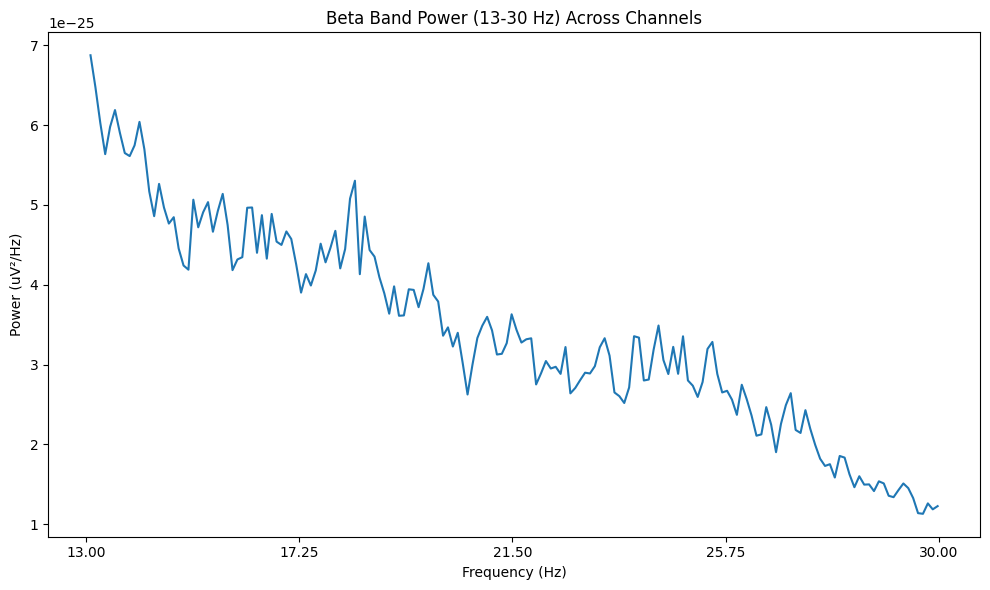

Extracted Beta Band Power (13-30 Hz) successfully.


In [101]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [102]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d109 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d109.head())
print(d109.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [103]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d109_clean = d109.replace([np.inf, -np.inf], np.nan)
d109_clean = d109_clean.fillna(d109_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d109_scaled = pd.DataFrame(
    scaler.fit_transform(d109_clean),
    columns=d109_clean.columns,
    index=d109_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d109_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d109_scaled.index,
    columns=d109_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d109_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df109 = d109_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df109["Pd_indicator_meg"] = 0

print("\nShape of df5:", df109.shape)
print(df109.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [104]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108, df109], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6027    4.304348             0.058030          3.282061e-12  0.762536   
6028    4.195652             0.059585          3.500894e-12  0.882706   
6029    4.135870             0.060447          2.139993e-13  0.948534   
6030    4.152174             0.0

In [105]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109.to_csv('/content/drive/MyDrive/combined_features_upto_sub00109_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109 preserved.")


RAM Used After Cleanup: 0.52 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109 preserved.


sub-110

In [106]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-110'  # Replace with your folder path


In [107]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-110_scans.tsv', 'meg']


In [108]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-110_coordsystem.json', 'sub-110_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-110_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-110_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-110_task-go_run-1_proc-tsss+mc_events.json', 'sub-110_task-noise_proc-tsss_channels.tsv', 'sub-110_task-noise_proc-tsss_meg.fif', 'sub-110_task-go_run-1_proc-tsss+mc_meg.json', 'sub-110_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-110_task-noise_proc-tsss_meg.json', 'sub-110_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-110_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-110_task-passive_run-1_proc-tsss+mc_events.json', 'sub-110_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-110_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-110_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-110_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-110_task-rest_run-1_proc-tsss+mc_events.json', 'sub-110_task-rest_run-1_proc-tsss+mc_meg.json']


In [109]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-110_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-110_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-110_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-110_task-rest_run-1_proc-tsss+mc_meg.fif']


In [110]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-110/meg/sub-110_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [111]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-110/meg/sub-110_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 254999 =      7.000 ...   254.999 secs
Ready.
Reading 0 ... 247999  =      0.000 ...   247.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [1]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [1]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitting I

Computing Power Spectral Density

Effective window size : 10.240 (s)


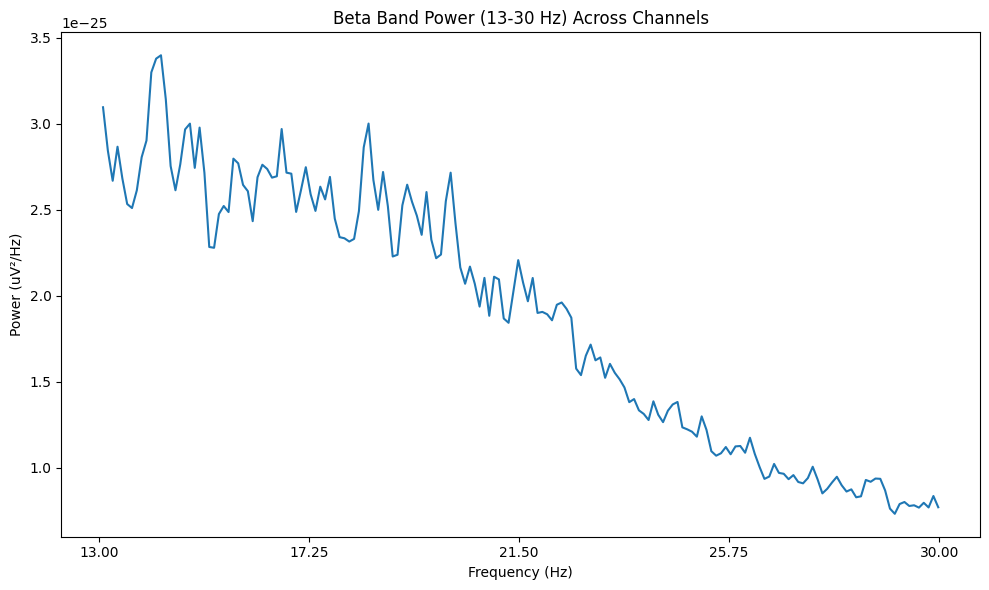

Extracted Beta Band Power (13-30 Hz) successfully.


In [112]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [113]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d110 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d110.head())
print(d110.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [114]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d110_clean = d110.replace([np.inf, -np.inf], np.nan)
d110_clean = d110_clean.fillna(d110_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d110_scaled = pd.DataFrame(
    scaler.fit_transform(d110_clean),
    columns=d110_clean.columns,
    index=d110_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d110_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d110_scaled.index,
    columns=d110_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d110_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df110 = d110_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df110["Pd_indicator_meg"] = 1

print("\nShape of df5:", df110.shape)
print(df110.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [115]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109, df110], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6085    3.717742             0.067202          2.892154e-12  0.833915   
6086    3.939516             0.063408          2.552042e-12  0.849112   
6087    3.939516             0.063460          1.380667e-13  0.776316   
6088    4.004032             

In [116]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110.to_csv('/content/drive/MyDrive/combined_features_upto_sub00110_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110 preserved.


sub-111

In [117]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-111'  # Replace with your folder path


In [118]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-111_scans.tsv', 'meg']


In [119]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-111_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-111_task-go_run-1_proc-tsss+mc_events.json', 'sub-111_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-111_coordsystem.json', 'sub-111_task-go_run-1_proc-tsss+mc_meg.json', 'sub-111_task-noise_proc-tsss_channels.tsv', 'sub-111_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-111_task-noise_proc-tsss_meg.fif', 'sub-111_task-passive_run-1_proc-tsss+mc_events.json', 'sub-111_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-111_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-111_task-noise_proc-tsss_meg.json', 'sub-111_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-111_task-rest_run-1_proc-tsss+mc_events.json', 'sub-111_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-111_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-111_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-111_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-111_task-rest_run-1_proc-tsss+mc_meg.json']


In [120]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-111_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-111_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-111_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-111_task-rest_run-1_proc-tsss+mc_meg.fif']


In [121]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-111/meg/sub-111_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [122]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-111/meg/sub-111_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 58000 ... 246999 =     58.000 ...   246.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


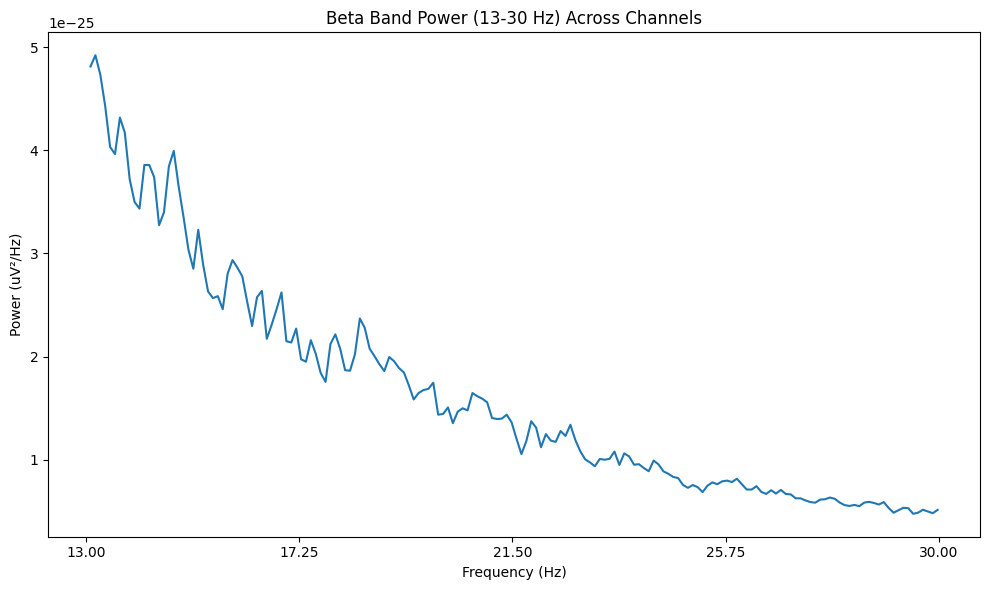

Extracted Beta Band Power (13-30 Hz) successfully.


In [123]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [124]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d111 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d111.head())
print(d111.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [125]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d111_clean = d111.replace([np.inf, -np.inf], np.nan)
d111_clean = d111_clean.fillna(d111_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d111_scaled = pd.DataFrame(
    scaler.fit_transform(d111_clean),
    columns=d111_clean.columns,
    index=d111_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d111_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d111_scaled.index,
    columns=d111_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d111_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df111 = d111_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df111["Pd_indicator_meg"] = 0

print("\nShape of df5:", df111.shape)
print(df111.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [126]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110, df111], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6143    3.841270             0.065083          2.726900e-12  0.892310   
6144    3.878307             0.064461          2.442960e-12  0.876547   
6145    3.375661             0.074060          1.522816e-13  1.070228   
6146    3.767196          

In [127]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111.to_csv('/content/drive/MyDrive/combined_features_upto_sub00111_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111 preserved.


sub-112

In [128]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-112'  # Replace with your folder path


In [129]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-112_scans.tsv', 'meg']


In [130]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-112_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-112_task-go_run-1_proc-tsss+mc_events.json', 'sub-112_coordsystem.json', 'sub-112_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-112_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-112_task-go_run-1_proc-tsss+mc_meg.json', 'sub-112_task-noise_proc-tsss_channels.tsv', 'sub-112_task-noise_proc-tsss_meg.fif', 'sub-112_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-112_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-112_task-passive_run-1_proc-tsss+mc_events.json', 'sub-112_task-noise_proc-tsss_meg.json', 'sub-112_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-112_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-112_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-112_task-rest_run-1_proc-tsss+mc_events.json', 'sub-112_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-112_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-112_task-rest_run-1_proc-tsss+mc_meg.json']


In [131]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-112_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-112_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-112_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-112_task-rest_run-1_proc-tsss+mc_meg.fif']


In [132]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-112/meg/sub-112_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [133]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-112/meg/sub-112_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 45000 ... 238999 =     45.000 ...   238.999 secs
Ready.
Reading 0 ... 193999  =      0.000 ...   193.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spetral Density

Effective window size : 10.240 (s)


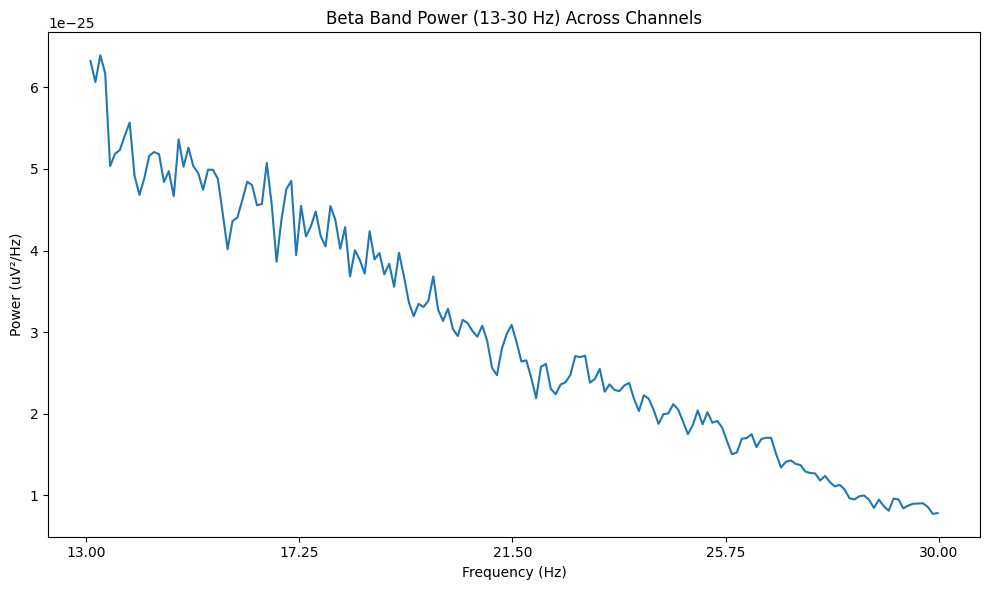

Extracted Beta Band Power (13-30 Hz) successfully.


In [134]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [135]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d112 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d112.head())
print(d112.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [136]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d112_clean = d112.replace([np.inf, -np.inf], np.nan)
d112_clean = d112_clean.fillna(d112_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d112_scaled = pd.DataFrame(
    scaler.fit_transform(d112_clean),
    columns=d112_clean.columns,
    index=d112_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d112_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d112_scaled.index,
    columns=d112_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d112_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df112 = d112_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df112["Pd_indicator_meg"] = 1

print("\nShape of df5:", df112.shape)
print(df112.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [137]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111, df112], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6201    4.252577             0.058788          2.799308e-12  0.794403   
6202    4.134021             0.060380          2.772094e-12  0.840513   
6203    4.123711             0.060625          1.687857e-13  0.790180   
6204    4.139175       

In [138]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112.to_csv('/content/drive/MyDrive/combined_features_upto_sub00112_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112 preserved.")


RAM Used After Cleanup: 0.54 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112 preserved.


sub-113

In [139]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-113'  # Replace with your folder path


In [140]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-113_scans.tsv', 'meg']


In [141]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-113_task-go_run-1_proc-tsss+mc_events.json', 'sub-113_coordsystem.json', 'sub-113_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-113_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-113_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-113_task-go_run-1_proc-tsss+mc_meg.json', 'sub-113_task-noise_proc-tsss_channels.tsv', 'sub-113_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-113_task-passive_run-1_proc-tsss+mc_events.json', 'sub-113_task-noise_proc-tsss_meg.json', 'sub-113_task-noise_proc-tsss_meg.fif', 'sub-113_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-113_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-113_task-rest_run-1_proc-tsss+mc_events.json', 'sub-113_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-113_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-113_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-113_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-113_task-rest_run-1_proc-tsss+mc_meg.fif']


In [142]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-113_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-113_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-113_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-113_task-rest_run-1_proc-tsss+mc_meg.fif']


In [143]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-113/meg/sub-113_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [144]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-113/meg/sub-113_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 9000 ... 197999 =      9.000 ...   197.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


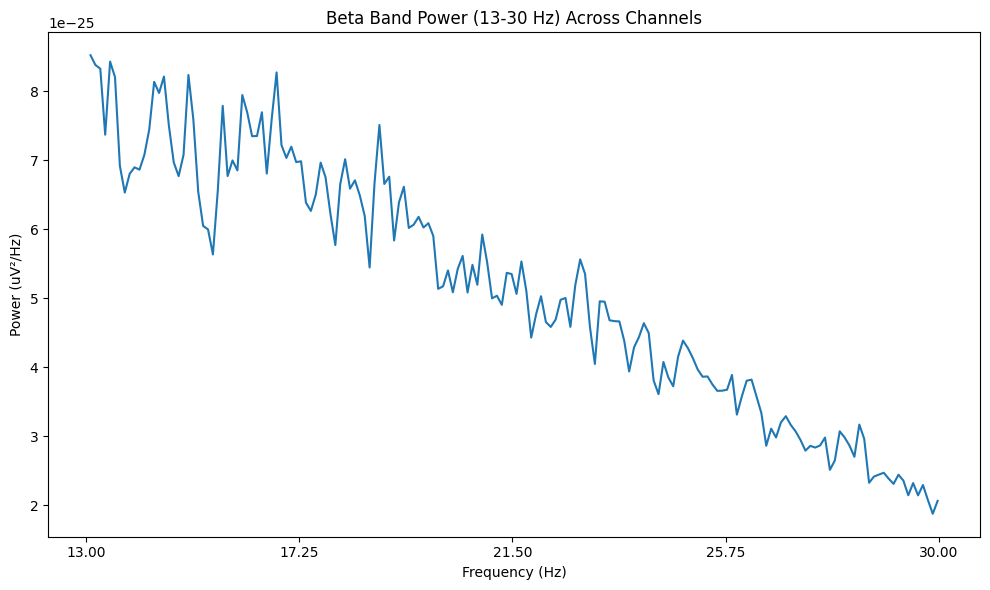

Extracted Beta Band Power (13-30 Hz) successfully.


In [145]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [146]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d113 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d113.head())
print(d113.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [147]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d113_clean = d113.replace([np.inf, -np.inf], np.nan)
d113_clean = d113_clean.fillna(d113_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d113_scaled = pd.DataFrame(
    scaler.fit_transform(d113_clean),
    columns=d113_clean.columns,
    index=d113_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d113_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d113_scaled.index,
    columns=d113_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d113_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df113 = d113_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df113["Pd_indicator_meg"] = 1

print("\nShape of df5:", df113.shape)
print(df113.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [148]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112, df113], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6259    3.820106             0.065443          4.421142e-12  1.107269   
6260    3.740741             0.066832          4.350767e-12  0.978635   
6261    3.714286             0.067308          2.751405e-13  0.972748   
6262    3.804233    

In [149]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113.to_csv('/content/drive/MyDrive/combined_features_upto_sub00113_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113 preserved.")


RAM Used After Cleanup: 0.53 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113 preserved.


sub-114

In [150]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-114'  # Replace with your folder path


In [151]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-114_scans.tsv', 'meg']


In [152]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-114_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-114_coordsystem.json', 'sub-114_task-go_run-1_proc-tsss+mc_events.json', 'sub-114_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-114_task-go_run-1_proc-tsss+mc_meg.json', 'sub-114_task-noise_proc-tsss_channels.tsv', 'sub-114_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-114_task-passive_run-1_proc-tsss+mc_events.json', 'sub-114_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-114_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-114_task-noise_proc-tsss_meg.json', 'sub-114_task-noise_proc-tsss_meg.fif', 'sub-114_task-rest_run-1_proc-tsss+mc_events.json', 'sub-114_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-114_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-114_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-114_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-114_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-114_task-rest_run-1_proc-tsss+mc_meg.json']


In [153]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-114_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-114_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-114_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-114_task-rest_run-1_proc-tsss+mc_meg.fif']


In [154]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-114/meg/sub-114_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [155]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-114/meg/sub-114_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 59000 ... 251999 =     59.000 ...   251.999 secs
Ready.
Reading 0 ... 192999  =      0.000 ...   192.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


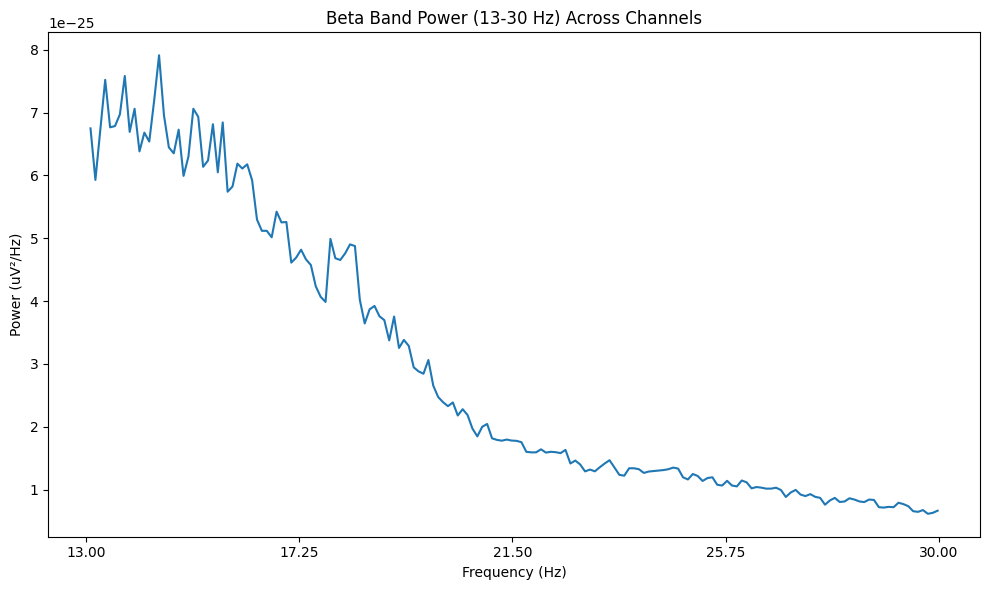

Extracted Beta Band Power (13-30 Hz) successfully.


In [156]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [157]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d114 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d114.head())
print(d114.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [158]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d114_clean = d114.replace([np.inf, -np.inf], np.nan)
d114_clean = d114_clean.fillna(d114_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d114_scaled = pd.DataFrame(
    scaler.fit_transform(d114_clean),
    columns=d114_clean.columns,
    index=d114_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d114_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d114_scaled.index,
    columns=d114_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d114_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df114 = d114_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df114["Pd_indicator_meg"] = 0

print("\nShape of df5:", df114.shape)
print(df114.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [159]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113, df114], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6317    4.165803             0.060012          2.332016e-12  0.817649   
6318    4.248705             0.058841          2.377975e-12  0.821781   
6319    4.165803             0.060012          1.386437e-13  0.758377   
6320    4.119171 

In [160]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114.to_csv('/content/drive/MyDrive/combined_features_upto_sub00114_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114 preserved.")


RAM Used After Cleanup: 0.54 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114 preserved.


sub-115

In [161]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-115'  # Replace with your folder path


In [162]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-115_scans.tsv', 'meg']


In [163]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-115_coordsystem.json', 'sub-115_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-115_task-go_run-1_proc-tsss+mc_events.json', 'sub-115_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-115_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-115_task-go_run-1_proc-tsss+mc_meg.json', 'sub-115_task-noise_proc-tsss_channels.tsv', 'sub-115_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-115_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-115_task-noise_proc-tsss_meg.fif', 'sub-115_task-passive_run-1_proc-tsss+mc_events.json', 'sub-115_task-noise_proc-tsss_meg.json', 'sub-115_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-115_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-115_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-115_task-rest_run-1_proc-tsss+mc_events.json', 'sub-115_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-115_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-115_task-rest_run-1_proc-tsss+mc_meg.fif']


In [164]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-115_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-115_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-115_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-115_task-rest_run-1_proc-tsss+mc_meg.fif']


In [165]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-115/meg/sub-115_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [166]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-115/meg/sub-115_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 100000 ... 297999 =    100.000 ...   297.999 secs
Ready.
Reading 0 ... 197999  =      0.000 ...   197.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA

Computing Power Spectral Density

Effective window size : 10.240 (s)


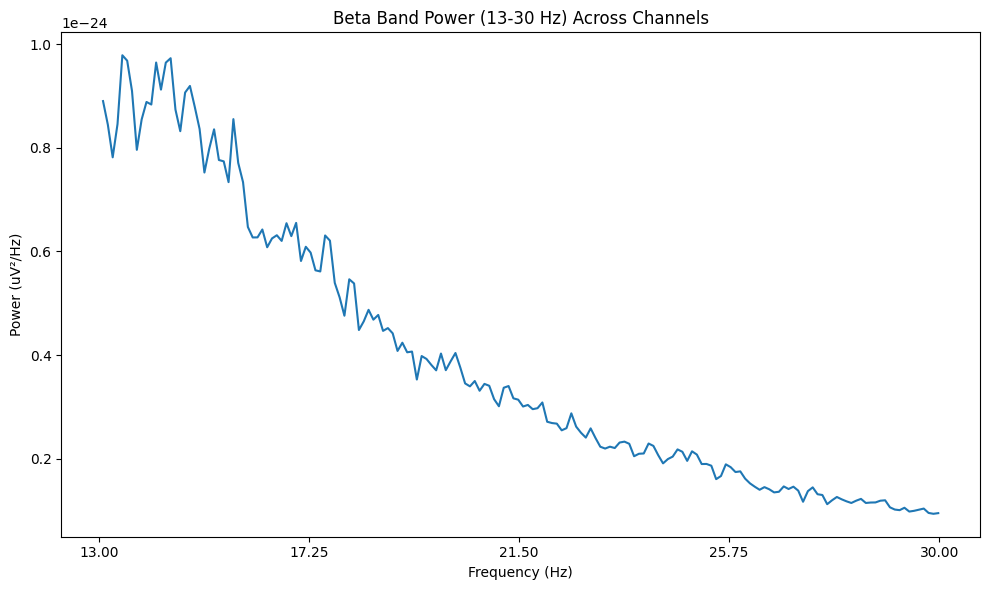

Extracted Beta Band Power (13-30 Hz) successfully.


In [167]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [168]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d115 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d115.head())
print(d115.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [169]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d115_clean = d115.replace([np.inf, -np.inf], np.nan)
d115_clean = d115_clean.fillna(d115_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d115_scaled = pd.DataFrame(
    scaler.fit_transform(d115_clean),
    columns=d115_clean.columns,
    index=d115_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d115_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d115_scaled.index,
    columns=d115_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d115_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df115 = d115_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df115["Pd_indicator_meg"] = 1

print("\nShape of df5:", df115.shape)
print(df115.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [170]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114, df115], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6375    4.030303             0.062030          5.111751e-12  0.774175   
6376    3.934343             0.063543          4.370500e-12  0.935463   
6377    3.949495             0.063299          2.823076e-13  0.851810   
6378    3.9444

In [171]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115.to_csv('/content/drive/MyDrive/combined_features_upto_sub00115_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115 preserved.


sub-116

In [172]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-116'  # Replace with your folder path


In [173]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-116_scans.tsv', 'meg']


In [174]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-116_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-116_coordsystem.json', 'sub-116_task-go_run-1_proc-tsss+mc_events.json', 'sub-116_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-116_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-116_task-noise_proc-tsss_meg.fif', 'sub-116_task-noise_proc-tsss_channels.tsv', 'sub-116_task-go_run-1_proc-tsss+mc_meg.json', 'sub-116_task-noise_proc-tsss_meg.json', 'sub-116_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-116_task-passive_run-1_proc-tsss+mc_events.json', 'sub-116_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-116_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-116_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-116_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-116_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-116_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-116_task-rest_run-1_proc-tsss+mc_events.json', 'sub-116_task-rest_run-1_proc-tsss+mc_meg.json']


In [175]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-116_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-116_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-116_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-116_task-rest_run-1_proc-tsss+mc_meg.fif']


In [176]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-116/meg/sub-116_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [177]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-116/meg/sub-116_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 24000 ... 211999 =     24.000 ...   211.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


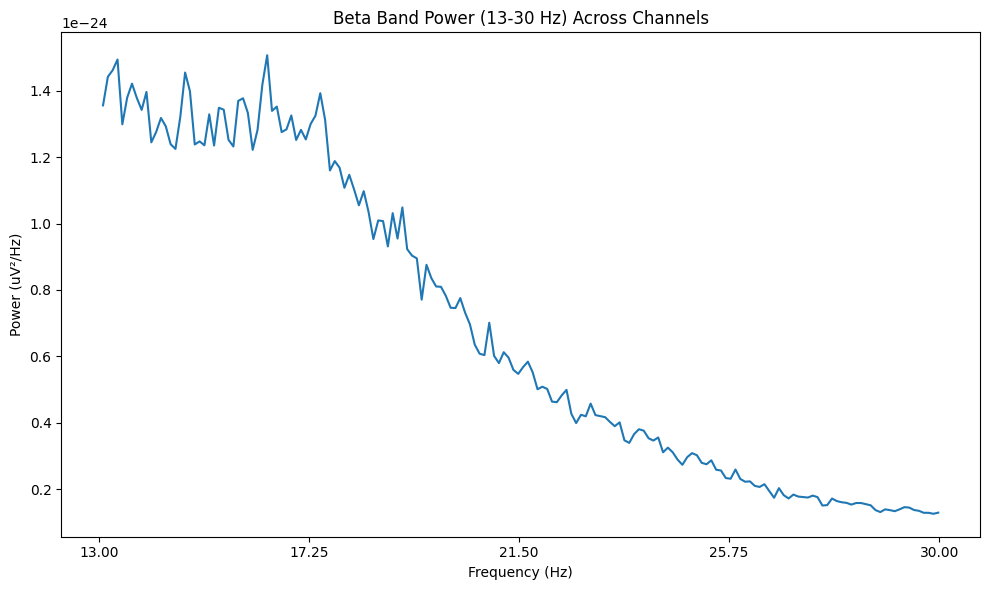

Extracted Beta Band Power (13-30 Hz) successfully.


In [178]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [179]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d116 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d116.head())
print(d116.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [180]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d116_clean = d116.replace([np.inf, -np.inf], np.nan)
d116_clean = d116_clean.fillna(d116_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d116_scaled = pd.DataFrame(
    scaler.fit_transform(d116_clean),
    columns=d116_clean.columns,
    index=d116_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d116_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d116_scaled.index,
    columns=d116_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d116_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df116 = d116_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df116["Pd_indicator_meg"] = 0

print("\nShape of df5:", df116.shape)
print(df116.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [181]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115, df116], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6433    3.840426             0.065097          5.507901e-12  0.747520   
6434    3.962766             0.063087          5.086630e-12  0.745389   
6435    3.452128             0.072419          3.215968e-13  0.754022   
6436    3.9

In [182]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116.to_csv('/content/drive/MyDrive/combined_features_upto_sub00116_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116 preserved.")


RAM Used After Cleanup: 0.58 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116 preserved.


sub-118

In [183]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-118'  # Replace with your folder path


In [184]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-118_scans.tsv', 'meg']


In [185]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-118_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-118_coordsystem.json', 'sub-118_task-go_run-1_proc-tsss+mc_events.json', 'sub-118_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-118_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-118_task-noise_proc-tsss_channels.tsv', 'sub-118_task-go_run-1_proc-tsss+mc_meg.json', 'sub-118_task-noise_proc-tsss_meg.fif', 'sub-118_task-passive_run-1_proc-tsss+mc_events.json', 'sub-118_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-118_task-noise_proc-tsss_meg.json', 'sub-118_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-118_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-118_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-118_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-118_task-rest_run-1_proc-tsss+mc_events.json', 'sub-118_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-118_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-118_task-rest_run-1_proc-tsss+mc_meg.json']


In [186]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-118_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-118_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-118_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-118_task-rest_run-1_proc-tsss+mc_meg.fif']


In [187]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-118/meg/sub-118_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [188]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-118/meg/sub-118_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 22000 ... 208999 =     22.000 ...   208.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


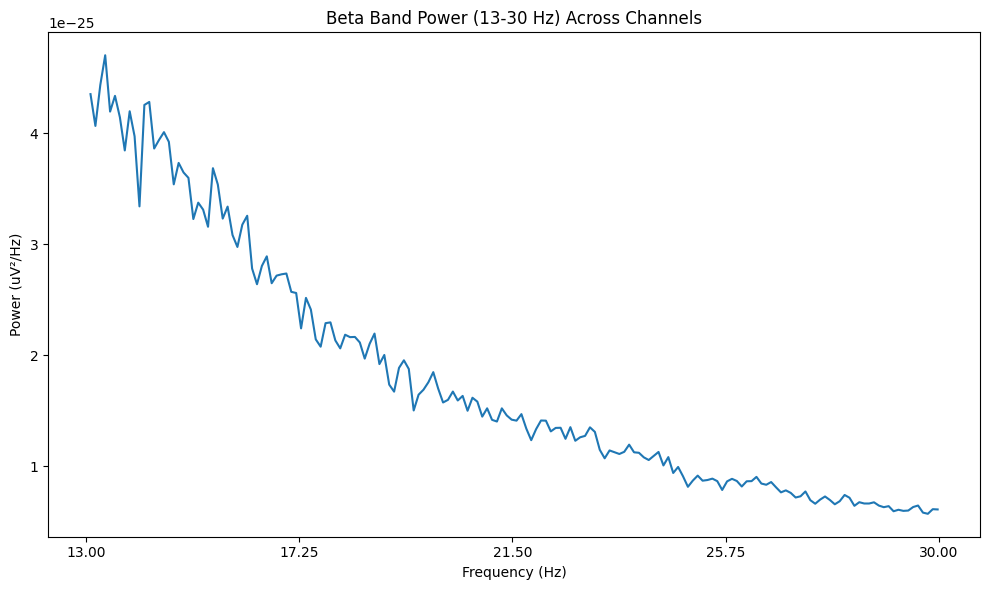

Extracted Beta Band Power (13-30 Hz) successfully.


In [189]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [190]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d118 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d118.head())
print(d118.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [191]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d118_clean = d118.replace([np.inf, -np.inf], np.nan)
d118_clean = d118_clean.fillna(d118_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d118_scaled = pd.DataFrame(
    scaler.fit_transform(d118_clean),
    columns=d118_clean.columns,
    index=d118_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d118_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d118_scaled.index,
    columns=d118_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d118_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df118 = d118_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df118["Pd_indicator_meg"] = 1

print("\nShape of df5:", df118.shape)
print(df118.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [192]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116, df118], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6491    4.240642             0.058953          2.321132e-12  0.782344   
6492    4.454545             0.056122          2.088356e-12  0.777991   
6493    4.122995             0.060636          1.232010e-13  0.743845   
6494    

In [193]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118.to_csv('/content/drive/MyDrive/combined_features_upto_sub00118_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118 preserved.")


RAM Used After Cleanup: 0.54 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118 preserved.


sub-119

In [194]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-119'  # Replace with your folder path


In [195]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-119_scans.tsv', 'meg']


In [196]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-119_task-go_run-1_proc-tsss+mc_events.json', 'sub-119_coordsystem.json', 'sub-119_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-119_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-119_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-119_task-noise_proc-tsss_meg.fif', 'sub-119_task-noise_proc-tsss_channels.tsv', 'sub-119_task-go_run-1_proc-tsss+mc_meg.json', 'sub-119_task-noise_proc-tsss_meg.json', 'sub-119_task-passive_run-1_proc-tsss+mc_events.json', 'sub-119_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-119_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-119_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-119_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-119_task-rest_run-1_proc-tsss+mc_events.json', 'sub-119_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-119_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-119_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-119_task-rest_run-1_proc-tsss+mc_meg.json']


In [197]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-119_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-119_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-119_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-119_task-rest_run-1_proc-tsss+mc_meg.fif']


In [198]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-119/meg/sub-119_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [199]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-119/meg/sub-119_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 28000 ... 218999 =     28.000 ...   218.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


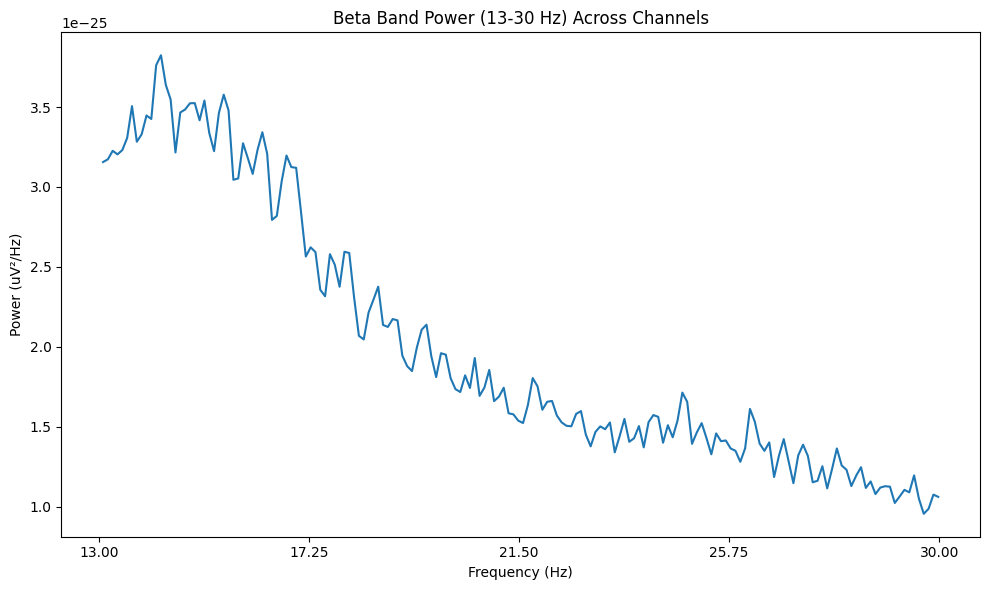

Extracted Beta Band Power (13-30 Hz) successfully.


In [200]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [201]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d119 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d119.head())
print(d119.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [202]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d119_clean = d119.replace([np.inf, -np.inf], np.nan)
d119_clean = d119_clean.fillna(d119_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d119_scaled = pd.DataFrame(
    scaler.fit_transform(d119_clean),
    columns=d119_clean.columns,
    index=d119_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d119_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d119_scaled.index,
    columns=d119_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d119_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df119 = d119_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df119["Pd_indicator_meg"] = 0

print("\nShape of df5:", df119.shape)
print(df119.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [203]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118, df119], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6549    4.528796             0.055202          2.107783e-12  0.741012   
6550    4.638743             0.053894          2.021256e-12  0.725576   
6551    4.602094             0.054323          1.058111e-13  0.698785   
6552 

In [204]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119.to_csv('/content/drive/MyDrive/combined_features_upto_sub00119_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119 preserved.")


RAM Used After Cleanup: 0.55 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119 preserved.


sub-120

In [205]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-120'  # Replace with your folder path


In [206]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-120_scans.tsv', 'meg']


In [207]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-120_coordsystem.json', 'sub-120_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-120_task-go_run-1_proc-tsss+mc_events.json', 'sub-120_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-120_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-120_task-noise_proc-tsss_channels.tsv', 'sub-120_task-go_run-1_proc-tsss+mc_meg.json', 'sub-120_task-noise_proc-tsss_meg.fif', 'sub-120_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-120_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-120_task-passive_run-1_proc-tsss+mc_events.json', 'sub-120_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-120_task-noise_proc-tsss_meg.json', 'sub-120_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-120_task-rest_run-1_proc-tsss+mc_events.json', 'sub-120_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-120_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-120_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-120_task-rest_run-1_proc-tsss+mc_meg.json']


In [208]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-120_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-120_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-120_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-120_task-rest_run-1_proc-tsss+mc_meg.fif']


In [209]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-120/meg/sub-120_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [210]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-120/meg/sub-120_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 2000 ... 237999 =      2.000 ...   237.999 secs
Ready.
Reading 0 ... 235999  =      0.000 ...   235.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


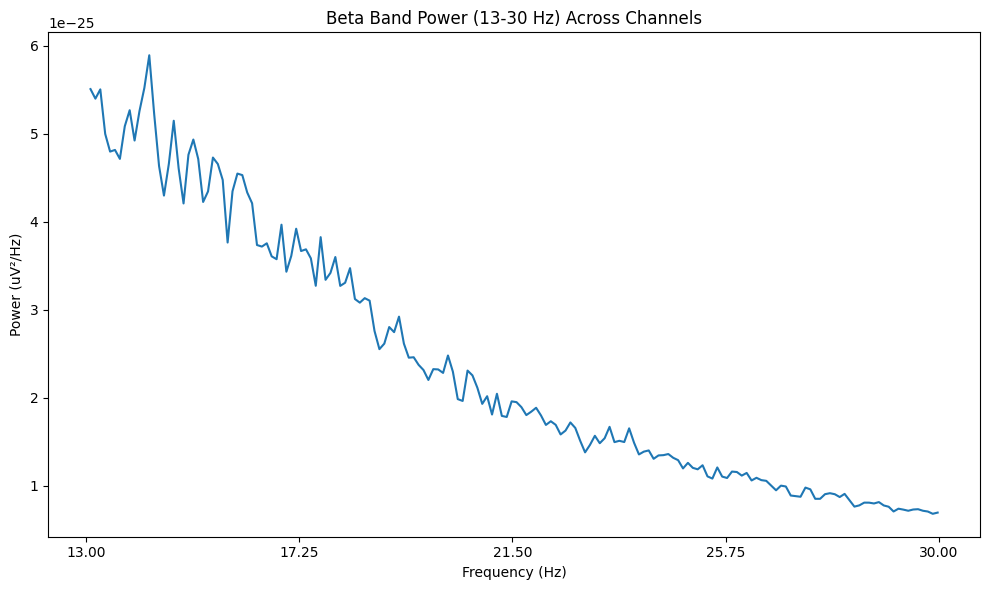

Extracted Beta Band Power (13-30 Hz) successfully.


In [211]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [212]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d120 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d120.head())
print(d120.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [213]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d120_clean = d120.replace([np.inf, -np.inf], np.nan)
d120_clean = d120_clean.fillna(d120_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d120_scaled = pd.DataFrame(
    scaler.fit_transform(d120_clean),
    columns=d120_clean.columns,
    index=d120_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d120_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d120_scaled.index,
    columns=d120_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d120_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df120 = d120_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df120["Pd_indicator_meg"] = 1

print("\nShape of df5:", df120.shape)
print(df120.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [214]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119, df120], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6607    4.241525             0.058941          2.633279e-12  0.841286   
6608    4.173729             0.059898          2.431274e-12  0.796789   
6609    4.161017             0.060081          1.594562e-13  0.819493   
66

In [215]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120.to_csv('/content/drive/MyDrive/combined_features_upto_sub00120_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120 preserved.


sub-121

In [216]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-121'  # Replace with your folder path


In [217]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-121_scans.tsv', 'meg']


In [218]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-121_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-121_coordsystem.json', 'sub-121_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-121_task-go_run-1_proc-tsss+mc_events.json', 'sub-121_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-121_task-noise_proc-tsss_channels.tsv', 'sub-121_task-noise_proc-tsss_meg.fif', 'sub-121_task-go_run-1_proc-tsss+mc_meg.json', 'sub-121_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-121_task-noise_proc-tsss_meg.json', 'sub-121_task-passive_run-1_proc-tsss+mc_events.json', 'sub-121_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-121_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-121_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-121_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-121_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-121_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-121_task-rest_run-1_proc-tsss+mc_events.json', 'sub-121_task-rest_run-1_proc-tsss+mc_meg.json']


In [219]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-121_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-121_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-121_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-121_task-rest_run-1_proc-tsss+mc_meg.fif']


In [220]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-121/meg/sub-121_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [221]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-121/meg/sub-121_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 119000 ... 305999 =    119.000 ...   305.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA

Computing Power Spectral Density

Effective window size : 10.240 (s)


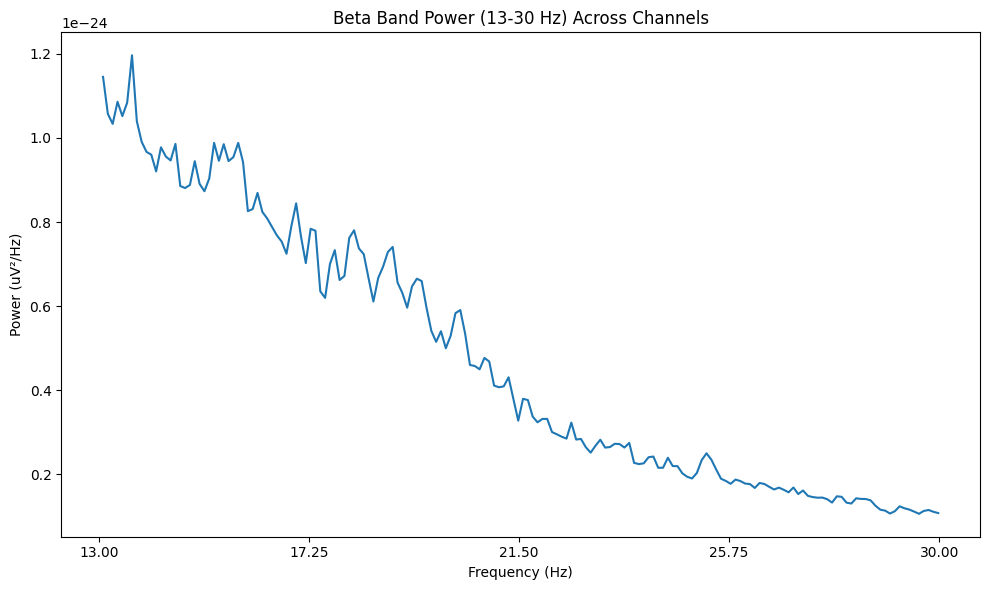

Extracted Beta Band Power (13-30 Hz) successfully.


In [222]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


feature Extraction

In [223]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d121 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d121.head())
print(d121.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [224]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d121_clean = d121.replace([np.inf, -np.inf], np.nan)
d121_clean = d121_clean.fillna(d121_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d121_scaled = pd.DataFrame(
    scaler.fit_transform(d121_clean),
    columns=d121_clean.columns,
    index=d121_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d121_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d121_scaled.index,
    columns=d121_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d121_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df121 = d121_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df121["Pd_indicator_meg"] = 1

print("\nShape of df5:", df121.shape)
print(df121.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [225]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120, df121], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6665    3.893048             0.064217          3.747309e-12  0.842850   
6666    3.828877             0.065293          3.616919e-12  0.767175   
6667    3.893048             0.064217          2.104608e-13  0.796215   

In [226]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121.to_csv('/content/drive/MyDrive/combined_features_upto_sub00121_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121 preserved.


sub-122

In [227]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-122'  # Replace with your folder path


In [228]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-122_scans.tsv', 'meg']


In [229]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-122_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-122_coordsystem.json', 'sub-122_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-122_task-go_run-1_proc-tsss+mc_events.json', 'sub-122_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-122_task-go_run-1_proc-tsss+mc_meg.json', 'sub-122_task-noise_proc-tsss_channels.tsv', 'sub-122_task-noise_proc-tsss_meg.fif', 'sub-122_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-122_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-122_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-122_task-noise_proc-tsss_meg.json', 'sub-122_task-passive_run-1_proc-tsss+mc_events.json', 'sub-122_task-rest_run-1_proc-tsss+mc_events.json', 'sub-122_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-122_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-122_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-122_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-122_task-rest_run-1_proc-tsss+mc_meg.json']


In [230]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-122_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-122_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-122_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-122_task-rest_run-1_proc-tsss+mc_meg.fif']


In [231]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-122/meg/sub-122_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [232]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-122/meg/sub-122_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 202999 =     18.000 ...   202.999 secs
Ready.
Reading 0 ... 184999  =      0.000 ...   184.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


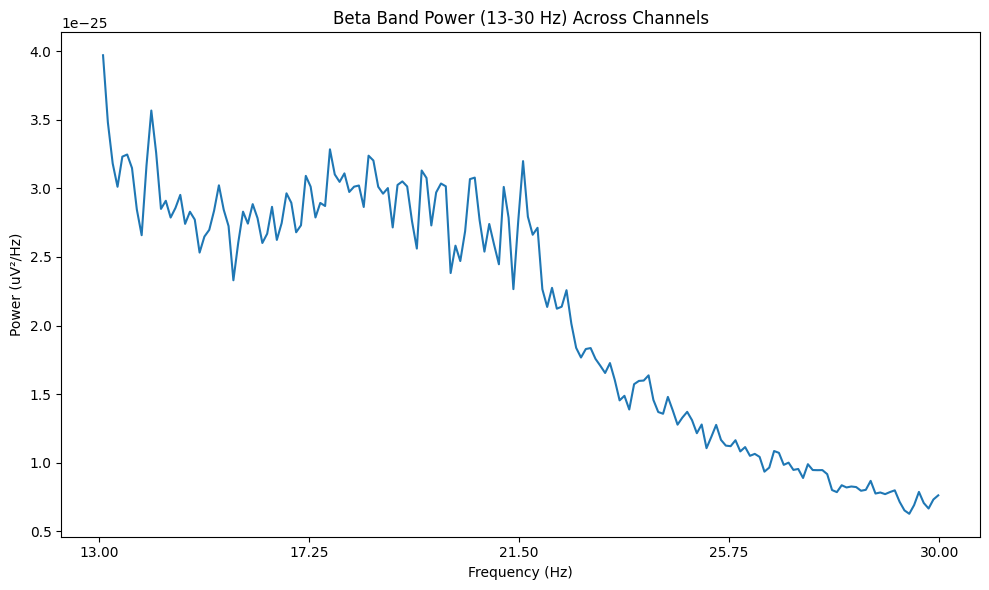

Extracted Beta Band Power (13-30 Hz) successfully.


In [233]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [234]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d122 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d122.head())
print(d122.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [235]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d122_clean = d122.replace([np.inf, -np.inf], np.nan)
d122_clean = d122_clean.fillna(d122_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d122_scaled = pd.DataFrame(
    scaler.fit_transform(d122_clean),
    columns=d122_clean.columns,
    index=d122_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d122_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d122_scaled.index,
    columns=d122_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d122_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df122 = d122_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df122["Pd_indicator_meg"] = 1

print("\nShape of df5:", df122.shape)
print(df122.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [236]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121, df121], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6723    3.893048             0.064217          3.747309e-12  0.842850   
6724    3.828877             0.065293          3.616919e-12  0.767175   
6725    3.893048             0.064217          2.104608e-13  0.796215

In [237]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122.to_csv('/content/drive/MyDrive/combined_features_upto_sub00122_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122 preserved.


sub-123

In [238]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-123'  # Replace with your folder path


In [239]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-123_scans.tsv', 'meg']


In [240]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-123_task-go_run-1_proc-tsss+mc_events.json', 'sub-123_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-123_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-123_coordsystem.json', 'sub-123_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-123_task-noise_proc-tsss_meg.fif', 'sub-123_task-noise_proc-tsss_channels.tsv', 'sub-123_task-go_run-1_proc-tsss+mc_meg.json', 'sub-123_task-passive_run-1_proc-tsss+mc_events.json', 'sub-123_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-123_task-noise_proc-tsss_meg.json', 'sub-123_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-123_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-123_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-123_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-123_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-123_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-123_task-rest_run-1_proc-tsss+mc_events.json', 'sub-123_task-rest_run-1_proc-tsss+mc_meg.json']


In [241]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-123_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-123_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-123_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-123_task-rest_run-1_proc-tsss+mc_meg.fif']


In [242]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-123/meg/sub-123_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [243]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-123/meg/sub-123_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 11000 ... 200999 =     11.000 ...   200.999 secs
Ready.
Reading 0 ... 189999  =      0.000 ...   189.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


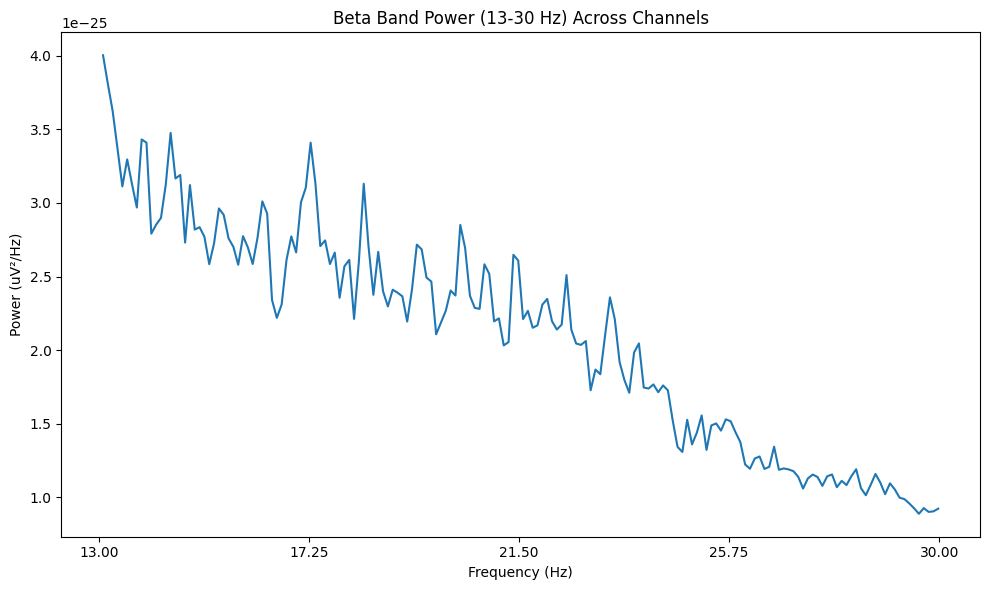

Extracted Beta Band Power (13-30 Hz) successfully.


In [244]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [245]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d123 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d123.head())
print(d123.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [246]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d123_clean = d123.replace([np.inf, -np.inf], np.nan)
d123_clean = d123_clean.fillna(d123_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d123_scaled = pd.DataFrame(
    scaler.fit_transform(d123_clean),
    columns=d123_clean.columns,
    index=d123_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d123_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d123_scaled.index,
    columns=d123_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d123_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df123 = d123_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df123["Pd_indicator_meg"] = 1

print("\nShape of df5:", df123.shape)
print(df123.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [247]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122, df123], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6781    3.921053             0.063758          2.935942e-12  0.977932   
6782    4.121053             0.060664          2.714259e-12  0.790848   
6783    4.115789             0.060742          1.554271e-13  0.873

In [248]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123.to_csv('/content/drive/MyDrive/combined_features_upto_sub00123_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123 preserved.")


RAM Used After Cleanup: 0.56 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123 preserved.


sub-124

In [249]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-124'  # Replace with your folder path


In [250]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-124_scans.tsv', 'meg']


In [251]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-124_coordsystem.json', 'sub-124_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-124_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-124_task-go_run-1_proc-tsss+mc_events.json', 'sub-124_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-124_task-go_run-1_proc-tsss+mc_meg.json', 'sub-124_task-noise_proc-tsss_channels.tsv', 'sub-124_task-noise_proc-tsss_meg.json', 'sub-124_task-noise_proc-tsss_meg.fif', 'sub-124_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-124_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-124_task-passive_run-1_proc-tsss+mc_events.json', 'sub-124_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-124_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-124_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-124_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-124_task-rest_run-1_proc-tsss+mc_events.json', 'sub-124_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-124_task-rest_run-1_proc-tsss+mc_meg.fif']


In [252]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-124_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-124_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-124_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-124_task-rest_run-1_proc-tsss+mc_meg.fif']


In [253]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-124/meg/sub-124_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [254]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-124/meg/sub-124_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 11000 ... 201999 =     11.000 ...   201.999 secs
Ready.
Reading 0 ... 190999  =      0.000 ...   190.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


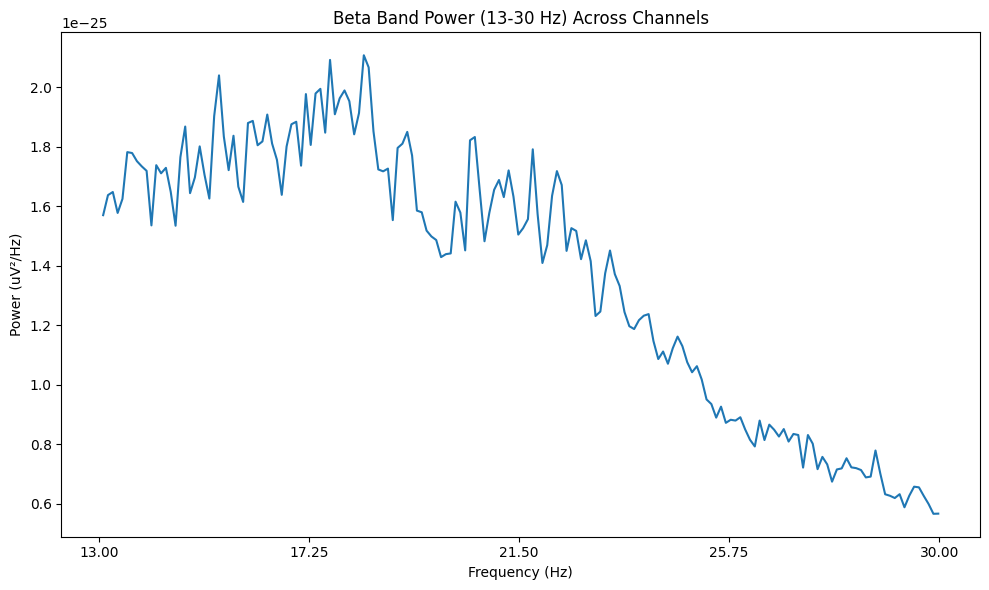

Extracted Beta Band Power (13-30 Hz) successfully.


In [255]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [256]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d124 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d124.head())
print(d124.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [257]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d124_clean = d124.replace([np.inf, -np.inf], np.nan)
d124_clean = d124_clean.fillna(d124_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d124_scaled = pd.DataFrame(
    scaler.fit_transform(d124_clean),
    columns=d124_clean.columns,
    index=d124_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d124_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d124_scaled.index,
    columns=d124_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d124_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df124 = d124_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df124["Pd_indicator_meg"] = 0

print("\nShape of df5:", df124.shape)
print(df124.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [258]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123, df124], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6839    4.329843             0.057739          2.750447e-12  0.727107   
6840    3.937173             0.063497          2.858157e-12  0.770797   
6841    3.863874             0.064702          1.450218e-13  0.

In [259]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124.to_csv('/content/drive/MyDrive/combined_features_upto_sub00124_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124 preserved.")


RAM Used After Cleanup: 0.56 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124 preserved.


sub-125

In [260]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-125'  # Replace with your folder path


In [261]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-125_scans.tsv', 'meg']


In [262]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-125_task-go_run-1_proc-tsss+mc_events.json', 'sub-125_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-125_coordsystem.json', 'sub-125_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-125_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-125_task-noise_proc-tsss_meg.fif', 'sub-125_task-noise_proc-tsss_channels.tsv', 'sub-125_task-go_run-1_proc-tsss+mc_meg.json', 'sub-125_task-noise_proc-tsss_meg.json', 'sub-125_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-125_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-125_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-125_task-passive_run-1_proc-tsss+mc_events.json', 'sub-125_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-125_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-125_task-rest_run-1_proc-tsss+mc_events.json', 'sub-125_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-125_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-125_task-rest_run-1_proc-tsss+mc_meg.json']


In [263]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-125_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-125_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-125_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-125_task-rest_run-1_proc-tsss+mc_meg.fif']


In [264]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-125/meg/sub-125_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [265]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-125/meg/sub-125_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 10000 ... 197999 =     10.000 ...   197.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


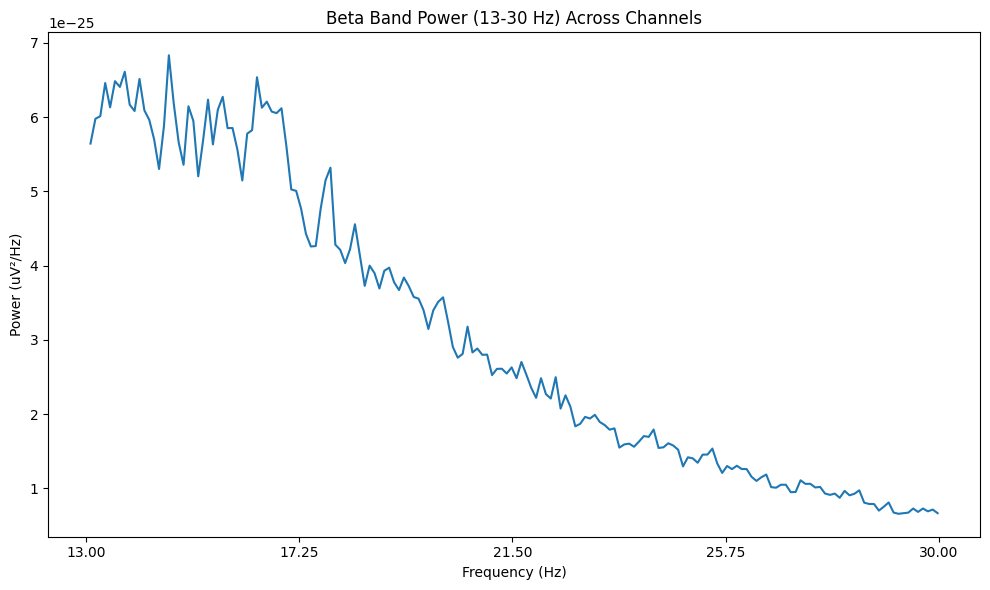

Extracted Beta Band Power (13-30 Hz) successfully.


In [266]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [267]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d125 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d125.head())
print(d125.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [268]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d125_clean = d125.replace([np.inf, -np.inf], np.nan)
d125_clean = d125_clean.fillna(d125_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d125_scaled = pd.DataFrame(
    scaler.fit_transform(d125_clean),
    columns=d125_clean.columns,
    index=d125_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d125_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d125_scaled.index,
    columns=d125_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d125_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df125 = d125_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df125["Pd_indicator_meg"] = 0

print("\nShape of df5:", df125.shape)
print(df125.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [269]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124, df125], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6897    4.031915             0.062005          2.200117e-12  0.827369   
6898    3.819149             0.065460          2.363593e-12  0.816483   
6899    4.196809             0.059569          1.179035e-13 

In [270]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125.to_csv('/content/drive/MyDrive/combined_features_upto_sub00125_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125 preserved.")


RAM Used After Cleanup: 0.56 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125 preserved.


sub-127

In [271]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-127'  # Replace with your folder path


In [272]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-127_scans.tsv', 'meg']


In [273]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-127_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-127_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-127_coordsystem.json', 'sub-127_task-go_run-1_proc-tsss+mc_events.json', 'sub-127_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-127_task-noise_proc-tsss_channels.tsv', 'sub-127_task-go_run-1_proc-tsss+mc_meg.json', 'sub-127_task-noise_proc-tsss_meg.fif', 'sub-127_task-noise_proc-tsss_meg.json', 'sub-127_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-127_task-passive_run-1_proc-tsss+mc_events.json', 'sub-127_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-127_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-127_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-127_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-127_task-rest_run-1_proc-tsss+mc_events.json', 'sub-127_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-127_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-127_task-rest_run-1_proc-tsss+mc_meg.json']


In [274]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-127_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-127_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-127_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-127_task-rest_run-1_proc-tsss+mc_meg.fif']


In [275]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-127/meg/sub-127_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [276]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-127/meg/sub-127_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 238999 =      7.000 ...   238.999 secs
Ready.
Reading 0 ... 231999  =      0.000 ...   231.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [1]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [1]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
Fitting I

Computing Power Spectral Density

Effective window size : 10.240 (s)


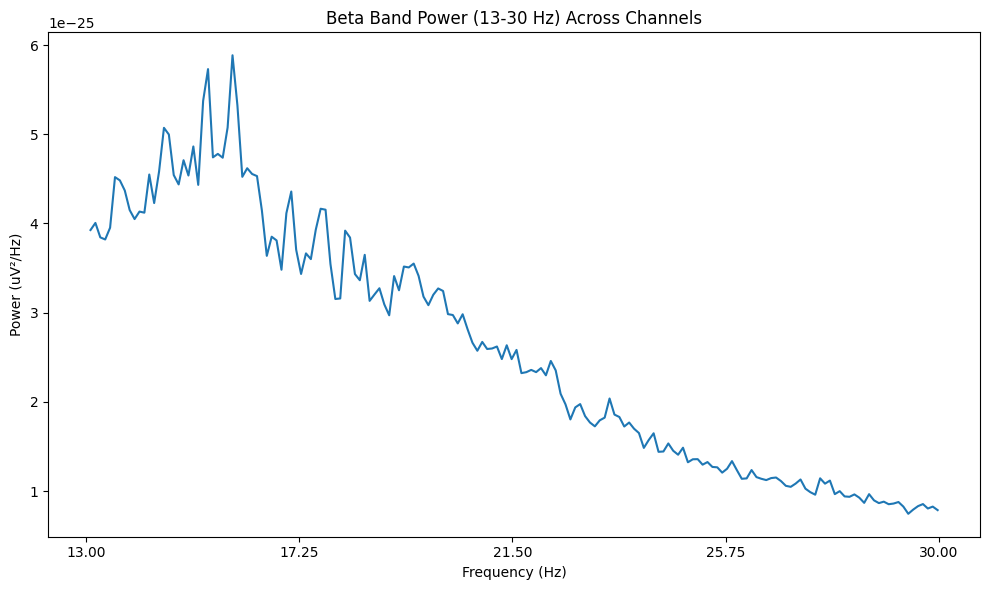

Extracted Beta Band Power (13-30 Hz) successfully.


In [277]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [278]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d127 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d127.head())
print(d127.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [279]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d127_clean = d127.replace([np.inf, -np.inf], np.nan)
d127_clean = d127_clean.fillna(d127_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d127_scaled = pd.DataFrame(
    scaler.fit_transform(d127_clean),
    columns=d127_clean.columns,
    index=d127_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d127_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d127_scaled.index,
    columns=d127_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d127_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df127 = d127_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df127["Pd_indicator_meg"] = 1

print("\nShape of df5:", df127.shape)
print(df127.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [280]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125, df127], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
6955    3.590517             0.069628          3.369846e-12  0.999369   
6956    3.896552             0.064159          2.673502e-12  0.755437   
6957    3.823276             0.065333          1.605322e-

In [281]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127.to_csv('/content/drive/MyDrive/combined_features_upto_sub00127_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127 preserved.")


RAM Used After Cleanup: 0.59 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127 preserved.


sub-128

In [282]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-128'  # Replace with your folder path


In [283]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-128_scans.tsv', 'meg']


In [284]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-128_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-128_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-128_task-go_run-1_proc-tsss+mc_events.json', 'sub-128_coordsystem.json', 'sub-128_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-128_task-noise_proc-tsss_meg.fif', 'sub-128_task-go_run-1_proc-tsss+mc_meg.json', 'sub-128_task-noise_proc-tsss_channels.tsv', 'sub-128_task-noise_proc-tsss_meg.json', 'sub-128_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-128_task-passive_run-1_proc-tsss+mc_events.json', 'sub-128_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-128_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-128_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-128_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-128_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-128_task-rest_run-1_proc-tsss+mc_events.json', 'sub-128_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-128_task-rest_run-1_proc-tsss+mc_meg.json']


In [285]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-128_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-128_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-128_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-128_task-rest_run-1_proc-tsss+mc_meg.fif']


In [286]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-128/meg/sub-128_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [287]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-128/meg/sub-128_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 26000 ... 209999 =     26.000 ...   209.999 secs
Ready.
Reading 0 ... 183999  =      0.000 ...   183.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


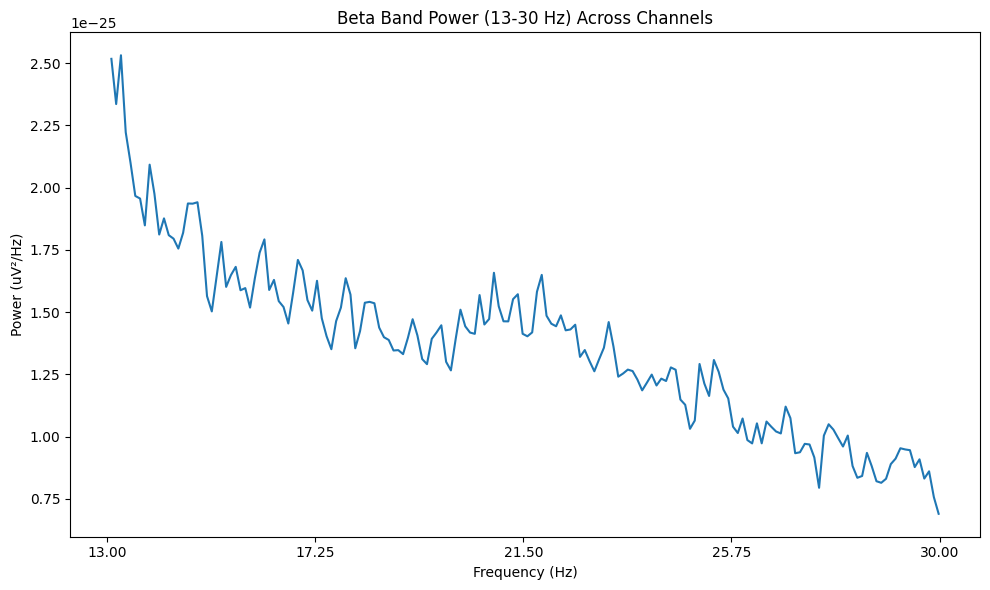

Extracted Beta Band Power (13-30 Hz) successfully.


In [288]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [289]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d128 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d128.head())
print(d128.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [290]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d128_clean = d128.replace([np.inf, -np.inf], np.nan)
d128_clean = d128_clean.fillna(d128_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d128_scaled = pd.DataFrame(
    scaler.fit_transform(d128_clean),
    columns=d128_clean.columns,
    index=d128_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d128_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d128_scaled.index,
    columns=d128_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d128_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df128 = d128_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df128["Pd_indicator_meg"] = 0

print("\nShape of df5:", df128.shape)
print(df128.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [291]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127, df128], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
7013    4.472826             0.055893          2.249173e-12  0.745690   
7014    4.195652             0.059585          2.271379e-12  0.790063   
7015    4.043478             0.061828          1.44855

In [292]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128.to_csv('/content/drive/MyDrive/combined_features_upto_sub00128_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128 preserved.")


RAM Used After Cleanup: 0.60 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128 preserved.


sub-129

In [293]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-129'  # Replace with your folder path


In [294]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-129_scans.tsv', 'meg']


In [295]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-129_coordsystem.json', 'sub-129_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-129_task-go_run-1_proc-tsss+mc_events.json', 'sub-129_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-129_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-129_task-go_run-1_proc-tsss+mc_meg.json', 'sub-129_task-noise_proc-tsss_meg.fif', 'sub-129_task-noise_proc-tsss_channels.tsv', 'sub-129_task-noise_proc-tsss_meg.json', 'sub-129_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-129_task-passive_run-1_proc-tsss+mc_events.json', 'sub-129_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-129_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-129_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-129_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-129_task-rest_run-1_proc-tsss+mc_events.json', 'sub-129_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-129_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-129_task-rest_run-1_proc-tsss+mc_meg.json']


In [296]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-129_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-129_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-129_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-129_task-rest_run-1_proc-tsss+mc_meg.fif']


In [297]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-129/meg/sub-129_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [298]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-129/meg/sub-129_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 15000 ... 200999 =     15.000 ...   200.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computig Power Spectral Density

Effective window size : 10.240 (s)


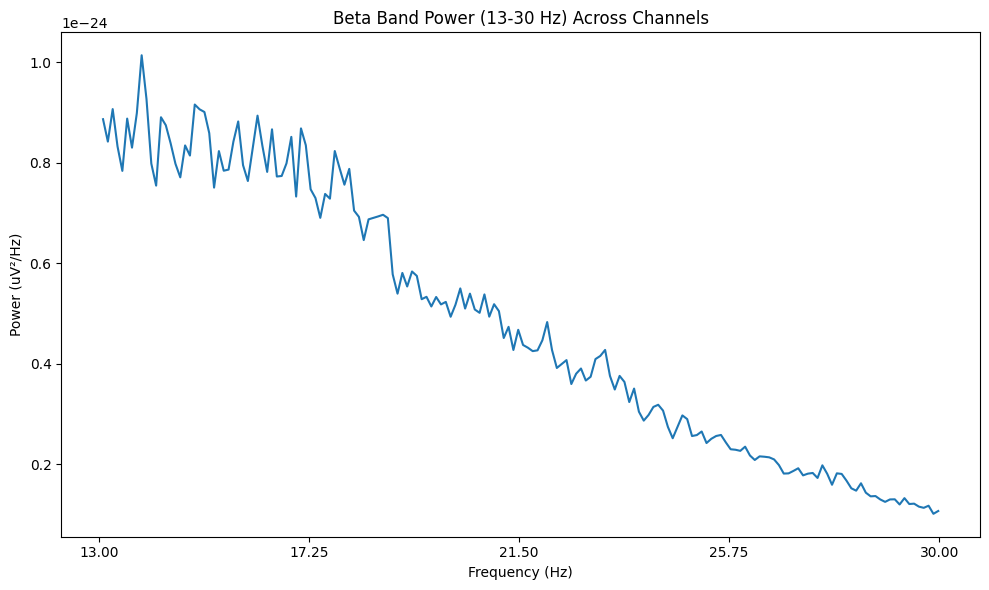

Extracted Beta Band Power (13-30 Hz) successfully.


In [299]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [300]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d129 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d129.head())
print(d129.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [301]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d129_clean = d129.replace([np.inf, -np.inf], np.nan)
d129_clean = d129_clean.fillna(d129_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d129_scaled = pd.DataFrame(
    scaler.fit_transform(d129_clean),
    columns=d129_clean.columns,
    index=d129_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d129_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d129_scaled.index,
    columns=d129_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d129_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df129 = d129_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df129["Pd_indicator_meg"] = 0

print("\nShape of df5:", df129.shape)
print(df129.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [302]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128, df129], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
7071    3.930108             0.063611          4.948726e-12  0.858026   
7072    4.075269             0.061346          4.328665e-12  0.771123   
7073    4.069892             0.061427          2.33

In [303]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129.to_csv('/content/drive/MyDrive/combined_features_upto_sub00129_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129 preserved.


sub-130

In [304]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-130'  # Replace with your folder path


In [305]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-130_scans.tsv', 'meg']


In [306]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-130_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-130_coordsystem.json', 'sub-130_task-go_run-1_proc-tsss+mc_events.json', 'sub-130_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-130_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-130_task-noise_proc-tsss_meg.fif', 'sub-130_task-go_run-1_proc-tsss+mc_meg.json', 'sub-130_task-noise_proc-tsss_channels.tsv', 'sub-130_task-noise_proc-tsss_meg.json', 'sub-130_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-130_task-passive_run-1_proc-tsss+mc_events.json', 'sub-130_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-130_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-130_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-130_task-rest_run-1_proc-tsss+mc_events.json', 'sub-130_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-130_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-130_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-130_task-rest_run-1_proc-tsss+mc_meg.json']


In [307]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-130_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-130_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-130_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-130_task-rest_run-1_proc-tsss+mc_meg.fif']


In [308]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-130/meg/sub-130_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [309]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-130/meg/sub-130_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 64000 ... 256999 =     64.000 ...   256.999 secs
Ready.
Reading 0 ... 192999  =      0.000 ...   192.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


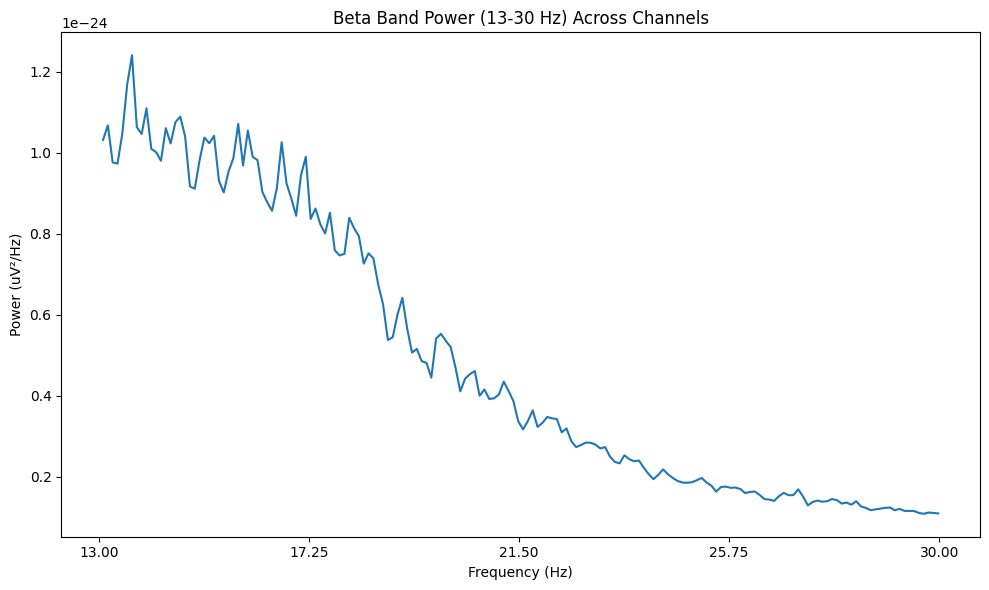

Extracted Beta Band Power (13-30 Hz) successfully.


In [310]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [311]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d130 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d130.head())
print(d130.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [312]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d130_clean = d130.replace([np.inf, -np.inf], np.nan)
d130_clean = d130_clean.fillna(d130_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d130_scaled = pd.DataFrame(
    scaler.fit_transform(d130_clean),
    columns=d130_clean.columns,
    index=d130_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d130_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d130_scaled.index,
    columns=d130_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d130_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df130 = d130_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df130["Pd_indicator_meg"] = 0

print("\nShape of df5:", df130.shape)
print(df130.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [313]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129, df130], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
7129    4.093264             0.061076          3.496229e-12  0.765964   
7130    4.036269             0.061881          3.558393e-12  0.711829   
7131    3.875648             0.064505          1

In [314]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130.to_csv('/content/drive/MyDrive/combined_features_upto_sub00130_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130 preserved.


sub-131

In [315]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-131'  # Replace with your folder path


In [316]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-131_scans.tsv', 'meg']


In [317]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-131_coordsystem.json', 'sub-131_task-go_run-1_proc-tsss+mc_events.json', 'sub-131_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-131_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-131_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-131_task-go_run-1_proc-tsss+mc_meg.json', 'sub-131_task-noise_proc-tsss_channels.tsv', 'sub-131_task-noise_proc-tsss_meg.fif', 'sub-131_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-131_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-131_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-131_task-noise_proc-tsss_meg.json', 'sub-131_task-passive_run-1_proc-tsss+mc_events.json', 'sub-131_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-131_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-131_task-rest_run-1_proc-tsss+mc_events.json', 'sub-131_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-131_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-131_task-rest_run-1_proc-tsss+mc_meg.json']


In [318]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-131_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-131_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-131_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-131_task-rest_run-1_proc-tsss+mc_meg.fif']


In [319]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-131/meg/sub-131_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [320]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-131/meg/sub-131_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 7000 ... 193999 =      7.000 ...   193.999 secs
Ready.
Reading 0 ... 186999  =      0.000 ...   186.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


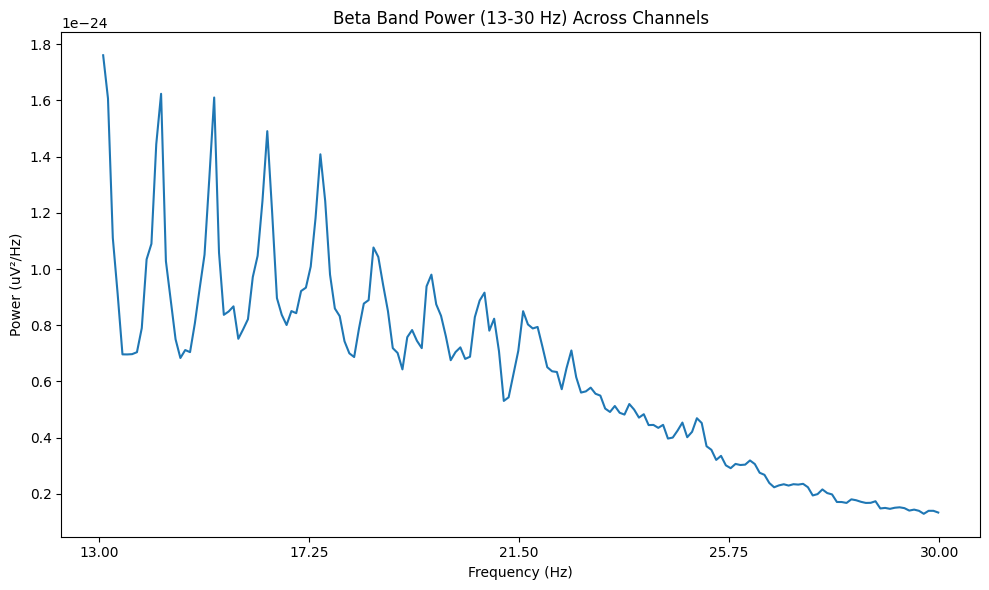

Extracted Beta Band Power (13-30 Hz) successfully.


In [321]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [322]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d131 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d131.head())
print(d131.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [323]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d131_clean = d131.replace([np.inf, -np.inf], np.nan)
d131_clean = d131_clean.fillna(d131_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d131_scaled = pd.DataFrame(
    scaler.fit_transform(d131_clean),
    columns=d131_clean.columns,
    index=d131_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d131_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d131_scaled.index,
    columns=d131_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d131_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df131 = d131_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df131["Pd_indicator_meg"] = 1

print("\nShape of df5:", df131.shape)
print(df131.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [324]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130, df131], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
7187    3.844920             0.064889          3.672803e-12  0.767765   
7188    3.700535             0.067558          3.610340e-12  0.803986   
7189    3.855615             0.064840        

In [325]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131.to_csv('/content/drive/MyDrive/combined_features_upto_sub00131_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131 preserved.")


RAM Used After Cleanup: 0.57 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131 preserved.


sub-132

In [326]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-132'  # Replace with your folder path


In [327]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-132_scans.tsv', 'meg']


In [328]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-132_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-132_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-132_task-go_run-1_proc-tsss+mc_events.json', 'sub-132_coordsystem.json', 'sub-132_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-132_task-noise_proc-tsss_meg.fif', 'sub-132_task-go_run-1_proc-tsss+mc_meg.json', 'sub-132_task-noise_proc-tsss_channels.tsv', 'sub-132_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-132_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-132_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-132_task-passive_run-1_proc-tsss+mc_events.json', 'sub-132_task-noise_proc-tsss_meg.json', 'sub-132_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-132_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-132_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-132_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-132_task-rest_run-1_proc-tsss+mc_events.json', 'sub-132_task-rest_run-1_proc-tsss+mc_meg.json']


In [329]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-132_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-132_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-132_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-132_task-rest_run-1_proc-tsss+mc_meg.fif']


In [330]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-132/meg/sub-132_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [331]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-132/meg/sub-132_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 10000 ... 198999 =     10.000 ...   198.999 secs
Ready.
Reading 0 ... 188999  =      0.000 ...   188.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


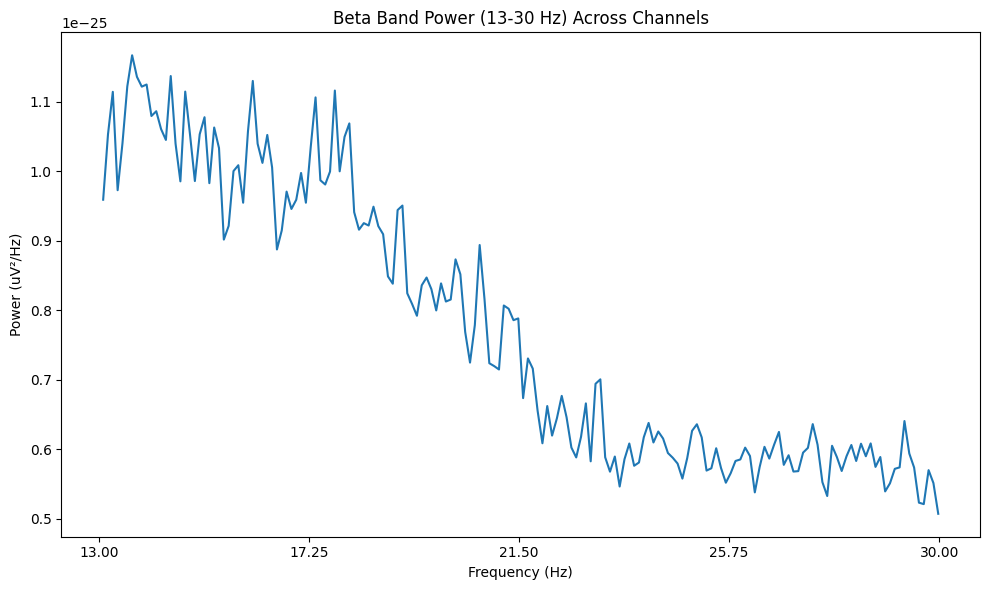

Extracted Beta Band Power (13-30 Hz) successfully.


In [332]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [333]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d132 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d132.head())
print(d132.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [334]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d132_clean = d132.replace([np.inf, -np.inf], np.nan)
d132_clean = d132_clean.fillna(d132_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d132_scaled = pd.DataFrame(
    scaler.fit_transform(d132_clean),
    columns=d132_clean.columns,
    index=d132_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d132_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d132_scaled.index,
    columns=d132_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d132_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df132 = d132_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df132["Pd_indicator_meg"] = 0

print("\nShape of df5:", df132.shape)
print(df132.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [335]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131, df132], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
7245    4.719577             0.052971          1.811303e-12  0.716955   
7246    4.814815             0.051923          1.628158e-12  0.698778   
7247    4.873016             0.051303     

In [336]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132.to_csv('/content/drive/MyDrive/combined_features_upto_sub00132_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 preserved.")


RAM Used After Cleanup: 0.61 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 preserved.


sub-133

In [337]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-133'  # Replace with your folder path


In [338]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-133_scans.tsv', 'meg']


In [339]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-133_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-133_coordsystem.json', 'sub-133_task-go_run-1_proc-tsss+mc_events.json', 'sub-133_task-noise_proc-tsss_channels.tsv', 'sub-133_task-noise_proc-tsss_meg.fif', 'sub-133_task-go_run-1_proc-tsss+mc_meg.json', 'sub-133_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-noise_proc-tsss_meg.json', 'sub-133_task-passive_run-1_proc-tsss+mc_events.json', 'sub-133_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-133_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-133_task-rest_run-1_proc-tsss+mc_events.json', 'sub-133_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-133_task-rest_run-1_proc-tsss+mc_meg.json']


In [340]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-133_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-133_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-133_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-133_task-rest_run-1_proc-tsss+mc_meg.fif']


In [341]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-133/meg/sub-133_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [342]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-133/meg/sub-133_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 9000 ... 194999 =      9.000 ...   194.999 secs
Ready.
Reading 0 ... 185999  =      0.000 ...   185.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA
F

Computing Power Spectral Density

Effective window size : 10.240 (s)


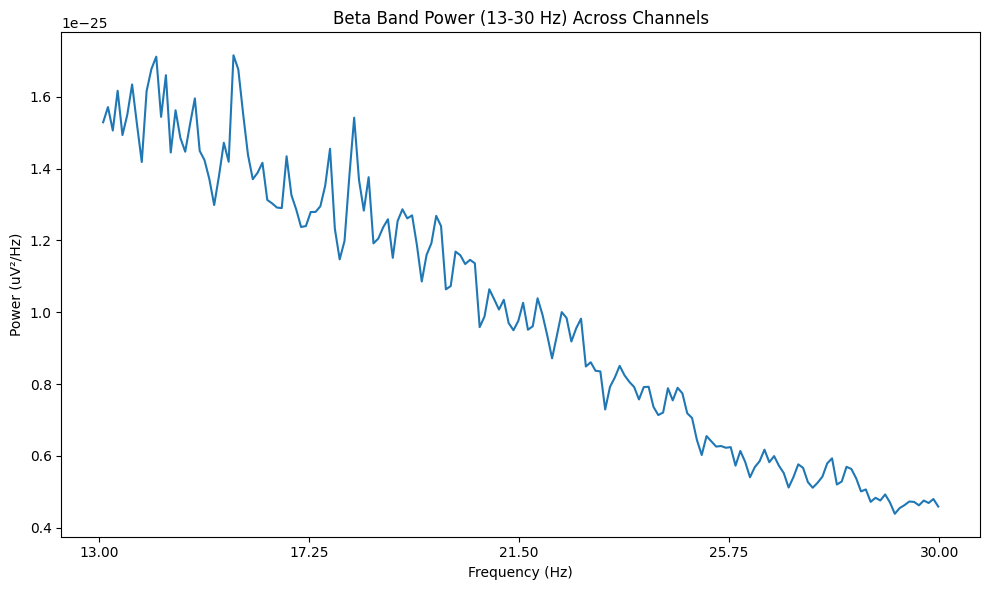

Extracted Beta Band Power (13-30 Hz) successfully.


In [343]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [344]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d133 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d133.head())
print(d133.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 42 channels

In [345]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d133_clean = d133.replace([np.inf, -np.inf], np.nan)
d133_clean = d133_clean.fillna(d133_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d133_scaled = pd.DataFrame(
    scaler.fit_transform(d133_clean),
    columns=d133_clean.columns,
    index=d133_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d133_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d133_scaled.index,
    columns=d133_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 42 Channels
# -------------------------------------------------
top_42_channel_names = centrality_scores.sort_values(
    ascending=False
).head(42).index

top_42_channel_numbers = [
    d133_scaled.index.get_loc(ch)
    for ch in top_42_channel_names
]

print("Top 42 channel names:")
print(top_42_channel_names.tolist())

print("\nTop 42 channel numbers:")
print(top_42_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df133 = d133_clean.loc[top_42_channel_names].copy()

# subject label (example PD subject)
df133["Pd_indicator_meg"] = 0

print("\nShape of df5:", df133.shape)
print(df133.head())

Top 42 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431']

Top 42 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42]

Shape of df5: (42, 22)
         burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
MEG2643    4.370968             0.057196          2.700971e-12  0.776275   
MEG0111    4.134409             0.060468          1.101639e-13  0.715654   
MEG2532    4.252688             0.058786          1.6

In [346]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132, df133], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
7287    4.155914             0.060155          4.338460e-12  0.822532   
7288    3.903226             0.064050          2.072146e-13  0.825126   
7289    3.166667             0.078947  

In [347]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.to_csv('/content/drive/MyDrive/combined_features_upto_sub00133_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 preserved.")


RAM Used After Cleanup: 0.61 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 preserved.


sub-134

In [348]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-134'  # Replace with your folder path


In [349]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-134_scans.tsv', 'meg']


In [350]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-134_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-134_coordsystem.json', 'sub-134_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-go_run-1_proc-tsss+mc_events.json', 'sub-134_task-noise_proc-tsss_channels.tsv', 'sub-134_task-go_run-1_proc-tsss+mc_meg.json', 'sub-134_task-noise_proc-tsss_meg.fif', 'sub-134_task-noise_proc-tsss_meg.json', 'sub-134_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-134_task-passive_run-1_proc-tsss+mc_events.json', 'sub-134_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-134_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-rest_run-1_proc-tsss+mc_events.json', 'sub-134_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-134_task-rest_run-1_proc-tsss+mc_meg.json']


In [351]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-134_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-134_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-134_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-134_task-rest_run-1_proc-tsss+mc_meg.fif']


In [352]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "rest"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-134/meg/sub-134_task-rest_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [353]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-134/meg/sub-134_task-rest_run-1_proc-tsss+mc_meg.fif...
    Range : 18000 ... 205999 =     18.000 ...   205.999 secs
Ready.
Reading 0 ... 187999  =      0.000 ...   187.999 secs...
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Finding events on: STI101
2 events found on stim channel STI101
Event IDs: [ 1 64]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting ICA


Computing Power Spectral Density

Effective window size : 10.240 (s)


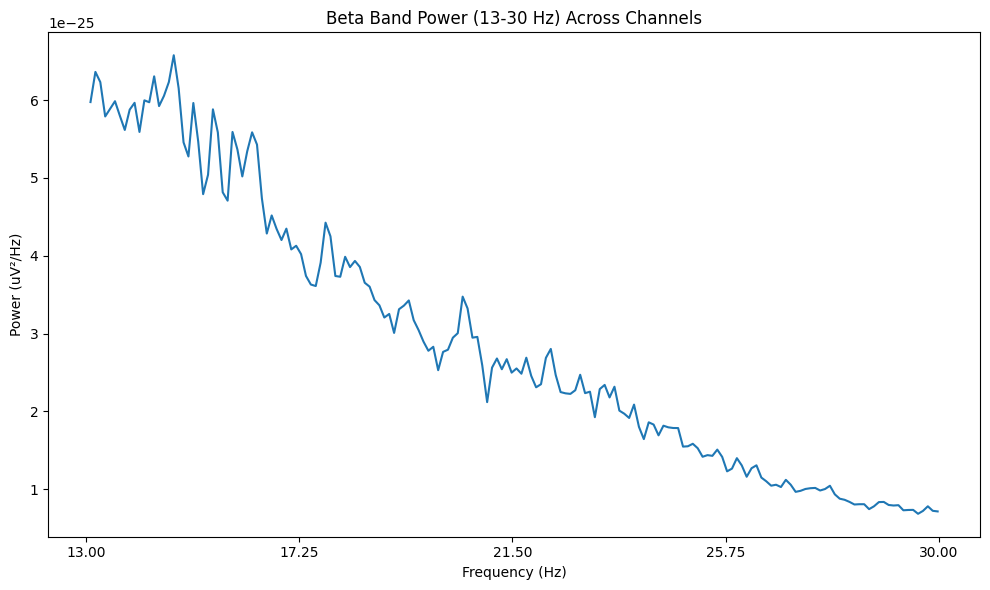

Extracted Beta Band Power (13-30 Hz) successfully.


In [354]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [355]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d134 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d134.head())
print(d134.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [356]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d134_clean = d134.replace([np.inf, -np.inf], np.nan)
d134_clean = d134_clean.fillna(d134_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d134_scaled = pd.DataFrame(
    scaler.fit_transform(d134_clean),
    columns=d134_clean.columns,
    index=d134_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d134_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d134_scaled.index,
    columns=d134_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d134_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df134 = d134_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df134["Pd_indicator_meg"] = 1

print("\nShape of df5:", df134.shape)
print(df134.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [357]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133, df134], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.164894             0.060026          3.769601e-12  0.781471   
1       4.063830             0.061518          2.130644e-13  0.733652   
2       4.324468             0.057811          3.549580e-12  0.779541   
3       4.382979             0.056990          4.324233e-12  0.727869   
4       4.361702             0.057317          1.885143e-13  0.732904   
...          ...                  ...                   ...       ...   
7345    4.207447             0.059418          2.535579e-12  0.718532   
7346    4.000000             0.062500          2.646257e-12  0.900280   
7347    4.170213             0.05994

In [358]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.to_csv('/content/drive/MyDrive/final_meg_rest_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 preserved.")


RAM Used After Cleanup: 0.61 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 preserved.


In [359]:
combined_df85 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134

In [360]:
print(combined_df85.shape)
print(combined_df85.dtypes)
print(combined_df85.iloc[7344:7350])  # Selects rows 2 to 612 (inclusive)
print(combined_df85.shape)

(7350, 22)
burst_rate              float64
mean_burst_duration     float64
mean_burst_amplitude    float64
ibi_cv                  float64
duty_cycle              float64
peak_beta_freq          float64
burst_dur_cv            float64
burst_amp_cv            float64
mean_ibi                float64
env_mean                float64
env_var                 float64
env_skew                float64
env_kurt                float64
env_mod_rate            float64
abs_beta_power          float64
peak_beta_power         float64
beta_median_freq        float64
beta_bandwidth          float64
spectral_entropy        float64
spectral_flatness       float64
spectral_slope          float64
Pd_indicator_meg          int64
dtype: object
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
7344    4.047872             0.061761          1.811388e-13  0.775701   
7345    4.207447             0.059418          2.535579e-12  0.718532   
7346    4.000000             0.062500          2.646

In [361]:
print(combined_df85['Pd_indicator_meg'].value_counts())

Pd_indicator_meg
0    3754
1    3596
Name: count, dtype: int64
